In [1]:
%matplotlib inline
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from pymatgen.core import IStructure, Lattice, Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator
from pymatgen.analysis.diffraction.neutron  import NDCalculator
singlecol = 3.5
plt.rcParams.update({'font.size': 8})
#plt.rcParams.update({'font.sans-serif': 'Helvetica'})
plt.rcParams.update({'lines.linewidth':1.5})
plt.rcParams.update({'axes.linewidth':1})
plt.rcParams.update({'lines.markersize':7})
plt.rcParams.update({'savefig.dpi':200})
plt.rcParams.update({'legend.fontsize': 8})

### poscar to cfg

In [2]:
import numpy as np
import os


def read_POSCAR(filename):
    """
    Return all the relevant information contained in a POSCAR file.
    WARNING: in this function lattvec is in Angstroms
    """
    nruter = dict()
    nruter["lattvec"] = np.empty((3, 3))
    f = open(filename, "r")
    firstline = next(f)
    factor = 1. * float(next(f).strip())
    for i in range(3):
        nruter["lattvec"][:, i] = [float(j) for j in next(f).split()]
    nruter["lattvec"] *= factor
    line = next(f)
    fields = next(f).split()
    old = False
    try:
        int(fields[0])
    except ValueError:
        old = True
    if old:
        nruter["elements"] = firstline.split()
        nruter["numbers"] = np.array([int(i) for i in line.split()])
        typeline = "".join(fields)
    else:
        nruter["elements"] = line.split()
        nruter["numbers"] = np.array([int(i) for i in fields], dtype=np.intc)
        typeline = next(f)
    natoms = nruter["numbers"].sum()
    nruter["positions"] = np.empty((3, natoms))
    for i in range(natoms):
        nruter["positions"][:, i] = [float(j) for j in next(f).split()]
    f.close()
    nruter["types"] = []
    for i in range(len(nruter["numbers"])):
        nruter["types"] += [i] * nruter["numbers"][i]
    if typeline[0] == "C" or typeline[0] == "c":
        nruter["positions"] = np.linalg.solve(nruter["lattvec"],
                                              nruter["positions"] * factor)
    return nruter

def poscar2cfg(poscar,cfgfile):
    """
    Convert one poscar into mlip format and append to cfg file.
    """
    with open(cfgfile,'w') as f:
        f.write("BEGIN_CFG\n")
        f.write(" Size\n")
        f.write("    "+str(poscar["numbers"].sum())+"\n")
        f.write(" Supercell\n")
        for i in range(3):
            f.write("    {0[0]:>13.6f} {0[1]:>13.6f} {0[2]:>13.6f}\n".format(
                (poscar["lattvec"][:, i]).tolist()))
        f.write(" AtomData:  id type       cartes_x      cartes_y      cartes_z\n")
        for i in range(poscar["positions"].shape[1]):
            nelement = -1
            for element in range(len(poscar["numbers"])):
                if i < poscar["numbers"][:element+1].sum():
                    nelement=element
                    break
            f.write("    "+"{0[0]:10d} {0[1]:4d}".format([i+1,nelement]))
            f.write("  {0[0]:>13.6f} {0[1]:>13.6f} {0[2]:>13.6f}\n".format(np.dot(poscar["lattvec"], poscar["positions"])[:, i].tolist()))
        f.write("END_CFG\n")
        f.write("\n")

In [3]:
poscar = read_POSCAR('20000.vasp')
poscar2cfg(poscar,'20000.cfg')
poscar = read_POSCAR('400000.vasp')
poscar2cfg(poscar,'400000.cfg')

In [3]:
import numpy as np

def load_multi_section_cfg(filename):
    energies = []
    atom_data_list = []
    stress_data_list = []
    
    try:
        with open(filename, 'r', encoding="utf-8", errors="ignore") as file:
            content = file.read()
            
            # Split the content into sections
            cfg_sections = content.split('BEGIN_CFG')[1:]  # Skip the first empty split
            
            for section in cfg_sections:
                lines = section.strip().split('\n')
                
                # Extract Size
                size = int(next(line.strip() for line in lines if line.strip().isdigit()))
                
                # Extract AtomData
                atom_data_start = next(i for i, line in enumerate(lines) if line.strip().startswith('AtomData:'))
                atom_data = np.array([list(map(float, line.split()[1:])) for line in lines[atom_data_start+1:atom_data_start+size+1]])
                atom_data_list.append(atom_data)
                
                # Extract Energy
                energy_line_index = next(i for i, line in enumerate(lines) if line.strip().startswith('Energy'))
                energy = float(lines[energy_line_index+1].split()[0])
                energies.append(energy)
                
                # Extract PlusStress
                stress_line = next(line for line in lines if line.strip().startswith('PlusStress:'))
                stress = np.array(list(map(float, lines[lines.index(stress_line) + 1].split())))
                stress_data_list.append(stress)
        
        return np.array(energies),atom_data_list, np.array(stress_data_list)
    
    except FileNotFoundError:
        print(f"Error: File '{filename}' not found.")
    except IsADirectoryError:
        print(f"Error: '{filename}' is a directory, not a file.")
    except IOError:
        print(f"Error: Could not read file '{filename}'.")
    except Exception as e:
        print(f"Error: {e}")
        return None, None, None

In [4]:
import numpy as np

def load_multi_section_cfg_no_grade(filename):
    energies = []
    supercell_list = []
    atom_data_list = []
    stress_data_list = []
    grade_data_list = []
    
    try:
        with open(filename, 'r') as file:
            content = file.read()
            
            # Split the content into sections
            cfg_sections = content.split('BEGIN_CFG')[1:]  # Skip the first empty split
            
            for section in cfg_sections:
                lines = section.strip().split('\n')
                
                # Extract Size
                size = int(next(line.strip() for line in lines if line.strip().isdigit()))

                # Extract Supercell
                supercell_start = next(i for i, line in enumerate(lines) if line.strip().startswith('Supercell'))
                supercell = np.array([list(map(float, line.split()[:])) for line in lines[supercell_start+1:supercell_start+3+1]])
                supercell_list.append(supercell)
                
                # Extract AtomData
                atom_data_start = next(i for i, line in enumerate(lines) if line.strip().startswith('AtomData:'))
                atom_data = np.array([list(map(float, line.split())) for line in lines[atom_data_start+1:atom_data_start+size+1]])
                atom_data_list.append(atom_data)
                
                # Extract Energy
                energy_line_index = next(i for i, line in enumerate(lines) if line.strip().startswith('Energy'))
                energy = float(lines[energy_line_index+1].split()[0])
                energies.append(energy)
                
                # Extract PlusStress
                stress_line = next(line for line in lines if line.strip().startswith('PlusStress:'))
                stress = np.array(list(map(float, lines[lines.index(stress_line) + 1].split())))
                stress_data_list.append(stress)
        
        return np.array(energies), np.array(supercell_list), atom_data_list, np.array(stress_data_list)
    
    except FileNotFoundError:
        print(f"Error: File '{filename}' not found.")
    except IsADirectoryError:
        print(f"Error: '{filename}' is a directory, not a file.")
    except IOError:
        print(f"Error: Could not read file '{filename}'.")
    except Exception as e:
        print(f"Error: {e}")
        return None, None, None

In [5]:
# Separate the cfg file into section
# Load Each section one by one
def load_cfg(filename):
    try:
        with open(filename, 'r') as file:
            lines = file.readlines()[4:-5]  # Read from the 5th line onwards 
        
        # Split each line into separate numbers
        numbers = []
        for line in lines:
            line_numbers = [float(num) for num in line.split()]  # Assuming numbers are floats
            numbers.append(line_numbers)
        
        # Convert the list of lists into a NumPy array
        return np.array(numbers)
    
    except FileNotFoundError:
        print(f"Error: File '{filename}' not found.")
    except IsADirectoryError:
        print(f"Error: '{filename}' is a directory, not a file.")
    except IOError:
        print(f"Error: Could not read file '{filename}'.")
    except Exception as e:
        print(f"Error: {e}")


In [3]:
def split_lammps_trj(file_path, output_prefix="structure"):
    with open(file_path, 'r') as file:
        lines = file.readlines()
        
    structure_count = 0
    structure_data = []
    
    for line in lines:
        if line.startswith("ITEM: TIMESTEP"):
            if structure_data:
                # Write the collected structure data to a new file
                output_file = f"{output_prefix}_{structure_count}.trj"
                with open(output_file, 'w') as out_file:
                    out_file.writelines(structure_data)
                structure_data = []
                structure_count += 1
        structure_data.append(line)
    
    # Write the last structure data to a new file
    if structure_data:
        output_file = f"{output_prefix}_{structure_count}.trj"
        with open(output_file, 'w') as out_file:
            out_file.writelines(structure_data)

In [4]:
def calculate_angles(xy, xz, yz, a, b, c):
    # Calculate cosines of the angles
    cos_alpha = xy / (a * b)
    cos_beta = xz / (a * c)
    cos_gamma = yz / (b * c)
    
    # Calculate the angles in radians
    alpha = np.arccos(cos_alpha)
    beta = np.arccos(cos_beta)
    gamma = np.arccos(cos_gamma)
    
    # Convert to degrees
    alpha_deg = np.degrees(alpha)
    beta_deg = np.degrees(beta)
    gamma_deg = np.degrees(gamma)
    
    return alpha_deg, beta_deg, gamma_deg

In [14]:
def read_lammps_trj(file_path):
    """Reads a LAMMPS trajectory file and converts it to a pymatgen Structure object."""
    with open(file_path, 'r') as file:
        lines = file.readlines()

    # Read box bounds
    for i, line in enumerate(lines):
        if line.startswith("ITEM: BOX BOUNDS"):
            x_bounds = list(map(float, lines[i+1].split()))
            y_bounds = list(map(float, lines[i+2].split()))
            z_bounds = list(map(float, lines[i+3].split()))
            break

    # Calculate lattice vectors
    a = x_bounds[1] - x_bounds[0]
    b = y_bounds[1] - y_bounds[0]
    c = z_bounds[1] - z_bounds[0]
    alpha, beta, gamma = calculate_angles(x_bounds[2], y_bounds[2], z_bounds[2], a, b, c)
    lattice = Lattice.from_parameters(a, b, c, alpha, beta, gamma)

    # Define atom type mapping
    atom_type_map = {
        1: "C",
        2: "Mn2+",
        3: "Fe2+",
        4: "N",
        5: "Na+"
    }

    # Read atom positions
    atom_positions = []
    atom_species = []
    for i, line in enumerate(lines):
        if line.startswith("ITEM: ATOMS"):
            for atom_line in lines[i+1:]:
                atom_data = atom_line.split()
                atom_type = int(atom_data[1])
                species = atom_type_map[atom_type]
                x = float(atom_data[2])
                y = float(atom_data[3])
                z = float(atom_data[4])
                atom_positions.append([x, y, z])
                atom_species.append(species)
            break
    
    # Create pymatgen Structure object
    structure = IStructure(lattice, atom_species, atom_positions, coords_are_cartesian=True)
    return structure

In [3]:
def calculate_xrd(structure, wavelength="CuKa", output_file=None):
    """Calculates and saves the XRD pattern for a given pymatgen Structure object."""
    xrd_calculator = XRDCalculator(wavelength=wavelength, symprec=0)
    xrd_pattern = xrd_calculator.get_pattern(structure, two_theta_range=(10,40))
    
    if output_file:
        # Save the XRD pattern to a file
        with open(output_file, 'w') as f:
            for two_theta, intensity in zip(xrd_pattern.x, xrd_pattern.y):
                f.write(f"{two_theta:.2f} {intensity:.2f}\n")

    return xrd_pattern

In [4]:
def two_theta_to_q(two_theta, wavelength):
    theta = np.radians(two_theta / 2.0)
    q = (4.0 * np.pi * np.sin(theta)) / wavelength
    return q

In [2]:
import numpy as np
from ase.io.lammpsdata import read_lammps_data

# Parameters
datafile = "./Nt_300/5/300loop_bias_1.data"
cutoff = 1           # exclusion zone around host atoms (Å)
grid_spacing = 1.0     # Å
host_types = {1, 2, 3, 4}
output_file = "filtered_insertion_points.txt"

# Load structure
atoms = parse_lammps_data(datafile)#, style="atomic")

# Extract host atom positions
host_positions = np.array([atom.position for atom in atoms if atom.number in host_types])

# Simulation cell dimensions
cell = atoms.get_cell()
mins = [0.0, 0.0, 0.0]
maxs = np.diag(cell)  # works if orthogonal box

# Create grid
x_vals = np.arange(mins[0], maxs[0], grid_spacing)
y_vals = np.arange(mins[1], maxs[1], grid_spacing)
z_vals = np.arange(mins[2], maxs[2], grid_spacing)

insertion_points = []
for x in x_vals:
    for y in y_vals:
        for z in z_vals:
            point = np.array([x, y, z])
            if np.min(np.linalg.norm(host_positions - point, axis=1)) > cutoff:
                insertion_points.append(point)

# Write valid points
with open(output_file, "w") as f:
    for pt in insertion_points:
        f.write(f"{pt[0]:.3f} {pt[1]:.3f} {pt[2]:.3f}\n")

print(f"Generated {len(insertion_points)} insertion points in '{output_file}'")


ModuleNotFoundError: No module named 'ase'

In [3]:
import argparse
import sys
import re

def parse_args():
    p = argparse.ArgumentParser(
        description="Convert a single‐frame LAMMPS data file (atom_style atomic) "
                    "into one MLIP‐MTP .cfg file."
    )
    p.add_argument(
        "--in", "-i", dest="infile", required=True,
        help="Path to input LAMMPS data file (atom_style atomic)."
    )
    p.add_argument(
        "--out", "-o", dest="outfile", required=True,
        help="Path to output MLIP .cfg file."
    )
    p.add_argument(
        "--map", "-m", dest="type_map", required=True,
        help="Comma‐separated mapping of LAMMPS type→element, e.g. 1=Fe,2=Mn,3=C"
    )
    return p.parse_args()

def read_type_map(s):
    """
    Parse a string like "1=Fe,2=Mn,3=C,4=N,5=Na" into a dict {1:"Fe",2:"Mn",...}.
    """
    mp = {}
    for pair in s.strip().split(","):
        if '=' not in pair:
            continue
        t, sym = pair.split("=")
        try:
            t_int = int(t)
        except ValueError:
            raise ValueError(f"Cannot parse type ID '{t}' as integer in mapping '{s}'")
        mp[t_int] = sym
    return mp

def parse_lammps_data(filename):
    """
    Very minimal LAMMPS-data parser (atom_style atomic).
    Returns:
      • natoms        : int
      • box_bounds    : ((xlo,xhi),(ylo,yhi),(zlo,zhi))
      • atoms         : list of (id, type, x, y, z) tuples (floats for coords)
    """
    natoms = None
    box_bounds = {"x":None, "y":None, "z":None}
    atoms_section = False
    atoms = []
    # We'll record how many atoms we saw, for sanity
    num_atoms_parsed = 0

    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            # 1) Look for “<number> atoms”
            m = re.match(r"^(\d+)\s+atoms\s*$", line)
            if m:
                natoms = int(m.group(1))
                continue

            # 2) Box bounds: “xlo xhi”
            m = re.match(r"^([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)\s+([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)\s+xlo\s+xhi\s*$", line)
            if m:
                box_bounds["x"] = (float(m.group(1)), float(m.group(2)))
                continue
            m = re.match(r"^([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)\s+([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)\s+ylo\s+yhi\s*$", line)
            if m:
                box_bounds["y"] = (float(m.group(1)), float(m.group(2)))
                continue
            m = re.match(r"^([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)\s+([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)\s+zlo\s+zhi\s*$", line)
            if m:
                box_bounds["z"] = (float(m.group(1)), float(m.group(2)))
                continue

            # 3) Detect start of “Atoms” section
            if line.startswith("Atoms"):
                # Next non-blank line is the header of columns (we ignore it),
                # then successive lines are “id  type  x  y  z ...”
                atoms_section = True
                # Skip the next line (usually the column header)
                next(f)
                continue

            # 4) If we are in Atoms section, parse until we have read natoms lines
            if atoms_section:
                parts = line.split()
                if len(parts) < 5:
                    # If <5 columns, probably blank or end
                    atoms_section = False
                    continue
                # LAMMPS “atomic” style: id, type, x, y, z
                try:
                    at_id   = int(parts[0])
                    at_type = int(parts[1])
                    x = float(parts[2])
                    y = float(parts[3])
                    z = float(parts[4])
                except ValueError:
                    # Malformed line → stop parsing Atoms
                    atoms_section = False
                    continue
                atoms.append((at_id, at_type, x, y, z))
                num_atoms_parsed += 1
                if natoms is not None and num_atoms_parsed >= natoms:
                    # We have read all atoms → exit Atoms section
                    atoms_section = False

    if natoms is None:
        raise RuntimeError(f"Could not find number of atoms in {filename}")
    if any(box_bounds[dim] is None for dim in ("x","y","z")):
        raise RuntimeError(f"Failed to parse box bounds from {filename}")
    if len(atoms) != natoms:
        raise RuntimeError(f"Expected {natoms} atoms, but parsed {len(atoms)} in {filename}")
    return atoms #natoms, (box_bounds["x"], box_bounds["y"], box_bounds["z"]), atoms

def write_mlip_cfg(outfile, natoms, box, atoms):
    (xlo, xhi), (ylo, yhi), (zlo, zhi) = box
    # Build lattice vectors (orthorhombic):
    ax = (xhi - xlo, 0.0,       0.0)
    by = (0.0,       yhi - ylo, 0.0)
    cz = (0.0,       0.0,       zhi - zlo)

    with open(outfile, 'w') as out:
        out.write("BEGIN_CFG\n")
        out.write(" Size\n")
        out.write(f"    {natoms}\n")
        out.write(" Supercell\n")
        out.write(f"    {ax[0]:15.8f} {ax[1]:15.8f} {ax[2]:15.8f}\n")
        out.write(f"    {by[0]:15.8f} {by[1]:15.8f} {by[2]:15.8f}\n")
        out.write(f"    {cz[0]:15.8f} {cz[1]:15.8f} {cz[2]:15.8f}\n")
        out.write(" AtomData:  id  type  cartes_x  cartes_y  cartes_z\n")
        # Sort atoms by ID (optional, but often nicer)
        atoms_sorted = sorted(atoms, key=lambda x: x[0])
        for (at_id, at_type, x, y, z) in atoms_sorted:
            # Map numeric type → element symbol:
            out.write(f"    {at_id:4d}  {at_type-1:4d}   {x:10.6f}   {y:10.6f}   {z:10.6f}\n")
        out.write("END_CFG\n")

In [2]:
import numpy as np
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
%matplotlib widget
def parse_lammps_data(filename):
    natoms = None
    box_bounds = {"x":None, "y":None, "z":None}
    atoms_section = False
    atoms = []
    # We'll record how many atoms we saw, for sanity
    num_atoms_parsed = 0

    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            # 1) Look for “<number> atoms”
            m = re.match(r"^(\d+)\s+atoms\s*$", line)
            if m:
                natoms = int(m.group(1))
                continue

            # 2) Box bounds: “xlo xhi”
            m = re.match(r"^([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)\s+([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)\s+xlo\s+xhi\s*$", line)
            if m:
                box_bounds["x"] = (float(m.group(1)), float(m.group(2)))
                continue
            m = re.match(r"^([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)\s+([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)\s+ylo\s+yhi\s*$", line)
            if m:
                box_bounds["y"] = (float(m.group(1)), float(m.group(2)))
                continue
            m = re.match(r"^([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)\s+([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)\s+zlo\s+zhi\s*$", line)
            if m:
                box_bounds["z"] = (float(m.group(1)), float(m.group(2)))
                continue

            # 3) Detect start of “Atoms” section
            if line.startswith("Atoms"):
                # Next non-blank line is the header of columns (we ignore it),
                # then successive lines are “id  type  x  y  z ...”
                atoms_section = True
                # Skip the next line (usually the column header)
                next(f)
                continue

            # 4) If we are in Atoms section, parse until we have read natoms lines
            if atoms_section:
                parts = line.split()
                if len(parts) < 5:
                    # If <5 columns, probably blank or end
                    atoms_section = False
                    continue
                # LAMMPS “atomic” style: id, type, x, y, z
                try:
                    at_id   = int(parts[0])
                    at_type = int(parts[1])
                    x = float(parts[2])
                    y = float(parts[3])
                    z = float(parts[4])
                except ValueError:
                    # Malformed line → stop parsing Atoms
                    atoms_section = False
                    continue
                atoms.append([at_id, at_type, x, y, z])
                num_atoms_parsed += 1
                if natoms is not None and num_atoms_parsed >= natoms:
                    # We have read all atoms → exit Atoms section
                    atoms_section = False

    if natoms is None:
        raise RuntimeError(f"Could not find number of atoms in {filename}")
    if any(box_bounds[dim] is None for dim in ("x","y","z")):
        raise RuntimeError(f"Failed to parse box bounds from {filename}")
    if len(atoms) != natoms:
        raise RuntimeError(f"Expected {natoms} atoms, but parsed {len(atoms)} in {filename}")
    return np.array(atoms) #natoms, (box_bounds["x"], box_bounds["y"], box_bounds["z"]), atoms

def cluster_host_atoms(host_positions, max_distance=2.3, min_cluster_size=6):
    """
    Cluster host atoms to identify regions that need exclusion
    """
    from sklearn.cluster import DBSCAN
    
    # Use DBSCAN clustering to group nearby host atoms
    clustering = DBSCAN(eps=max_distance, min_samples=min_cluster_size)
    cluster_labels = clustering.fit_predict(host_positions)
    
    clusters = []
    for label in set(cluster_labels):
        if label == -1:  # Skip noise points
            continue
        cluster_points = host_positions[cluster_labels == label]
        center = np.mean(cluster_points, axis=0)
        # Calculate radius that encompasses all points in cluster
        distances = np.linalg.norm(cluster_points - center, axis=1)
        radius = np.max(distances) + 1.0  # Add buffer
        clusters.append((center, radius, len(cluster_points)))
    
    return clusters

def generate_exclusion_regions(atoms, output_file='exclusion_regions.lmp'):
    """
    Generate LAMMPS exclusion regions based on host atom positions
    """
    # Filter host atoms (types 1, 2, 3, 4)
    host_atoms = atoms[(atoms[:,1] >= 2) & (atoms[:,1] <= 3)]
    host_positions = host_atoms[:,2:]  # x, y, z coordinates
    
    print(f"Found {len(host_atoms)} host atoms")
    
    # Cluster host atoms to identify exclusion regions
    clusters = cluster_host_atoms(host_positions, max_distance=1.0, min_cluster_size=1)
    
    print(f"Identified {len(clusters)} host clusters")
    
    # Generate LAMMPS region commands
    region_commands = []
    union_regions = []
    
    for i, (center, radius, count) in enumerate(clusters):
        region_name = f"exclude_{i+1}"
        union_regions.append(region_name)
        x, y, z = center
        
        # Ensure minimum radius
        radius = max(radius, 2.0)
        
        region_cmd = f"region {region_name} sphere {x:.3f} {y:.3f} {z:.3f} {radius:.3f} units box"
        region_commands.append(region_cmd)
        
        #print(f"Cluster {i+1}: Center=({x:.2f}, {y:.2f}, {z:.2f}), Radius={radius:.2f}, Atoms={count}")
    
    # Create union command
    if union_regions:
        union_cmd = f"region all_exclude union {len(union_regions)} " + " ".join(union_regions)
        region_commands.append("")
        region_commands.append("# Union all exclusion regions")
        region_commands.append(union_cmd)
    
    # Write to file
    with open(output_file, 'w') as f:
        f.write("# Auto-generated exclusion regions for GCMC\n")
        f.write(f"# Based on {len(host_atoms)} host atoms in {len(clusters)} clusters\n\n")
        for cmd in region_commands:
            f.write(cmd + "\n")
    
    print(f"Exclusion regions written to {output_file}")
    return clusters

def analyze_insertion_space(atoms, clusters, box_dims):
    """
    Estimate available space for insertion after excluding host regions
    """
    # Calculate total box volume
    total_volume = np.prod([box_dims[i][1] - box_dims[i][0] for i in range(3)])
    
    # Calculate excluded volume
    excluded_volume = 0
    for center, radius, count in clusters:
        sphere_volume = (4/3) * np.pi * radius**3
        excluded_volume += sphere_volume
    
    available_volume = total_volume - excluded_volume
    available_fraction = available_volume / total_volume
    
    print(f"\nVolume Analysis:")
    print(f"Total box volume: {total_volume:.2f} Ų")
    print(f"Excluded volume: {excluded_volume:.2f} Ų")
    print(f"Available volume: {available_volume:.2f} Ų")
    print(f"Available fraction: {available_fraction:.2%}")
    
    # Estimate insertion capacity
    # Assuming each insertion site needs ~8 Ų (2Å radius sphere)
    site_volume = (4/3) * np.pi * 2**3
    estimated_sites = int(available_volume / site_volume)
    
    print(f"Estimated insertion capacity: {estimated_sites} sites")
    print(f"Target sites: 4096")
    print(f"Capacity ratio: {estimated_sites/4096:.2f}")
    
    return available_fraction

def visualize_exclusion_regions(atoms, clusters):
    """
    Create 2D visualization of exclusion regions
    """
    # Filter host atoms
    host_atoms = atoms[(atoms[:,1] >= 2) & (atoms[:,1] <= 3)]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # XY projection
    ax1.scatter(host_atoms[:,2], host_atoms[:,3], s=1, alpha=0.5, c='blue', label='Host atoms')
    for i, (center, radius, count) in enumerate(clusters):
        circle = plt.Circle((center[0], center[1]), radius, fill=False, color='red', linewidth=2)
        ax1.add_patch(circle)
        #ax1.text(center[0], center[1], str(i+1), ha='center', va='center', fontsize=8, 
        #        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8))
    
    ax1.set_xlabel('X coordinate')
    ax1.set_ylabel('Y coordinate')
    ax1.set_title('XY Projection - Host Atoms and Exclusion Regions')
    #ax1.legend()
    ax1.set_aspect('equal')
    
    # XZ projection
    ax2.scatter(host_atoms[:,2], host_atoms[:,4], s=1, alpha=0.5, c='blue', label='Host atoms')
    for i, (center, radius, count) in enumerate(clusters):
        circle = plt.Circle((center[0], center[2]), radius, fill=False, color='red', linewidth=2)
        ax2.add_patch(circle)
        #ax2.text(center[0], center[2], str(i+1), ha='center', va='center', fontsize=8,
        #        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8))
    
    ax2.set_xlabel('X coordinate')
    ax2.set_ylabel('Z coordinate')
    ax2.set_title('XZ Projection - Host Atoms and Exclusion Regions')
    #ax2.legend()
    ax2.set_aspect('equal')
    
    plt.tight_layout()
    
    #if save_plot:
    #    plt.savefig('exclusion_regions_visualization.png', dpi=300, bbox_inches='tight')
    #    print("Visualization saved as 'exclusion_regions_visualization.png'")
    
    plt.show()

# Main execution
if __name__ == "__main__":
    # Replace with your actual LAMMPS data file
    data_file = "./Nt_300/5/300loop_bias_1.data"
    
    try:
        # Read atom data
        print("Reading LAMMPS data file...")
        atoms = parse_lammps_data(data_file)
        
        print(f"Total atoms read: {len(atoms)}")
        
        # Count atoms by type
        for atom_type in range(1, 6):
            count = np.sum(atoms[:,1] == atom_type)
            print(f"Type {atom_type}: {count} atoms")
        
        # Generate exclusion regions
        print("\nGenerating exclusion regions...")
        clusters = generate_exclusion_regions(atoms)
        
        # Analyze insertion space (you'll need to provide box dimensions)
        # Get box dimensions from your LAMMPS data file
        box_dims = [(0, 50), (0, 50), (0, 50)]  # Replace with actual dimensions
        analyze_insertion_space(atoms, clusters, box_dims)
        
        # Create visualization
        print("\nCreating visualization...")
        visualize_exclusion_regions(atoms, clusters)
        
        print("\nNext steps:")
        print("1. Copy the contents of 'exclusion_regions.lmp' into your LAMMPS input script")
        print("2. Adjust the box dimensions in the analysis")
        print("3. Fine-tune exclusion radii if needed")
        print("4. Test the GCMC simulation with a few thousand steps first")
        
    except FileNotFoundError:
        print(f"Error: Could not find data file '{data_file}'")
        print("Please update the 'data_file' variable with the correct path to your LAMMPS data file")
    except Exception as e:
        print(f"Error processing file: {e}")
        print("Make sure your LAMMPS data file is in the standard format")

ModuleNotFoundError: No module named 'ipympl'

# XRD

### dump to vasp

In [ ]:
import numpy as np
from collections import defaultdict

def parse_lammps_dump(dump_data):
    """
    Parse LAMMPS dump data from string format
    """
    lines = dump_data.strip().split('\n')
    
    # Parse header information
    timestep = None
    num_atoms = None
    box_bounds = []
    atoms_data = []
    
    i = 0
    while i < len(lines):
        line = lines[i].strip()
        
        if line.startswith("ITEM: TIMESTEP"):
            if i + 1 < len(lines):
                timestep = int(lines[i+1])
            i += 2
        elif line.startswith("ITEM: NUMBER OF ATOMS"):
            if i + 1 < len(lines):
                num_atoms = int(lines[i+1])
            i += 2
        elif line.startswith("ITEM: BOX BOUNDS"):
            # Parse box bounds (3 lines)
            box_bounds = []
            for j in range(3):
                if i + 1 + j < len(lines):
                    bounds_line = lines[i+1+j].split()
                    if len(bounds_line) >= 2:
                        box_bounds.append([float(bounds_line[0]), float(bounds_line[1])])
                        # Store tilt factors if present
                        if len(bounds_line) >= 3:
                            if j == 0:  # xy
                                xy = float(bounds_line[2])
                            elif j == 1:  # xz
                                xz = float(bounds_line[2])
                            elif j == 2:  # yz  
                                yz = float(bounds_line[2])
            i += 4
        elif line.startswith("ITEM: ATOMS"):
            # Parse atom data
            headers = line.split()[2:]  # Skip "ITEM:" and "ATOMS"
            atom_start_line = i + 1
            for j in range(num_atoms):
                if atom_start_line + j < len(lines):
                    atom_line = lines[atom_start_line + j].split()
                    atom_dict = {}
                    for k, header in enumerate(headers):
                        if k < len(atom_line):
                            if header in ['id', 'type']:
                                atom_dict[header] = int(atom_line[k])
                            else:
                                atom_dict[header] = float(atom_line[k])
                    atoms_data.append(atom_dict)
            break
        else:
            i += 1
    
    # Set default tilt factors if not found
    if 'xy' not in locals():
        xy = 0.0
    if 'xz' not in locals():
        xz = 0.0
    if 'yz' not in locals():
        yz = 0.0
    
    return timestep, num_atoms, box_bounds, atoms_data, xy, xz, yz

def lammps_to_poscar(dump_file_path, system_name="LAMMPS_System", element_mapping=None, output_file=None):
    """
    Convert LAMMPS dump to POSCAR format
    
    Parameters:
    dump_file_path: path to LAMMPS dump file OR string containing LAMMPS dump data
    system_name: system name for POSCAR header
    element_mapping: dict mapping atom types to element names (e.g., {1: 'C', 2: 'H'})
    output_file: path to output POSCAR file (optional)
    """
    
    # Check if input is a file path or data string
    if dump_file_path.endswith('.dump') or '/' in dump_file_path:
        # It's a file path
        with open(dump_file_path, 'r') as f:
            dump_data = f.read()
    else:
        # It's data string
        dump_data = dump_file_path
    
    timestep, num_atoms, box_bounds, atoms_data, xy, xz, yz = parse_lammps_dump(dump_data)
    
    # Check if parsing was successful
    if len(box_bounds) < 3:
        raise ValueError(f"Could not parse box bounds. Found {len(box_bounds)} bounds, expected 3.")
    
    # Extract box vectors from bounds
    # LAMMPS triclinic box: xlo_bound xhi_bound xy
    #                      ylo_bound yhi_bound xz  
    #                      zlo_bound zhi_bound yz
    
    xlo_bound, xhi_bound = box_bounds[0]
    ylo_bound, yhi_bound = box_bounds[1] 
    zlo_bound, zhi_bound = box_bounds[2]
    
    # Use the tilt factors from parsing
    # (xy, xz, yz are already extracted from the file)
    
    # Calculate actual box dimensions
    xlo = xlo_bound - min(0.0, xy, xz, xy+xz)
    xhi = xhi_bound - max(0.0, xy, xz, xy+xz)
    ylo = ylo_bound - min(0.0, yz)
    yhi = yhi_bound - max(0.0, yz)
    zlo = zlo_bound
    zhi = zhi_bound
    
    # Box vectors
    lx = xhi - xlo
    ly = yhi - ylo  
    lz = zhi - zlo
    
    # Lattice vectors for triclinic box
    a_vec = [lx, 0.0, 0.0]
    b_vec = [xy, ly, 0.0]
    c_vec = [xz, yz, lz]
    
    # Group atoms by type
    atoms_by_type = defaultdict(list)
    for atom in atoms_data:
        atoms_by_type[atom['type']].append(atom)
    
    # Sort types
    sorted_types = sorted(atoms_by_type.keys())
    
    # Create element names and counts
    if element_mapping:
        elements = [element_mapping.get(t, f'Type{t}') for t in sorted_types]
    else:
        elements = [f'Type{t}' for t in sorted_types]
    
    counts = [len(atoms_by_type[t]) for t in sorted_types]
    
    # Prepare atomic coordinates (keep as Cartesian)
    all_positions = []
    for atom_type in sorted_types:
        type_atoms = sorted(atoms_by_type[atom_type], key=lambda x: x['id'])
        for atom in type_atoms:
            # Keep original Cartesian coordinates
            all_positions.append([atom['x'], atom['y'], atom['z']])
    
    # Generate POSCAR content
    poscar_lines = []
    poscar_lines.append(system_name)
    poscar_lines.append("1.0")  # scaling factor
    
    # Lattice vectors
    poscar_lines.append(f"{a_vec[0]:16.8f} {a_vec[1]:16.8f} {a_vec[2]:16.8f}")
    poscar_lines.append(f"{b_vec[0]:16.8f} {b_vec[1]:16.8f} {b_vec[2]:16.8f}")
    poscar_lines.append(f"{c_vec[0]:16.8f} {c_vec[1]:16.8f} {c_vec[2]:16.8f}")
    
    # Element names
    poscar_lines.append(" ".join(elements))
    
    # Element counts
    poscar_lines.append(" ".join(map(str, counts)))
    
    # Coordinate type
    poscar_lines.append("Cartesian")
    
    # Atomic positions
    for pos in all_positions:
        poscar_lines.append(f"{pos[0]:16.8f} {pos[1]:16.8f} {pos[2]:16.8f}")
    
    poscar_content = "\n".join(poscar_lines)
    
    # Write to file if output_file is specified
    if output_file:
        with open(output_file, 'w') as f:
            f.write(poscar_content)
        print(f"POSCAR file written to: {output_file}")
    
    return poscar_content

# Example usage with your data
dump_data = """ITEM: TIMESTEP
24000
ITEM: NUMBER OF ATOMS
14893
ITEM: BOX BOUNDS xy xz yz pp pp pp
7.6439807312100583e-01 6.5041241666018280e+01 3.0414123216993745e+00
1.5813537112446581e+00 5.9260711199474244e+01 1.9610537044401561e+00
1.6021214893217794e+00 5.9197894000677756e+01 8.5633945719744711e-02
ITEM: ATOMS id type x y z
7 4 3.82873 4.75196 6.20308
6 4 1.89263 4.60464 3.70794"""

# Element mapping for your system
element_map = {1: 'C', 2: 'Mn', 3: 'Fe', 4: 'N', 5: 'Na', 6: 'O', 7: 'H'}
temp = 400
for O in [32]:
    for Na in [4,16,28]:# Convert to POSCAR and write to file
        poscar_content = lammps_to_poscar(f'../../../hydration/{temp}_diffusion_2/{temp}K_Na_{Na}_O_{O}.dump', 
                                          'System_Name', 
                                          element_map,
                                          output_file=f'../../../hydration/{temp}_diffusion_2/{temp}K_Na_{Na}_O_{O}.vasp')
        print("POSCAR format:")
        print(poscar_content[:1000] + "..." if len(poscar_content) > 1000 else poscar_content)
        
        print("\n" + "="*50)
        print("Usage Instructions:")
        print("="*50)
        print("1. Replace 'dump_data' with your full LAMMPS dump file content")
        print("2. Element mapping is set for your system:")
        print("   {1: 'C', 2: 'Mn', 3: 'Fe', 4: 'N', 5: 'Na', 6: 'O', 7: 'H'}")
        print("3. Update this mapping if your atom types are different")
        print("4. The function handles triclinic boxes with xy, xz, yz tilts")
        print("5. Coordinates are kept as Cartesian format (no conversion to fractional)")

In [2]:
import numpy as np
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components

# ==========================================
# CONFIGURATION
# ==========================================
FILE_PATH = './400_diffusion_vac_lv20_r02_65_2/400K_1.dump'

# Match your atom types based on: C Mn Fe N Na O H
MN_TYPE = 2
N_TYPE = 4
Na_TYPE = 5
O_TYPE = 6
H_TYPE = 7

MN_N_CUTOFF = 2.8      # Max expected Mn-N bond distance (Å)
VACANCY_RADIUS = 5.5   # Radius from missing Fe to grab H2O (Å)
O_H_CUTOFF = 1.25      # Max O-H bond distance for water (Å)
# ==========================================


def parse_lammps_dump(dump_data):
    """
    Parse LAMMPS dump data from string format
    """
    lines = dump_data.strip().split('\n')

    # Parse header information
    timestep = None
    num_atoms = None
    box_bounds = []
    atoms_data = []

    xy = xz = yz = 0.0

    i = 0
    while i < len(lines):
        line = lines[i].strip()

        if line.startswith("ITEM: TIMESTEP"):
            if i + 1 < len(lines):
                timestep = int(lines[i + 1])
            i += 2
        elif line.startswith("ITEM: NUMBER OF ATOMS"):
            if i + 1 < len(lines):
                num_atoms = int(lines[i + 1])
            i += 2
        elif line.startswith("ITEM: BOX BOUNDS"):
            # Parse box bounds (3 lines)
            box_bounds = []
            for j in range(3):
                if i + 1 + j < len(lines):
                    bounds_line = lines[i + 1 + j].split()
                    if len(bounds_line) >= 2:
                        box_bounds.append([float(bounds_line[0]), float(bounds_line[1])])
                        # Store tilt factors if present
                        if len(bounds_line) >= 3:
                            if j == 0:  # xy
                                xy = float(bounds_line[2])
                            elif j == 1:  # xz
                                xz = float(bounds_line[2])
                            elif j == 2:  # yz
                                yz = float(bounds_line[2])
            i += 4
        elif line.startswith("ITEM: ATOMS"):
            # Parse atom data
            headers = line.split()[2:]  # Skip "ITEM:" and "ATOMS"
            atom_start_line = i + 1
            for j in range(num_atoms):
                if atom_start_line + j < len(lines):
                    atom_line = lines[atom_start_line + j].split()
                    atom_dict = {}
                    for k, header in enumerate(headers):
                        if k < len(atom_line):
                            if header in ['id', 'type']:
                                atom_dict[header] = int(atom_line[k])
                            else:
                                atom_dict[header] = float(atom_line[k])
                    atoms_data.append(atom_dict)
            break
        else:
            i += 1

    return timestep, num_atoms, box_bounds, atoms_data, xy, xz, yz


def read_lammps_dump_file(filepath):
    """
    Reads a LAMMPS dump file from disk, parses it with parse_lammps_dump,
    and converts the result into the (box, atoms) format the rest of the
    pipeline expects: box is an (3,2) array of [lo, hi], atoms is an
    (N, 5) array of [id, type, x, y, z] in unwrapped/real coordinates.
    """
    with open(filepath, 'r') as f:
        dump_data = f.read()

    timestep, num_atoms, box_bounds, atoms_data, xy, xz, yz = parse_lammps_dump(dump_data)

    if not atoms_data:
        raise ValueError(f"No atoms parsed from {filepath} — check the dump format.")

    box = np.array(box_bounds)  # shape (3, 2): [lo, hi] per dimension

    if xy != 0.0 or xz != 0.0 or yz != 0.0:
        print("Warning: triclinic tilt factors detected (xy={:.3f}, xz={:.3f}, yz={:.3f}). "
              "This script assumes an orthogonal box for the PBC distance logic below; "
              "results near cell edges may be off for a triclinic cell.".format(xy, xz, yz))

    headers = atoms_data[0].keys()

    # Figure out which coordinate keys are present, preferring unwrapped,
    # then wrapped Cartesian, then scaled coordinates.
    if all(k in headers for k in ('xu', 'yu', 'zu')):
        cx, cy, cz = 'xu', 'yu', 'zu'
        scaled = False
    elif all(k in headers for k in ('x', 'y', 'z')):
        cx, cy, cz = 'x', 'y', 'z'
        scaled = False
    elif all(k in headers for k in ('xs', 'ys', 'zs')):
        cx, cy, cz = 'xs', 'ys', 'zs'
        scaled = True
    else:
        raise ValueError(f"Could not find x/y/z (or xu/yu/zu, xs/ys/zs) columns in dump headers: {list(headers)}")

    box_lengths = box[:, 1] - box[:, 0]

    atoms = np.zeros((len(atoms_data), 5))
    for idx, a in enumerate(atoms_data):
        atoms[idx, 0] = a['id']
        atoms[idx, 1] = a['type']
        if scaled:
            atoms[idx, 2] = a[cx] * box_lengths[0] + box[0, 0]
            atoms[idx, 3] = a[cy] * box_lengths[1] + box[1, 0]
            atoms[idx, 4] = a[cz] * box_lengths[2] + box[2, 0]
        else:
            atoms[idx, 2] = a[cx]
            atoms[idx, 3] = a[cy]
            atoms[idx, 4] = a[cz]

    # Sort by atom id for consistency with the data-file reader
    atoms = atoms[atoms[:, 0].argsort()]

    return box, atoms


def pbc_dist(p1, p2, box_lengths):
    """Calculates distance between two points respecting periodic boundary conditions."""
    delta = np.abs(p1 - p2)
    delta = np.where(delta > 0.5 * box_lengths, box_lengths - delta, delta)
    return np.sqrt((delta**2).sum())


def main():
    print(f"Reading {FILE_PATH}...")
    box, atoms = read_lammps_dump_file(FILE_PATH)
    box_lengths = box[:, 1] - box[:, 0]

    # Wrap all coordinates cleanly into the periodic box
    coords = (atoms[:, 2:5] - box[:, 0]) % box_lengths + box[:, 0]
    types = atoms[:, 1]
    ids = atoms[:, 0].astype(int)

    # Separate coordinates by type
    mn_coords = coords[types == MN_TYPE]
    n_coords = coords[types == N_TYPE]
    o_coords = coords[types == O_TYPE]
    o_ids = ids[types == O_TYPE]
    h_coords = coords[types == H_TYPE]
    h_ids = ids[types == H_TYPE]

    # 1. Find undercoordinated Mn atoms (Exactly 5 Nitrogen neighbors)
    print("Finding 5-coordinated Mn atoms...")
    tree_n = cKDTree(n_coords, boxsize=box_lengths)

    undercoord_mn_coords = []
    for i, m_c in enumerate(mn_coords):
        neighbors = tree_n.query_ball_point(m_c, MN_N_CUTOFF)
        if len(neighbors) == 5:
            undercoord_mn_coords.append(m_c)

    undercoord_mn_coords = np.array(undercoord_mn_coords)
    print(f"Found {len(undercoord_mn_coords)} Mn atoms facing a vacancy.")
    if len(undercoord_mn_coords) == 0:
        print("No vacancies found based on Mn coordination. Exiting.")
        return

    # 2. Cluster the undercoordinated Mn atoms to find individual vacancies
    N_mn = len(undercoord_mn_coords)
    dist_mat = np.zeros((N_mn, N_mn))
    for i in range(N_mn):
        for j in range(N_mn):
            dist_mat[i, j] = pbc_dist(undercoord_mn_coords[i], undercoord_mn_coords[j], box_lengths)

    adj_matrix = dist_mat < 8.0
    n_vacancies, labels = connected_components(adj_matrix, directed=False)
    print(f"Clustered into {n_vacancies} distinct Fe(CN)6 vacancies.")

    # 3. Find the geometric center of each vacancy (Periodic Boundary Aware)
    vacancy_centers = []
    for i in range(n_vacancies):
        cluster_coords = undercoord_mn_coords[labels == i]
        # Map to circle to average safely over periodic boundaries
        angles = (cluster_coords - box[:, 0]) / box_lengths * 2 * np.pi
        mean_cos = np.cos(angles).mean(axis=0)
        mean_sin = np.sin(angles).mean(axis=0)
        mean_angles = np.arctan2(mean_sin, mean_cos)
        mean_angles = np.where(mean_angles < 0, mean_angles + 2 * np.pi, mean_angles)
        center = mean_angles / (2 * np.pi) * box_lengths + box[:, 0]
        vacancy_centers.append(center)
        print(f" -> Vacancy {i+1} Coordinate: [{center[0]:.3f}, {center[1]:.3f}, {center[2]:.3f}]")

    # 4. Find all Oxygen atoms within 6 Å of any vacancy center
    tree_vac = cKDTree(vacancy_centers, boxsize=box_lengths)
    selected_o_ids = []
    selected_o_coords = []
    for i, o_c in enumerate(o_coords):
        dist, _ = tree_vac.query(o_c)
        if dist <= VACANCY_RADIUS:
            selected_o_ids.append(o_ids[i])
            selected_o_coords.append(o_c)

    print(f"\nFound {len(selected_o_ids)} Oxygen atoms within {VACANCY_RADIUS} Å of the missing Fe.")

    # 5. Find corresponding bonded Hydrogen atoms
    tree_h = cKDTree(h_coords, boxsize=box_lengths)
    selected_h_ids = []

    for o_c in selected_o_coords:
        indices = tree_h.query_ball_point(o_c, O_H_CUTOFF)
        for idx in indices:
            selected_h_ids.append(h_ids[idx])

    # 6. Final Outputs
    final_selection = sorted(list(set(selected_o_ids + selected_h_ids)))

    print("\n==================================================")
    print(f"Total H2O atoms selected: {len(final_selection)}")
    print("LAMMPS Atom IDs:")
    print(" ".join(map(str, final_selection)))
    print("==================================================")


if __name__ == "__main__":
    main()

Reading ./400_diffusion_vac_lv20_r02_65_2/400K_1.dump...


FileNotFoundError: [Errno 2] No such file or directory: './400_diffusion_vac_lv20_r02_65_2/400K_1.dump'

### select the right dump

In [3]:
def plot_Na_bias_from_dump(sf, f, Na, O):
    sf, f, Na, O = sf, f, Na, O

    timestep_ls = []
    num_atoms_ls = []
    trj_filename = f'./../../../hydration/RDF_lv12_E0_sf{sf}_f{f}/dump.Na_{Na}_O_{O}_temp.trj'  # Replace with your actual file name
    timestep, num_atoms = extract_timestep_and_atom_count(trj_filename)
        
    fig, ax1 = plt.subplots(figsize=(10, 6))
    if O == 32:
        host_num = 17280
    elif O == 16:
        host_num = 14688
    elif O == 4:
        host_num = 12744

    ax1.plot(timestep, -host_num + num_atoms, '-o')
    plt.title(f'RDF_lv12_E0_sf{sf}_f{f}/dump.Na_{Na}_O_{O}_temp.trj')   
    plt.legend(bbox_to_anchor=(1, 1))
    plt.grid()
    ax1.set_xlabel('Timestep (0.4 fs/step)')
    ax1.set_ylabel('Number of Na+')
    return timestep, -host_num + num_atoms
	
def extract_timestep_and_atom_count(trj_file):
    timestep = []
    num_atoms = []
    
    with open(trj_file, 'r') as file:
        for line in file:
            if "ITEM: TIMESTEP" in line:
                timestep.append(int(next(file).strip()))  # Read the next line for TIMESTEP value
            elif "ITEM: NUMBER OF ATOMS" in line:
                num_atoms.append(int(next(file).strip()))  # Read the next line for atom count
    return np.array(timestep), np.array(num_atoms)

In [4]:
def split_lammps_trj(file_path, index, output):
    """
    Split LAMMPS dump file and extract a specific timestep by index.
    
    Parameters:
    -----------
    file_path : str
        Path to the input LAMMPS dump file
    index : int
        Index of the timestep to extract (0-based indexing)
    output : str
        Path for the output file containing the extracted timestep
        
    Returns:
    --------
    bool
        True if successful, False if index is out of range or file not found
    """
    
    try:
        with open(file_path, 'r') as f:
            lines = f.readlines()
        
        # Find all timestep boundaries
        timestep_starts = []
        for i, line in enumerate(lines):
            if line.strip().startswith('ITEM: TIMESTEP'):
                timestep_starts.append(i)
        
        # Check if index is valid
        if index < 0 or index >= len(timestep_starts):
            print(f"Error: Index {index} is out of range. Found {len(timestep_starts)} timesteps.")
            return False
        
        # Determine start and end lines for the requested timestep
        start_line = timestep_starts[index]
        
        if index + 1 < len(timestep_starts):
            end_line = timestep_starts[index + 1]
        else:
            end_line = len(lines)
        
        # Extract the timestep data
        timestep_data = lines[start_line:end_line]
        
        # Write to output file
        with open(output, 'w') as f:
            f.writelines(timestep_data)
        
        print(f"Successfully extracted timestep {index} to {output}")
        print(f"Timestep contains {end_line - start_line} lines")
        
        return True
        
    except FileNotFoundError:
        print(f"Error: File {file_path} not found.")
        return False
    except Exception as e:
        print(f"Error: {str(e)}")
        return False


# Alternative version that also returns timestep information
def split_lammps_trj_with_info(file_path, index, output):
    """
    Split LAMMPS dump file and extract a specific timestep by index with additional info.
    
    Parameters:
    -----------
    file_path : str
        Path to the input LAMMPS dump file
    index : int
        Index of the timestep to extract (0-based indexing)
    output : str
        Path for the output file containing the extracted timestep
        
    Returns:
    --------
    dict or None
        Dictionary with timestep info if successful, None if failed
    """
    
    try:
        with open(file_path, 'r') as f:
            lines = f.readlines()
        
        # Find all timestep boundaries and extract timestep values
        timesteps_info = []
        for i, line in enumerate(lines):
            if line.strip().startswith('ITEM: TIMESTEP'):
                timestep_value = int(lines[i + 1].strip())
                timesteps_info.append((i, timestep_value))
        
        # Check if index is valid
        if index < 0 or index >= len(timesteps_info):
            print(f"Error: Index {index} is out of range. Found {len(timesteps_info)} timesteps.")
            return None
        
        # Get timestep information
        start_line, timestep_value = timesteps_info[index]
        
        if index + 1 < len(timesteps_info):
            end_line = timesteps_info[index + 1][0]
        else:
            end_line = len(lines)
        
        # Extract the timestep data
        timestep_data = lines[start_line:end_line]
        
        # Write to output file
        with open(output, 'w') as f:
            f.writelines(timestep_data)
        
        info = {
            'index': index,
            'timestep_value': timestep_value,
            'total_timesteps': len(timesteps_info),
            'lines_extracted': end_line - start_line,
            'output_file': output
        }
        
        print(f"Successfully extracted timestep {index} (value: {timestep_value}) to {output}")
        print(f"Timestep contains {end_line - start_line} lines")
        
        return info
        
    except FileNotFoundError:
        print(f"Error: File {file_path} not found.")
        return None
    except Exception as e:
        print(f"Error: {str(e)}")
        return None


# Example usage:
if __name__ == "__main__":
    # Basic usage
    success = split_lammps_trj("dump.lammpstrj", 0, "timestep_0.dump")
    
    # Usage with additional info
    info = split_lammps_trj_with_info("dump.lammpstrj", 5, "timestep_5.dump")
    if info:
        print(f"Extracted timestep info: {info}")

Error: File dump.lammpstrj not found.
Error: File dump.lammpstrj not found.


In [5]:
import numpy as np

def dump_to_data(dump_file, data_file, timestep_index=0):
    """
    Convert LAMMPS dump file to LAMMPS data file format.
    
    Parameters:
    -----------
    dump_file : str
        Path to input LAMMPS dump file
    data_file : str
        Path to output LAMMPS data file
    timestep_index : int
        Index of timestep to convert (0-based, default: 0 for first timestep)
    """
    
    # Read and parse the dump file
    with open(dump_file, 'r') as f:
        lines = f.readlines()
    
    # Find timestep boundaries
    timestep_starts = []
    for i, line in enumerate(lines):
        if line.strip().startswith('ITEM: TIMESTEP'):
            timestep_starts.append(i)
    
    if timestep_index >= len(timestep_starts):
        raise ValueError(f"Timestep index {timestep_index} not found. Available timesteps: {len(timestep_starts)}")
    
    # Get the specific timestep data
    start_idx = timestep_starts[timestep_index]
    if timestep_index + 1 < len(timestep_starts):
        end_idx = timestep_starts[timestep_index + 1]
    else:
        end_idx = len(lines)
    
    timestep_lines = lines[start_idx:end_idx]
    
    # Parse timestep information
    timestep = None
    natoms = None
    box_bounds = []
    atoms_data = []
    
    i = 0
    while i < len(timestep_lines):
        line = timestep_lines[i].strip()
        
        if line.startswith('ITEM: TIMESTEP'):
            timestep = int(timestep_lines[i+1].strip())
            i += 2
        elif line.startswith('ITEM: NUMBER OF ATOMS'):
            natoms = int(timestep_lines[i+1].strip())
            i += 2
        elif line.startswith('ITEM: BOX BOUNDS'):
            # Parse triclinic box bounds
            for j in range(3):
                bounds_line = timestep_lines[i+1+j].strip().split()
                if len(bounds_line) >= 3:  # triclinic: xy_min x_max xy
                    box_bounds.append([float(bounds_line[0]), float(bounds_line[1]), float(bounds_line[2])])
                else:  # orthogonal: x_min x_max
                    box_bounds.append([float(bounds_line[0]), float(bounds_line[1]), 0.0])
            i += 4
        elif line.startswith('ITEM: ATOMS'):
            # Parse atom data
            atom_headers = line.split()[2:]  # Remove 'ITEM:' and 'ATOMS'
            
            for j in range(natoms):
                atom_line = timestep_lines[i+1+j].strip().split()
                atoms_data.append([float(x) if x.replace('.','').replace('-','').replace('e','').replace('+','').isdigit() 
                                 else int(x) for x in atom_line])
            break
        else:
            i += 1
    
    # Convert triclinic box bounds to LAMMPS data format
    # box_bounds contains: [[xy_min, x_max, xy], [xz_min, y_max, xz], [yz_min, z_max, yz]]
    xy = box_bounds[0][2]  # tilt factor xy
    xz = box_bounds[1][2]  # tilt factor xz  
    yz = box_bounds[2][2]  # tilt factor yz
    
    xlo = box_bounds[0][0]  # actually xy_min in triclinic
    xhi = box_bounds[0][1]  # x_max
    ylo = box_bounds[1][0]  # actually xz_min in triclinic
    yhi = box_bounds[1][1]  # y_max
    zlo = box_bounds[2][0]  # actually yz_min in triclinic
    zhi = box_bounds[2][1]  # z_max
    
    # For triclinic boxes, we need to adjust the bounds
    # The actual box bounds are:
    xlo_bound = xlo
    xhi_bound = xhi
    ylo_bound = ylo
    yhi_bound = yhi
    zlo_bound = zlo
    zhi_bound = zhi
    
    # Get unique atom types and sort them
    atom_types = sorted(list(set([int(atom[1]) for atom in atoms_data])))  # assuming type is second column
    ntypes = len(atom_types)
    
    # Sort atoms by ID (assuming ID is first column)
    atoms_data.sort(key=lambda x: int(x[0]))
    
    # Write LAMMPS data file
    with open(data_file, 'w') as f:
        # Header
        f.write(f"LAMMPS data file converted from dump at timestep {timestep}\n\n")
        
        # Counts
        f.write(f"{natoms} atoms\n")
        f.write(f"{ntypes} atom types\n\n")
        
        # Box bounds
        f.write(f"{xlo_bound:.10f} {xhi_bound:.10f} xlo xhi\n")
        f.write(f"{ylo_bound:.10f} {yhi_bound:.10f} ylo yhi\n")
        f.write(f"{zlo_bound:.10f} {zhi_bound:.10f} zlo zhi\n")
        
        # Triclinic tilt factors (only write if non-zero)
        if abs(xy) > 1e-10 or abs(xz) > 1e-10 or abs(yz) > 1e-10:
            f.write(f"{xy:.10f} {xz:.10f} {yz:.10f} xy xz yz\n")
        
        f.write("\n")
        
        # Masses (you'll need to specify these based on your system)
        f.write("Masses\n\n")
        # Common masses for different atom types (you may need to adjust these)
        mass_dict = {1: 12.0107, 2: 54.938049, 3: 55.845, 4: 14.0067, 5: 22.98977, 6: 15.9994, 7: 1.00794}
        for atype in atom_types:
            mass = mass_dict.get(atype, 1.0)  # default mass = 1.0
            f.write(f"{atype} {mass}\n")
        
        f.write("\n")
        
        # Atoms section
        f.write("Atoms\n\n")
        
        # Assuming dump format is: id type x y z
        for atom in atoms_data:
            atom_id = int(atom[0])
            atom_type = int(atom[1])
            x, y, z = atom[2], atom[3], atom[4]
            f.write(f"{atom_id} {atom_type} {x:.6f} {y:.6f} {z:.6f}\n")
    
    print(f"Successfully converted dump file to data file: {data_file}")
    print(f"Timestep: {timestep}")
    print(f"Number of atoms: {natoms}")
    print(f"Number of atom types: {ntypes}")
    print(f"Box bounds: xlo={xlo_bound:.3f} xhi={xhi_bound:.3f}")
    print(f"            ylo={ylo_bound:.3f} yhi={yhi_bound:.3f}")
    print(f"            zlo={zlo_bound:.3f} zhi={zhi_bound:.3f}")
    if abs(xy) > 1e-10 or abs(xz) > 1e-10 or abs(yz) > 1e-10:
        print(f"Tilt factors: xy={xy:.6f} xz={xz:.6f} yz={yz:.6f}")


def dump_to_data_with_custom_masses(dump_file, data_file, mass_dict, timestep_index=0):
    """
    Convert LAMMPS dump file to data file with custom mass assignments.
    
    Parameters:
    -----------
    dump_file : str
        Path to input LAMMPS dump file
    data_file : str
        Path to output LAMMPS data file
    mass_dict : dict
        Dictionary mapping atom type to mass {type: mass}
    timestep_index : int
        Index of timestep to convert
    """
    
    # Use the main conversion function but modify mass assignment
    dump_to_data(dump_file, data_file, timestep_index)
    
    # Re-read the file and update masses
    with open(data_file, 'r') as f:
        lines = f.readlines()
    
    # Find and update masses section
    mass_start = None
    mass_end = None
    for i, line in enumerate(lines):
        if line.strip() == "Masses":
            mass_start = i + 2  # Skip "Masses" and blank line
        elif mass_start is not None and line.strip() == "":
            mass_end = i
            break
    
    if mass_start is not None:
        # Replace mass section
        new_lines = lines[:mass_start]
        
        # Get atom types from the existing masses
        atom_types = []
        for i in range(mass_start, mass_end):
            if lines[i].strip():
                atom_type = int(lines[i].split()[0])
                atom_types.append(atom_type)
        
        # Write new masses
        for atype in sorted(atom_types):
            mass = mass_dict.get(atype, 1.0)
            new_lines.append(f"{atype} {mass}\n")
        
        new_lines.extend(lines[mass_end:])
        
        # Write updated file
        with open(data_file, 'w') as f:
            f.writelines(new_lines)
        
        print(f"Updated masses: {mass_dict}")


# Example usage:
if __name__ == "__main__":
    # Basic conversion
    dump_to_data("dump.lammpstrj", "data.converted", timestep_index=0)
    
    # With your system's masses
    your_masses = {1: 12.0107, 2: 54.938049, 3: 55.845, 4: 14.0067, 5: 22.98977, 6: 15.9994, 7: 1.00794}
    dump_to_data_with_custom_masses("dump.lammpstrj", "data.converted", your_masses, timestep_index=0)

FileNotFoundError: [Errno 2] No such file or directory: 'dump.lammpstrj'

In [103]:
dump_to_data("./../../../hydration/Na_4_O_4.dump", "./../../../hydration/Na_4_O_4.data")

Successfully converted dump file to data file: ./../../../hydration/Na_4_O_4.data
Timestep: 112000
Number of atoms: 12953
Number of atom types: 7
Box bounds: xlo=-0.202 xhi=71.800
            ylo=-0.324 yhi=64.430
            zlo=-0.216 zhi=58.002
Tilt factors: xy=6.682546 xz=6.343519 yz=6.051837


In [23]:
Na,O=28,4
sf, f = 0.1, 0.1
split_lammps_trj(f'./../../../hydration/RDF_lv12_E0_sf{sf}_f{f}/dump.Na_{Na}_O_{O}_temp.trj',
                 118,
                 './../../../hydration/Na_4_O_4.dump')

Successfully extracted timestep 118 to ./../../../hydration/Na_4_O_4.dump
Timestep contains 12969 lines


True

In [8]:
import numpy as np

def closest_value_with_index(arr, target):
    """
    Return the element in arr closest to the target value and its index.
    Works with both Python lists and NumPy arrays.
    """ 
    index = np.abs(arr - target).argmin()
    return arr[index], index

In [14]:
val_Na16_O32, idx_Na16_O32 = closest_value_with_index(Na_list_O32, 864)
val_Na16_O32, idx_Na16_O32

(865, 10)

In [15]:
val_Na4_O32, idx_Na4_O32 = closest_value_with_index(Na_list_O32, 216)
val_Na4_O32, idx_Na4_O32

(327, 129)

In [16]:
val_Na16_O16, idx_Na16_O16 = closest_value_with_index(Na_list_O16, 864)
val_Na16_O16, idx_Na16_O16

(923, 4)

In [17]:
val_Na4_O16, idx_Na4_O16 = closest_value_with_index(Na_list_O16, 216)
val_Na4_O16, idx_Na4_O16

(216, 138)

In [18]:
val_Na4_O16, idx_Na4_O16 = closest_value_with_index(Na_list_O4, 864)
val_Na4_O16, idx_Na4_O16

(865, 22)

In [22]:
val_Na4_O16, idx_Na4_O16 = closest_value_with_index(Na_list_O4, 216)
val_Na4_O16, idx_Na4_O16

(216, 118)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


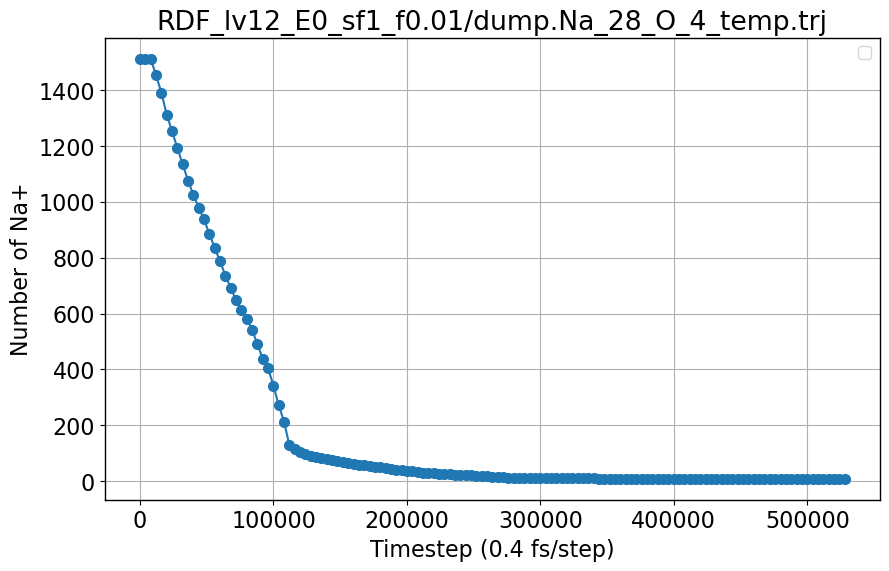

In [11]:
Na_list_O4 = plot_Na_bias_from_dump(1,0.01,28,4)[1]

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


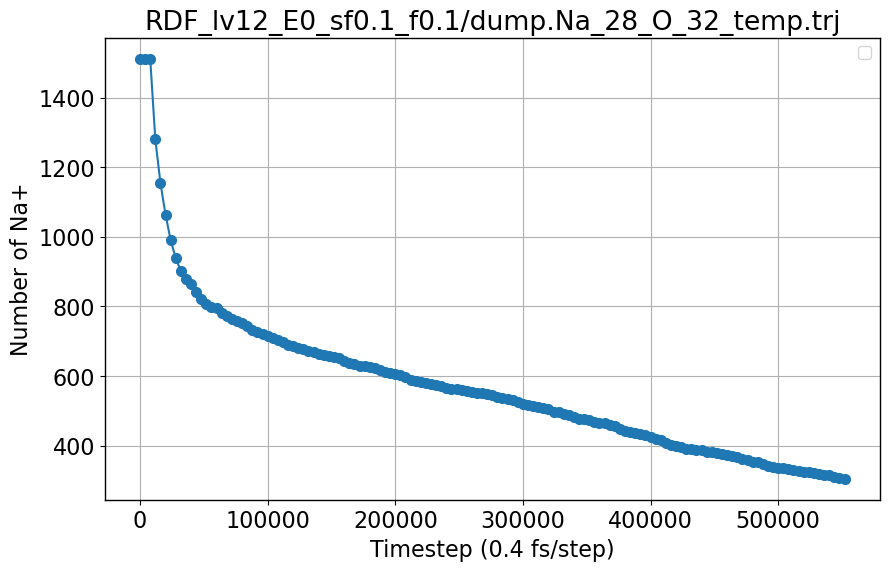

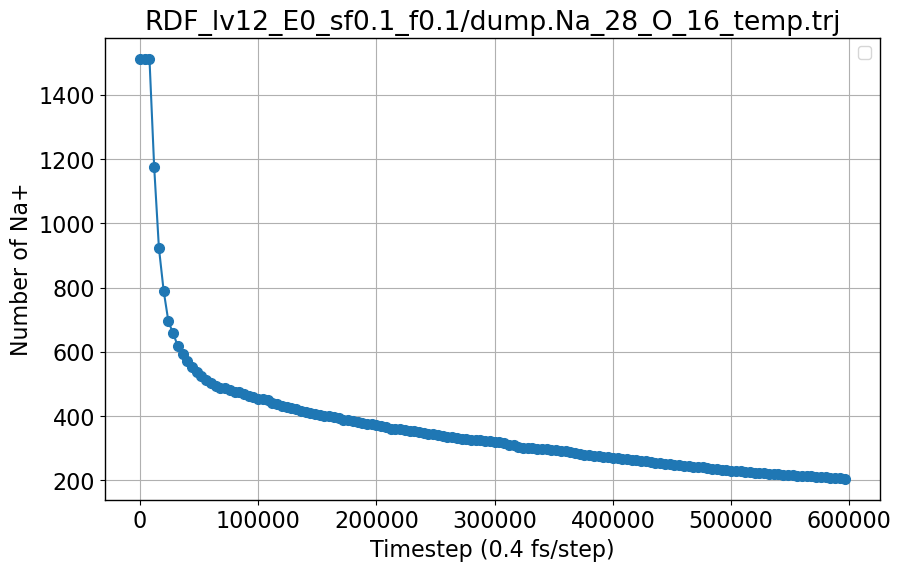

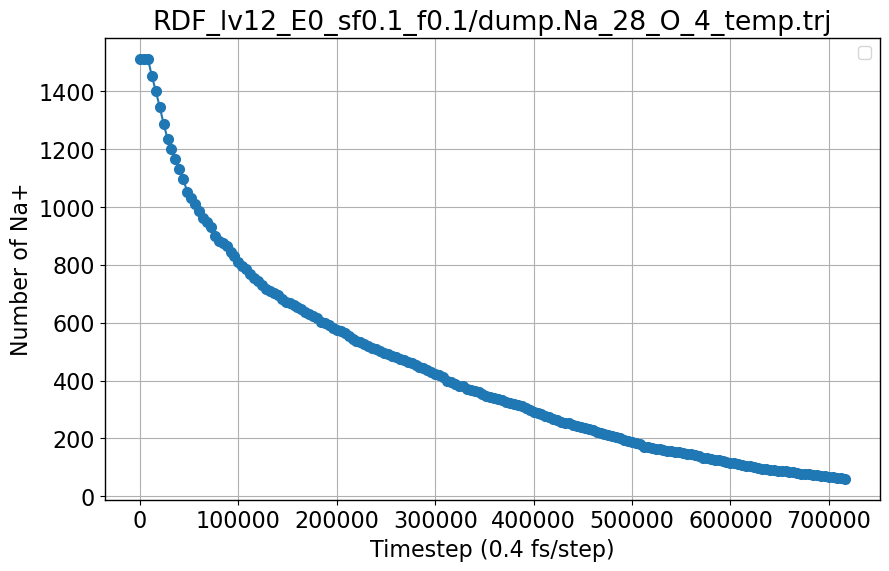

In [21]:
Na_list_O32 = plot_Na_bias_from_dump(0.1,0.1,28,32)[1]
Na_list_O16 = plot_Na_bias_from_dump(0.1,0.1,28,16)[1]
Na_list_O4 = plot_Na_bias_from_dump(0.1,0.1,28,4)[1]

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


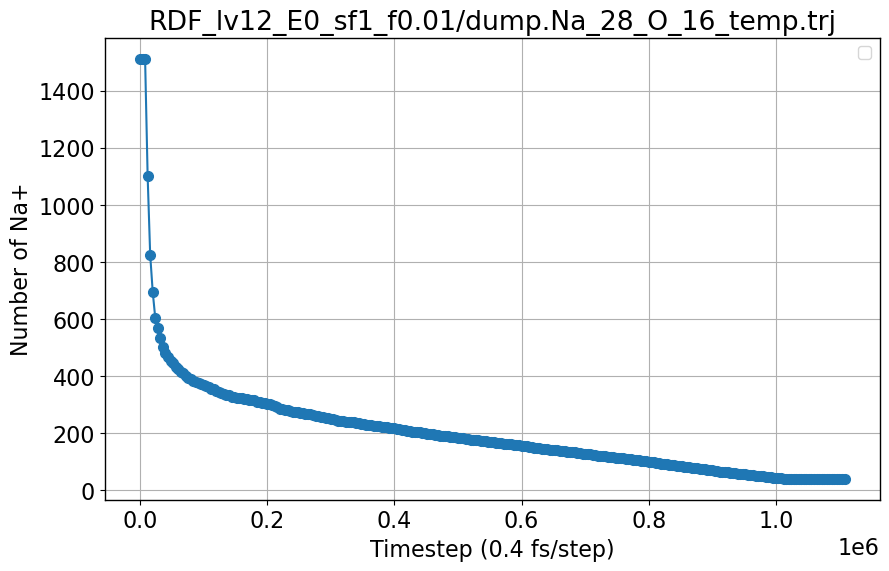

In [41]:
plot_Na_bias_from_dump(28,16)

In [ ]:
# Use the function
split_lammps_trj("dump.gcmc_1.trj")
#! rm ./trj/structure*
! mv structure* trj

In [ ]:
# averaging multiples trj
structure_1 = read_lammps_trj('./trj/structure_0.trj')
structure_2 = read_lammps_trj('./trj/structure_1.trj')



In [ ]:
structure_1[0]

In [ ]:
structure_2[0]

In [ ]:
trajectory_dir='./trj'

to_calculate = np.arange(0, len(os.listdir(trajectory_dir))-1, round(len(os.listdir(trajectory_dir))/20,0)).astype(int)

In [ ]:
to_calculate

In [ ]:
! rm ./xrd_patterns *xrd.dat
trajectory_dir = "./trj"
output_dir = "xrd_patterns"
os.makedirs(output_dir, exist_ok=True)

for i in range(to_calculate.shape[0]):
    file_name = f'structure_{to_calculate[i]}.trj'
    structure_file = os.path.join(trajectory_dir, file_name)
    
    # Read the structure from the trajectory file
    structure = read_lammps_trj(structure_file)
    
    # Calculate XRD pattern
    output_file = os.path.join(output_dir, f"{os.path.splitext(file_name)[0]}_xrd.dat")
    xrd_pattern = calculate_xrd(structure, output_file=output_file)
    
    print(f"XRD pattern calculated and saved for {file_name}")

In [ ]:
xrd_dir = "./xrd_patterns"
XRD_list=[]

for i in range(to_calculate.shape[0]):
    file_name = f'structure_{to_calculate[i]}_xrd.dat'
    file_path = os.path.join(xrd_dir, file_name)
    # Load the text file into a NumPy array
    try:
        # Adjust the delimiter and other parameters as needed
        array = np.loadtxt(file_path, delimiter=' ')  # Example delimiter
        XRD_list.append(array)
    except Exception as e:
        print(f"Error loading {file_path}: {e}")

In [ ]:
XRD_list[1][:,1].argmax()

In [ ]:
two_theta_to_q(XRD_list[1][XRD_list[1][:,1].argmax(),0],1.54059)

In [ ]:
fig = plt.figure(figsize=(8,5))
colors = cm.jet(np.linspace(0, 1, to_calculate.shape[0]))
for i in [1,5,10,15,19]:
    x=XRD_list[i][:,0]
    q=two_theta_to_q(x, 1.54059)
    y=XRD_list[i][:,1]
    plt.plot(q,y,label=i,linewidth=1, color=colors[i] )
    print(two_theta_to_q(XRD_list[i][XRD_list[i][:,1].argmax(),0],1.54059))
plt.legend()
plt.xlim(1.1,1.4)

In [ ]:
fig = plt.figure(figsize=(8,5))
colors = cm.jet(np.linspace(0, 1, to_calculate.shape[0]))

i=0
x=XRD_list[i][:,0]
q=two_theta_to_q(x, 1.54059)
y=XRD_list[i][:,1]
plt.plot(q,y,label=i,linewidth=1, color=colors[i] )
print(two_theta_to_q(XRD_list[i][XRD_list[i][:,1].argmax(),0],1.54059))

i=19
x=XRD_list[i][:,0]
q=two_theta_to_q(x, 1.54059)
y=XRD_list[i][:,1]
plt.plot(q,y,label=i,linewidth=1, color=colors[i] )
print(two_theta_to_q(XRD_list[i][XRD_list[i][:,1].argmax(),0],1.54059))

plt.legend()
#plt.xlim(1.1,1.4)

In [ ]:
fig = plt.figure(figsize=(8,5))
i=1
x=XRD_list[i][:,0]
q=two_theta_to_q(x, 1.54059)
y=XRD_list[i][:,1]
plt.plot(q,y,label=i,linewidth=1, color=colors[i] )
i=5
x=XRD_list[i][:,0]
q=two_theta_to_q(x, 1.54059)
y=XRD_list[i][:,1]
plt.plot(q,y,label=i,linewidth=1, color=colors[i] )
i=10
x=XRD_list[i][:,0]
q=two_theta_to_q(x, 1.54059)
y=XRD_list[i][:,1]
plt.plot(q,y,label=i,linewidth=1, color=colors[i] )
#plt.xlim(1.3,1.35)
#plt.xlim(1.6,1.8)

In [ ]:
trj_0 = read_lammps_trj('./structure_0.trj')
trj_0

In [ ]:
xrd_0 = calculate_xrd(trj_0)

In [ ]:
q = two_theta_to_q(xrd_0.x, 1.54059)

In [ ]:
fig = plt.figure(figsize=(8,5))
plt.plot(xrd_0.x, xrd_0.y)
#plt.xlim(1.15,1.35)
#plt.ylim(-5,80)
plt.xlabel('q')

# PDF

In [ ]:
files = os.listdir('./MD_analysis/299')

# Use a regular expression to match files that follow the POSCARn pattern
poscar_files = [f for f in files if re.match(r'POSCAR\d+', f)]
poscar_numbers = [int(re.search(r'POSCAR(\d+)', file).group(1)) for file in poscar_files]
#rdf_files = [f for f in files if re.match(r'rdf_final.rdf_\d+', f)]
#NaN_coor_files = [f for f in files if re.match(r'NaN_coord_final.txt_\d+', f)]
#MnN_coor_files = [f for f in files if re.match(r'MnN_coord_final.txt_\d+', f)]
#FeC_coor_files = [f for f in files if re.match(r'FeC_coord_final.txt_\d+', f)]

In [ ]:
path = './MD_analysis/299/'
files = os.listdir(path)
poscar_files = [f for f in files if re.match(r'POSCAR\d+', f)]
poscar_numbers = [int(re.search(r'POSCAR(\d+)', file).group(1)) for file in poscar_files]

for i in range(len(poscar_numbers)):
    file_path = path+f'POSCAR{poscar_numbers[i]}'  # Replace with your file path
    text_to_insert = "C Mn Fe N Na"
    insert_to_line_6(file_path, text_to_insert)

In [ ]:
name = ['C-Fe','C-N','N-Mn','N-Na','Fe-Mn']
colors = ['r', 'orange', 'blue', 'green', 'c']
species = ["C", "Mn", "Fe", "N", "Na"]

In [5]:
def insert_to_line_6(file_path, text_to_insert):
    # Read the file contents
    with open(file_path, 'r') as file:
        lines = file.readlines()
    
    # Insert the text into the 6th line (index 5 since it's 0-based indexing)
    lines.insert(5, text_to_insert + '\n')
    
    # Write the modified content back to the file
    with open(file_path, 'w') as file:
        file.writelines(lines)

In [7]:
def calculate_bond_angle(A, B, C):
   
    # Convert input to NumPy arrays
    A = np.array(A)
    B = np.array(B)
    C = np.array(C)
    # Calculate vectors
    AB = B - A
    BC = C - B
    # Calculate the magnitudes of the vectors
    AB_magnitude = np.linalg.norm(AB)
    BC_magnitude = np.linalg.norm(BC[0])
    # Calculate the dot product
    dot_product = np.dot(AB, BC[0])
    # Calculate the cosine of the angle
    cos_theta = dot_product / (AB_magnitude * BC_magnitude)
    # Ensure the cosine value is within the valid range for arccos
    cos_theta = np.clip(cos_theta, -1.0, 1.0)
    # Calculate the angle in radians
    angle_radians = np.arccos(cos_theta)
    # Convert to degrees
    angle_degrees = np.degrees(angle_radians)
    return 180 - angle_degrees

In [ ]:
path = './MD_analysis/'
iteration = '440'
files = os.listdir(path+iteration)
poscar_files = [f for f in files if re.match(r'POSCAR\d+', f)]
poscar_numbers = [int(re.search(r'POSCAR(\d+)', file).group(1)) for file in poscar_files]

for i in range(len(poscar_numbers)):
    file_path = path+iteration+f'/POSCAR{poscar_numbers[i]}'  # Replace with your file path
    text_to_insert = "C Mn Fe N Na"
    insert_to_line_6(file_path, text_to_insert)

for pos_num in range(len(poscar_numbers)):
    struct = Structure.from_file(path+iteration+f'/POSCAR{poscar_numbers[pos_num]}')
    pdf = np.loadtxt(path+iteration+f'/rdf_final.rdf_{poscar_numbers[pos_num]+1}', skiprows=4)
    NaN_coor = np.loadtxt(path+iteration+f'/NaN_coord_final.txt_{poscar_numbers[i]+1}', skiprows=9)
    MnN_coor = np.loadtxt(path+iteration+f'/MnN_coord_final.txt_{poscar_numbers[i]+1}', skiprows=9)
    FeC_coor = np.loadtxt(path+iteration+f'/FeC_coord_final.txt_{poscar_numbers[i]+1}', skiprows=9)
    na_count = sum(1 for site in struct if site.species_string == "Na")

    ###### RDF ######
    r = pdf[:,1]
    fig = plt.figure(figsize=(8,5))
    for i in range(2, pdf.shape[1],2):
        j = int(i/2)
        plt.plot(r, pdf[:,i], label = name[j-1], color = colors[j-1])
        plt.text(pdf[:,1][pdf[:,i].argmax()], 
                 pdf[:,i].max(), 
                 f'{pdf[:,1][pdf[:,i].argmax()]}',
                 color = colors[j-1])
    plt.legend()
    plt.xlabel('r (A)')
    plt.xlim(0,5)
    plt.ylabel('G(r)')
    plt.grid()
    plt.title(iteration+ f' RDF_{poscar_numbers[pos_num]}'+f' n_Na = {na_count}')
    plt.savefig(path + iteration + f'/RDF_{poscar_numbers[pos_num]}', dpi=300, bbox_inches='tight')

    ###### Bond angles #####
    from collections import Counter
    # Extract species (element types) from the sites
    species = [site.species_string for site in struct.sites]
    
    # Count the occurrences of each species
    species_counts = Counter(species)
    counts_list = []
    
    # Print the number of atoms of each type
    for element, count in species_counts.items():
        #print(f"Element: {element}, Count: {count}")
        counts_list.append(count)
        
    #1. find the coordiate of all Mn atoms
    coordinates = []
    for site in struct.sites:
        x, y, z = site.coords  # Extracting the coordinates
        coordinates.append((x, y, z))  # Append to the list 
    C_coor = np.array(coordinates[:counts_list[0]])
    Mn_coor = np.array(coordinates[counts_list[0]:counts_list[0]+counts_list[1]])
    Fe_coor = np.array(coordinates[counts_list[0]+counts_list[1]:counts_list[0]+counts_list[1]+counts_list[2]])
    N_coor = np.array(coordinates[counts_list[0]+counts_list[1]+counts_list[2]:])

    #2. find the 6 closest atoms to each Mn which should be N
    distance_threshold = 3.0
    # Initialize a list to store the results
    n_within_distance = []
    # Calculate distances
    for mn in Mn_coor:
        distances = np.linalg.norm(N_coor - mn, axis=1)  # Compute distances from the current Mn
        # Find N coordinates within the distance threshold
        close_n = N_coor[distances < distance_threshold]
        n_within_distance.append(close_n)
    n_within_distance = np.array(n_within_distance)

    #3. find the closet atom to those N which should be C
    distance_threshold = 2.5
    # Initialize a list to store the results
    c_within_distance = []
    # Calculate distances
    for i in range(n_within_distance.shape[0]):
        for j in range(n_within_distance[i].shape[0]):
            n = n_within_distance[i][j]
            distances = np.linalg.norm(C_coor - n, axis=1)  # Compute distances from the current Mn
            # Find N coordinates within the distance threshold
            close_c = C_coor[distances < distance_threshold]
            c_within_distance.append(close_c)

    #4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
    Mn_N_C_angles = []
    c_index = 0
    for i in range(n_within_distance.shape[0]):
        for j in range(n_within_distance[i].shape[0]):
            Mn = Mn_coor[i]
            N = n_within_distance[i][j]
            if c_index < len(c_within_distance):
                C_n = c_within_distance[c_index]
            else:
                print(f"Warning: c_index {c_index} out of bounds, skipping...")
                continue  # Skip to the next iteration if out of bounds
            try:
                # Calculate the bond angle and append to the list
                angle = calculate_bond_angle(Mn, N, C_n)
                Mn_N_C_angles.append(angle)
            except Exception as e:
                # Handle any exceptions and continue the loop
                print(f"Error calculating angle for Mn: {Mn}, N: {N}, C_n: {C_n}. Error: {e}")
            c_index += 1  # Increment c_index regardless of success or failure
    
    #2. find the 6 closest atoms to each Mn which should be N
    distance_threshold = 3.0
    
    # Initialize a list to store the results
    c_within_distance = []
    
    # Calculate distances
    for fe in Fe_coor:
        distances = np.linalg.norm(C_coor - fe, axis=1)  # Compute distances from the current Mn
        # Find C coordinates within the distance threshold
        close_c = C_coor[distances < distance_threshold]
        c_within_distance.append(close_c)
    
    c_within_distance = np.array(c_within_distance)

    #3. find the closet atom to those N which should be C
    
    distance_threshold = 2.5
    
    # Initialize a list to store the results
    n_within_distance = []
    
    # Calculate distances
    for i in range(c_within_distance.shape[0]):
        for j in range(c_within_distance[i].shape[0]):
            c = c_within_distance[i][j]
            distances = np.linalg.norm(N_coor - c, axis=1)  # Compute distances from the current Mn
            # Find N coordinates within the distance threshold
            close_n = N_coor[distances < distance_threshold]
            n_within_distance.append(close_n)
    
    n_within_distance = np.array(n_within_distance)

    #4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
    Fe_C_N_angles = []
    n_index = 0
    for i in range(c_within_distance.shape[0]):
        for j in range(c_within_distance[i].shape[0]):
            Fe = Fe_coor[i]
            C = c_within_distance[i][j]
            
            # Ensure c_index is within bounds
            if n_index < len(n_within_distance):
                N_c = n_within_distance[n_index]
            else:
                print(f"Warning: c_index {n_index} out of bounds, skipping...")
                continue  # Skip to the next iteration if out of bounds
            try:
                # Calculate the bond angle and append to the list
                angle = calculate_bond_angle(Fe,C,N_c)
                Fe_C_N_angles.append(angle)
            except Exception as e:
                # Handle any exceptions and continue the loop
                print(f"Error calculating angle for Fe: {Fe}, C: {C}, N: {N_c}. Error: {e}")
            
            n_index += 1  # Increment c_index regardless of success or failure

    fig = plt.figure(figsize=(6,5))
    
    bin_edges = range(90,180,1)  # bins from -10 to 20
    i=0
    # Plotting the first histogram
    counts, edges, bars = plt.hist([Mn_N_C_angles, Fe_C_N_angles], bins = bin_edges,
                                   alpha=0.7, color=['red','blue'], 
                                    label = ['Mn-N-C bond angles', 'Fe_C_N bond angles'])
    plt.text(92,8,f'Mn-N-C angles = {round(sum(Mn_N_C_angles) / len(Mn_N_C_angles),3)}\nFe_C_N angles = {round(sum(Fe_C_N_angles) / len(Fe_C_N_angles),3)}')
    plt.xlabel('Bond Angles')
    plt.ylabel('Count')
    plt.legend()
    plt.title(iteration+ f' bond angle_{poscar_numbers[pos_num]}'+f' n_Na = {na_count}')
    plt.savefig(path + iteration + f'/bond angle_{poscar_numbers[pos_num]}', dpi=300, bbox_inches='tight')

    fig = plt.figure(figsize=(6,5))

    bin_edges = range(3,9,1)  # bins from -10 to 20
    i=0
    # Plotting the first histogram
    counts, edges, bars = plt.hist([FeC_coor[:,2],MnN_coor[:,2],NaN_coor[:,2]], bins = bin_edges,
                                   alpha=0.7, color=['red','blue','green'], 
                                   edgecolor='black', label = ['FeC_coor','MnN_coor','NaN_coor'])
    plt.text(3,20,f'Fe-C coor. = {FeC_coor[:,2].mean()}\nMn-N coor. = {MnN_coor[:,2].mean()}\nNa-N coor. = {NaN_coor[:,2].mean()}')
    plt.title(f'Atom count'+f' n_Na = {na_count}')
    plt.xlabel('Coordination number')
    plt.ylabel('Count')
    #plt.legend(frameon=False)
    
    plt.savefig(path + iteration + f'/coordination_{poscar_numbers[pos_num]}', dpi=300, bbox_inches='tight')

In [ ]:
struct
na_count = sum(1 for site in struct if site.species_string == "Na")
print(f"Number of Na atoms: {na_count}")

In [ ]:
text_to_insert = "C Mn Fe N Na"
insert_to_line_6('./300K_RDF_3600.vasp', text_to_insert)

## Bond Angel + PDF

In [ ]:
struct = Structure.from_file('300K_RDF_100.vasp')
###### Bond angles #####
from collections import Counter
# Extract species (element types) from the sites
species = [site.species_string for site in struct.sites]

# Count the occurrences of each species
species_counts = Counter(species)
counts_list = []

# Print the number of atoms of each type
for element, count in species_counts.items():
    #print(f"Element: {element}, Count: {count}")
    counts_list.append(count)
    
#1. find the coordiate of all Mn atoms
coordinates = []
for site in struct.sites:
    x, y, z = site.coords  # Extracting the coordinates
    coordinates.append((x, y, z))  # Append to the list 
C_coor = np.array(coordinates[:counts_list[0]])
Mn_coor = np.array(coordinates[counts_list[0]:counts_list[0]+counts_list[1]])
Fe_coor = np.array(coordinates[counts_list[0]+counts_list[1]:counts_list[0]+counts_list[1]+counts_list[2]])
N_coor = np.array(coordinates[counts_list[0]+counts_list[1]+counts_list[2]:])

#2. find the 6 closest atoms to each Mn which should be N
distance_threshold = 3.0
# Initialize a list to store the results
n_within_distance = []
# Calculate distances
for mn in Mn_coor:
    distances = np.linalg.norm(N_coor - mn, axis=1)  # Compute distances from the current Mn
    # Find N coordinates within the distance threshold
    close_n = N_coor[distances < distance_threshold]
    n_within_distance.append(close_n)
n_within_distance = np.array(n_within_distance)

#3. find the closet atom to those N which should be C
distance_threshold = 2.5
# Initialize a list to store the results
c_within_distance = []
# Calculate distances
for i in range(n_within_distance.shape[0]):
    for j in range(n_within_distance[i].shape[0]):
        n = n_within_distance[i][j]
        distances = np.linalg.norm(C_coor - n, axis=1)  # Compute distances from the current Mn
        # Find N coordinates within the distance threshold
        close_c = C_coor[distances < distance_threshold]
        c_within_distance.append(close_c)

#4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
Mn_N_C_angles = []
c_index = 0
for i in range(n_within_distance.shape[0]):
    for j in range(n_within_distance[i].shape[0]):
        Mn = Mn_coor[i]
        N = n_within_distance[i][j]
        if c_index < len(c_within_distance):
            C_n = c_within_distance[c_index]
        else:
            print(f"Warning: c_index {c_index} out of bounds, skipping...")
            continue  # Skip to the next iteration if out of bounds
        try:
            # Calculate the bond angle and append to the list
            angle = calculate_bond_angle(Mn, N, C_n)
            Mn_N_C_angles.append(angle)
        except Exception as e:
            # Handle any exceptions and continue the loop
            print(f"Error calculating angle for Mn: {Mn}, N: {N}, C_n: {C_n}. Error: {e}")
        c_index += 1  # Increment c_index regardless of success or failure

#2. find the 6 closest atoms to each Mn which should be N
distance_threshold = 3.0

# Initialize a list to store the results
c_within_distance = []

# Calculate distances
for fe in Fe_coor:
    distances = np.linalg.norm(C_coor - fe, axis=1)  # Compute distances from the current Mn
    # Find C coordinates within the distance threshold
    close_c = C_coor[distances < distance_threshold]
    c_within_distance.append(close_c)

c_within_distance = np.array(c_within_distance)

#3. find the closet atom to those N which should be C

distance_threshold = 2.5

# Initialize a list to store the results
n_within_distance = []

# Calculate distances
for i in range(c_within_distance.shape[0]):
    for j in range(c_within_distance[i].shape[0]):
        c = c_within_distance[i][j]
        distances = np.linalg.norm(N_coor - c, axis=1)  # Compute distances from the current Mn
        # Find N coordinates within the distance threshold
        close_n = N_coor[distances < distance_threshold]
        n_within_distance.append(close_n)

n_within_distance = np.array(n_within_distance)

#4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
Fe_C_N_angles = []
n_index = 0
for i in range(c_within_distance.shape[0]):
    for j in range(c_within_distance[i].shape[0]):
        Fe = Fe_coor[i]
        C = c_within_distance[i][j]
        
        # Ensure c_index is within bounds
        if n_index < len(n_within_distance):
            N_c = n_within_distance[n_index]
        else:
            print(f"Warning: c_index {n_index} out of bounds, skipping...")
            continue  # Skip to the next iteration if out of bounds
        try:
            # Calculate the bond angle and append to the list
            angle = calculate_bond_angle(Fe,C,N_c)
            Fe_C_N_angles.append(angle)
        except Exception as e:
            # Handle any exceptions and continue the loop
            print(f"Error calculating angle for Fe: {Fe}, C: {C}, N: {N_c}. Error: {e}")
        
        n_index += 1  # Increment c_index regardless of success or failure

np.save('Mn_N_C_angles_100.npy', Mn_N_C_angles)
np.save('Fe_C_N_angles_100.npy', Fe_C_N_angles)

struct = Structure.from_file('300K_RDF_3600.vasp')
###### Bond angles #####
from collections import Counter
# Extract species (element types) from the sites
species = [site.species_string for site in struct.sites]

# Count the occurrences of each species
species_counts = Counter(species)
counts_list = []

# Print the number of atoms of each type
for element, count in species_counts.items():
    #print(f"Element: {element}, Count: {count}")
    counts_list.append(count)
    
#1. find the coordiate of all Mn atoms
coordinates = []
for site in struct.sites:
    x, y, z = site.coords  # Extracting the coordinates
    coordinates.append((x, y, z))  # Append to the list 
C_coor = np.array(coordinates[:counts_list[0]])
Mn_coor = np.array(coordinates[counts_list[0]:counts_list[0]+counts_list[1]])
Fe_coor = np.array(coordinates[counts_list[0]+counts_list[1]:counts_list[0]+counts_list[1]+counts_list[2]])
N_coor = np.array(coordinates[counts_list[0]+counts_list[1]+counts_list[2]:])

#2. find the 6 closest atoms to each Mn which should be N
distance_threshold = 3.0
# Initialize a list to store the results
n_within_distance = []
# Calculate distances
for mn in Mn_coor:
    distances = np.linalg.norm(N_coor - mn, axis=1)  # Compute distances from the current Mn
    # Find N coordinates within the distance threshold
    close_n = N_coor[distances < distance_threshold]
    n_within_distance.append(close_n)
n_within_distance = np.array(n_within_distance)

#3. find the closet atom to those N which should be C
distance_threshold = 2.5
# Initialize a list to store the results
c_within_distance = []
# Calculate distances
for i in range(n_within_distance.shape[0]):
    for j in range(n_within_distance[i].shape[0]):
        n = n_within_distance[i][j]
        distances = np.linalg.norm(C_coor - n, axis=1)  # Compute distances from the current Mn
        # Find N coordinates within the distance threshold
        close_c = C_coor[distances < distance_threshold]
        c_within_distance.append(close_c)

#4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
Mn_N_C_angles_2 = []
c_index = 0
for i in range(n_within_distance.shape[0]):
    for j in range(n_within_distance[i].shape[0]):
        Mn = Mn_coor[i]
        N = n_within_distance[i][j]
        if c_index < len(c_within_distance):
            C_n = c_within_distance[c_index]
        else:
            #print(f"Warning: c_index {c_index} out of bounds, skipping...")
            continue  # Skip to the next iteration if out of bounds
        try:
            # Calculate the bond angle and append to the list
            angle = calculate_bond_angle(Mn, N, C_n)
            Mn_N_C_angles_2.append(angle)
        except Exception as e:
            # Handle any exceptions and continue the loop
            print(f"Error calculating angle for Mn: {Mn}, N: {N}, C_n: {C_n}. Error: {e}")
        c_index += 1  # Increment c_index regardless of success or failure

#2. find the 6 closest atoms to each Mn which should be N
distance_threshold = 3.0

# Initialize a list to store the results
c_within_distance = []

# Calculate distances
for fe in Fe_coor:
    distances = np.linalg.norm(C_coor - fe, axis=1)  # Compute distances from the current Mn
    # Find C coordinates within the distance threshold
    close_c = C_coor[distances < distance_threshold]
    c_within_distance.append(close_c)

c_within_distance = np.array(c_within_distance)

#3. find the closet atom to those N which should be C

distance_threshold = 2.5

# Initialize a list to store the results
n_within_distance = []

# Calculate distances
for i in range(c_within_distance.shape[0]):
    for j in range(c_within_distance[i].shape[0]):
        c = c_within_distance[i][j]
        distances = np.linalg.norm(N_coor - c, axis=1)  # Compute distances from the current Mn
        # Find N coordinates within the distance threshold
        close_n = N_coor[distances < distance_threshold]
        n_within_distance.append(close_n)

n_within_distance = np.array(n_within_distance)

#4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
Fe_C_N_angles_2 = []
n_index = 0
for i in range(c_within_distance.shape[0]):
    for j in range(c_within_distance[i].shape[0]):
        Fe = Fe_coor[i]
        C = c_within_distance[i][j]
        
        # Ensure c_index is within bounds
        if n_index < len(n_within_distance):
            N_c = n_within_distance[n_index]
        else:
            #print(f"Warning: c_index {n_index} out of bounds, skipping...")
            continue  # Skip to the next iteration if out of bounds
        try:
            # Calculate the bond angle and append to the list
            angle = calculate_bond_angle(Fe,C,N_c)
            Fe_C_N_angles_2.append(angle)
        except Exception as e:
            # Handle any exceptions and continue the loop
            print(f"Error calculating angle for Fe: {Fe}, C: {C}, N: {N_c}. Error: {e}")
        
        n_index += 1  # Increment c_index regardless of success or failure

np.save('Fe_C_N_angles_3600.npy', Fe_C_N_angles_2)
np.save('Mn_N_C_angles_3600.npy', Mn_N_C_angles_2)

In [46]:
counts_list

[5184, 864, 864, 5184, 1512, 216, 432]

In [47]:
N_coor.shape

(5184, 3)

In [6]:

temp=400
for O in [4,16,32]:
    for Na in [4,16,28]:
        struct = Structure.from_file(f"./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}.vasp")
        ###### Bond angles #####
        from collections import Counter
        # Extract species (element types) from the sites
        species = [site.species_string for site in struct.sites]
        
        # Count the occurrences of each species
        species_counts = Counter(species)
        counts_list = []
        
        # Print the number of atoms of each type
        for element, count in species_counts.items():
            #print(f"Element: {element}, Count: {count}")
            counts_list.append(count)
            
        #1. find the coordiate of all Mn atoms
        coordinates = []
        for site in struct.sites:
            x, y, z = site.coords  # Extracting the coordinates
            coordinates.append((x, y, z))  # Append to the list 
        C_coor = np.array(coordinates[:counts_list[0]])
        Mn_coor = np.array(coordinates[counts_list[0]:counts_list[0]+counts_list[1]])
        Fe_coor = np.array(coordinates[counts_list[0]+counts_list[1]:counts_list[0]+counts_list[1]+counts_list[2]])
        N_coor = np.array(coordinates[counts_list[0]+counts_list[1]+counts_list[2]:counts_list[0]+counts_list[1]+counts_list[2]+counts_list[3]])
        
        #2. find the 6 closest atoms to each Mn which should be N
        distance_threshold = 3.0
        # Initialize a list to store the results
        n_within_distance = []
        # Calculate distances
        for mn in Mn_coor:
            distances = np.linalg.norm(N_coor - mn, axis=1)  # Compute distances from the current Mn
            # Find N coordinates within the distance threshold
            close_n = N_coor[distances < distance_threshold]
            n_within_distance.append(close_n)
        n_within_distance = np.array(n_within_distance)
        
        #3. find the closet atom to those N which should be C
        distance_threshold = 2.5
        # Initialize a list to store the results
        c_within_distance = []
        # Calculate distances
        for i in range(n_within_distance.shape[0]):
            for j in range(n_within_distance[i].shape[0]):
                n = n_within_distance[i][j]
                distances = np.linalg.norm(C_coor - n, axis=1)  # Compute distances from the current Mn
                # Find N coordinates within the distance threshold
                close_c = C_coor[distances < distance_threshold]
                c_within_distance.append(close_c)
        
        #4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
        Mn_N_C_angles = []
        c_index = 0
        for i in range(n_within_distance.shape[0]):
            for j in range(n_within_distance[i].shape[0]):
                Mn = Mn_coor[i]
                N = n_within_distance[i][j]
                if c_index < len(c_within_distance):
                    C_n = c_within_distance[c_index]
                else:
                    print(f"Warning: c_index {c_index} out of bounds, skipping...")
                    continue  # Skip to the next iteration if out of bounds
                try:
                    # Calculate the bond angle and append to the list
                    angle = calculate_bond_angle(Mn, N, C_n)
                    Mn_N_C_angles.append(angle)
                except Exception as e:
                    # Handle any exceptions and continue the loop
                    print(f"Error calculating angle for Mn: {Mn}, N: {N}, C_n: {C_n}. Error: {e}")
                c_index += 1  # Increment c_index regardless of success or failure
        
        #2. find the 6 closest atoms to each Mn which should be N
        distance_threshold = 3.0
        
        # Initialize a list to store the results
        c_within_distance = []
        
        # Calculate distances
        for fe in Fe_coor:
            distances = np.linalg.norm(C_coor - fe, axis=1)  # Compute distances from the current Mn
            # Find C coordinates within the distance threshold
            close_c = C_coor[distances < distance_threshold]
            c_within_distance.append(close_c)
        
        c_within_distance = np.array(c_within_distance)
        
        #3. find the closet atom to those N which should be C
        
        distance_threshold = 2.5
        
        # Initialize a list to store the results
        n_within_distance = []
        
        # Calculate distances
        for i in range(c_within_distance.shape[0]):
            for j in range(c_within_distance[i].shape[0]):
                c = c_within_distance[i][j]
                distances = np.linalg.norm(N_coor - c, axis=1)  # Compute distances from the current Mn
                # Find N coordinates within the distance threshold
                close_n = N_coor[distances < distance_threshold]
                n_within_distance.append(close_n)
        
        n_within_distance = np.array(n_within_distance)
        
        #4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
        Fe_C_N_angles = []
        n_index = 0
        for i in range(c_within_distance.shape[0]):
            for j in range(c_within_distance[i].shape[0]):
                Fe = Fe_coor[i]
                C = c_within_distance[i][j]
                
                # Ensure c_index is within bounds
                if n_index < len(n_within_distance):
                    N_c = n_within_distance[n_index]
                else:
                    print(f"Warning: c_index {n_index} out of bounds, skipping...")
                    continue  # Skip to the next iteration if out of bounds
                try:
                    # Calculate the bond angle and append to the list
                    angle = calculate_bond_angle(Fe,C,N_c)
                    Fe_C_N_angles.append(angle)
                except Exception as e:
                    # Handle any exceptions and continue the loop
                    print(f"Error calculating angle for Fe: {Fe}, C: {C}, N: {N_c}. Error: {e}")
                
                n_index += 1  # Increment c_index regardless of success or failure
        
        np.save(f"./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp", Mn_N_C_angles)
        np.save(f'./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Fe_C_N_angles.vasp', Fe_C_N_angles)


/home/yy276937/.conda/envs/py37/lib/python3.7/site-packages/ipykernel_launcher.py:39: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


Error calculating angle for Mn: [59.8066 49.8764 22.6462], N: [59.9534 47.8448 22.3796], C_n: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Mn: [59.5365 40.0411 23.0137], N: [59.925  41.9478 22.5354], C_n: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Mn: [-1.11833 45.0332  27.7375 ], N: [-0.74653 47.0794  27.5869 ], C_n: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Mn: [59.9463 50.2706 32.8333], N: [59.7946 48.0873 32.8706], C_n: []. Error: index 0 is out of bounds for axis 0 with size 0


/home/yy276937/.conda/envs/py37/lib/python3.7/site-packages/ipykernel_launcher.py:88: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
/home/yy276937/.conda/envs/py37/lib/python3.7/site-packages/ipykernel_launcher.py:106: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


Error calculating angle for Fe: [59.7693   4.07186  2.15612], C: [59.8299   2.21942  2.12046], N: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Fe: [59.7176 44.7308 12.3998], C: [59.855  42.7666 12.6814], N: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Fe: [59.741  55.1064 12.4269], C: [60.0093 53.2937 12.4771], N: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Fe: [59.7098   9.23618 17.8833 ], C: [59.645    7.44181 18.0187 ], N: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Fe: [59.868 39.991 17.854], C: [59.9628 41.8582 17.6258], N: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Fe: [59.868 39.991 17.854], C: [59.9504 38.1337 17.7141], N: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Fe: [59.7072   -0.848475 17.6257  ], C: [59.7448   1.04577 1

In [83]:
Mn_N_C_angles_interface = np.load(f"../../../hydration/{temp}_diffusion_2/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp.npy")
Fe_C_N_angles_interface = np.load(f'../../../hydration/{temp}_diffusion_2/{temp}K_Na_{Na}_O_{O}_Fe_C_N_angles.vasp.npy')

In [14]:
Mn_N_C_angles = np.load(f"../../../hydration/{temp}_diffusion_3/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp.npy")
Mn_N_C_angles

array([172.64514657, 161.91216413, 156.47746332, ..., 177.32378762,
       177.64335438, 144.04298011])

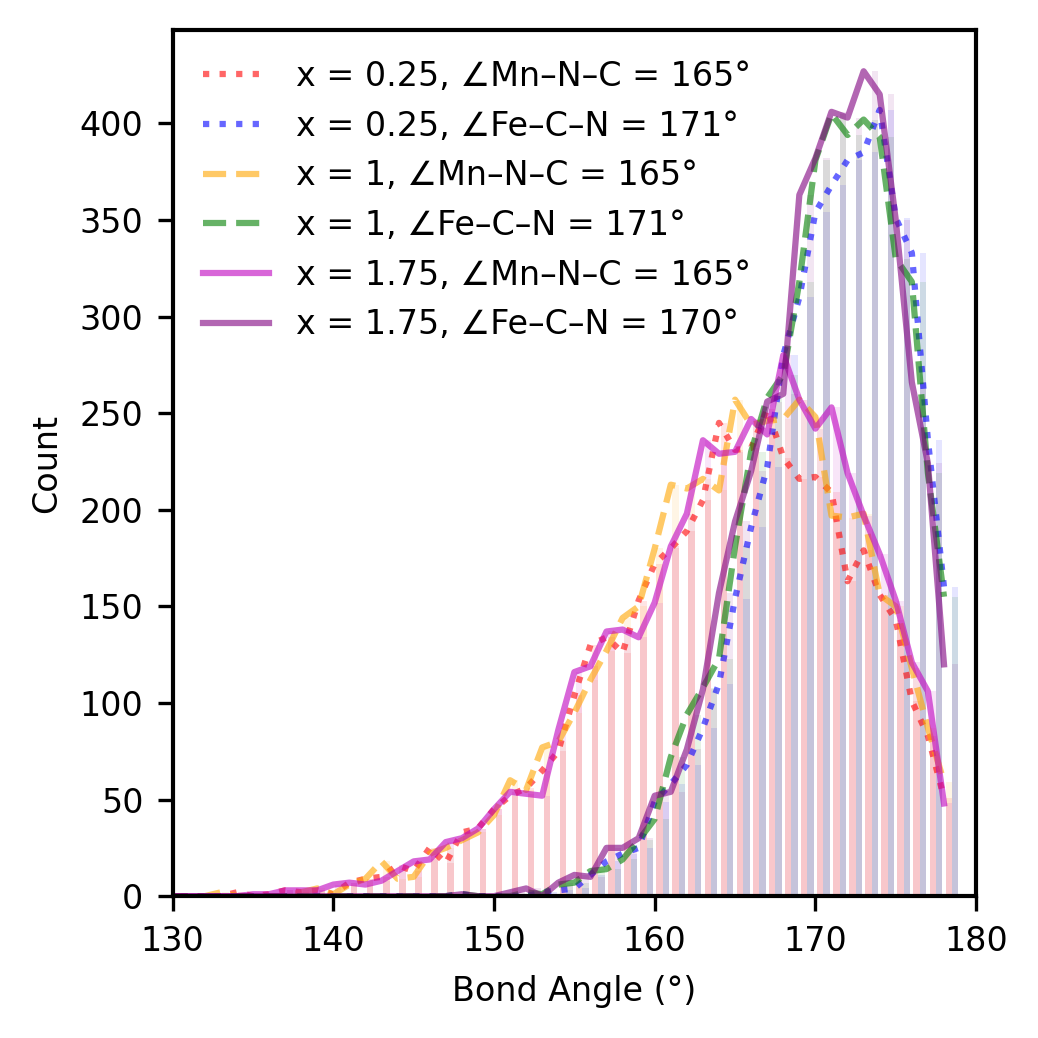

In [19]:
plt.rcParams.update({'font.size': 8})
plt.rcParams.update({'lines.linewidth':1.5})
plt.rcParams.update({'axes.linewidth':1})
plt.rcParams.update({'lines.markersize':5})
plt.rcParams.update({'legend.fontsize': 8})
plt.figure(figsize=(singlecol, singlecol), dpi=300)
bin_edges = range(110, 180, 1)

temp, Na, O = 400, 4, 32
Mn_N_C_angles = np.load(f"./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp.npy")
Fe_C_N_angles = np.load(f'./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Fe_C_N_angles.vasp.npy')

counts, edges, bars = plt.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.1,
    color=['red', 'blue'],
)
plt.plot(edges[:-1],counts[0], ':', color='red', alpha=0.6, label=f'x = 0.25, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°')
plt.plot(edges[:-1],counts[1], ':', color='blue', alpha=0.6, label=f'x = 0.25, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°')

temp, Na, O = 400, 16, 32
Mn_N_C_angles = np.load(f"./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp.npy")
Fe_C_N_angles = np.load(f'./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Fe_C_N_angles.vasp.npy')

counts, edges, bars = plt.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.1,
    color=['orange', 'green'],
)
plt.plot(edges[:-1],counts[0], '--', color='orange', alpha=0.6, label=f'x = 1, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°')
plt.plot(edges[:-1],counts[1], '--', color='green', alpha=0.6, label=f'x = 1, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°')

temp, Na, O = 400, 28, 32
Mn_N_C_angles = np.load(f"./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp.npy")
Fe_C_N_angles = np.load(f'./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Fe_C_N_angles.vasp.npy')

counts, edges, bars = plt.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.1,
    color=['m', 'purple'],
)
plt.plot(edges[:-1],counts[0], '-', color='m', alpha=0.6, label=f'x = 1.75, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°')
plt.plot(edges[:-1],counts[1], '-', color='purple', alpha=0.6, label=f'x = 1.75, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°')


plt.legend(frameon=False)
plt.xlabel('Bond Angle (°)')
plt.xlim(130,180)
plt.ylabel('Count')
plt.tight_layout()
plt.savefig(f'./hydration/{temp}_bond_angle_O_32.svg')

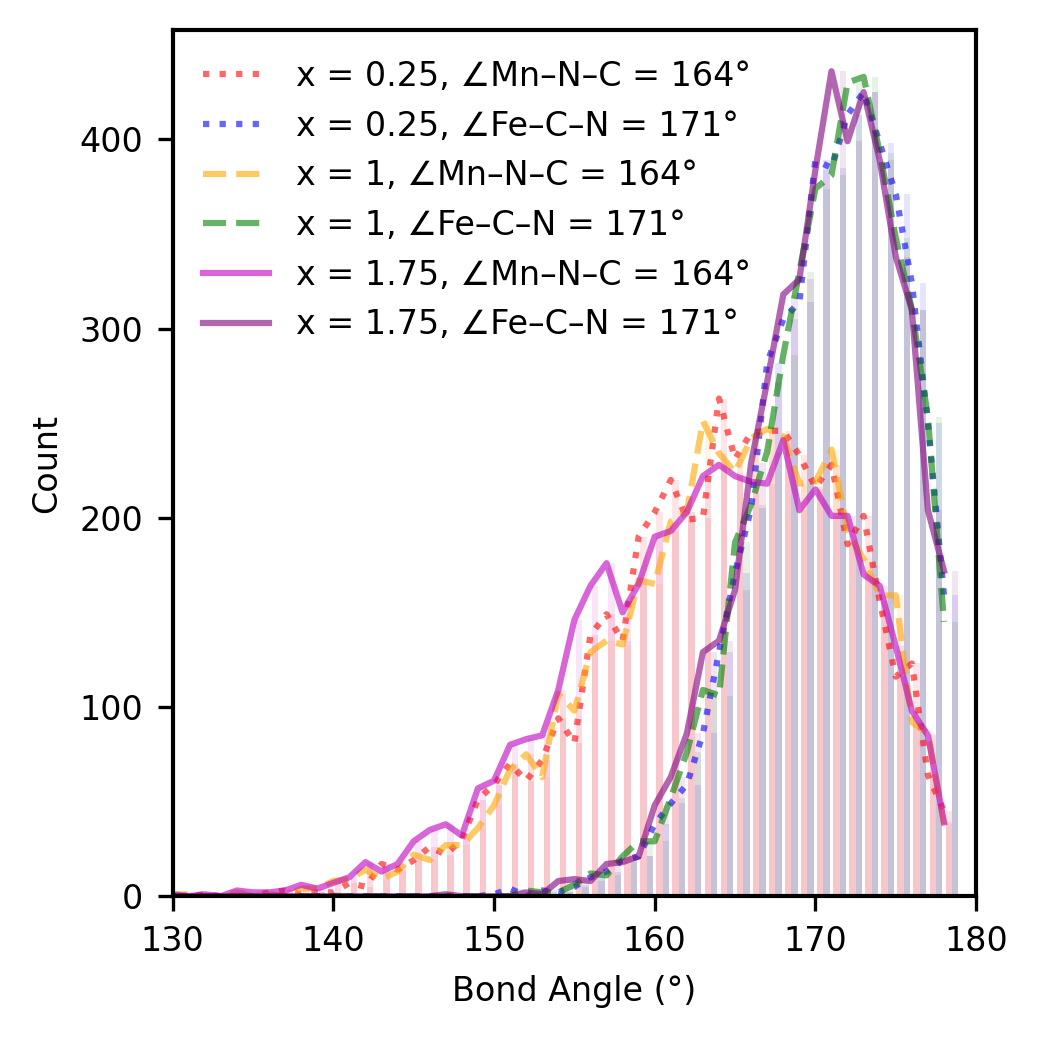

In [18]:
plt.rcParams.update({'font.size': 8})
plt.rcParams.update({'lines.linewidth':1.5})
plt.rcParams.update({'axes.linewidth':1})
plt.rcParams.update({'lines.markersize':5})
plt.rcParams.update({'legend.fontsize': 8})
plt.figure(figsize=(singlecol, singlecol), dpi=300)
bin_edges = range(110, 180, 1)

temp, Na, O = 400, 4, 16
Mn_N_C_angles = np.load(f"./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp.npy")
Fe_C_N_angles = np.load(f'./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Fe_C_N_angles.vasp.npy')

counts, edges, bars = plt.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.1,
    color=['red', 'blue'],
)
plt.plot(edges[:-1],counts[0], ':', color='red', alpha=0.6, label=f'x = 0.25, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°')
plt.plot(edges[:-1],counts[1], ':', color='blue', alpha=0.6, label=f'x = 0.25, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°')

temp, Na, O = 400, 16, 16
Mn_N_C_angles = np.load(f"./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp.npy")
Fe_C_N_angles = np.load(f'./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Fe_C_N_angles.vasp.npy')

counts, edges, bars = plt.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.1,
    color=['orange', 'green'],
)
plt.plot(edges[:-1],counts[0], '--', color='orange', alpha=0.6, label=f'x = 1, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°')
plt.plot(edges[:-1],counts[1], '--', color='green', alpha=0.6, label=f'x = 1, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°')

temp, Na, O = 400, 28, 16
Mn_N_C_angles = np.load(f"./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp.npy")
Fe_C_N_angles = np.load(f'./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Fe_C_N_angles.vasp.npy')

counts, edges, bars = plt.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.1,
    color=['m', 'purple'],
)
plt.plot(edges[:-1],counts[0], '-', color='m', alpha=0.6, label=f'x = 1.75, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°')
plt.plot(edges[:-1],counts[1], '-', color='purple', alpha=0.6, label=f'x = 1.75, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°')


plt.legend(frameon=False)
plt.xlabel('Bond Angle (°)')
plt.xlim(130,180)
plt.ylabel('Count')
plt.tight_layout()
plt.savefig(f'./hydration/{temp}_bond_angle_O_16.svg')

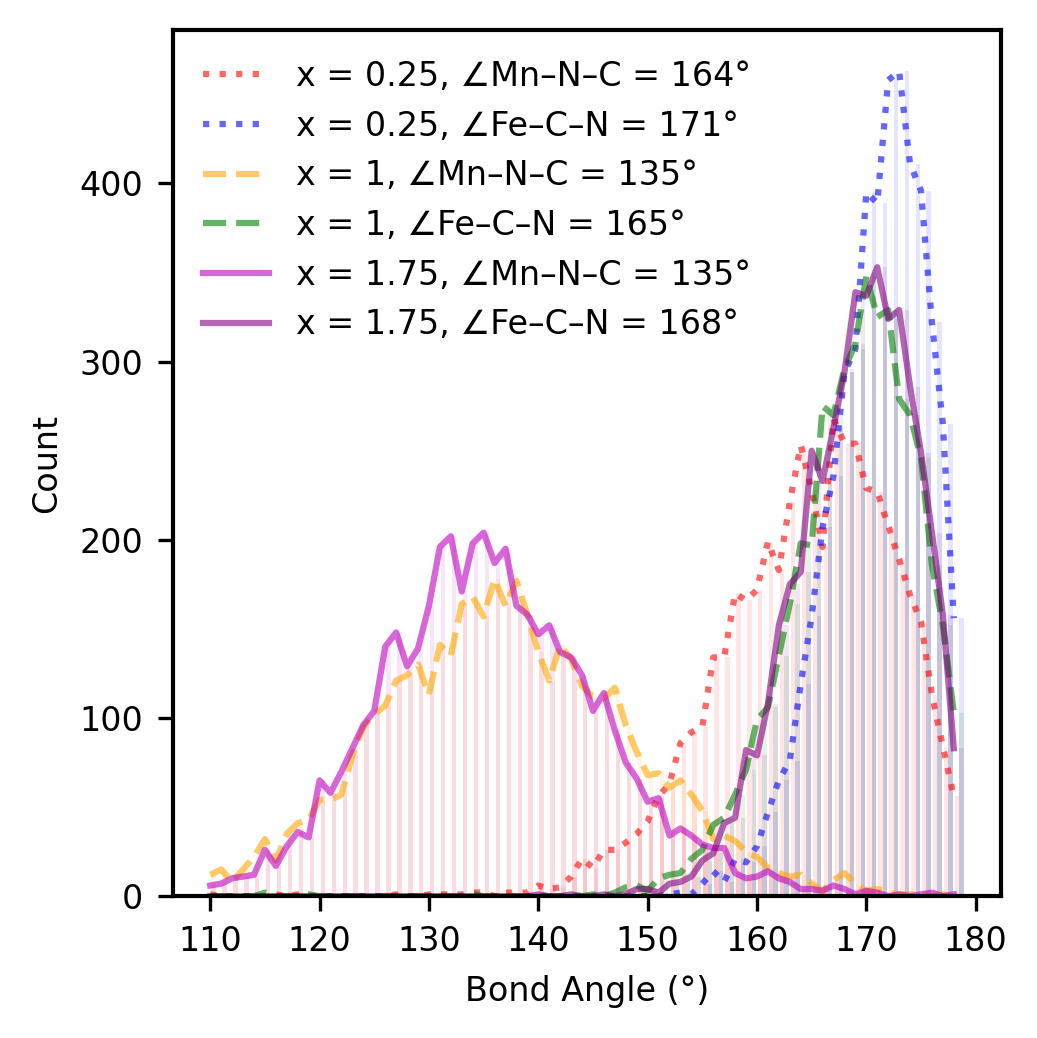

In [17]:
plt.rcParams.update({'font.size': 8})
plt.rcParams.update({'lines.linewidth':1.5})
plt.rcParams.update({'axes.linewidth':1})
plt.rcParams.update({'lines.markersize':5})
plt.rcParams.update({'legend.fontsize': 8})
plt.figure(figsize=(singlecol, singlecol), dpi=300)
bin_edges = range(110, 180, 1)

temp, Na, O = 400, 4, 4
Mn_N_C_angles = np.load(f"./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp.npy")
Fe_C_N_angles = np.load(f'./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Fe_C_N_angles.vasp.npy')

counts, edges, bars = plt.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.1,
    color=['red', 'blue'],
)
plt.plot(edges[:-1],counts[0], ':', color='red', alpha=0.6, label=f'x = 0.25, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°')
plt.plot(edges[:-1],counts[1], ':', color='blue', alpha=0.6, label=f'x = 0.25, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°')

temp, Na, O = 400, 16, 4
Mn_N_C_angles = np.load(f"./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp.npy")
Fe_C_N_angles = np.load(f'./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Fe_C_N_angles.vasp.npy')

counts, edges, bars = plt.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.1,
    color=['orange', 'green'],
)
plt.plot(edges[:-1],counts[0], '--', color='orange', alpha=0.6, label=f'x = 1, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°')
plt.plot(edges[:-1],counts[1], '--', color='green', alpha=0.6, label=f'x = 1, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°')

temp, Na, O = 400, 28, 4
Mn_N_C_angles = np.load(f"./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp.npy")
Fe_C_N_angles = np.load(f'./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Fe_C_N_angles.vasp.npy')

counts, edges, bars = plt.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.1,
    color=['m', 'purple'],
)
plt.plot(edges[:-1],counts[0], '-', color='m', alpha=0.6, label=f'x = 1.75, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°')
plt.plot(edges[:-1],counts[1], '-', color='purple', alpha=0.6, label=f'x = 1.75, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°')


plt.legend(frameon=False)
plt.xlabel('Bond Angle (°)')
#plt.xlim(130,180)
plt.ylabel('Count')
plt.tight_layout()
plt.savefig(f'./hydration/{temp}_bond_angle_O_4.svg')

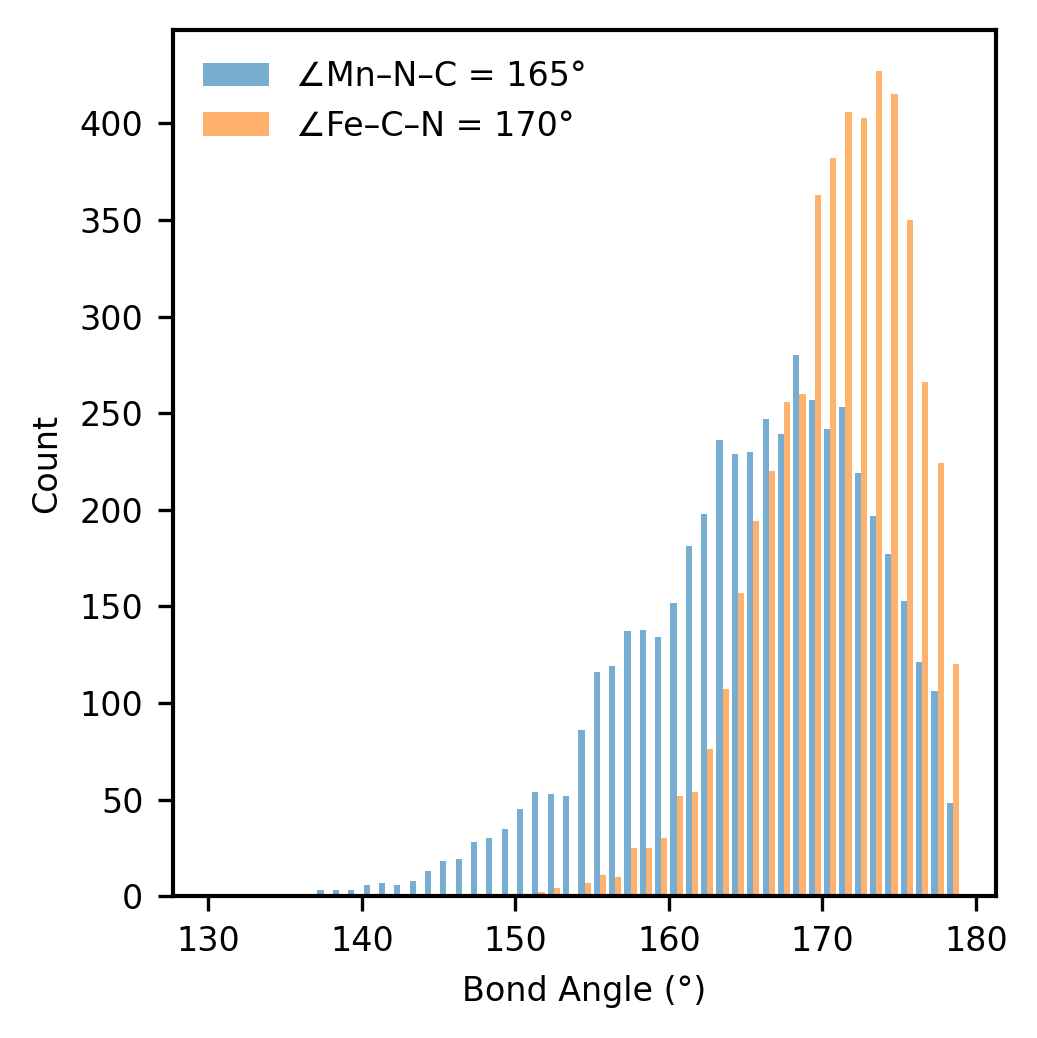

In [17]:
plt.rcParams.update({'font.size': 8})
plt.rcParams.update({'lines.linewidth':0.5})
plt.rcParams.update({'axes.linewidth':1})
plt.rcParams.update({'lines.markersize':5})
plt.rcParams.update({'legend.fontsize': 8})
plt.figure(figsize=(singlecol, singlecol), dpi=300)
bin_edges = range(130, 180, 1)

temp, Na, O = 400, 28, 32
Mn_N_C_angles = np.load(f"./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Mn_N_C_angles.vasp.npy")
Fe_C_N_angles = np.load(f'./hydration/{temp}_diffusion_4/{temp}K_Na_{Na}_O_{O}_Fe_C_N_angles.vasp.npy')

counts, edges, bars = plt.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.6,
    #color=['m', 'purple'],
    label=[f'∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°',f'∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°']
)
#plt.plot(edges[:-1],counts[0], '-', color='m', alpha=0.6, label=f'x = 1.75, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°')
#plt.plot(edges[:-1],counts[1], '-', color='purple', alpha=0.6, label=f'x = 1.75, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°')


plt.legend(frameon=False)
plt.xlabel('Bond Angle (°)')
#plt.xlim(130,180)
plt.ylabel('Count')
plt.tight_layout()
plt.savefig(f'./hydration/bond_angle_Na_28_O_32.svg')

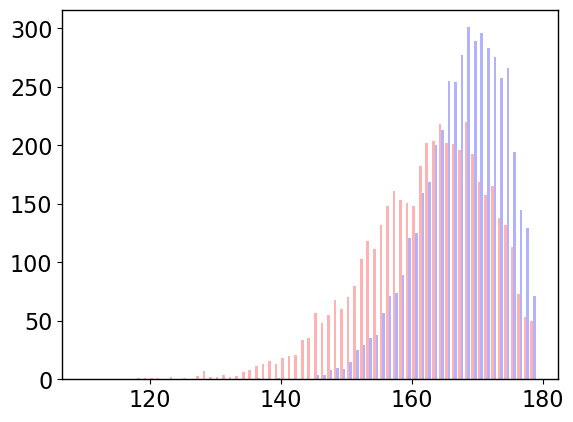

In [56]:
plt.figure()
bin_edges = range(110, 180, 1)
counts, edges, bars = plt.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.3,
    color=['red', 'blue'],
)

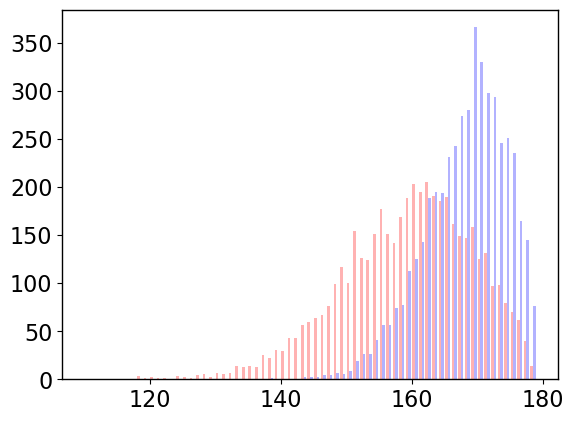

In [54]:
plt.figure()
bin_edges = range(110, 180, 1)
counts, edges, bars = plt.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.3,
    color=['red', 'blue'],
)

✅ Successfully parsed 106 timesteps
📊 Data structure: 100 rows × 11 columns
🔗 Number of atom pairs: 5


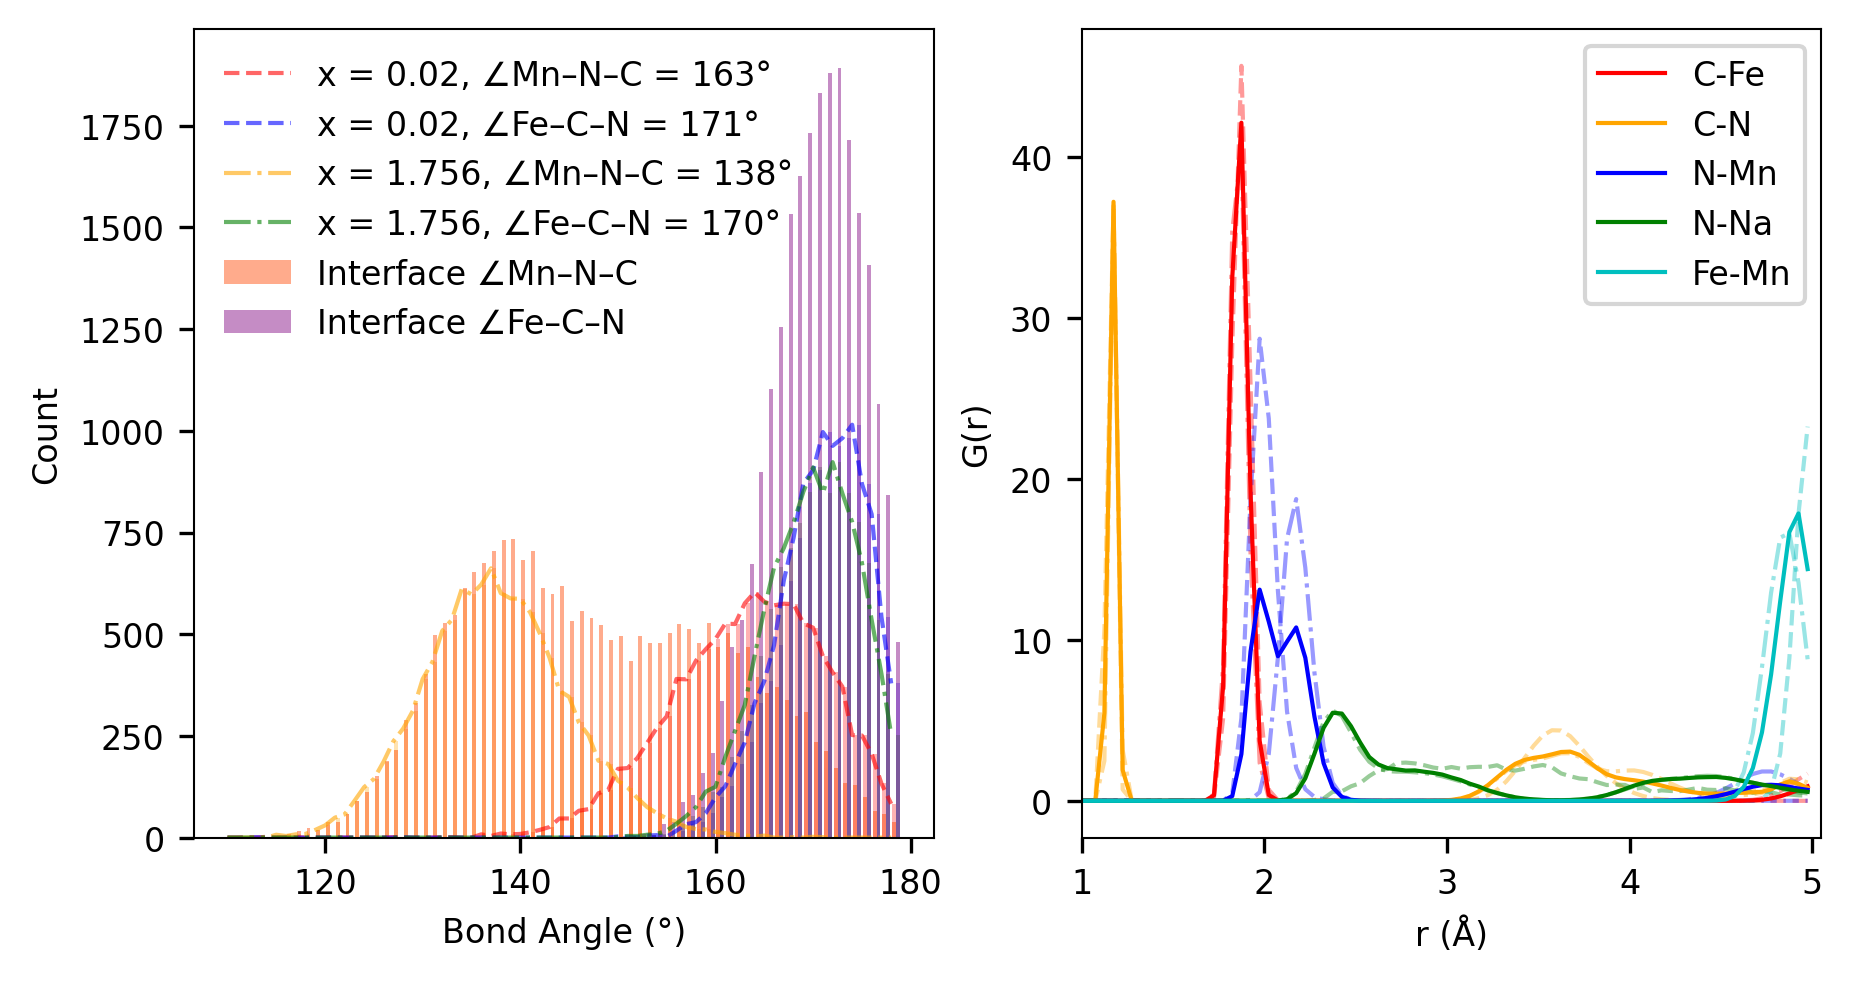

In [123]:
import matplotlib.pyplot as plt
import numpy as np

singlecol = 3.5
plt.rcParams.update({
    'font.size': 8,
    'lines.linewidth': 1,
    'axes.linewidth': 0.5,
    'lines.markersize': 3,
    'savefig.dpi': 300,
    'legend.fontsize': 8
})

# === BOND ANGLE HISTOGRAM ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(singlecol*2, singlecol*1), dpi=300)

bin_edges = range(110, 180, 1)
counts, edges, bars = ax1.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.3,
    color=['red', 'blue'],
)
ax1.plot(edges[:-1],counts[0], '--', color='red', alpha=0.6, label=f'x = 0.02, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°')
ax1.plot(edges[:-1],counts[1], '--', color='blue', alpha=0.6, label=f'x = 0.02, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°')

counts, edges, bars = ax1.hist(
    [Mn_N_C_angles_2, Fe_C_N_angles_2],
    bins=bin_edges,
    alpha=0.3,
    color=['orange', 'green'],
)
ax1.plot(edges[:-1],counts[0], '-.', color='orange', alpha=0.6,label=f'x = 1.756, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles_2))}°')
ax1.plot(edges[:-1],counts[1], '-.', color='green', alpha=0.6, label=f'x = 1.756, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles_2))}°')

counts, edges, bars = ax1.hist(
    [Mn_N_C_angles_interface, Fe_C_N_angles_interface],
    bins=bin_edges,
    alpha=0.45,
    color=['orangered', 'purple'],
    label=[f'Interface ∠Mn–N–C', f'Interface ∠Fe–C–N']
)
#ax1.plot(edges[:-1],counts[0], color='orangered')
#ax1.plot(edges[:-1],counts[1], color='purple')

ax1.set_xlabel('Bond Angle (°)')
ax1.set_ylabel('Count')
ax1.legend(frameon=False)
#ax1.set_title("Bond Angle Distributions")

# === RDF PLOTS ===
pdf = np.loadtxt('300K_rdf_final_3600.rdf', skiprows=4,max_rows=100)
r = pdf[:,1]
for i in range(2, pdf.shape[1],2):
    j = int(i/2)
    ax2.plot(r, pdf[:,i], '-.', color = colors[j-1], alpha=0.4)
    
pdf = np.loadtxt('300K_rdf_final_10.rdf', skiprows=4,max_rows=100)
r = pdf[:,1]
for i in range(2, pdf.shape[1],2):
    j = int(i/2)
    ax2.plot(r, pdf[:,i], '--', color = colors[j-1], alpha=0.4)


RDF = read_rdf_data('../../../interface/300K_rdf_final_interface_2.rdf')
r = RDF[4000][:,0]
t=4000
for i in range(1, 10, 2):
    j = int(i/2)
    ax2.plot(r, RDF[t][:,i], '-', label = name[j], color = colors[j])

ax2.set_xlabel('r (Å)')
ax2.set_ylabel('G(r)')
ax2.set_xlim(1, 5.05)
#ax2.set_title("Radial Distribution Function")
ax2.legend()
#ax2.grid()

# === Final Layout and Save ===
plt.savefig('../../../interface_RDF.png', bbox_inches='tight')  # saves as PNG
plt.savefig('../../../interface_RDF.svg', bbox_inches='tight')  # saves as SVG

✅ Successfully parsed 106 timesteps
📊 Data structure: 100 rows × 11 columns
🔗 Number of atom pairs: 5


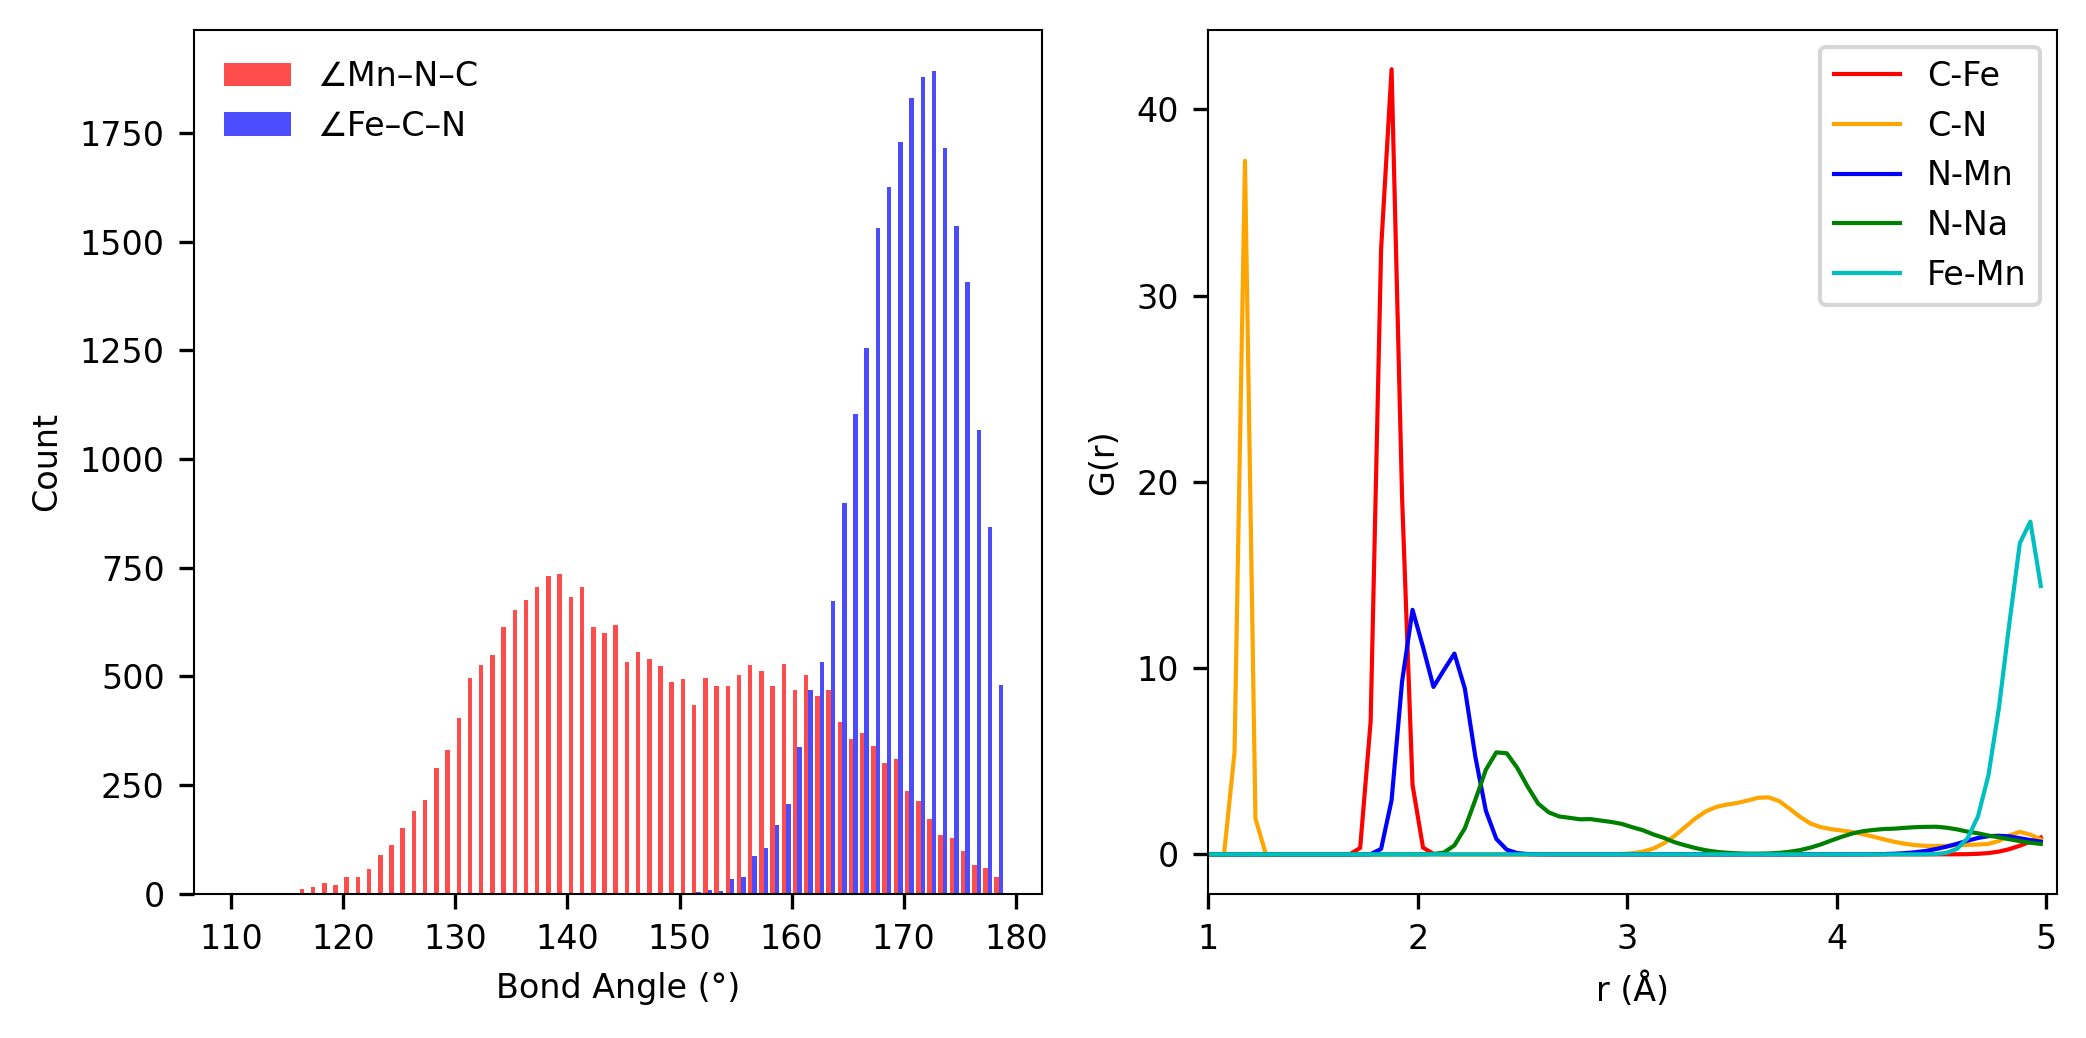

In [81]:
import matplotlib.pyplot as plt
import numpy as np

singlecol = 3.5
plt.rcParams.update({
    'font.size': 8,
    'lines.linewidth': 1,
    'axes.linewidth': 0.5,
    'lines.markersize': 3,
    'savefig.dpi': 300,
    'legend.fontsize': 8
})

# === BOND ANGLE HISTOGRAM ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(singlecol*2, singlecol*1), dpi=300)

bin_edges = range(110, 180, 1)
counts, edges, bars = ax1.hist(
    [Mn_N_C_angles, Fe_C_N_angles],
    bins=bin_edges,
    alpha=0.7,
    color=['red', 'blue'],
    label=[f'∠Mn–N–C', f'∠Fe–C–N']
)
ax1.set_xlabel('Bond Angle (°)')
ax1.set_ylabel('Count')
ax1.legend(frameon=False)
#ax1.set_title("Bond Angle Distributions")

# === RDF PLOTS ===
RDF = read_rdf_data('../../../interface/300K_rdf_final_interface_2.rdf')
r = RDF[4000][:,0]
t=4000
for i in range(1, 10, 2):
    j = int(i/2)
    plt.plot(r, RDF[t][:,i], '-', label = name[j], color = colors[j])

ax2.set_xlabel('r (Å)')
ax2.set_ylabel('G(r)')
ax2.set_xlim(1, 5.05)
#ax2.set_title("Radial Distribution Function")
ax2.legend()
#ax2.grid()

# === Final Layout and Save ===
plt.tight_layout()
plt.savefig('../../../interface_RDF.png', bbox_inches='tight')  # saves as PNG
plt.savefig('../../../interface_RDF.svg', bbox_inches='tight')  # saves as SVG

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

singlecol = 3.5
plt.rcParams.update({
    'font.size': 8,
    'lines.linewidth': 1,
    'axes.linewidth': 0.5,
    'lines.markersize': 3,
    'savefig.dpi': 300,
    'legend.fontsize': 8
})

# === BOND ANGLE HISTOGRAM ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(singlecol*2, singlecol*1), dpi=300)

bin_edges = range(110, 180, 1)
counts, edges, bars = ax1.hist(
    [Mn_N_C_angles, Fe_C_N_angles, Mn_N_C_angles_2, Fe_C_N_angles_2],
    bins=bin_edges,
    alpha=0.7,
    color=['red', 'blue', 'orange', 'green'],
    label=[f'x = 0.02, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles))}°', f'x = 0.02, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles))}°',
           f'x = 1.756, ∠Mn–N–C = {int(np.mean(Mn_N_C_angles_2))}°', f'x = 1.756, ∠Fe–C–N = {int(np.mean(Fe_C_N_angles_2))}°']
)
ax1.set_xlabel('Bond Angle (°)')
ax1.set_ylabel('Count')
ax1.legend(frameon=False)
#ax1.set_title("Bond Angle Distributions")

# === RDF PLOTS ===
pdf = np.loadtxt('300K_rdf_final_3600.rdf', skiprows=4, max_rows=100)
r = pdf[:, 1]
name = ['C–Fe', 'C–N', 'N–Mn', 'N–Na', 'Fe–Mn']
colors = ['r', 'orange', 'blue', 'green', 'c']

for i in range(2, pdf.shape[1], 2):
    j = int(i / 2)
    ax2.plot(r, pdf[:, i], label=name[j - 1], color=colors[j - 1])
for i in range(6, pdf.shape[1], 2):
    j = int(i / 2)
    ax2.text(pdf[:, 1][pdf[:, i].argmax()] - 0.14,
         pdf[:, i].max() + 0.5,
         f'{pdf[:, 1][pdf[:, i].argmax()]:.2f}',
         color=colors[j - 1],
         fontsize=8)

# Overlay dashed RDF from a second file
pdf = np.loadtxt('300K_rdf_final_100.rdf', skiprows=4, max_rows=100)
r = pdf[:, 1]
for i in range(2, pdf.shape[1], 2):
    j = int(i / 2)
    ax2.plot(r, pdf[:, i], '--', color=colors[j - 1])
for i in range(2, pdf.shape[1], 2):
    j = int(i / 2)
    ax2.text(pdf[:, 1][pdf[:, i].argmax()] - 0.14,
         pdf[:, i].max() + 0.5,
         f'{pdf[:, 1][pdf[:, i].argmax()]:.2f}',
         color=colors[j - 1],
         fontsize=8)

ax2.set_xlabel('r (Å)')
ax2.set_ylabel('G(r)')
ax2.set_xlim(1, 5.05)
#ax2.set_title("Radial Distribution Function")
ax2.legend()
#ax2.grid()

# === Final Layout and Save ===
plt.tight_layout()
plt.savefig('bond_RDF.png', bbox_inches='tight')  # saves as PNG
plt.savefig('bond_RDF.svg', bbox_inches='tight')  # saves as SVG

In [ ]:
plt.figure()
i=0
pdf = np.loadtxt('../../../hydration/RDF/300K_rdf_Na_32_O_16.rdf', skiprows=4+101*i, max_rows=100)
r = pdf[:, 1]
name = ['C–Fe', 'C–N', 'N–Mn', 'N–Na', 'Fe–Mn', 'O-Na', 'O-H']
colors = ['r', 'orange', 'blue', 'green', 'c', 'purple', 'm']

for i in range(2, pdf.shape[1]-2, 2):
    j = int(i / 2)
    plt.plot(r, pdf[:, i], label=name[j - 1], color=colors[j - 1])
for i in range(6, pdf.shape[1]-2, 2):
    j = int(i / 2)
    plt.text(pdf[:, 1][pdf[:, i].argmax()] - 0.14,
         pdf[:, i].max() + 0.5,
         f'{pdf[:, 1][pdf[:, i].argmax()]:.2f}',
         color=colors[j - 1],
         fontsize=8)

i=100
pdf = np.loadtxt('../../../hydration/RDF/300K_rdf_Na_32_O_16.rdf', skiprows=4+101*i, max_rows=100)
r = pdf[:, 1]

for i in range(2, pdf.shape[1]-2, 2):
    j = int(i / 2)
    plt.plot(r, pdf[:, i],'--', label=name[j - 1], color=colors[j - 1])
for i in range(6, pdf.shape[1]-2, 2):
    j = int(i / 2)
    plt.text(pdf[:, 1][pdf[:, i].argmax()] - 0.14,
         pdf[:, i].max() + 0.5,
         f'{pdf[:, 1][pdf[:, i].argmax()]:.2f}',
         color=colors[j - 1],
         fontsize=8)
plt.legend()

In [ ]:
for i in range(2, pdf.shape[1], 2):
    print(i)

In [ ]:
np.mean(Mn_N_C_angles)

# CN

Found 139 timestep sections

Timestep 0:
  Number of atoms: 0
  Atoms with coordination data: 0

Timestep 4000:
  Number of atoms: 0
  Atoms with coordination data: 0

Timestep 8000:
  Number of atoms: 0
  Atoms with coordination data: 0

Timestep 12000:
  Number of atoms: 32
  Atoms with coordination data: 32
  Na atoms: 32
  Average coordination: 4.00
  Coordination range: 3 - 5

Timestep 16000:
  Number of atoms: 59
  Atoms with coordination data: 59
  Na atoms: 59
  Average coordination: 4.07
  Coordination range: 4 - 5

Timestep 20000:
  Number of atoms: 89
  Atoms with coordination data: 89
  Na atoms: 89
  Average coordination: 3.97
  Coordination range: 3 - 4

Timestep 24000:
  Number of atoms: 113
  Atoms with coordination data: 113
  Na atoms: 113
  Average coordination: 3.99
  Coordination range: 3 - 5

Timestep 28000:
  Number of atoms: 139
  Atoms with coordination data: 139
  Na atoms: 139
  Average coordination: 3.97
  Coordination range: 2 - 6

Timestep 32000:
  Number 

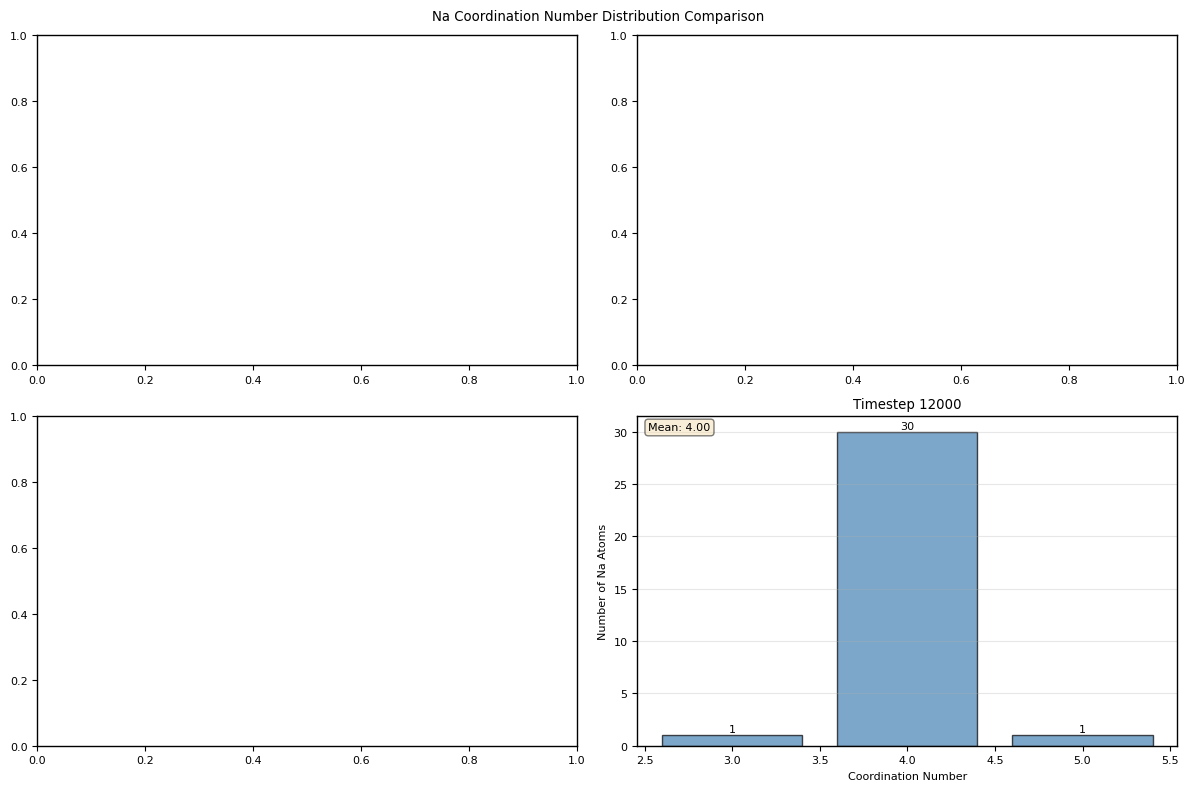

Plotting coordination evolution over time...


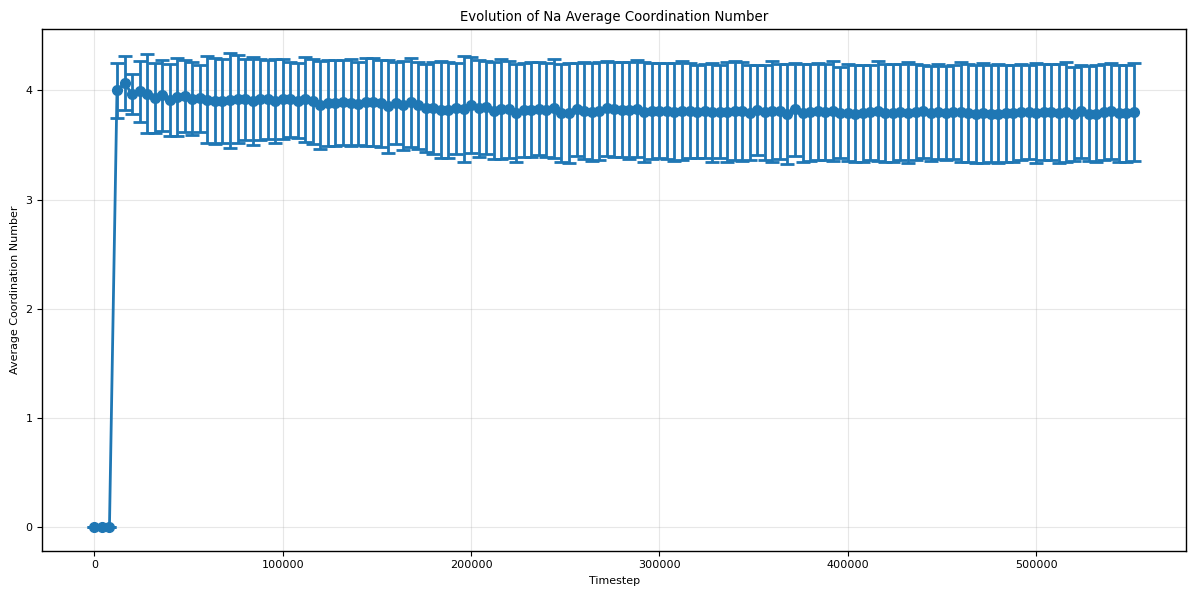

Creating detailed distribution analysis...


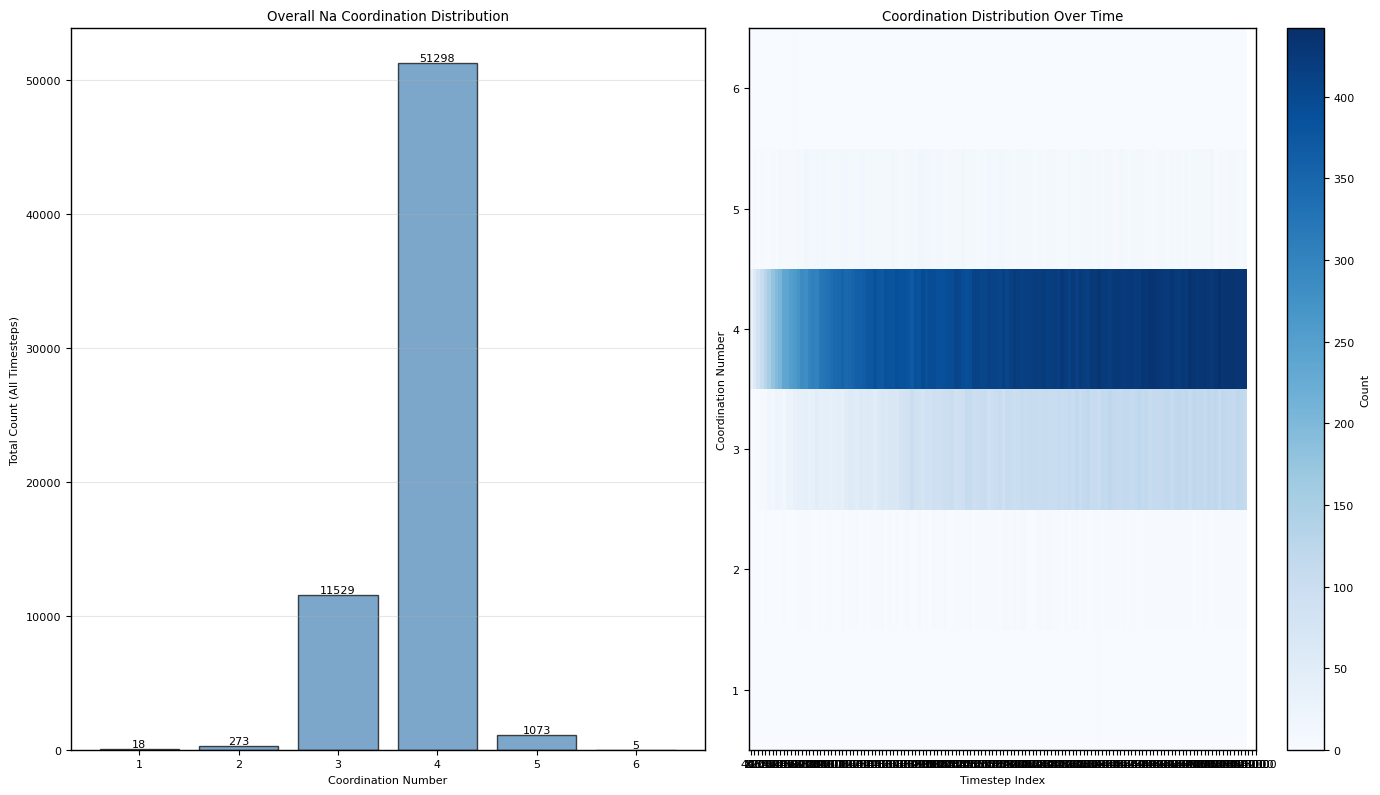


CUSTOM ANALYSIS EXAMPLE
Error processing file: 'type'


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

def parse_coordination_file(filename):
    """
    Parse coordination data file and return a dictionary of sections by timestep.
    
    Parameters:
    filename (str): Path to the coordination data file
    
    Returns:
    dict: Dictionary with timesteps as keys and section data as values
    """
    sections = {}
    
    with open(filename, 'r') as file:
        lines = file.readlines()
    
    i = 0
    while i < len(lines):
        line = lines[i].strip()
        
        # Look for timestep marker
        if line == "ITEM: TIMESTEP":
            i += 1
            timestep = int(lines[i].strip())
            
            # Initialize section data
            section_data = {
                'timestep': timestep,
                'num_atoms': None,
                'box_bounds': None,
                'atoms': []
            }
            
            i += 1
            
            # Parse the rest of the section
            while i < len(lines):
                line = lines[i].strip()
                
                if line == "ITEM: NUMBER OF ATOMS":
                    i += 1
                    section_data['num_atoms'] = int(lines[i].strip())
                    i += 1
                    
                elif line == "ITEM: BOX BOUNDS xy xz yz pp pp pp":
                    i += 1
                    box_bounds = []
                    for _ in range(3):  # Read 3 lines for box bounds
                        box_line = lines[i].strip().split()
                        box_bounds.append([float(x) for x in box_line])
                        i += 1
                    section_data['box_bounds'] = box_bounds
                    
                elif line == "ITEM: ATOMS id type c_NaNcoord":
                    i += 1
                    # Read atom data until next section or end of file
                    while i < len(lines) and not lines[i].strip().startswith("ITEM:"):
                        atom_line = lines[i].strip()
                        if atom_line:  # Skip empty lines
                            parts = atom_line.split()
                            atom_data = {
                                'id': int(parts[0]),
                                'type': int(parts[1]),
                                'coordination': int(parts[2])
                            }
                            section_data['atoms'].append(atom_data)
                        i += 1
                    break  # Exit inner loop to look for next timestep
                else:
                    i += 1
            
            sections[timestep] = section_data
        else:
            i += 1
    
    return sections

def get_coordination_dataframe(section_data):
    """
    Convert atom data from a section into a pandas DataFrame.
    
    Parameters:
    section_data (dict): Section data from parse_coordination_file
    
    Returns:
    pd.DataFrame: DataFrame with atom information
    """
    return pd.DataFrame(section_data['atoms'])

def get_na_coordination_stats(section_data, na_type=5):
    """
    Calculate coordination statistics for Na atoms in a section.
    
    Parameters:
    section_data (dict): Section data from parse_coordination_file
    na_type (int): Atom type number for Na atoms (default: 5)
    
    Returns:
    dict: Statistics dictionary
    """
    na_atoms = [atom for atom in section_data['atoms'] if atom['type'] == na_type]
    
    if not na_atoms:
        return {'count': 0, 'mean': 0, 'std': 0, 'min': 0, 'max': 0}
    
    coords = [atom['coordination'] for atom in na_atoms]
    
    return {
        'count': len(coords),
        'mean': np.mean(coords),
        'std': np.std(coords),
        'min': np.min(coords),
        'max': np.max(coords),
        'coordination_numbers': coords
    }

def plot_coordination_distribution(sections, na_type=5, timesteps=None, figsize=(12, 8)):
    """
    Plot bar chart showing coordination number distribution for Na atoms.
    
    Parameters:
    sections (dict): Parsed sections from parse_coordination_file
    na_type (int): Atom type for Na atoms (default: 5)
    timesteps (list): Specific timesteps to plot (None for all)
    figsize (tuple): Figure size (width, height)
    """
    if timesteps is None:
        timesteps = sorted(sections.keys())
    
    # Single timestep plot
    if len(timesteps) == 1:
        timestep = timesteps[0]
        section = sections[timestep]
        na_atoms = [atom for atom in section['atoms'] if atom['type'] == na_type]
        coords = [atom['coordination'] for atom in na_atoms]
        
        if not coords:
            print(f"No Na atoms found in timestep {timestep}")
            return
        
        # Count occurrences of each coordination number
        coord_counts = Counter(coords)
        coord_numbers = sorted(coord_counts.keys())
        counts = [coord_counts[cn] for cn in coord_numbers]
        
        plt.figure(figsize=figsize)
        bars = plt.bar(coord_numbers, counts, alpha=0.7, color='steelblue', edgecolor='black')
        
        # Add value labels on bars
        for bar, count in zip(bars, counts):
            plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
                    str(count), ha='center', va='bottom')
        
        plt.xlabel('Coordination Number')
        plt.ylabel('Number of Na Atoms')
        plt.title(f'Na Coordination Number Distribution (Timestep {timestep})')
        plt.grid(axis='y', alpha=0.3)
        
        # Add statistics text
        mean_coord = np.mean(coords)
        plt.text(0.02, 0.98, f'Total Na atoms: {len(coords)}\nMean coordination: {mean_coord:.2f}', 
                transform=plt.gca().transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        
        plt.tight_layout()
        plt.show()
    
    # Multiple timesteps comparison
    else:
        fig, axes = plt.subplots(2, 2, figsize=figsize)
        axes = axes.flatten() if len(timesteps) > 1 else [axes]
        
        for i, timestep in enumerate(timesteps[:4]):  # Limit to 4 subplots
            section = sections[timestep]
            na_atoms = [atom for atom in section['atoms'] if atom['type'] == na_type]
            coords = [atom['coordination'] for atom in na_atoms]
            
            if not coords:
                continue
            
            coord_counts = Counter(coords)
            coord_numbers = sorted(coord_counts.keys())
            counts = [coord_counts[cn] for cn in coord_numbers]
            
            ax = axes[i] if i < len(axes) else plt.gca()
            bars = ax.bar(coord_numbers, counts, alpha=0.7, color='steelblue', edgecolor='black')
            
            # Add value labels on bars
            for bar, count in zip(bars, counts):
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
                       str(count), ha='center', va='bottom', fontsize=8)
            
            ax.set_xlabel('Coordination Number')
            ax.set_ylabel('Number of Na Atoms')
            ax.set_title(f'Timestep {timestep}')
            ax.grid(axis='y', alpha=0.3)
            
            # Add mean coordination
            mean_coord = np.mean(coords)
            ax.text(0.02, 0.98, f'Mean: {mean_coord:.2f}', 
                   transform=ax.transAxes, verticalalignment='top',
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        
        # Hide unused subplots
        for j in range(len(timesteps), len(axes)):
            axes[j].set_visible(False)
        
        plt.suptitle('Na Coordination Number Distribution Comparison')
        plt.tight_layout()
        plt.show()

def plot_coordination_evolution(sections, na_type=5, figsize=(12, 6)):
    """
    Plot how average coordination number changes over timesteps.
    
    Parameters:
    sections (dict): Parsed sections from parse_coordination_file
    na_type (int): Atom type for Na atoms (default: 5)
    figsize (tuple): Figure size (width, height)
    """
    timesteps = sorted(sections.keys())
    mean_coords = []
    std_coords = []
    
    for timestep in timesteps:
        section = sections[timestep]
        na_atoms = [atom for atom in section['atoms'] if atom['type'] == na_type]
        coords = [atom['coordination'] for atom in na_atoms]
        
        if coords:
            mean_coords.append(np.mean(coords))
            std_coords.append(np.std(coords))
        else:
            mean_coords.append(0)
            std_coords.append(0)
    
    plt.figure(figsize=figsize)
    plt.errorbar(timesteps, mean_coords, yerr=std_coords, 
                marker='o', capsize=5, capthick=2, linewidth=2)
    plt.xlabel('Timestep')
    plt.ylabel('Average Coordination Number')
    plt.title('Evolution of Na Average Coordination Number')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def plot_detailed_distribution(sections, na_type=5, figsize=(14, 8)):
    """
    Create a comprehensive visualization showing distribution across all timesteps.
    
    Parameters:
    sections (dict): Parsed sections from parse_coordination_file
    na_type (int): Atom type for Na atoms (default: 5)
    figsize (tuple): Figure size (width, height)
    """
    timesteps = sorted(sections.keys())
    
    # Collect all coordination data
    all_data = []
    for timestep in timesteps:
        section = sections[timestep]
        na_atoms = [atom for atom in section['atoms'] if atom['type'] == na_type]
        coords = [atom['coordination'] for atom in na_atoms]
        
        for coord in coords:
            all_data.append({'timestep': timestep, 'coordination': coord})
    
    if not all_data:
        print("No Na coordination data found")
        return
    
    df = pd.DataFrame(all_data)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
    
    # Overall distribution
    coord_counts = Counter(df['coordination'])
    coord_numbers = sorted(coord_counts.keys())
    counts = [coord_counts[cn] for cn in coord_numbers]
    
    bars = ax1.bar(coord_numbers, counts, alpha=0.7, color='steelblue', edgecolor='black')
    for bar, count in zip(bars, counts):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                str(count), ha='center', va='bottom')
    
    ax1.set_xlabel('Coordination Number')
    ax1.set_ylabel('Total Count (All Timesteps)')
    ax1.set_title('Overall Na Coordination Distribution')
    ax1.grid(axis='y', alpha=0.3)
    
    # Heatmap showing distribution over time
    pivot_data = df.groupby(['timestep', 'coordination']).size().unstack(fill_value=0)
    im = ax2.imshow(pivot_data.T, aspect='auto', cmap='Blues', origin='lower')
    
    ax2.set_xlabel('Timestep Index')
    ax2.set_ylabel('Coordination Number')
    ax2.set_title('Coordination Distribution Over Time')
    
    # Set tick labels
    ax2.set_xticks(range(len(timesteps)))
    ax2.set_xticklabels([str(ts) for ts in timesteps])
    ax2.set_yticks(range(len(pivot_data.columns)))
    ax2.set_yticklabels(pivot_data.columns)
    
    # Add colorbar
    plt.colorbar(im, ax=ax2, label='Count')
    
    plt.tight_layout()
    plt.show()

# Example usage with your specific filename
if __name__ == "__main__":
    # Use your actual filename
    filename = './hydration/RDF/300K_NaN_coord_32_32.txt'#'300K_NaN_coord_10.txt'
    
    try:
        # Parse the file
        sections = parse_coordination_file(filename)
        
        print(f"Found {len(sections)} timestep sections")
        
        # Example: Process each section
        for timestep, section in sections.items():
            print(f"\nTimestep {timestep}:")
            print(f"  Number of atoms: {section['num_atoms']}")
            print(f"  Atoms with coordination data: {len(section['atoms'])}")
            
            # Get Na coordination statistics
            na_stats = get_na_coordination_stats(section)
            if na_stats['count'] > 0:
                print(f"  Na atoms: {na_stats['count']}")
                print(f"  Average coordination: {na_stats['mean']:.2f}")
                print(f"  Coordination range: {na_stats['min']} - {na_stats['max']}")
        
        # PLOTTING EXAMPLES:
        
        # 1. Plot distribution for a single timestep
        print("\n" + "="*50)
        print("PLOTTING COORDINATION DISTRIBUTIONS")
        print("="*50)
        
        available_timesteps = sorted(sections.keys())
        if available_timesteps:
            first_timestep = available_timesteps[0]
            print(f"Plotting distribution for timestep {first_timestep}...")
            plot_coordination_distribution(sections, timesteps=[first_timestep])
        
        # 2. Compare multiple timesteps (up to 4)
        if len(available_timesteps) > 1:
            timesteps_to_compare = available_timesteps[:4]
            print(f"Comparing timesteps: {timesteps_to_compare}")
            plot_coordination_distribution(sections, timesteps=timesteps_to_compare)
        
        # 3. Show evolution over time
        if len(sections) > 1:
            print("Plotting coordination evolution over time...")
            plot_coordination_evolution(sections)
        
        # 4. Comprehensive distribution analysis
        print("Creating detailed distribution analysis...")
        plot_detailed_distribution(sections)
        
        # 5. Custom analysis example
        print("\n" + "="*50)
        print("CUSTOM ANALYSIS EXAMPLE")
        print("="*50)
        
        # Get coordination data for first available timestep
        if available_timesteps:
            first_timestep = available_timesteps[0]
            first_section = sections[first_timestep]
            df = get_coordination_dataframe(first_section)
            na_df = df[df['type'] == 5]  # Filter Na atoms
            
            #if not na_df.empty:
            #    print(f"Na coordination numbers in timestep {first_timestep}: {sorted(na_df['coordination'].tolist())}")
            #    print(f"Coordination value counts:")
            #    print(na_df['coordination'].value_counts().sort_index())
            
    except FileNotFoundError:
        print(f"File '{filename}' not found. Please check the filename and path.")
    except Exception as e:
        print(f"Error processing file: {e}")

In [3]:
def plot_detailed_distribution(sections, na_type=5, figsize=(14, 8)):

    timesteps = sorted(sections.keys())
    
    # Collect all coordination data
    all_data = []
    for timestep in timesteps:
        section = sections[timestep]
        na_atoms = [atom for atom in section['atoms'] if atom['type'] == na_type]
        coords = [atom['coordination'] for atom in na_atoms]
        
        for coord in coords:
            all_data.append({'timestep': timestep, 'coordination': coord})
    
    if not all_data:
        print("No Na coordination data found")
        return
    
    df = pd.DataFrame(all_data)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
    
    # Overall distribution
    coord_counts = Counter(df['coordination'])
    coord_numbers = sorted(coord_counts.keys())
    counts = [coord_counts[cn] for cn in coord_numbers]
    
    bars = ax1.bar(coord_numbers, counts, alpha=0.7, color='steelblue', edgecolor='black')
    for bar, count in zip(bars, counts):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                str(count), ha='center', va='bottom')
    
    ax1.set_xlabel('Coordination Number')
    ax1.set_ylabel('Total Count (All Timesteps)')
    ax1.set_title('Overall Na Coordination Distribution')
    ax1.grid(axis='y', alpha=0.3)
    
    # Heatmap showing distribution over time
    pivot_data = df.groupby(['timestep', 'coordination']).size().unstack(fill_value=0)
    im = ax2.imshow(pivot_data.T, aspect='auto', cmap='Blues', origin='lower')
    
    ax2.set_xlabel('Timestep Index')
    ax2.set_ylabel('Coordination Number')
    ax2.set_title('Coordination Distribution Over Time')
    
    # Set tick labels
    ax2.set_xticks(range(len(timesteps)))
    ax2.set_xticklabels([str(ts) for ts in timesteps])
    ax2.set_yticks(range(len(pivot_data.columns)))
    ax2.set_yticklabels(pivot_data.columns)
    
    # Add colorbar
    plt.colorbar(im, ax=ax2, label='Count')
    
    plt.tight_layout()
    plt.show()

# CN Analysis

In [3]:
# LAMMPS Trajectory Coordination Number Analysis - Jupyter Notebook Version
# Analyzes coordination number of type 5 atoms with type 4 atoms

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
import pandas as pd
from IPython.display import display, HTML
import warnings
warnings.filterwarnings('ignore')

# Set matplotlib style for better plots
plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10

class LAMMPSTrajectoryAnalyzer:
    def __init__(self, trajectory_file, cutoff_distance=3.0):
        """
        Initialize the analyzer
        
        Parameters:
        trajectory_file (str): Path to LAMMPS trajectory file
        cutoff_distance (float): Distance cutoff for coordination bonds (Angstroms)
        """
        self.trajectory_file = trajectory_file
        self.cutoff_distance = cutoff_distance
        self.frames = []
        self.results_df = None
        
    def read_trajectory(self):
        """Read LAMMPS trajectory file"""
        print(f"📁 Reading trajectory file: {self.trajectory_file}")
        
        current_frame = {}
        reading_atoms = False
        atom_count = 0
        expected_atoms = 0
        
        try:
            with open(self.trajectory_file, 'r') as f:
                lines = f.readlines()
                
            i = 0
            while i < len(lines):
                line = lines[i].strip()
                
                if line == "ITEM: TIMESTEP":
                    if current_frame and 'atoms' in current_frame:
                        self.frames.append(current_frame)
                    current_frame = {'atoms': []}
                    i += 1
                    current_frame['timestep'] = int(lines[i].strip())
                    
                elif line == "ITEM: NUMBER OF ATOMS":
                    i += 1
                    expected_atoms = int(lines[i].strip())
                    current_frame['natoms'] = expected_atoms
                    
                elif line.startswith("ITEM: BOX BOUNDS"):
                    current_frame['box'] = []
                    for j in range(3):
                        i += 1
                        bounds = list(map(float, lines[i].strip().split()))
                        current_frame['box'].append(bounds)
                        
                elif line.startswith("ITEM: ATOMS"):
                    # Parse header to understand column order
                    columns = line.split()[2:]  # Skip "ITEM:" and "ATOMS"
                    current_frame['columns'] = columns
                    reading_atoms = True
                    atom_count = 0
                    
                elif reading_atoms and atom_count < expected_atoms:
                    atom_data = list(map(float, lines[i].strip().split()))
                    current_frame['atoms'].append(atom_data)
                    atom_count += 1
                    
                    if atom_count == expected_atoms:
                        reading_atoms = False
                        
                i += 1
                
            # Don't forget the last frame
            if current_frame and 'atoms' in current_frame:
                self.frames.append(current_frame)
                
        except FileNotFoundError:
            print(f"❌ Error: Could not find file {self.trajectory_file}")
            return False
        except Exception as e:
            print(f"❌ Error reading trajectory file: {e}")
            return False
            
        print(f"✅ Successfully read {len(self.frames)} frames")
        if self.frames:
            print(f"   First frame has {len(self.frames[0]['atoms'])} atoms")
            print(f"   Columns: {self.frames[0]['columns']}")
        return True
    
    def extract_atom_data(self, frame):
        """Extract positions and types for atoms in a frame"""
        columns = frame['columns']
        atoms = np.array(frame['atoms'])
        
        # Find column indices
        try:
            type_col = columns.index('type')
            x_col = columns.index('x')
            y_col = columns.index('y')
            z_col = columns.index('z')
        except ValueError as e:
            print(f"❌ Error: Required column not found. Available columns: {columns}")
            print("   Make sure your trajectory includes 'type', 'x', 'y', 'z' columns")
            return None, None
        
        atom_types = atoms[:, type_col].astype(int)
        positions = atoms[:, [x_col, y_col, z_col]]
        
        return atom_types, positions
    
    def calculate_coordination_numbers(self, frame):
        """Calculate coordination numbers for type 5 atoms with type 4 atoms"""
        atom_types, positions = self.extract_atom_data(frame)
        
        if atom_types is None:
            return np.array([])
##########################################################################       
        # Find indices of type 4 and type 5 atoms
        type4_indices = np.where(atom_types == 5)[0] # The shell
        type5_indices = np.where(atom_types == 6)[0] # The center
##########################################################################         
        if len(type4_indices) == 0:
            print("⚠️  Warning: No type 4 atoms found in frame")
            return np.array([])
        
        if len(type5_indices) == 0:
            print("⚠️  Warning: No type 5 atoms found in frame")
            return np.array([])
        
        # Get positions
        type4_positions = positions[type4_indices]
        type5_positions = positions[type5_indices]
        
        # Calculate distances between type 5 and type 4 atoms
        distances = cdist(type5_positions, type4_positions)
        
        # Count neighbors within cutoff distance
        coordination_numbers = np.sum(distances <= self.cutoff_distance, axis=1)
        
        return coordination_numbers
    
    def analyze_trajectory(self):
        """Analyze coordination numbers across all frames"""
        if not self.frames:
            print("❌ No frames loaded. Please read trajectory first.")
            return None, None
        
        print(f"\n🔍 Analyzing coordination numbers with cutoff distance: {self.cutoff_distance} Å")
        
        all_coordination_numbers = []
        frame_data = []
        
        for i, frame in enumerate(self.frames):
            coord_nums = self.calculate_coordination_numbers(frame)
            
            if len(coord_nums) > 0:
                all_coordination_numbers.extend(coord_nums)
                frame_avg = np.mean(coord_nums)
                frame_std = np.std(coord_nums)
                
                frame_data.append({
                    'Frame': i + 1,
                    'Timestep': frame['timestep'],
                    'Type5_Count': len(coord_nums),
                    'Avg_Coordination': frame_avg,
                    'Std_Coordination': frame_std,
                    'Min_Coordination': np.min(coord_nums),
                    'Max_Coordination': np.max(coord_nums)
                })
                
                if i < 10 or i % max(1, len(self.frames) // 10) == 0:  # Show progress
                    print(f"   Frame {i+1:3d} (timestep {frame['timestep']:8d}): "
                          f"{len(coord_nums):3d} type-5 atoms, "
                          f"avg coordination: {frame_avg:.2f}")
            else:
                frame_data.append({
                    'Frame': i + 1,
                    'Timestep': frame['timestep'],
                    'Type5_Count': 0,
                    'Avg_Coordination': 0,
                    'Std_Coordination': 0,
                    'Min_Coordination': 0,
                    'Max_Coordination': 0
                })
        
        # Create results DataFrame
        self.results_df = pd.DataFrame(frame_data)
        
        if all_coordination_numbers:
            all_coordination_numbers = np.array(all_coordination_numbers)
            
            print(f"\n📊 COORDINATION NUMBER ANALYSIS SUMMARY")
            print("=" * 50)
            print(f"Total type-5 atoms analyzed: {len(all_coordination_numbers):,}")
            print(f"Average coordination number: {np.mean(all_coordination_numbers):.3f}")
            print(f"Standard deviation: {np.std(all_coordination_numbers):.3f}")
            print(f"Min coordination number: {np.min(all_coordination_numbers)}")
            print(f"Max coordination number: {np.max(all_coordination_numbers)}")
            
            # Distribution
            unique, counts = np.unique(all_coordination_numbers, return_counts=True)
            print(f"\n📈 Coordination number distribution:")
            for coord_num, count in zip(unique, counts):
                percentage = (count / len(all_coordination_numbers)) * 100
                bar = "█" * int(percentage / 2)  # Simple bar chart
                print(f"   CN = {coord_num}: {count:5,} atoms ({percentage:5.1f}%) {bar}")
        
        return all_coordination_numbers, self.results_df
    
    def plot_results(self, all_coordination_numbers, results_df):
        """Plot coordination number analysis results"""
        if len(all_coordination_numbers) == 0:
            print("❌ No data to plot")
            return
        
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        fig.suptitle(f'Coordination Number Analysis (Type 5-4 bonds, cutoff = {self.cutoff_distance} Å)', 
                     fontsize=16, fontweight='bold')
        
        # 1. Histogram of coordination numbers
        ax1 = axes[0, 0]
        bins = range(int(np.min(all_coordination_numbers)), int(np.max(all_coordination_numbers)) + 2)
        n, bins_edges, patches = ax1.hist(all_coordination_numbers, bins=bins, alpha=0.7, 
                                         edgecolor='black', color='skyblue')
        
        # Color bars by coordination number
        for i, (patch, coord_num) in enumerate(zip(patches, bins_edges[:-1])):
            if coord_num <= 2:
                patch.set_facecolor('lightcoral')
            elif coord_num <= 4:
                patch.set_facecolor('lightblue')
            else:
                patch.set_facecolor('lightgreen')
        
        ax1.set_xlabel('Coordination Number')
        ax1.set_ylabel('Frequency')
        ax1.set_title('Distribution of Coordination Numbers')
        ax1.grid(True, alpha=0.3)
        
        # Add statistics text
        mean_coord = np.mean(all_coordination_numbers)
        ax1.axvline(mean_coord, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_coord:.2f}')
        ax1.legend()
        
        # 2. Time evolution of average coordination number
        ax2 = axes[0, 1]
        valid_data = results_df[results_df['Type5_Count'] > 0]
        if len(valid_data) > 0:
            ax2.plot(valid_data['Timestep'], valid_data['Avg_Coordination'], 'b-o', 
                    markersize=3, linewidth=1, alpha=0.8)
            ax2.fill_between(valid_data['Timestep'], 
                           valid_data['Avg_Coordination'] - valid_data['Std_Coordination'],
                           valid_data['Avg_Coordination'] + valid_data['Std_Coordination'],
                           alpha=0.2, color='blue')
        
        ax2.set_xlabel('Timestep')
        ax2.set_ylabel('Average Coordination Number')
        ax2.set_title('Time Evolution (±1 std)')
        ax2.grid(True, alpha=0.3)
        
        # 3. Coordination number statistics by frame (if reasonable number of frames)
        ax3 = axes[1, 0]
        if len(self.frames) <= 20:
            coord_by_frame = []
            frame_labels = []
            for i, frame in enumerate(self.frames):
                coord_nums = self.calculate_coordination_numbers(frame)
                if len(coord_nums) > 0:
                    coord_by_frame.append(coord_nums)
                    frame_labels.append(f"F{i+1}")
            
            if coord_by_frame:
                bp = ax3.boxplot(coord_by_frame, labels=frame_labels, patch_artist=True)
                for patch in bp['boxes']:
                    patch.set_facecolor('lightcyan')
                ax3.set_xlabel('Frame')
                ax3.set_ylabel('Coordination Number')
                ax3.set_title('Distribution by Frame')
                ax3.grid(True, alpha=0.3)
        else:
            # Show frame-to-frame variation
            valid_frames = results_df[results_df['Type5_Count'] > 0]
            ax3.scatter(valid_frames['Frame'], valid_frames['Avg_Coordination'], 
                       alpha=0.6, s=30, c='blue')
            ax3.set_xlabel('Frame Number')
            ax3.set_ylabel('Average Coordination Number')
            ax3.set_title(f'Frame-to-Frame Variation ({len(self.frames)} frames)')
            ax3.grid(True, alpha=0.3)
        
        # 4. Cumulative distribution
        ax4 = axes[1, 1]
        sorted_coords = np.sort(all_coordination_numbers)
        cumulative = np.arange(1, len(sorted_coords) + 1) / len(sorted_coords)
        ax4.plot(sorted_coords, cumulative, 'g-', linewidth=2, alpha=0.8)
        ax4.fill_between(sorted_coords, cumulative, alpha=0.3, color='green')
        
        # Add percentile lines
        percentiles = [25, 50, 75]
        for p in percentiles:
            val = np.percentile(all_coordination_numbers, p)
            ax4.axvline(val, color='red', linestyle=':', alpha=0.7)
            ax4.text(val, p/100, f' {p}th: {val:.1f}', rotation=0, va='bottom')
        
        ax4.set_xlabel('Coordination Number')
        ax4.set_ylabel('Cumulative Probability')
        ax4.set_title('Cumulative Distribution')
        ax4.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
        
        print(f"📈 Plots generated successfully!")
    
    def get_summary_table(self):
        """Return a summary table of results"""
        if self.results_df is None:
            return None
        
        # Create summary statistics
        valid_frames = self.results_df[self.results_df['Type5_Count'] > 0]
        
        summary = {
            'Metric': [
                'Total Frames',
                'Frames with Type-5 atoms',
                'Average Type-5 atoms per frame',
                'Average Coordination Number',
                'Standard Deviation',
                'Minimum Coordination',
                'Maximum Coordination',
                'Most Common Coordination'
            ],
            'Value': [
                len(self.results_df),
                len(valid_frames),
                f"{valid_frames['Type5_Count'].mean():.1f}" if len(valid_frames) > 0 else "N/A",
                f"{valid_frames['Avg_Coordination'].mean():.3f}" if len(valid_frames) > 0 else "N/A",
                f"{valid_frames['Avg_Coordination'].std():.3f}" if len(valid_frames) > 0 else "N/A",
                f"{valid_frames['Min_Coordination'].min():.0f}" if len(valid_frames) > 0 else "N/A",
                f"{valid_frames['Max_Coordination'].max():.0f}" if len(valid_frames) > 0 else "N/A",
                "Calculate separately"  # Would need all coordination numbers
            ]
        }
        
        return pd.DataFrame(summary)

# Convenience functions for Jupyter notebook
def analyze_coordination(trajectory_file, cutoff_distance=3.0, show_frame_details=False):
    """
    Main function to run coordination analysis
    
    Parameters:
    trajectory_file (str): Path to LAMMPS trajectory file
    cutoff_distance (float): Distance cutoff for coordination bonds
    show_frame_details (bool): Whether to show detailed frame-by-frame results
    
    Returns:
    analyzer: LAMMPSTrajectoryAnalyzer object with results
    """
    
    print("🚀 Starting LAMMPS Coordination Number Analysis")
    print("=" * 60)
    
    # Initialize analyzer
    analyzer = LAMMPSTrajectoryAnalyzer(trajectory_file, cutoff_distance)
    
    # Read trajectory
    if not analyzer.read_trajectory():
        return None
    
    # Analyze coordination numbers
    all_coords, results_df = analyzer.analyze_trajectory()
    
    if all_coords is None or len(all_coords) == 0:
        print("❌ No coordination data found!")
        return analyzer
    
    # Show summary table
    summary_df = analyzer.get_summary_table()
    if summary_df is not None:
        print("\n📋 SUMMARY TABLE")
        print("=" * 30)
        display(summary_df)
    
    # Show frame details if requested
    if show_frame_details and results_df is not None:
        print("\n📊 FRAME-BY-FRAME RESULTS")
        print("=" * 30)
        display(results_df.head(10))  # Show first 10 frames
        if len(results_df) > 10:
            print(f"... and {len(results_df) - 10} more frames")
    
    # Generate plots
    print("\n📈 Generating plots...")
    analyzer.plot_results(all_coords, results_df)
    
    return analyzer

# Example usage (uncomment and modify as needed):
"""
# Basic usage
analyzer = analyze_coordination('your_trajectory.trj', cutoff_distance=3.0)

# With detailed frame information
analyzer = analyze_coordination('your_trajectory.trj', cutoff_distance=2.5, show_frame_details=True)

# Access results
if analyzer:
    print("Results available in analyzer.results_df")
    # analyzer.results_df  # DataFrame with frame-by-frame results
"""

print("🎯 LAMMPS Coordination Analysis loaded!")
print("📝 Usage: analyzer = analyze_coordination('your_file.trj', cutoff_distance=3.0)")
print("🔧 Optional: show_frame_details=True for detailed output")

🎯 LAMMPS Coordination Analysis loaded!
📝 Usage: analyzer = analyze_coordination('your_file.trj', cutoff_distance=3.0)
🔧 Optional: show_frame_details=True for detailed output


In [8]:
all_coordination_numbers

NameError: name 'all_coordination_numbers' is not defined

🚀 Starting LAMMPS Coordination Number Analysis
📁 Reading trajectory file: ./hydration/400_diffusion_vac_lv20_r02_65_2/400K_10.dump
✅ Successfully read 1 frames
   First frame has 5192 atoms
   Columns: ['id', 'type', 'x', 'y', 'z']

🔍 Analyzing coordination numbers with cutoff distance: 3 Å
   Frame   1 (timestep    22000): 520 type-5 atoms, avg coordination: 0.74

📊 COORDINATION NUMBER ANALYSIS SUMMARY
Total type-5 atoms analyzed: 520
Average coordination number: 0.737
Standard deviation: 0.655
Min coordination number: 0
Max coordination number: 2

📈 Coordination number distribution:
   CN = 0:   198 atoms ( 38.1%) ███████████████████
   CN = 1:   261 atoms ( 50.2%) █████████████████████████
   CN = 2:    61 atoms ( 11.7%) █████

📋 SUMMARY TABLE


,Metric,Value
0,Total Frames,1
1,Frames with Type-5 atoms,1
2,Average Type-5 atoms per frame,520.0
3,Average Coordination Number,0.737
4,Standard Deviation,nan
5,Minimum Coordination,0
6,Maximum Coordination,2
7,Most Common Coordination,Calculate separately



📊 FRAME-BY-FRAME RESULTS


,Frame,Timestep,Type5_Count,Avg_Coordination,Std_Coordination,Min_Coordination,Max_Coordination
0,1,22000,520,0.736538,0.654725,0,2



📈 Generating plots...


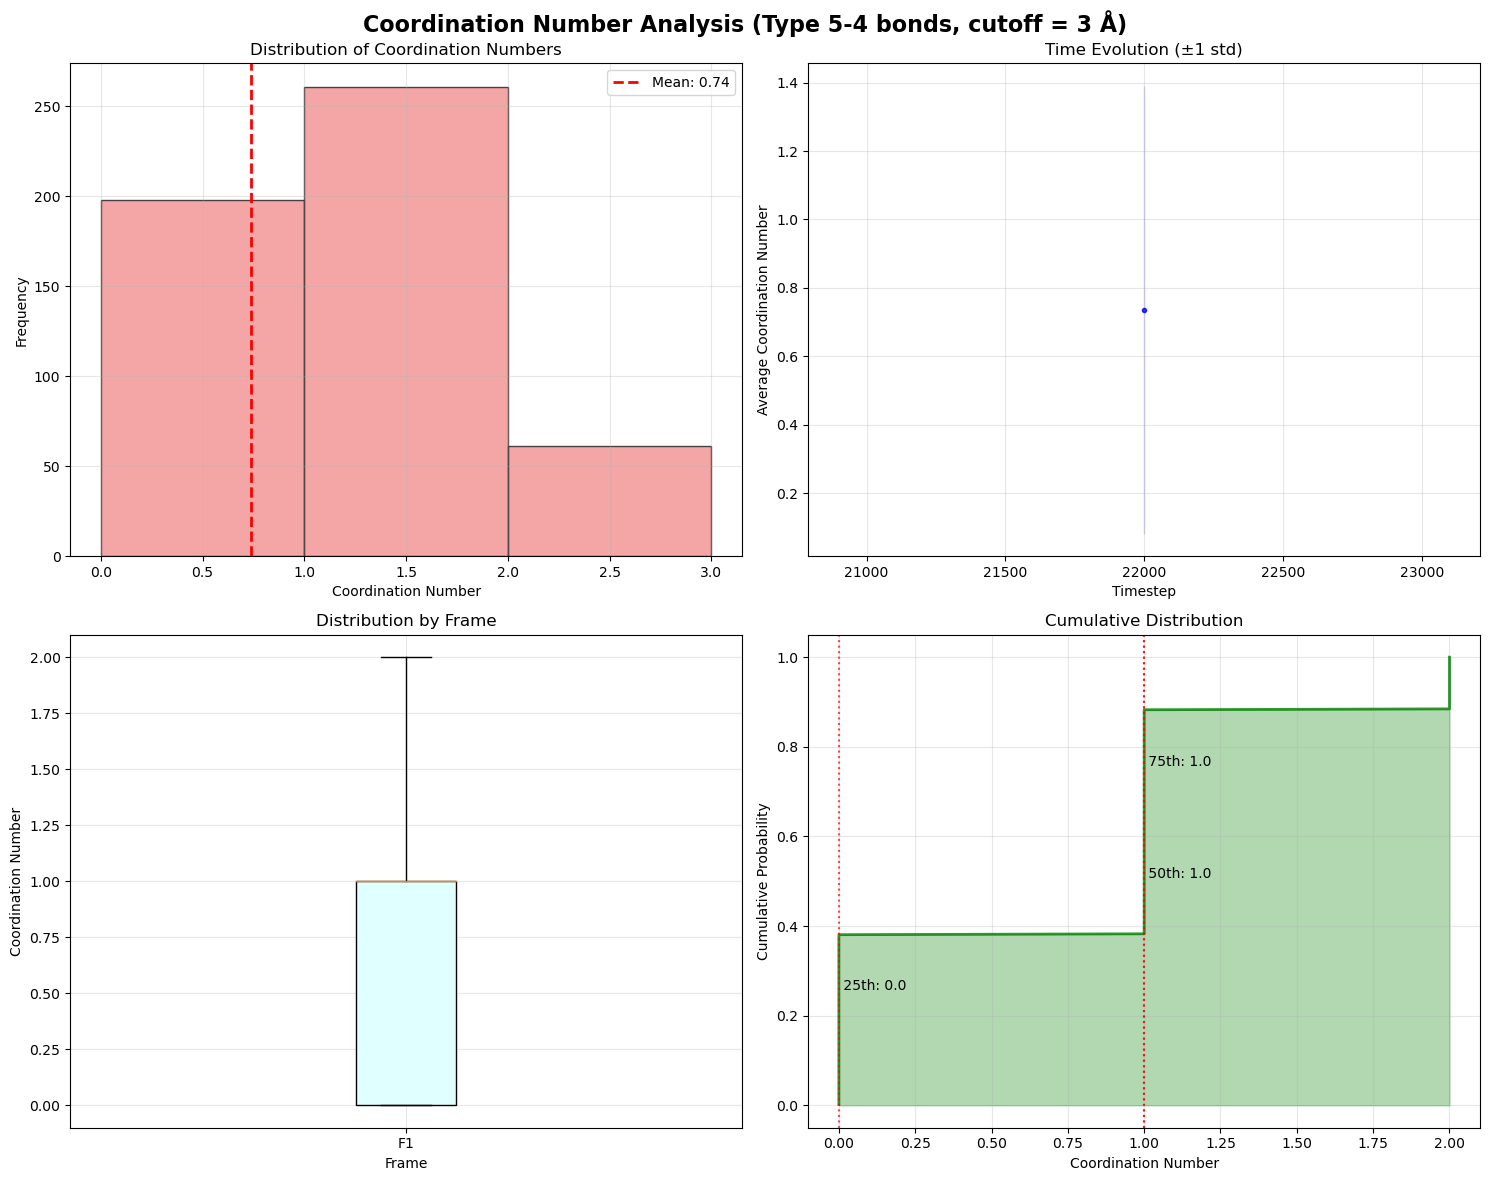

📈 Plots generated successfully!


In [11]:
analyzer = analyze_coordination('./hydration/400_diffusion_vac_lv20_r02_65_2/400K_10.dump',
                                cutoff_distance=3, show_frame_details=True)

🚀 Starting LAMMPS Coordination Number Analysis
📁 Reading trajectory file: ./hydration/400_diffusion_20_r02_65/dump.400_diffuse_9.trj
✅ Successfully read 2063 frames
   First frame has 5568 atoms
   Columns: ['id', 'type', 'x', 'y', 'z']

🔍 Analyzing coordination numbers with cutoff distance: 3.5 Å
   Frame   1 (timestep        0): 512 type-5 atoms, avg coordination: 1.48
   Frame   2 (timestep     1000): 512 type-5 atoms, avg coordination: 1.44
   Frame   3 (timestep     2000): 512 type-5 atoms, avg coordination: 1.41
   Frame   4 (timestep     3000): 512 type-5 atoms, avg coordination: 1.39
   Frame   5 (timestep     4000): 512 type-5 atoms, avg coordination: 1.39
   Frame   6 (timestep     5000): 512 type-5 atoms, avg coordination: 1.39
   Frame   7 (timestep     6000): 512 type-5 atoms, avg coordination: 1.40
   Frame   8 (timestep     7000): 512 type-5 atoms, avg coordination: 1.40
   Frame   9 (timestep     8000): 512 type-5 atoms, avg coordination: 1.42
   Frame  10 (timestep    

,Metric,Value
0,Total Frames,2063
1,Frames with Type-5 atoms,2063
2,Average Type-5 atoms per frame,512.0
3,Average Coordination Number,1.338
4,Standard Deviation,0.018
5,Minimum Coordination,0
6,Maximum Coordination,4
7,Most Common Coordination,Calculate separately



📊 FRAME-BY-FRAME RESULTS


,Frame,Timestep,Type5_Count,Avg_Coordination,Std_Coordination,Min_Coordination,Max_Coordination
0,1,0,512,1.476562,0.514855,0,2
1,2,1000,512,1.439453,0.548654,0,3
2,3,2000,512,1.410156,0.551750,0,2
3,4,3000,512,1.392578,0.566120,0,3
4,5,4000,512,1.392578,0.569560,0,2
5,6,5000,512,1.388672,0.565365,0,2
6,7,6000,512,1.400391,0.581149,0,3
7,8,7000,512,1.404297,0.568218,0,2
8,9,8000,512,1.419922,0.574043,0,2
9,10,9000,512,1.394531,0.569924,0,2


... and 2053 more frames

📈 Generating plots...


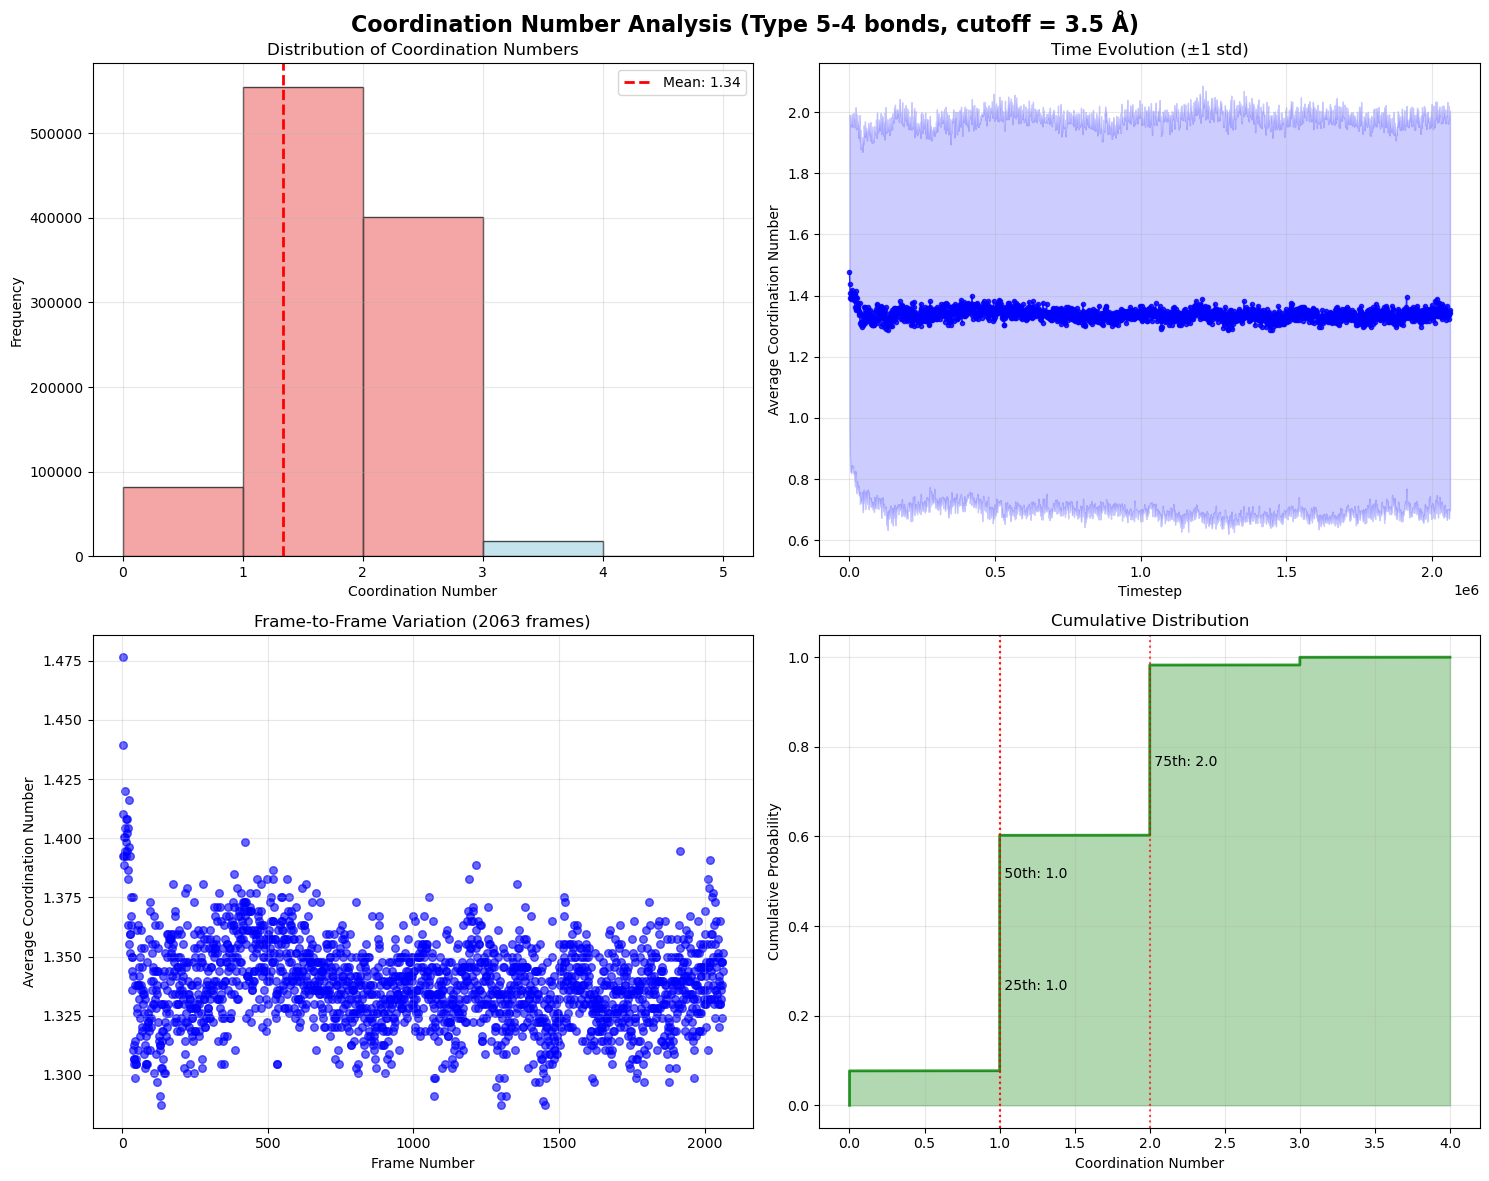

📈 Plots generated successfully!


In [6]:
analyzer = analyze_coordination('./hydration/400_diffusion_20_r02_65/dump.400_diffuse_9.trj',
                                cutoff_distance=3.5, show_frame_details=True)

🚀 Starting LAMMPS Coordination Number Analysis
📁 Reading trajectory file: ./hydration/400_diffusion_4/dump.400_diffuse_9.trj
✅ Successfully read 2035 frames
   First frame has 18792 atoms
   Columns: ['id', 'type', 'x', 'y', 'z']

🔍 Analyzing coordination numbers with cutoff distance: 3.5 Å
   Frame   1 (timestep        0): 1512 type-5 atoms, avg coordination: 1.89
   Frame   2 (timestep     1000): 1512 type-5 atoms, avg coordination: 1.73
   Frame   3 (timestep     2000): 1512 type-5 atoms, avg coordination: 1.72
   Frame   4 (timestep     3000): 1512 type-5 atoms, avg coordination: 1.72
   Frame   5 (timestep     4000): 1512 type-5 atoms, avg coordination: 1.72
   Frame   6 (timestep     5000): 1512 type-5 atoms, avg coordination: 1.71
   Frame   7 (timestep     6000): 1512 type-5 atoms, avg coordination: 1.72
   Frame   8 (timestep     7000): 1512 type-5 atoms, avg coordination: 1.72
   Frame   9 (timestep     8000): 1512 type-5 atoms, avg coordination: 1.73
   Frame  10 (timestep  

,Metric,Value
0,Total Frames,2035
1,Frames with Type-5 atoms,2035
2,Average Type-5 atoms per frame,1512.0
3,Average Coordination Number,1.652
4,Standard Deviation,0.013
5,Minimum Coordination,0
6,Maximum Coordination,2
7,Most Common Coordination,Calculate separately



📊 FRAME-BY-FRAME RESULTS


,Frame,Timestep,Type5_Count,Avg_Coordination,Std_Coordination,Min_Coordination,Max_Coordination
0,1,0,1512,1.890873,0.311798,1,2
1,2,1000,1512,1.728836,0.446046,0,2
2,3,2000,1512,1.716270,0.453732,0,2
3,4,3000,1512,1.717593,0.453099,0,2
4,5,4000,1512,1.716931,0.453416,0,2
5,6,5000,1512,1.710317,0.460847,0,2
6,7,6000,1512,1.719577,0.455057,0,2
7,8,7000,1512,1.720238,0.454737,0,2
8,9,8000,1512,1.726190,0.447393,0,2
9,10,9000,1512,1.713624,0.462195,0,2


... and 2025 more frames

📈 Generating plots...


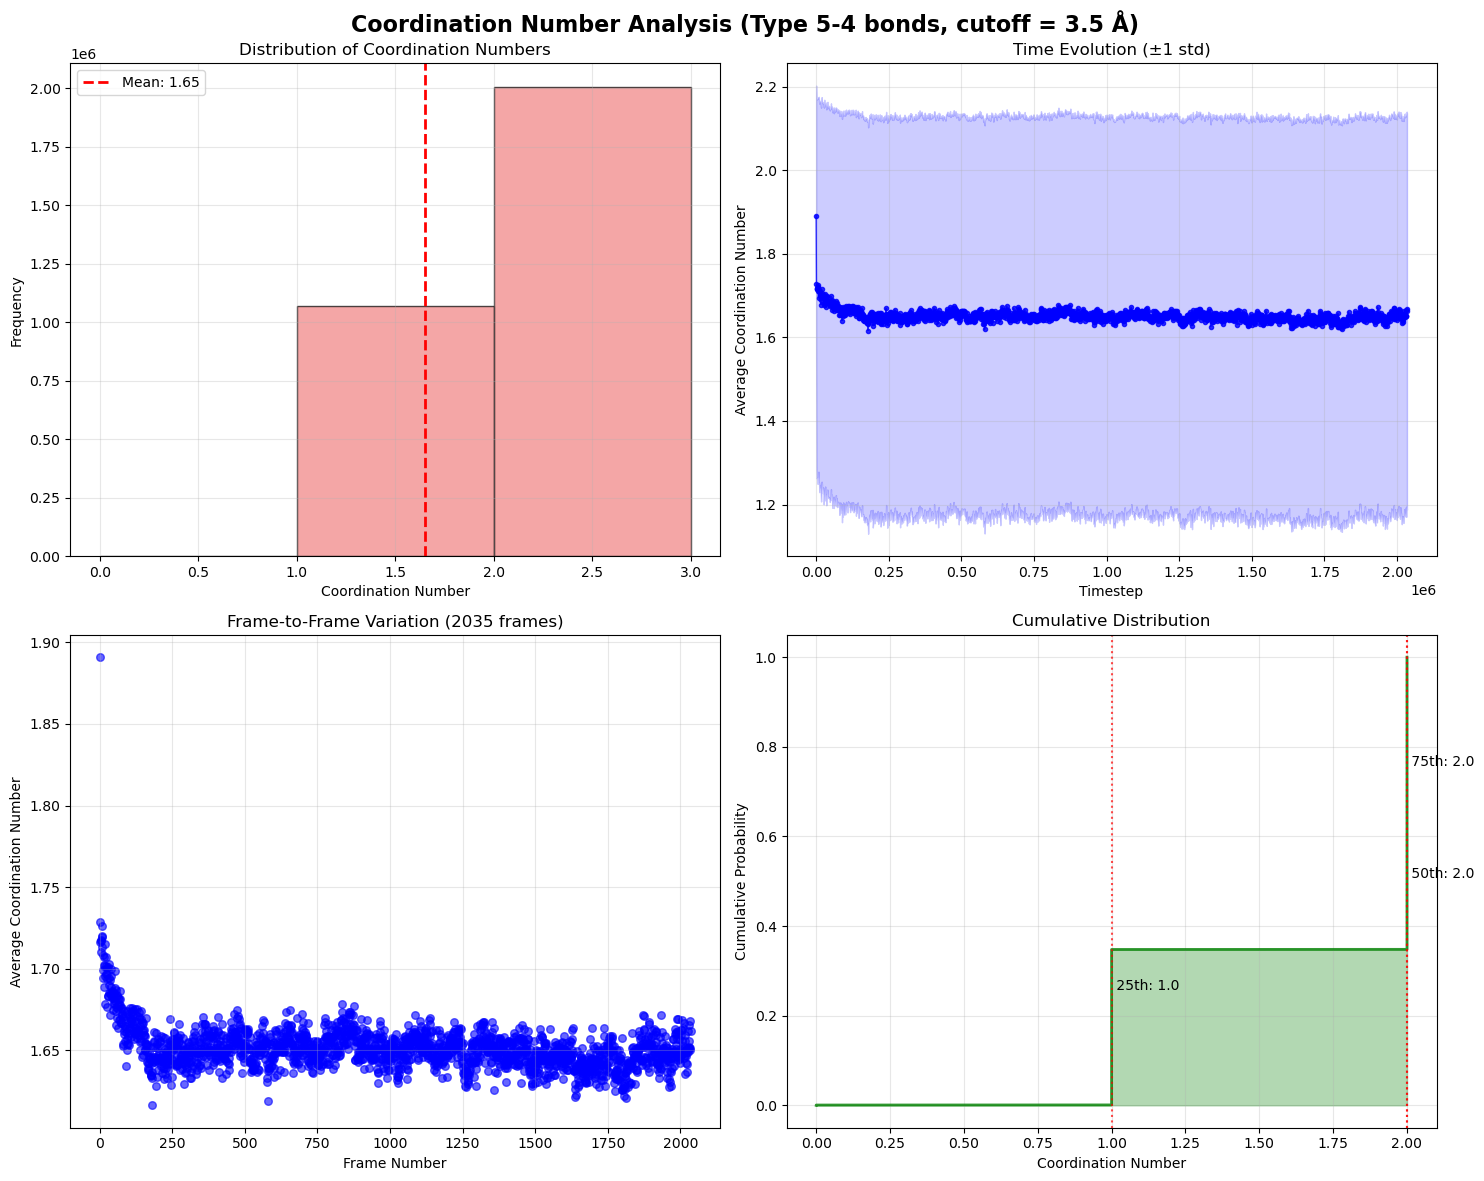

📈 Plots generated successfully!


In [11]:
analyzer = analyze_coordination('./hydration/400_diffusion_4/dump.400_diffuse_9.trj',
                                cutoff_distance=3.5, show_frame_details=True)

🚀 Starting LAMMPS Coordination Number Analysis
📁 Reading trajectory file: ./hydration/400_diffusion_20_MTP/400K_Na_28_O_16.dump
✅ Successfully read 1 frames
   First frame has 16200 atoms
   Columns: ['id', 'type', 'x', 'y', 'z']

🔍 Analyzing coordination numbers with cutoff distance: 3.5 Å
   Frame   1 (timestep    62000): 1512 type-5 atoms, avg coordination: 3.69

📊 COORDINATION NUMBER ANALYSIS SUMMARY
Total type-5 atoms analyzed: 1,512
Average coordination number: 3.689
Standard deviation: 0.851
Min coordination number: 0
Max coordination number: 6

📈 Coordination number distribution:
   CN = 0:    11 atoms (  0.7%) 
   CN = 1:    38 atoms (  2.5%) █
   CN = 2:    26 atoms (  1.7%) 
   CN = 3:   431 atoms ( 28.5%) ██████████████
   CN = 4:   844 atoms ( 55.8%) ███████████████████████████
   CN = 5:   153 atoms ( 10.1%) █████
   CN = 6:     9 atoms (  0.6%) 

📋 SUMMARY TABLE


,Metric,Value
0,Total Frames,1
1,Frames with Type-5 atoms,1
2,Average Type-5 atoms per frame,1512.0
3,Average Coordination Number,3.689
4,Standard Deviation,nan
5,Minimum Coordination,0
6,Maximum Coordination,6
7,Most Common Coordination,Calculate separately



📊 FRAME-BY-FRAME RESULTS


,Frame,Timestep,Type5_Count,Avg_Coordination,Std_Coordination,Min_Coordination,Max_Coordination
0,1,62000,1512,3.689153,0.851354,0,6



📈 Generating plots...


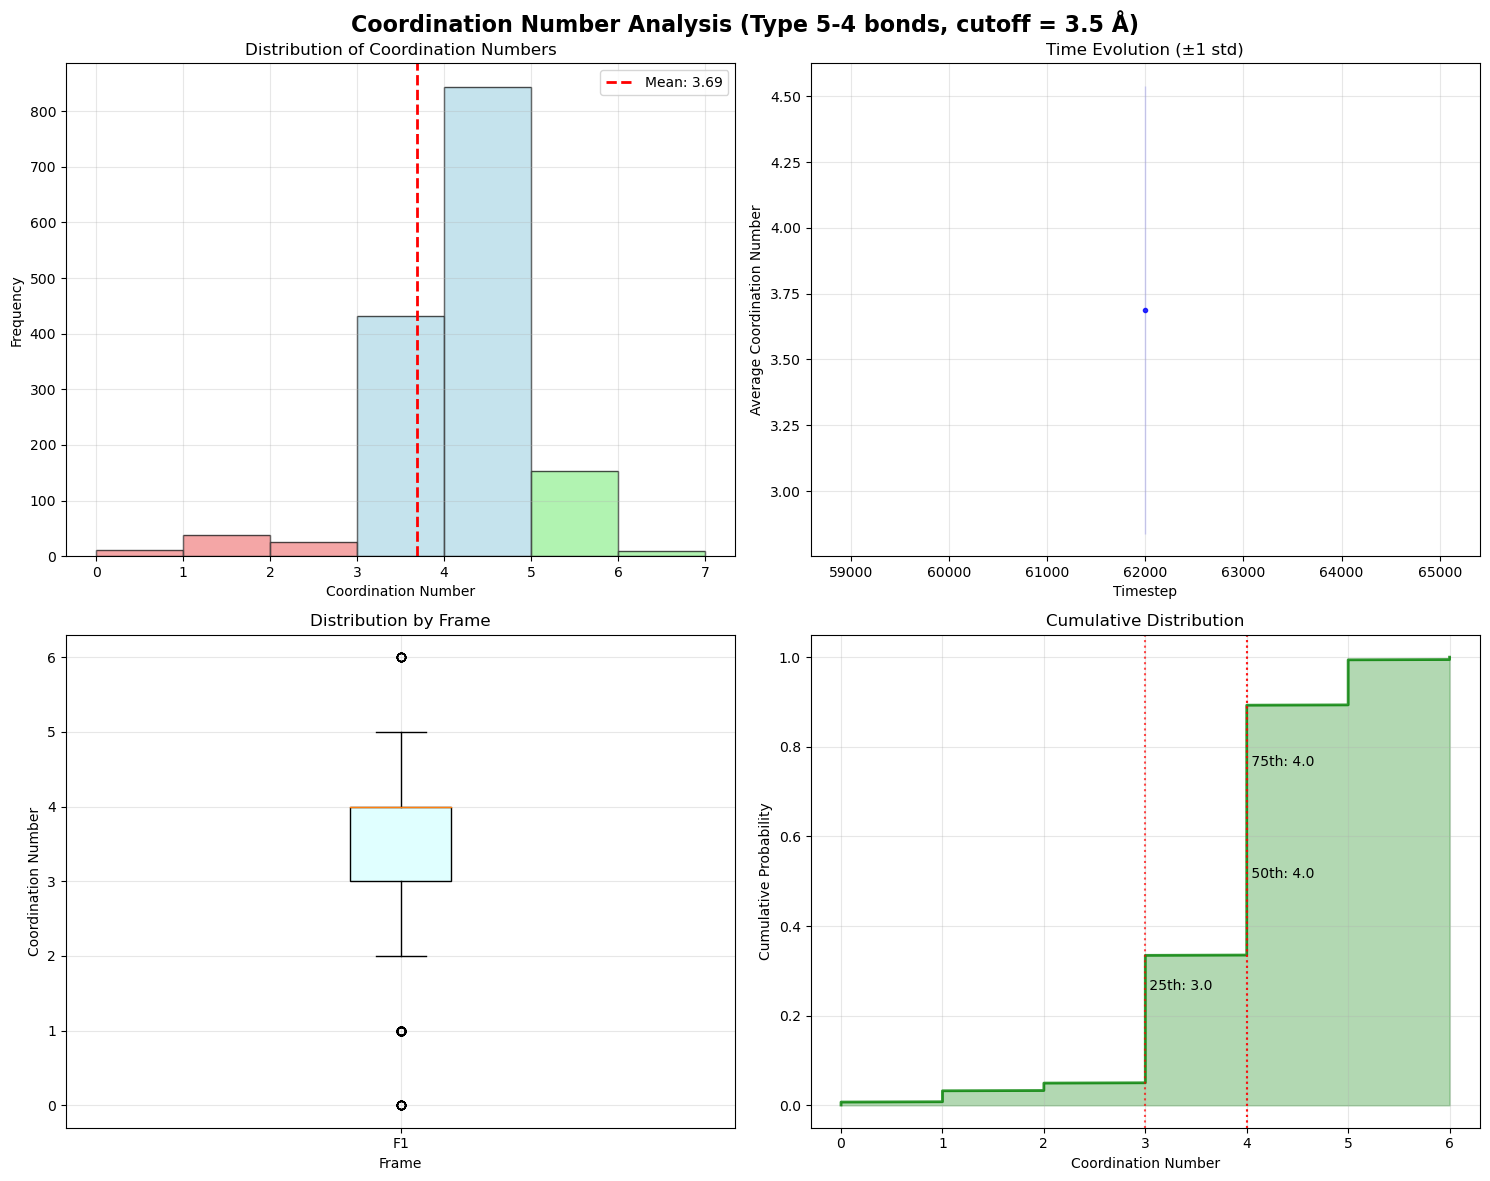

📈 Plots generated successfully!


In [6]:
analyzer = analyze_coordination('./hydration/400_diffusion_20_MTP/400K_Na_28_O_16.dump',
                                cutoff_distance=3.5, show_frame_details=True)

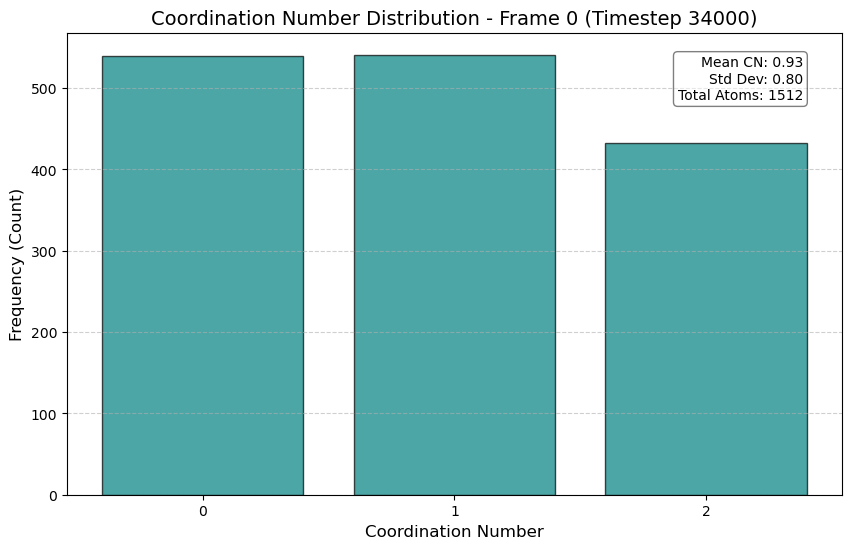

In [11]:
# --- CONFIGURATION ---
frame_index = 0  # The index of the frame you want to plot (0 is the first frame)
# ---------------------

if analyzer and analyzer.frames:
    # 1. Get the specific frame
    frame = analyzer.frames[frame_index]
    timestep = frame['timestep']
    
    # 2. Calculate CN for this specific frame
    frame_cn = analyzer.calculate_coordination_numbers(frame)
    frame_cn_400_1 = frame_cn
    
    if len(frame_cn) > 0:
        # 3. Create the plot
        plt.figure(figsize=(10, 6))
        
        # Calculate bins centered on integers
        bins = np.arange(frame_cn.min(), frame_cn.max() + 2) - 0.5
        
        counts, bins, patches = plt.hist(frame_cn, bins=bins, rwidth=0.8, 
                                         color='teal', edgecolor='black', alpha=0.7)
        
        # Add labels and styling
        plt.title(f'Coordination Number Distribution - Frame {frame_index} (Timestep {timestep})', fontsize=14)
        plt.xlabel('Coordination Number', fontsize=12)
        plt.ylabel('Frequency (Count)', fontsize=12)
        plt.xticks(np.arange(frame_cn.min(), frame_cn.max() + 1))
        plt.grid(axis='y', linestyle='--', alpha=0.6)
        
        # Add text box with stats
        stats_text = f"Mean CN: {np.mean(frame_cn):.2f}\nStd Dev: {np.std(frame_cn):.2f}\nTotal Atoms: {len(frame_cn)}"
        plt.gca().text(0.95, 0.95, stats_text, transform=plt.gca().transAxes, 
                       verticalalignment='top', horizontalalignment='right',
                       bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
        
        plt.show()
    else:
        print(f"No type-5 atoms found in frame {frame_index}.")
else:
    print("Analyzer not initialized or no frames loaded.")

In [5]:
counts

array([359., 265.])

🚀 Starting LAMMPS Coordination Number Analysis
📁 Reading trajectory file: ./hydration/RDF_lv20_vac/dump.Na_32_O_32_temp.trj
✅ Successfully read 139 frames
   First frame has 4936 atoms
   Columns: ['id', 'type', 'x', 'y', 'z']

🔍 Analyzing coordination numbers with cutoff distance: 3.5 Å
   Frame   1 (timestep        0): 256 type-5 atoms, avg coordination: 0.28
   Frame   2 (timestep     4000): 256 type-5 atoms, avg coordination: 0.30
   Frame   3 (timestep     8000): 256 type-5 atoms, avg coordination: 0.30
   Frame   4 (timestep    12000): 256 type-5 atoms, avg coordination: 0.34
   Frame   5 (timestep    16000): 256 type-5 atoms, avg coordination: 0.28
   Frame   6 (timestep    20000): 256 type-5 atoms, avg coordination: 0.30
   Frame   7 (timestep    24000): 256 type-5 atoms, avg coordination: 0.31
   Frame   8 (timestep    28000): 256 type-5 atoms, avg coordination: 0.27
   Frame   9 (timestep    32000): 256 type-5 atoms, avg coordination: 0.30
   Frame  10 (timestep    36000): 25

,Metric,Value
0,Total Frames,139
1,Frames with Type-5 atoms,139
2,Average Type-5 atoms per frame,256.0
3,Average Coordination Number,0.284
4,Standard Deviation,0.007
5,Minimum Coordination,0
6,Maximum Coordination,3
7,Most Common Coordination,Calculate separately



📊 FRAME-BY-FRAME RESULTS


,Frame,Timestep,Type5_Count,Avg_Coordination,Std_Coordination,Min_Coordination,Max_Coordination
0,1,0,256,0.277344,0.447688,0,1
1,2,4000,256,0.304688,0.523787,0,2
2,3,8000,256,0.300781,0.522314,0,2
3,4,12000,256,0.343750,0.592103,0,3
4,5,16000,256,0.281250,0.499022,0,2
5,6,20000,256,0.300781,0.514781,0,3
6,7,24000,256,0.308594,0.510136,0,2
7,8,28000,256,0.269531,0.469384,0,2
8,9,32000,256,0.296875,0.489888,0,2
9,10,36000,256,0.292969,0.488250,0,2


... and 129 more frames

📈 Generating plots...


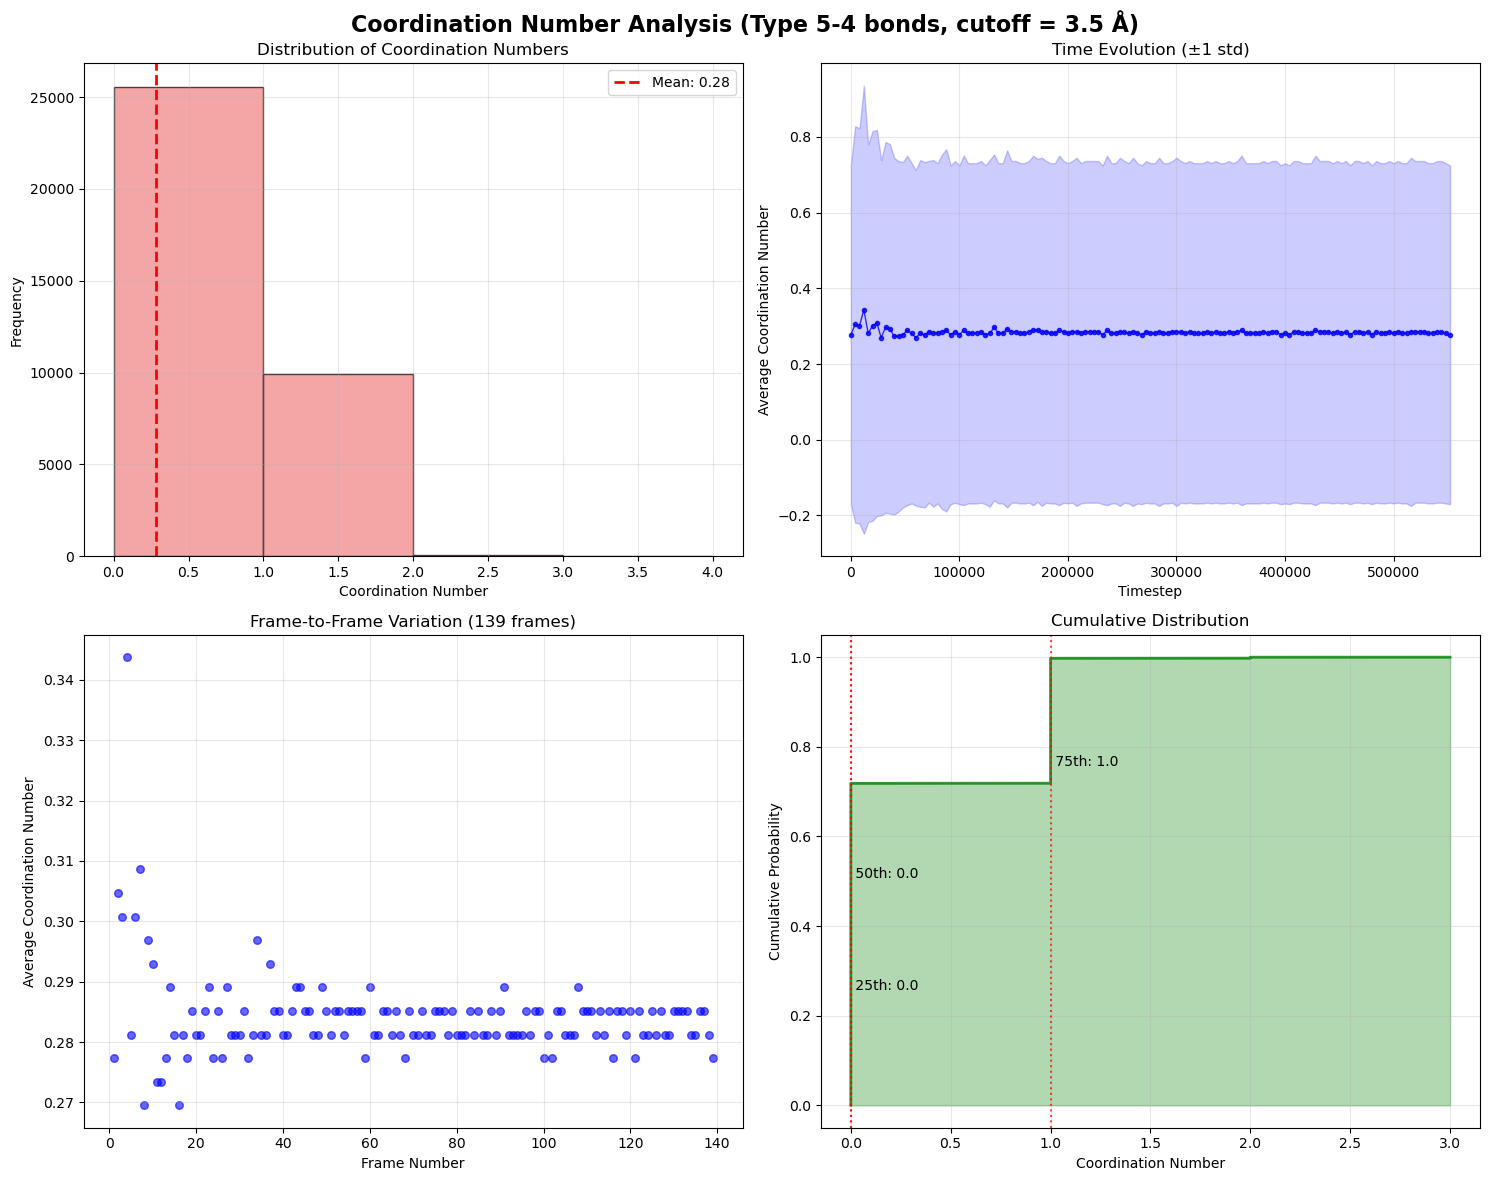

📈 Plots generated successfully!


In [9]:
analyzer = analyze_coordination('./hydration/RDF_lv20_vac/dump.Na_32_O_32_temp.trj',
                                cutoff_distance=3.5, show_frame_details=True)

🚀 Starting LAMMPS Coordination Number Analysis
📁 Reading trajectory file: ./hydration/400_diffusion_20_MTP_2/dump.400_diffuse_9.trj
✅ Successfully read 559 frames
   First frame has 5568 atoms
   Columns: ['id', 'type', 'x', 'y', 'z']

🔍 Analyzing coordination numbers with cutoff distance: 3.5 Å
   Frame   1 (timestep        0): 448 type-5 atoms, avg coordination: 1.62
   Frame   2 (timestep     1000): 448 type-5 atoms, avg coordination: 1.68
   Frame   3 (timestep     2000): 448 type-5 atoms, avg coordination: 1.66
   Frame   4 (timestep     3000): 448 type-5 atoms, avg coordination: 1.70
   Frame   5 (timestep     4000): 448 type-5 atoms, avg coordination: 1.69
   Frame   6 (timestep     5000): 448 type-5 atoms, avg coordination: 1.67
   Frame   7 (timestep     6000): 448 type-5 atoms, avg coordination: 1.67
   Frame   8 (timestep     7000): 448 type-5 atoms, avg coordination: 1.67
   Frame   9 (timestep     8000): 448 type-5 atoms, avg coordination: 1.68
   Frame  10 (timestep     9

,Metric,Value
0,Total Frames,559
1,Frames with Type-5 atoms,559
2,Average Type-5 atoms per frame,448.0
3,Average Coordination Number,1.708
4,Standard Deviation,0.017
5,Minimum Coordination,0
6,Maximum Coordination,2
7,Most Common Coordination,Calculate separately



📊 FRAME-BY-FRAME RESULTS


,Frame,Timestep,Type5_Count,Avg_Coordination,Std_Coordination,Min_Coordination,Max_Coordination
0,1,0,448,1.625000,0.484123,1,2
1,2,1000,448,1.678571,0.467025,1,2
2,3,2000,448,1.656250,0.474959,1,2
3,4,3000,448,1.698661,0.458840,1,2
4,5,4000,448,1.694196,0.460747,1,2
5,6,5000,448,1.667411,0.471141,1,2
6,7,6000,448,1.671875,0.469531,1,2
7,8,7000,448,1.669643,0.470342,1,2
8,9,8000,448,1.680804,0.466165,1,2
9,10,9000,448,1.707589,0.454870,1,2


... and 549 more frames

📈 Generating plots...


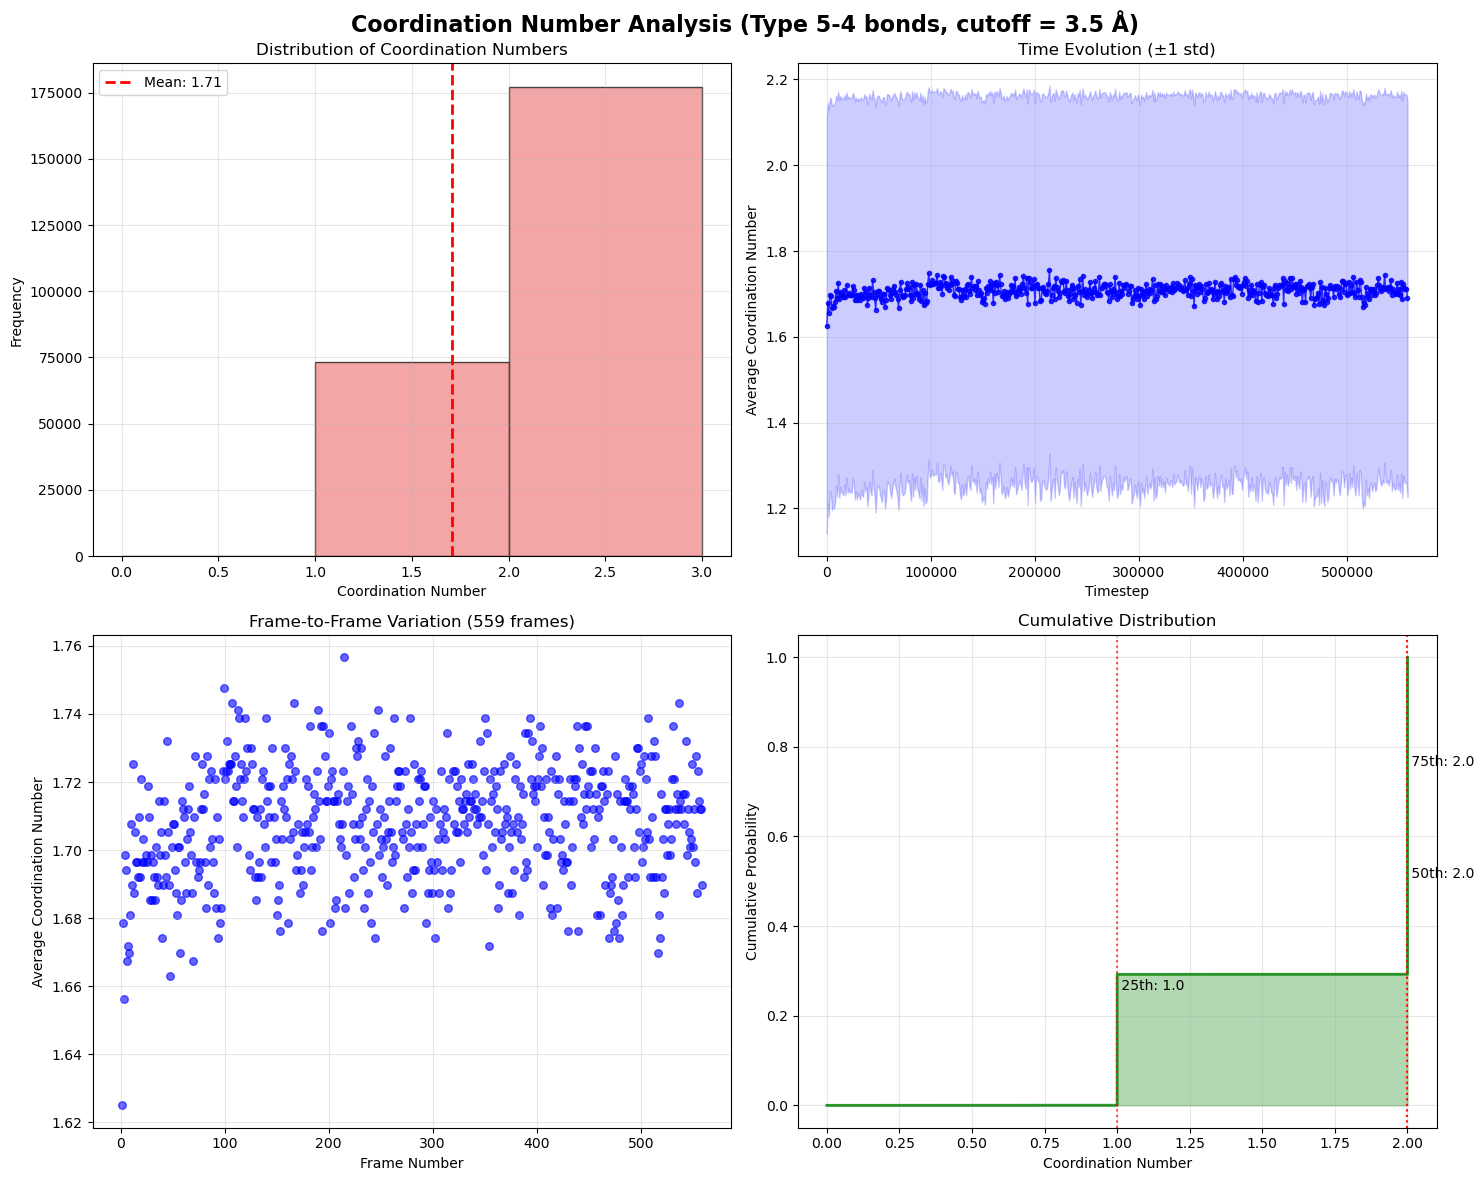

📈 Plots generated successfully!


In [5]:
analyzer = analyze_coordination('./hydration/400_diffusion_20_MTP_2/dump.400_diffuse_9.trj',
                                cutoff_distance=3.5, show_frame_details=True)

🚀 Starting LAMMPS Coordination Number Analysis
📁 Reading trajectory file: ./hydration/RDF_lv16_E0_sf0.1_f0.1/dump.Na_32_O_32_temp.trj
✅ Successfully read 278 frames
   First frame has 19008 atoms
   Columns: ['id', 'type', 'x', 'y', 'z']

🔍 Analyzing coordination numbers with cutoff distance: 3.5 Å
   Frame   1 (timestep        0): 1728 type-5 atoms, avg coordination: 1.69
   Frame   2 (timestep     4000): 1728 type-5 atoms, avg coordination: 1.68
   Frame   3 (timestep     8000): 1728 type-5 atoms, avg coordination: 1.68
   Frame   4 (timestep    12000): 1728 type-5 atoms, avg coordination: 1.49
   Frame   5 (timestep    16000): 1728 type-5 atoms, avg coordination: 1.41
   Frame   6 (timestep    20000): 1728 type-5 atoms, avg coordination: 1.26
   Frame   7 (timestep    24000): 1728 type-5 atoms, avg coordination: 1.14
   Frame   8 (timestep    28000): 1728 type-5 atoms, avg coordination: 1.06
   Frame   9 (timestep    32000): 1728 type-5 atoms, avg coordination: 1.02
   Frame  10 (ti

,Metric,Value
0,Total Frames,278
1,Frames with Type-5 atoms,278
2,Average Type-5 atoms per frame,1728.0
3,Average Coordination Number,0.572
4,Standard Deviation,0.210
5,Minimum Coordination,0
6,Maximum Coordination,3
7,Most Common Coordination,Calculate separately



📊 FRAME-BY-FRAME RESULTS


,Frame,Timestep,Type5_Count,Avg_Coordination,Std_Coordination,Min_Coordination,Max_Coordination
0,1,0,1728,1.687500,0.463512,1,2
1,2,4000,1728,1.683449,0.483433,0,3
2,3,8000,1728,1.676505,0.493104,0,3
3,4,12000,1728,1.490741,0.553739,0,3
4,5,16000,1728,1.409722,0.549577,0,3
5,6,20000,1728,1.255208,0.534922,0,3
6,7,24000,1728,1.137731,0.515512,0,2
7,8,28000,1728,1.058449,0.513192,0,2
8,9,32000,1728,1.018519,0.507700,0,2
9,10,36000,1728,0.976852,0.484167,0,2


... and 268 more frames

📈 Generating plots...


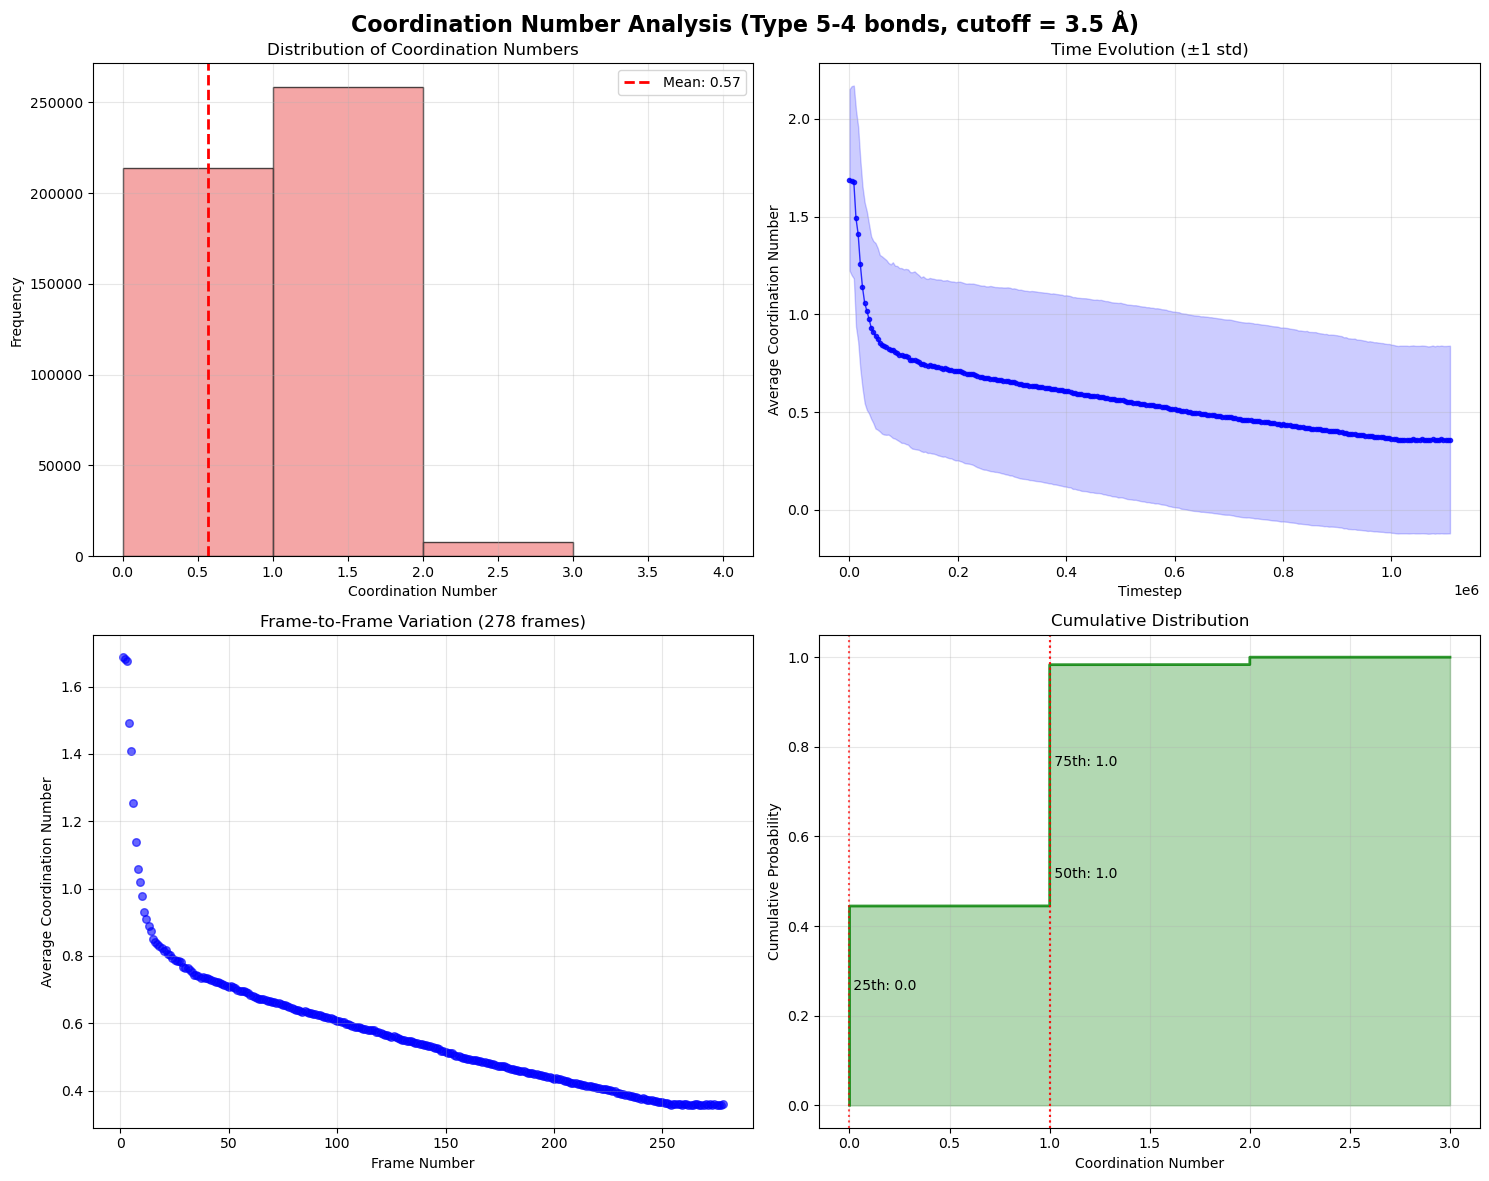

📈 Plots generated successfully!


In [3]:
analyzer = analyze_coordination('./hydration/RDF_lv16_E0_sf0.1_f0.1/dump.Na_32_O_32_temp.trj',
                                cutoff_distance=3.5, show_frame_details=True)

In [ ]:
O_ls = [4,4,4,16,16,16,32,32,32]
Na_ls = [4,16,28,4,16,28,4,16,28]
CN_ls = []
for i in range(9):
    analyzer = analyze_coordination(f'./hydration/400_diffusion_4/400K_Na_{Na_ls[i]}_O_{O_ls[i]}.dump',
                                cutoff_distance=3.5, show_frame_details=False)
    frame_index = 0  # The index of the frame you want to plot (0 is the first frame)

    if analyzer and analyzer.frames:
        # 1. Get the specific frame
        frame = analyzer.frames[frame_index]
        timestep = frame['timestep']
        
        # 2. Calculate CN for this specific frame
        frame_cn = analyzer.calculate_coordination_numbers(frame)
        CN_ls.append(frame_cn)

🚀 Starting LAMMPS Coordination Number Analysis
📁 Reading trajectory file: ./hydration/400_diffusion_4/400K_Na_4_O_4.dump
✅ Successfully read 1 frames
   First frame has 12960 atoms
   Columns: ['id', 'type', 'x', 'y', 'z']

🔍 Analyzing coordination numbers with cutoff distance: 3.5 Å
   Frame   1 (timestep    34000): 216 type-5 atoms, avg coordination: 0.68

📊 COORDINATION NUMBER ANALYSIS SUMMARY
Total type-5 atoms analyzed: 216
Average coordination number: 0.681
Standard deviation: 0.573
Min coordination number: 0
Max coordination number: 2

📈 Coordination number distribution:
   CN = 0:    81 atoms ( 37.5%) ██████████████████
   CN = 1:   123 atoms ( 56.9%) ████████████████████████████
   CN = 2:    12 atoms (  5.6%) ██

📋 SUMMARY TABLE


,Metric,Value
0,Total Frames,1
1,Frames with Type-5 atoms,1
2,Average Type-5 atoms per frame,216.0
3,Average Coordination Number,0.681
4,Standard Deviation,nan
5,Minimum Coordination,0
6,Maximum Coordination,2
7,Most Common Coordination,Calculate separately



📈 Generating plots...
📈 Plots generated successfully!
🚀 Starting LAMMPS Coordination Number Analysis
📁 Reading trajectory file: ./hydration/400_diffusion_4/400K_Na_16_O_4.dump
✅ Successfully read 1 frames
   First frame has 13603 atoms
   Columns: ['id', 'type', 'x', 'y', 'z']

🔍 Analyzing coordination numbers with cutoff distance: 3.5 Å
   Frame   1 (timestep    34000): 859 type-5 atoms, avg coordination: 0.18

📊 COORDINATION NUMBER ANALYSIS SUMMARY
Total type-5 atoms analyzed: 859
Average coordination number: 0.178
Standard deviation: 0.418
Min coordination number: 0
Max coordination number: 2

📈 Coordination number distribution:
   CN = 0:   718 atoms ( 83.6%) █████████████████████████████████████████
   CN = 1:   129 atoms ( 15.0%) ███████
   CN = 2:    12 atoms (  1.4%) 

📋 SUMMARY TABLE


,Metric,Value
0,Total Frames,1
1,Frames with Type-5 atoms,1
2,Average Type-5 atoms per frame,859.0
3,Average Coordination Number,0.178
4,Standard Deviation,nan
5,Minimum Coordination,0
6,Maximum Coordination,2
7,Most Common Coordination,Calculate separately



📈 Generating plots...


In [5]:
counts

array([391., 121.])

In [11]:
na = np.array([1728,1728,1728,1532,1446,1267,1132])/1728*2

In [12]:
na

array([2.        , 2.        , 2.        , 1.77314815, 1.67361111,
       1.46643519, 1.31018519])

🚀 Starting LAMMPS Coordination Number Analysis
📁 Reading trajectory file: ./hydration/RDF_lv16_E0_sf0.1_f0.1/dump.Na_32_O_32_temp.trj
✅ Successfully read 278 frames
   First frame has 19008 atoms
   Columns: ['id', 'type', 'x', 'y', 'z']

🔍 Analyzing coordination numbers with cutoff distance: 3.3 Å
   Frame   1 (timestep        0): 1728 type-5 atoms, avg coordination: 3.59
   Frame   2 (timestep     4000): 1728 type-5 atoms, avg coordination: 3.68
   Frame   3 (timestep     8000): 1728 type-5 atoms, avg coordination: 3.72
   Frame   4 (timestep    12000): 1532 type-5 atoms, avg coordination: 3.70
   Frame   5 (timestep    16000): 1446 type-5 atoms, avg coordination: 3.69
   Frame   6 (timestep    20000): 1267 type-5 atoms, avg coordination: 3.71
   Frame   7 (timestep    24000): 1132 type-5 atoms, avg coordination: 3.74
   Frame   8 (timestep    28000): 1052 type-5 atoms, avg coordination: 3.76
   Frame   9 (timestep    32000): 997 type-5 atoms, avg coordination: 3.77
   Frame  10 (tim

,Metric,Value
0,Total Frames,278
1,Frames with Type-5 atoms,278
2,Average Type-5 atoms per frame,525.9
3,Average Coordination Number,3.837
4,Standard Deviation,0.032
5,Minimum Coordination,0
6,Maximum Coordination,6
7,Most Common Coordination,Calculate separately



📊 FRAME-BY-FRAME RESULTS


,Frame,Timestep,Type5_Count,Avg_Coordination,Std_Coordination,Min_Coordination,Max_Coordination
0,1,0,1728,3.585069,0.555640,1,4
1,2,4000,1728,3.678819,0.713926,0,6
2,3,8000,1728,3.721065,0.710191,0,6
3,4,12000,1532,3.697781,0.747962,0,5
4,5,16000,1446,3.686722,0.743383,0,5
5,6,20000,1267,3.707182,0.687218,0,6
6,7,24000,1132,3.738516,0.671611,0,6
7,8,28000,1052,3.761407,0.589123,0,5
8,9,32000,997,3.773320,0.570743,0,6
9,10,36000,959,3.765381,0.570577,0,5


... and 268 more frames

📈 Generating plots...


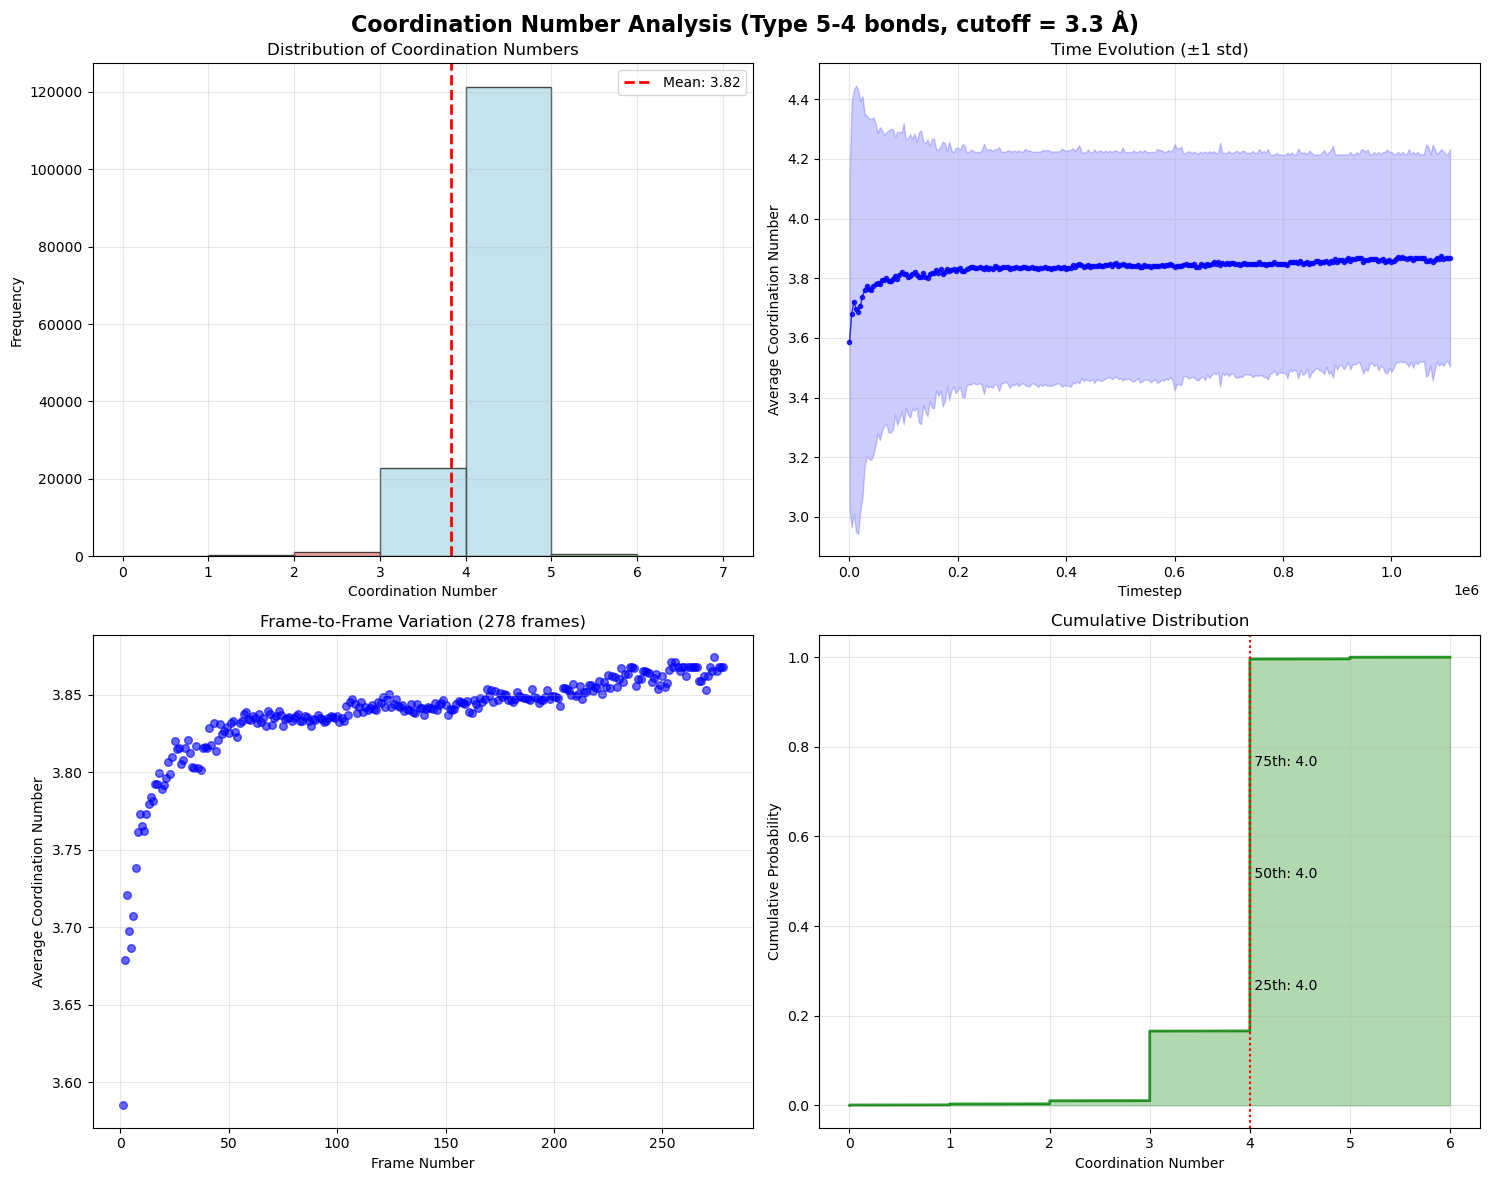

📈 Plots generated successfully!


In [16]:
analyzer = analyze_coordination('./hydration/RDF_lv16_E0_sf0.1_f0.1/dump.Na_32_O_32_temp.trj', cutoff_distance=3.3, show_frame_details=True)

In [18]:
all_coordination_numbers, results_df = analyzer.analyze_trajectory()


🔍 Analyzing coordination numbers with cutoff distance: 3.5 Å
⚠️  Warning: No type 4 atoms found in frame
⚠️  Warning: No type 4 atoms found in frame
⚠️  Warning: No type 4 atoms found in frame
⚠️  Warning: No type 4 atoms found in frame
   Frame   5 (timestep     8000):  64 type-5 atoms, avg coordination: 0.02
   Frame   6 (timestep    10000):  64 type-5 atoms, avg coordination: 0.02
   Frame   7 (timestep    12000):  64 type-5 atoms, avg coordination: 0.02
   Frame   8 (timestep    14000):  64 type-5 atoms, avg coordination: 0.02
   Frame   9 (timestep    16000):  64 type-5 atoms, avg coordination: 0.03
   Frame  10 (timestep    18000):  64 type-5 atoms, avg coordination: 0.03
   Frame  40 (timestep    78000):  64 type-5 atoms, avg coordination: 0.12
   Frame  79 (timestep   156000):  64 type-5 atoms, avg coordination: 0.28
   Frame 118 (timestep   234000):  64 type-5 atoms, avg coordination: 0.30
   Frame 157 (timestep   312000):  64 type-5 atoms, avg coordination: 0.33
   Frame 196

In [19]:
results_df

,Frame,Timestep,Type5_Count,Avg_Coordination,Std_Coordination,Min_Coordination,Max_Coordination
0,1,0,0,0.000000,0.000000,0,0
1,2,2000,0,0.000000,0.000000,0,0
2,3,4000,0,0.000000,0.000000,0,0
3,4,6000,0,0.000000,0.000000,0,0
4,5,8000,64,0.015625,0.124020,0,1
...,...,...,...,...,...,...,...
389,390,778000,64,1.375000,0.892679,0,5
390,391,780000,64,1.406250,0.913762,0,5
391,392,782000,64,1.437500,0.863767,0,5
392,393,784000,64,1.390625,0.877090,0,5


In [17]:
results_df.to_csv("./hydration/lv16_hydration_Na_O.csv", index=False)

In [ ]:
analyzer = analyze_coordination('../../../dump.gcmc_4.trj', cutoff_distance=3.3, show_frame_details=True)

# RDF Analysis

In [11]:
# LAMMPS RDF Bond Length Evolution Analysis
# Analyzes bond lengths from RDF data over time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, peak_widths
from scipy.optimize import curve_fit
from scipy.integrate import trapz
import warnings
warnings.filterwarnings('ignore')

# Set matplotlib style for better plots
plt.style.use('default')
plt.rcParams['figure.figsize'] = (14, 10)
plt.rcParams['font.size'] = 10

class RDFBondAnalyzer:
    def __init__(self, rdf_file):
        """
        Initialize RDF bond analyzer
        
        Parameters:
        rdf_file (str): Path to LAMMPS RDF output file
        """
        self.rdf_file = rdf_file
        self.time_blocks = {}
        self.bond_evolution = {}
        self.atom_pairs = []
        
    def read_rdf_data(self):
        """Read LAMMPS RDF output file"""
        print(f"📁 Reading RDF file: {self.rdf_file}")
        
        try:
            with open(self.rdf_file, 'r') as f:
                lines = f.readlines()
        except FileNotFoundError:
            print(f"❌ Error: Could not find file {self.rdf_file}")
            return False
        
        current_timestep = None
        current_data = []
        reading_data = False
        expected_rows = 0
        
        for line in lines:
            line = line.strip()
            
            # Skip comments that don't contain timestep infof
            if line.startswith('#') and 'TimeStep' not in line:
                continue
            
            # Parse timestep and number of rows
            if line.startswith('#') and 'TimeStep' in line:
                continue  # Skip header line
            
            # Check for timestep and row count line
            parts = line.split()
            if len(parts) == 2 and parts[0].isdigit() and parts[1].isdigit():
                # Save previous timestep data
                if current_timestep is not None and current_data:
                    self.time_blocks[current_timestep] = np.array(current_data)
                
                # Start new timestep
                current_timestep = int(parts[0])
                expected_rows = int(parts[1])
                current_data = []
                reading_data = True
                continue
            
            # Read data rows
            if reading_data and len(parts) > 2:
                try:
                    # Convert to float, skip row number (first column)
                    row_data = [float(x) for x in parts[1:]]  # Skip row index
                    current_data.append(row_data)
                    
                    if len(current_data) == expected_rows:
                        reading_data = False
                except ValueError:
                    continue
        
        # Don't forget the last timestep
        if current_timestep is not None and current_data:
            self.time_blocks[current_timestep] = np.array(current_data)
        
        if not self.time_blocks:
            print("❌ No RDF data found in file!")
            return False
        
        # Determine atom pairs from data structure
        first_timestep = list(self.time_blocks.keys())[0]
        first_data = self.time_blocks[first_timestep]
        
        # Column structure: [r, g(r)_pair1, N(r)_pair1, g(r)_pair2, N(r)_pair2, ...]
        num_columns = first_data.shape[1]
        num_pairs = (num_columns - 1) // 2  # Subtract 1 for r column, divide by 2 for g(r) and N(r)
        
        self.atom_pairs = [f"Pair_{i+1}" for i in range(num_pairs)]
        
        print(f"✅ Successfully read {len(self.time_blocks)} timesteps")
        print(f"   Timesteps: {sorted(self.time_blocks.keys())}")
        print(f"   Number of atom pairs: {num_pairs}")
        print(f"   Data points per RDF: {first_data.shape[0]}")
        
        return True
    
    def gaussian_peak(self, x, amplitude, center, width, baseline=0):
        """Gaussian function for peak fitting"""
        return baseline + amplitude * np.exp(-((x - center) / width) ** 2)
    
    def _peak_center_of_mass(self, r, gr, peak_r, window=0.4):
        """
        Compute the center of mass of the first RDF peak.
        
        Parameters:
        r        : radial distance array
        gr       : g(r) values
        peak_r   : approximate peak position (Å) used to set the window
        window   : half-width (Å) of the integration window around peak_r
        
        Returns:
        com      : center-of-mass bond length (Å)
        height   : g(r) value at the simple argmax (kept for plotting)
        """
        mask = (r >= peak_r - window) & (r <= peak_r + window) & (gr > 0)
        r_w  = r[mask]
        gr_w = gr[mask]
    
        if len(r_w) < 3 or gr_w.sum() == 0:
            return peak_r, gr[np.argmax(gr)]   # fallback
    
        com    = np.sum(r_w * gr_w) / np.sum(gr_w)
        height = gr_w.max()
        return com, height
    
    
    def fit_first_peak(self, r, gr, r_max=3.0):
        """
        Extract bond length as the center of mass of the first RDF peak.
    
        Parameters:
        r     : radial distance array
        gr    : g(r) values
        r_max : upper bound (Å) of the search region
    
        Returns:
        (bond_length, peak_height, peak_width=0)  — width unused but kept for API compat.
        """
        mask = (r > 0.5) & (r <= r_max)
        r_s  = r[mask]
        gr_s = gr[mask]
    
        if len(r_s) == 0 or gr_s.max() < 0.1:
            return None, None, None
    
        peak_r      = r_s[np.argmax(gr_s)]   # coarse location
        com, height = self._peak_center_of_mass(r_s, gr_s, peak_r)
    
        return com, height, 0.0              # 0.0 = dummy width
    
    def analyze_bond_evolution(self, pair_names=None, fit_first_peak=True):
        """
        Analyze bond length evolution for all atom pairs
        
        Parameters:
        pair_names: list of custom names for atom pairs
        fit_first_peak: whether to fit Gaussian to first peak for precise bond length
        """
        if not self.time_blocks:
            print("❌ No RDF data loaded!")
            return
        
        print(f"\n🔍 Analyzing bond length evolution...")
        
        if pair_names:
            self.atom_pairs = pair_names[:len(self.atom_pairs)]
        
        # Initialize results storage
        for pair in self.atom_pairs:
            self.bond_evolution[pair] = {
                'timesteps': [],
                'bond_lengths': [],
                'peak_heights': [],
                'peak_widths': [],
                'coordination_numbers': []
            }
        
        # Analyze each timestep
        for timestep in sorted(self.time_blocks.keys()):
            data = self.time_blocks[timestep]
            r = data[:, 0]  # First column is r
            
            print(f"   Analyzing timestep {timestep}...")
            
            # Process each pair
            for i, pair in enumerate(self.atom_pairs):
                # Columns: r, g(r)_1, N(r)_1, g(r)_2, N(r)_2, ...
                gr_col = 1 + i * 2  # g(r) column for this pair
                nr_col = 2 + i * 2  # N(r) column for this pair
                
                if gr_col >= data.shape[1]:
                    continue
                
                gr = data[:, gr_col]
                
                # Skip if no signal
                if np.max(gr) < 0.01:
                    continue
                
                # Get coordination number (integral of first peak or value at large r)
                if nr_col < data.shape[1]:
                    nr = data[:, nr_col]
                    coord_num = nr[-1] if len(nr) > 0 else 0
                else:
                    coord_num = 0
                
                # Find bond length
                mask = (r > 0.5) & (r <= 3.0)
                
                r_search = r[mask]
                gr_search = gr[mask]
                
                if len(gr_search) > 0:
                    max_idx = np.argmax(gr_search)
                
                    if len(gr_search) > 0:
                        bond_length, peak_height, peak_width = self.fit_first_peak(r, gr, r_max=3.0)
                    else:
                        bond_length, peak_height, peak_width = None, 0, 0
                    peak_height = gr_search[max_idx]
                
                    # Optional approximate width
                    peak_width = 0
                else:
                    bond_length = None
                    peak_height = 0
                    peak_width = 0
                
                # Store results
                if bond_length is not None:
                    self.bond_evolution[pair]['timesteps'].append(timestep)
                    self.bond_evolution[pair]['bond_lengths'].append(bond_length)
                    self.bond_evolution[pair]['peak_heights'].append(peak_height)
                    self.bond_evolution[pair]['peak_widths'].append(peak_width)
                    self.bond_evolution[pair]['coordination_numbers'].append(coord_num)
        
        # Convert to numpy arrays
        for pair in self.atom_pairs:
            for key in self.bond_evolution[pair]:
                self.bond_evolution[pair][key] = np.array(self.bond_evolution[pair][key])
        
        print(f"✅ Bond evolution analysis complete!")
        self._print_summary()
    
    def _print_summary(self):
        """Print summary of bond evolution analysis"""
        print(f"\n📊 BOND EVOLUTION SUMMARY")
        print("=" * 50)
        
        for pair in self.atom_pairs:
            data = self.bond_evolution[pair]
            if len(data['bond_lengths']) == 0:
                print(f"{pair}: No bond data found")
                continue
            
            avg_bond = np.mean(data['bond_lengths'])
            std_bond = np.std(data['bond_lengths'])
            min_bond = np.min(data['bond_lengths'])
            max_bond = np.max(data['bond_lengths'])
            
            print(f"{pair}:")
            print(f"  📏 Average bond length: {avg_bond:.3f} ± {std_bond:.3f} Å")
            print(f"  📐 Range: {min_bond:.3f} - {max_bond:.3f} Å")
            print(f"  📈 Data points: {len(data['bond_lengths'])}")
            
            if len(data['coordination_numbers']) > 0:
                avg_coord = np.mean(data['coordination_numbers'])
                print(f"  🔗 Average coordination: {avg_coord:.2f}")
    
    def plot_rdf_evolution(self, pair_index=0, max_r=6.0):
        """
        Plot RDF evolution for a specific pair over time
        
        Parameters:
        pair_index: index of atom pair to plot
        max_r: maximum r value to plot
        """
        if pair_index >= len(self.atom_pairs):
            print(f"❌ Pair index {pair_index} not available")
            return
        
        pair_name = self.atom_pairs[pair_index]
        
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))
        
        # Plot 1: RDF evolution as contour/heatmap
        timesteps = sorted(self.time_blocks.keys())
        
        # Prepare data for contour plot
        r_values = self.time_blocks[timesteps[0]][:, 0]
        r_mask = r_values <= max_r
        r_plot = r_values[r_mask]
        
        rdf_matrix = []
        for ts in timesteps:
            data = self.time_blocks[ts]
            gr_col = 1 + pair_index * 2
            if gr_col < data.shape[1]:
                gr = data[:, gr_col][r_mask]
                rdf_matrix.append(gr)
            else:
                rdf_matrix.append(np.zeros(len(r_plot)))
        
        rdf_matrix = np.array(rdf_matrix)
        
        # Create meshgrid for contour plot
        T, R = np.meshgrid(r_plot, timesteps)
        
        # Plot contour
        levels = np.linspace(0, np.max(rdf_matrix), 20)
        contour = ax1.contourf(R, T, rdf_matrix, levels=levels, cmap='viridis')
        plt.colorbar(contour, ax=ax1, label='g(r)')
        
        ax1.set_xlabel('r (Å)')
        ax1.set_ylabel('Timestep')
        ax1.set_title(f'RDF Evolution: {pair_name}')
        
        # Plot 2: Individual RDF curves
        colors = plt.cm.viridis(np.linspace(0, 1, len(timesteps)))
        
        for i, ts in enumerate(timesteps):
            data = self.time_blocks[ts]
            r = data[:, 0]
            gr_col = 1 + pair_index * 2
            
            if gr_col < data.shape[1]:
                gr = data[:, gr_col]
                mask = r <= max_r
                ax2.plot(r[mask], gr[mask], color=colors[i], 
                        label=f't={ts}' if i % max(1, len(timesteps)//5) == 0 else '',
                        alpha=0.7, linewidth=1.5)
        
        ax2.set_xlabel('r (Å)')
        ax2.set_ylabel('g(r)')
        ax2.set_title(f'RDF Curves: {pair_name}')
        ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    def plot_bond_evolution(self):
        """Plot bond length evolution for all pairs"""
        if not self.bond_evolution:
            print("❌ No bond evolution data available!")
            return
        
        # Count pairs with data
        active_pairs = [pair for pair in self.atom_pairs 
                       if len(self.bond_evolution[pair]['bond_lengths']) > 0]
        
        if not active_pairs:
            print("❌ No bond data found for any pairs!")
            return
        
        n_pairs = len(active_pairs)
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        fig.suptitle('Bond Length Evolution Analysis', fontsize=16, fontweight='bold')
        
        colors = plt.cm.tab10(np.linspace(0, 1, n_pairs))
        
        # Plot 1: Bond length vs time
        ax1 = axes[0, 0]
        for i, pair in enumerate(active_pairs):
            data = self.bond_evolution[pair]
            ax1.plot(data['timesteps'], data['bond_lengths'], 'o-', 
                    color=colors[i], label=pair, markersize=4, linewidth=2, alpha=0.8)
        
        ax1.set_xlabel('Timestep')
        ax1.set_ylabel('Bond Length (Å)')
        ax1.set_title('Bond Length Evolution')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Plot 2: Peak height evolution
        ax2 = axes[0, 1]
        for i, pair in enumerate(active_pairs):
            data = self.bond_evolution[pair]
            ax2.plot(data['timesteps'], data['peak_heights'], 's-', 
                    color=colors[i], label=pair, markersize=4, linewidth=2, alpha=0.8)
        
        ax2.set_xlabel('Timestep')
        ax2.set_ylabel('Peak Height')
        ax2.set_title('RDF Peak Height Evolution')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        
        # Plot 3: Bond length distribution
        ax3 = axes[1, 0]
        for i, pair in enumerate(active_pairs):
            data = self.bond_evolution[pair]
            if len(data['bond_lengths']) > 1:
                ax3.hist(data['bond_lengths'], bins=20, alpha=0.6, 
                        color=colors[i], label=pair, density=True)
        
        ax3.set_xlabel('Bond Length (Å)')
        ax3.set_ylabel('Probability Density')
        ax3.set_title('Bond Length Distribution')
        ax3.legend()
        ax3.grid(True, alpha=0.3)
        
        # Plot 4: Coordination number evolution
        ax4 = axes[1, 1]
        for i, pair in enumerate(active_pairs):
            data = self.bond_evolution[pair]
            if len(data['coordination_numbers']) > 0:
                ax4.plot(data['timesteps'], data['coordination_numbers'], '^-', 
                        color=colors[i], label=pair, markersize=4, linewidth=2, alpha=0.8)
        
        ax4.set_xlabel('Timestep')
        ax4.set_ylabel('Coordination Number')
        ax4.set_title('Coordination Number Evolution')
        ax4.legend()
        ax4.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    def get_results_dataframe(self):
        """Return results as pandas DataFrame"""
        if not self.bond_evolution:
            return None
        
        all_data = []
        for pair in self.atom_pairs:
            data = self.bond_evolution[pair]
            for i in range(len(data['timesteps'])):
                row = {
                    'Pair': pair,
                    'Timestep': data['timesteps'][i],
                    'Bond_Length': data['bond_lengths'][i],
                    'Peak_Height': data['peak_heights'][i],
                    'Peak_Width': data['peak_widths'][i],
                    'Coordination_Number': data['coordination_numbers'][i]
                }
                all_data.append(row)
        
        return pd.DataFrame(all_data)
    
    def save_results(self, filename='bond_evolution.csv'):
        """Save results to CSV file"""
        df = self.get_results_dataframe()
        if df is not None:
            df.to_csv(filename, index=False)
            print(f"💾 Results saved to {filename}")
        else:
            print("❌ No results to save!")

# Convenience function for Jupyter notebook
def analyze_rdf_bonds(rdf_file, pair_names=None, fit_peaks=True, max_r_plot=6.0):
    """
    Main function to analyze bond evolution from RDF data
    
    Parameters:
    rdf_file (str): Path to LAMMPS RDF file
    pair_names (list): Custom names for atom pairs (e.g., ['C-C', 'C-H', 'O-H'])
    fit_peaks (bool): Whether to fit Gaussian to first peak for precise bond length
    max_r_plot (float): Maximum r value for RDF plotting
    
    Returns:
    analyzer: RDFBondAnalyzer object with results
    """
    
    print("🚀 Starting RDF Bond Length Analysis")
    print("=" * 60)
    
    # Initialize analyzer
    analyzer = RDFBondAnalyzer(rdf_file)
    
    # Read RDF data
    if not analyzer.read_rdf_data():
        return None
    
    # Analyze bond evolution
    analyzer.analyze_bond_evolution(pair_names=pair_names, fit_first_peak=fit_peaks)
    
    # Generate plots
    print("\n📈 Generating plots...")
    analyzer.plot_bond_evolution()
    
    # Show results table
    df = analyzer.get_results_dataframe()
    if df is not None:
        print("\n📋 RESULTS SUMMARY")
        print("=" * 30)
        display(df.head(10))
        if len(df) > 10:
            print(f"... and {len(df) - 10} more rows")
    
    return analyzer

# Example usage:
print("🎯 RDF Bond Analysis loaded!")
print("📝 Usage: analyzer = analyze_rdf_bonds('your_rdf_file.txt')")
print("🏷️  Custom names: analyzer = analyze_rdf_bonds('file.txt', pair_names=['C-C', 'C-H', 'O-H'])")
print("📊 Plot specific pair RDF evolution: analyzer.plot_rdf_evolution(pair_index=0)")

🎯 RDF Bond Analysis loaded!
📝 Usage: analyzer = analyze_rdf_bonds('your_rdf_file.txt')
🏷️  Custom names: analyzer = analyze_rdf_bonds('file.txt', pair_names=['C-C', 'C-H', 'O-H'])
📊 Plot specific pair RDF evolution: analyzer.plot_rdf_evolution(pair_index=0)


In [7]:
# LAMMPS RDF Bond Length Evolution Analysis
# Analyzes bond lengths from RDF data over time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, peak_widths
from scipy.optimize import curve_fit
from scipy.integrate import trapz
import warnings
warnings.filterwarnings('ignore')

# Set matplotlib style for better plots
plt.style.use('default')
plt.rcParams['figure.figsize'] = (14, 10)
plt.rcParams['font.size'] = 10

class RDFBondAnalyzer:
    def __init__(self, rdf_file):
        """
        Initialize RDF bond analyzer
        
        Parameters:
        rdf_file (str): Path to LAMMPS RDF output file
        """
        self.rdf_file = rdf_file
        self.time_blocks = {}
        self.bond_evolution = {}
        self.atom_pairs = []
        
    def read_rdf_data(self):
        """Read LAMMPS RDF output file"""
        print(f"📁 Reading RDF file: {self.rdf_file}")
        
        try:
            with open(self.rdf_file, 'r') as f:
                lines = f.readlines()
        except FileNotFoundError:
            print(f"❌ Error: Could not find file {self.rdf_file}")
            return False
        
        current_timestep = None
        current_data = []
        reading_data = False
        expected_rows = 0
        
        for line in lines:
            line = line.strip()
            
            # Skip comments that don't contain timestep infof
            if line.startswith('#') and 'TimeStep' not in line:
                continue
            
            # Parse timestep and number of rows
            if line.startswith('#') and 'TimeStep' in line:
                continue  # Skip header line
            
            # Check for timestep and row count line
            parts = line.split()
            if len(parts) == 2 and parts[0].isdigit() and parts[1].isdigit():
                # Save previous timestep data
                if current_timestep is not None and current_data:
                    self.time_blocks[current_timestep] = np.array(current_data)
                
                # Start new timestep
                current_timestep = int(parts[0])
                expected_rows = int(parts[1])
                current_data = []
                reading_data = True
                continue
            
            # Read data rows
            if reading_data and len(parts) > 2:
                try:
                    # Convert to float, skip row number (first column)
                    row_data = [float(x) for x in parts[1:]]  # Skip row index
                    current_data.append(row_data)
                    
                    if len(current_data) == expected_rows:
                        reading_data = False
                except ValueError:
                    continue
        
        # Don't forget the last timestep
        if current_timestep is not None and current_data:
            self.time_blocks[current_timestep] = np.array(current_data)
        
        if not self.time_blocks:
            print("❌ No RDF data found in file!")
            return False
        
        # Determine atom pairs from data structure
        first_timestep = list(self.time_blocks.keys())[0]
        first_data = self.time_blocks[first_timestep]
        
        # Column structure: [r, g(r)_pair1, N(r)_pair1, g(r)_pair2, N(r)_pair2, ...]
        num_columns = first_data.shape[1]
        num_pairs = (num_columns - 1) // 2  # Subtract 1 for r column, divide by 2 for g(r) and N(r)
        
        self.atom_pairs = [f"Pair_{i+1}" for i in range(num_pairs)]
        
        print(f"✅ Successfully read {len(self.time_blocks)} timesteps")
        print(f"   Timesteps: {sorted(self.time_blocks.keys())}")
        print(f"   Number of atom pairs: {num_pairs}")
        print(f"   Data points per RDF: {first_data.shape[0]}")
        
        return True
    
    def gaussian_peak(self, x, amplitude, center, width, baseline=0):
        """Gaussian function for peak fitting"""
        return baseline + amplitude * np.exp(-((x - center) / width) ** 2)
    
    def find_bond_peaks(self, r, gr, min_height=0.1, min_distance=10, r_max=5.0):
        """
        Find peaks in RDF that correspond to bonds
        
        Parameters:
        r: radial distance array
        gr: g(r) values
        min_height: minimum peak height
        min_distance: minimum distance between peaks (in data points)
        r_max: maximum r value to consider for bond peaks
        """
        # Only consider data up to r_max
        mask = r <= r_max
        r_cut = r[mask]
        gr_cut = gr[mask]
        
        if len(gr_cut) == 0 or np.max(gr_cut) < min_height:
            return [], [], []
        
        # Find peaks
        peaks, properties = find_peaks(gr_cut, height=min_height, distance=min_distance)
        
        if len(peaks) == 0:
            return [], [], []
        
        # Get peak positions, heights, and widths
        peak_positions = r_cut[peaks]
        peak_heights = gr_cut[peaks]
        
        # Calculate peak widths
        try:
            widths, _, _, _ = peak_widths(gr_cut, peaks, rel_height=0.5)
            peak_widths_r = widths * (r_cut[1] - r_cut[0])  # Convert to r units
        except:
            peak_widths_r = np.ones(len(peaks)) * 0.1  # Default width
        
        return peak_positions, peak_heights, peak_widths_r
    
    def fit_first_peak(self, r, gr, r_max=3.0):
        """
        Extract the precise maximum value of the first peak in the RDF 
        instead of fitting a Gaussian curve.
        
        Parameters:
        r: radial distance array
        gr: g(r) values
        r_max: maximum r to consider for the first peak bond length
        """
        # Find region around first peak (skipping immediate zero-distance noise)
        mask = (r > 0.5) & (r <= r_max)
        r_fit = r[mask]
        gr_fit = gr[mask]
        
        if len(r_fit) == 0 or np.max(gr_fit) < 0.1:
            return None, None, None
        
        # Extract the exact maximum position and height directly
        max_idx = np.argmax(gr_fit)
        peak_r = r_fit[max_idx]
        peak_height = gr_fit[max_idx]
        
        # Estimate width roughly using FWHM around the maximum point or default to a step size
        # Because we aren't fitting, we can approximate the data resolution width
        approx_width = r_fit[1] - r_fit[0] 
        
        return peak_r, peak_height, approx_width
    
    def analyze_bond_evolution(self, pair_names=None, fit_first_peak=True):
        """
        Analyze bond length evolution for all atom pairs
        
        Parameters:
        pair_names: list of custom names for atom pairs
        fit_first_peak: whether to fit Gaussian to first peak for precise bond length
        """
        if not self.time_blocks:
            print("❌ No RDF data loaded!")
            return
        
        print(f"\n🔍 Analyzing bond length evolution...")
        
        if pair_names:
            self.atom_pairs = pair_names[:len(self.atom_pairs)]
        
        # Initialize results storage
        for pair in self.atom_pairs:
            self.bond_evolution[pair] = {
                'timesteps': [],
                'bond_lengths': [],
                'peak_heights': [],
                'peak_widths': [],
                'coordination_numbers': []
            }
        
        # Analyze each timestep
        for timestep in sorted(self.time_blocks.keys()):
            data = self.time_blocks[timestep]
            r = data[:, 0]  # First column is r
            
            print(f"   Analyzing timestep {timestep}...")
            
            # Process each pair
            for i, pair in enumerate(self.atom_pairs):
                # Columns: r, g(r)_1, N(r)_1, g(r)_2, N(r)_2, ...
                gr_col = 1 + i * 2  # g(r) column for this pair
                nr_col = 2 + i * 2  # N(r) column for this pair
                
                if gr_col >= data.shape[1]:
                    continue
                
                gr = data[:, gr_col]
                
                # Skip if no signal
                if np.max(gr) < 0.01:
                    continue
                
                # Get coordination number (integral of first peak or value at large r)
                if nr_col < data.shape[1]:
                    nr = data[:, nr_col]
                    coord_num = nr[-1] if len(nr) > 0 else 0
                else:
                    coord_num = 0
                
                # Find bond length
                if fit_first_peak:
                    bond_length, peak_height, peak_width = self.fit_first_peak(r, gr)
                else:
                    peaks, heights, widths = self.find_bond_peaks(r, gr)
                    if len(peaks) > 0:
                        bond_length, peak_height, peak_width = peaks[0], heights[0], widths[0]
                    else:
                        bond_length, peak_height, peak_width = None, 0, 0
                
                # Store results
                if bond_length is not None:
                    self.bond_evolution[pair]['timesteps'].append(timestep)
                    self.bond_evolution[pair]['bond_lengths'].append(bond_length)
                    self.bond_evolution[pair]['peak_heights'].append(peak_height)
                    self.bond_evolution[pair]['peak_widths'].append(peak_width)
                    self.bond_evolution[pair]['coordination_numbers'].append(coord_num)
        
        # Convert to numpy arrays
        for pair in self.atom_pairs:
            for key in self.bond_evolution[pair]:
                self.bond_evolution[pair][key] = np.array(self.bond_evolution[pair][key])
        
        print(f"✅ Bond evolution analysis complete!")
        self._print_summary()
    
    def _print_summary(self):
        """Print summary of bond evolution analysis"""
        print(f"\n📊 BOND EVOLUTION SUMMARY")
        print("=" * 50)
        
        for pair in self.atom_pairs:
            data = self.bond_evolution[pair]
            if len(data['bond_lengths']) == 0:
                print(f"{pair}: No bond data found")
                continue
            
            avg_bond = np.mean(data['bond_lengths'])
            std_bond = np.std(data['bond_lengths'])
            min_bond = np.min(data['bond_lengths'])
            max_bond = np.max(data['bond_lengths'])
            
            print(f"{pair}:")
            print(f"  📏 Average bond length: {avg_bond:.3f} ± {std_bond:.3f} Å")
            print(f"  📐 Range: {min_bond:.3f} - {max_bond:.3f} Å")
            print(f"  📈 Data points: {len(data['bond_lengths'])}")
            
            if len(data['coordination_numbers']) > 0:
                avg_coord = np.mean(data['coordination_numbers'])
                print(f"  🔗 Average coordination: {avg_coord:.2f}")
    
    def plot_rdf_evolution(self, pair_index=0, max_r=6.0):
        """
        Plot RDF evolution for a specific pair over time
        
        Parameters:
        pair_index: index of atom pair to plot
        max_r: maximum r value to plot
        """
        if pair_index >= len(self.atom_pairs):
            print(f"❌ Pair index {pair_index} not available")
            return
        
        pair_name = self.atom_pairs[pair_index]
        
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))
        
        # Plot 1: RDF evolution as contour/heatmap
        timesteps = sorted(self.time_blocks.keys())
        
        # Prepare data for contour plot
        r_values = self.time_blocks[timesteps[0]][:, 0]
        r_mask = r_values <= max_r
        r_plot = r_values[r_mask]
        
        rdf_matrix = []
        for ts in timesteps:
            data = self.time_blocks[ts]
            gr_col = 1 + pair_index * 2
            if gr_col < data.shape[1]:
                gr = data[:, gr_col][r_mask]
                rdf_matrix.append(gr)
            else:
                rdf_matrix.append(np.zeros(len(r_plot)))
        
        rdf_matrix = np.array(rdf_matrix)
        
        # Create meshgrid for contour plot
        T, R = np.meshgrid(r_plot, timesteps)
        
        # Plot contour
        levels = np.linspace(0, np.max(rdf_matrix), 20)
        contour = ax1.contourf(R, T, rdf_matrix, levels=levels, cmap='viridis')
        plt.colorbar(contour, ax=ax1, label='g(r)')
        
        ax1.set_xlabel('r (Å)')
        ax1.set_ylabel('Timestep')
        ax1.set_title(f'RDF Evolution: {pair_name}')
        
        # Plot 2: Individual RDF curves
        colors = plt.cm.viridis(np.linspace(0, 1, len(timesteps)))
        
        for i, ts in enumerate(timesteps):
            data = self.time_blocks[ts]
            r = data[:, 0]
            gr_col = 1 + pair_index * 2
            
            if gr_col < data.shape[1]:
                gr = data[:, gr_col]
                mask = r <= max_r
                ax2.plot(r[mask], gr[mask], color=colors[i], 
                        label=f't={ts}' if i % max(1, len(timesteps)//5) == 0 else '',
                        alpha=0.7, linewidth=1.5)
        
        ax2.set_xlabel('r (Å)')
        ax2.set_ylabel('g(r)')
        ax2.set_title(f'RDF Curves: {pair_name}')
        ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    def plot_bond_evolution(self):
        """Plot bond length evolution for all pairs"""
        if not self.bond_evolution:
            print("❌ No bond evolution data available!")
            return
        
        # Count pairs with data
        active_pairs = [pair for pair in self.atom_pairs 
                       if len(self.bond_evolution[pair]['bond_lengths']) > 0]
        
        if not active_pairs:
            print("❌ No bond data found for any pairs!")
            return
        
        n_pairs = len(active_pairs)
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        fig.suptitle('Bond Length Evolution Analysis', fontsize=16, fontweight='bold')
        
        colors = plt.cm.tab10(np.linspace(0, 1, n_pairs))
        
        # Plot 1: Bond length vs time
        ax1 = axes[0, 0]
        for i, pair in enumerate(active_pairs):
            data = self.bond_evolution[pair]
            ax1.plot(data['timesteps'], data['bond_lengths'], 'o-', 
                    color=colors[i], label=pair, markersize=4, linewidth=2, alpha=0.8)
        
        ax1.set_xlabel('Timestep')
        ax1.set_ylabel('Bond Length (Å)')
        ax1.set_title('Bond Length Evolution')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Plot 2: Peak height evolution
        ax2 = axes[0, 1]
        for i, pair in enumerate(active_pairs):
            data = self.bond_evolution[pair]
            ax2.plot(data['timesteps'], data['peak_heights'], 's-', 
                    color=colors[i], label=pair, markersize=4, linewidth=2, alpha=0.8)
        
        ax2.set_xlabel('Timestep')
        ax2.set_ylabel('Peak Height')
        ax2.set_title('RDF Peak Height Evolution')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        
        # Plot 3: Bond length distribution
        ax3 = axes[1, 0]
        for i, pair in enumerate(active_pairs):
            data = self.bond_evolution[pair]
            if len(data['bond_lengths']) > 1:
                ax3.hist(data['bond_lengths'], bins=20, alpha=0.6, 
                        color=colors[i], label=pair, density=True)
        
        ax3.set_xlabel('Bond Length (Å)')
        ax3.set_ylabel('Probability Density')
        ax3.set_title('Bond Length Distribution')
        ax3.legend()
        ax3.grid(True, alpha=0.3)
        
        # Plot 4: Coordination number evolution
        ax4 = axes[1, 1]
        for i, pair in enumerate(active_pairs):
            data = self.bond_evolution[pair]
            if len(data['coordination_numbers']) > 0:
                ax4.plot(data['timesteps'], data['coordination_numbers'], '^-', 
                        color=colors[i], label=pair, markersize=4, linewidth=2, alpha=0.8)
        
        ax4.set_xlabel('Timestep')
        ax4.set_ylabel('Coordination Number')
        ax4.set_title('Coordination Number Evolution')
        ax4.legend()
        ax4.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    def get_results_dataframe(self):
        """Return results as pandas DataFrame"""
        if not self.bond_evolution:
            return None
        
        all_data = []
        for pair in self.atom_pairs:
            data = self.bond_evolution[pair]
            for i in range(len(data['timesteps'])):
                row = {
                    'Pair': pair,
                    'Timestep': data['timesteps'][i],
                    'Bond_Length': data['bond_lengths'][i],
                    'Peak_Height': data['peak_heights'][i],
                    'Peak_Width': data['peak_widths'][i],
                    'Coordination_Number': data['coordination_numbers'][i]
                }
                all_data.append(row)
        
        return pd.DataFrame(all_data)
    
    def save_results(self, filename='bond_evolution.csv'):
        """Save results to CSV file"""
        df = self.get_results_dataframe()
        if df is not None:
            df.to_csv(filename, index=False)
            print(f"💾 Results saved to {filename}")
        else:
            print("❌ No results to save!")

# Convenience function for Jupyter notebook
def analyze_rdf_bonds(rdf_file, pair_names=None, fit_peaks=True, max_r_plot=6.0):
    """
    Main function to analyze bond evolution from RDF data
    
    Parameters:
    rdf_file (str): Path to LAMMPS RDF file
    pair_names (list): Custom names for atom pairs (e.g., ['C-C', 'C-H', 'O-H'])
    fit_peaks (bool): Whether to fit Gaussian to first peak for precise bond length
    max_r_plot (float): Maximum r value for RDF plotting
    
    Returns:
    analyzer: RDFBondAnalyzer object with results
    """
    
    print("🚀 Starting RDF Bond Length Analysis")
    print("=" * 60)
    
    # Initialize analyzer
    analyzer = RDFBondAnalyzer(rdf_file)
    
    # Read RDF data
    if not analyzer.read_rdf_data():
        return None
    
    # Analyze bond evolution
    analyzer.analyze_bond_evolution(pair_names=pair_names, fit_first_peak=fit_peaks)
    
    # Generate plots
    print("\n📈 Generating plots...")
    analyzer.plot_bond_evolution()
    
    # Show results table
    df = analyzer.get_results_dataframe()
    if df is not None:
        print("\n📋 RESULTS SUMMARY")
        print("=" * 30)
        display(df.head(10))
        if len(df) > 10:
            print(f"... and {len(df) - 10} more rows")
    
    return analyzer

# Example usage:
print("🎯 RDF Bond Analysis loaded!")
print("📝 Usage: analyzer = analyze_rdf_bonds('your_rdf_file.txt')")
print("🏷️  Custom names: analyzer = analyze_rdf_bonds('file.txt', pair_names=['C-C', 'C-H', 'O-H'])")
print("📊 Plot specific pair RDF evolution: analyzer.plot_rdf_evolution(pair_index=0)")

🎯 RDF Bond Analysis loaded!
📝 Usage: analyzer = analyze_rdf_bonds('your_rdf_file.txt')
🏷️  Custom names: analyzer = analyze_rdf_bonds('file.txt', pair_names=['C-C', 'C-H', 'O-H'])
📊 Plot specific pair RDF evolution: analyzer.plot_rdf_evolution(pair_index=0)


🚀 Starting RDF Bond Length Analysis
📁 Reading RDF file: ./hydration/RDF_lv20_vac/300K_rdf_Na_32_O_32.rdf
✅ Successfully read 138 timesteps
   Timesteps: [4000, 8000, 12000, 16000, 20000, 24000, 28000, 32000, 36000, 40000, 44000, 48000, 52000, 56000, 60000, 64000, 68000, 72000, 76000, 80000, 84000, 88000, 92000, 96000, 100000, 104000, 108000, 112000, 116000, 120000, 124000, 128000, 132000, 136000, 140000, 144000, 148000, 152000, 156000, 160000, 164000, 168000, 172000, 176000, 180000, 184000, 188000, 192000, 196000, 200000, 204000, 208000, 212000, 216000, 220000, 224000, 228000, 232000, 236000, 240000, 244000, 248000, 252000, 256000, 260000, 264000, 268000, 272000, 276000, 280000, 284000, 288000, 292000, 296000, 300000, 304000, 308000, 312000, 316000, 320000, 324000, 328000, 332000, 336000, 340000, 344000, 348000, 352000, 356000, 360000, 364000, 368000, 372000, 376000, 380000, 384000, 388000, 392000, 396000, 400000, 404000, 408000, 412000, 416000, 420000, 424000, 428000, 432000, 436000, 

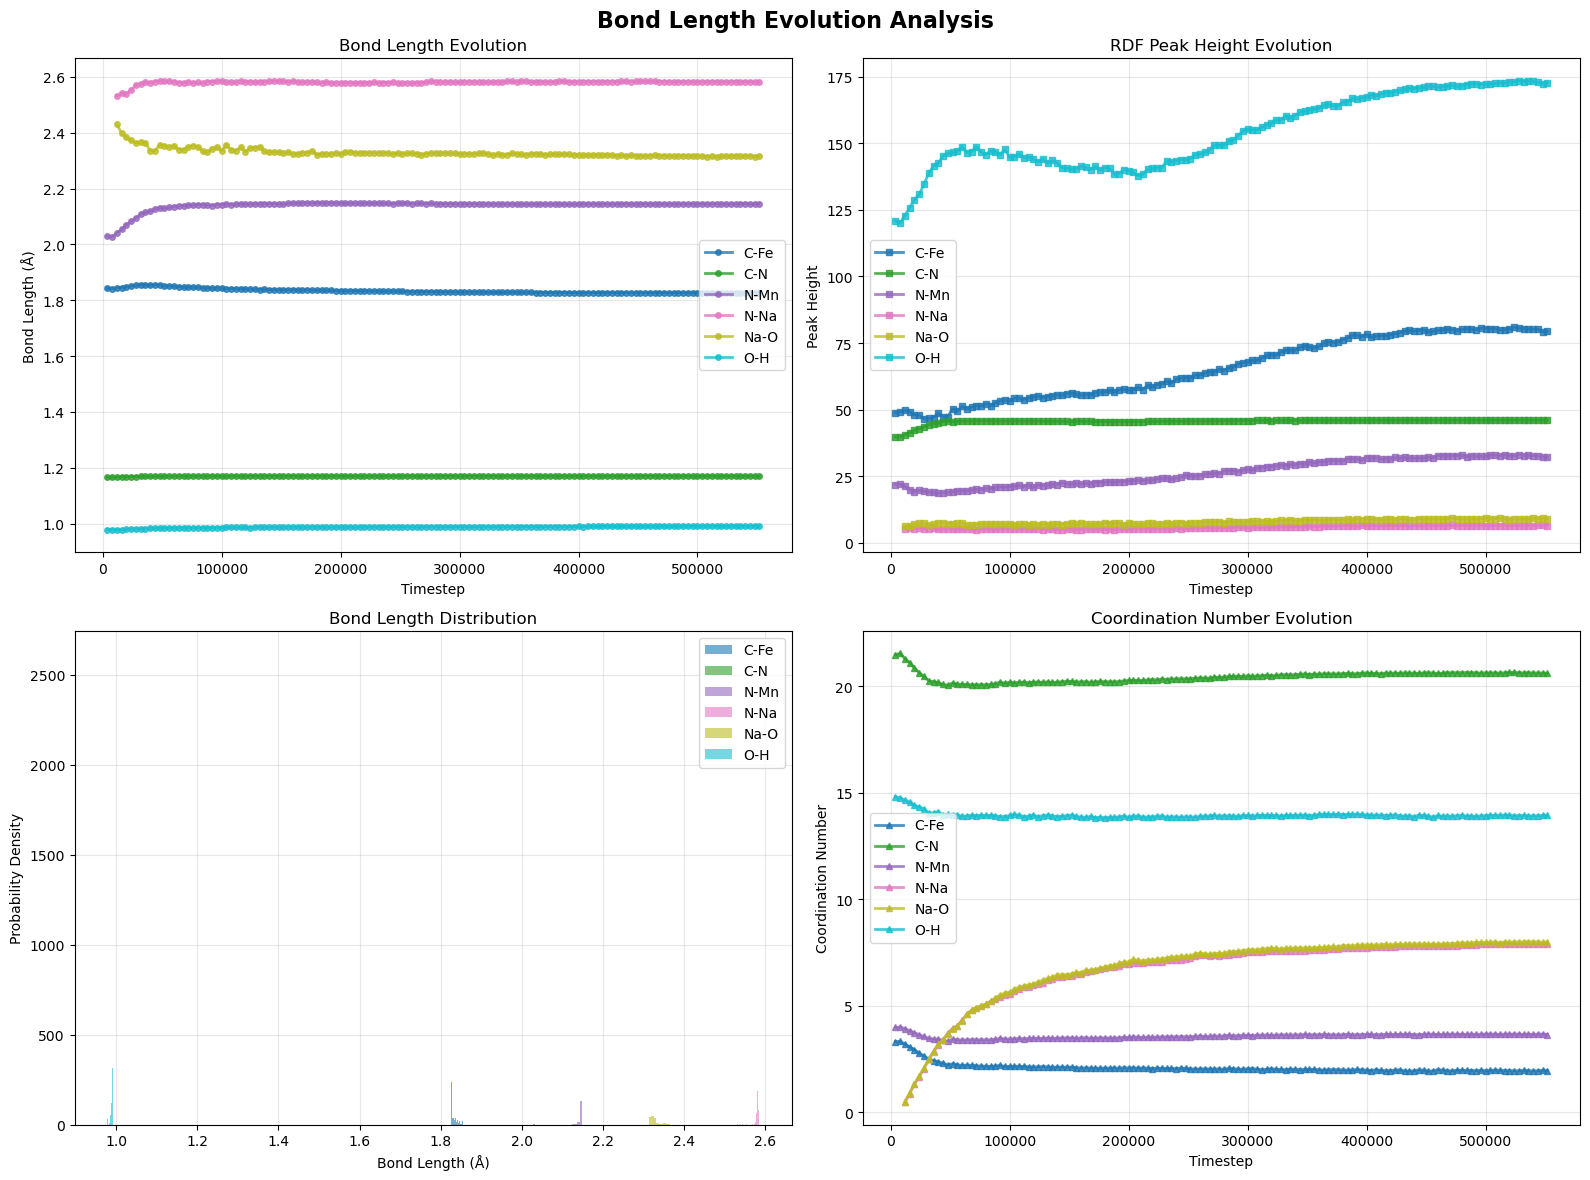


📋 RESULTS SUMMARY


,Pair,Timestep,Bond_Length,Peak_Height,Peak_Width,Coordination_Number
0,C-Fe,4000,1.842296,48.8082,0,3.32340
1,C-Fe,8000,1.842045,49.1197,0,3.32573
2,C-Fe,12000,1.843928,49.7482,0,3.20174
3,C-Fe,16000,1.845482,49.1988,0,3.06868
4,C-Fe,20000,1.847772,48.0112,0,2.94642
5,C-Fe,24000,1.850750,48.0146,0,2.77632
6,C-Fe,28000,1.852903,46.5145,0,2.64882
7,C-Fe,32000,1.855106,46.7379,0,2.49753
8,C-Fe,36000,1.854489,46.9925,0,2.43118
9,C-Fe,40000,1.853250,48.6794,0,2.37809


... and 814 more rows


In [12]:
analyzer = analyze_rdf_bonds('./hydration/RDF_lv20_vac/300K_rdf_Na_32_O_32.rdf', 
                           pair_names=['C-Fe','C-N','N-Mn','N-Na','Fe-Mn','Na-O', 'O-H'])

🚀 Starting RDF Bond Length Analysis
📁 Reading RDF file: ./hydration/RDF_lv20_vac/300K_rdf_Na_32_O_32.rdf
✅ Successfully read 138 timesteps
   Timesteps: [4000, 8000, 12000, 16000, 20000, 24000, 28000, 32000, 36000, 40000, 44000, 48000, 52000, 56000, 60000, 64000, 68000, 72000, 76000, 80000, 84000, 88000, 92000, 96000, 100000, 104000, 108000, 112000, 116000, 120000, 124000, 128000, 132000, 136000, 140000, 144000, 148000, 152000, 156000, 160000, 164000, 168000, 172000, 176000, 180000, 184000, 188000, 192000, 196000, 200000, 204000, 208000, 212000, 216000, 220000, 224000, 228000, 232000, 236000, 240000, 244000, 248000, 252000, 256000, 260000, 264000, 268000, 272000, 276000, 280000, 284000, 288000, 292000, 296000, 300000, 304000, 308000, 312000, 316000, 320000, 324000, 328000, 332000, 336000, 340000, 344000, 348000, 352000, 356000, 360000, 364000, 368000, 372000, 376000, 380000, 384000, 388000, 392000, 396000, 400000, 404000, 408000, 412000, 416000, 420000, 424000, 428000, 432000, 436000, 

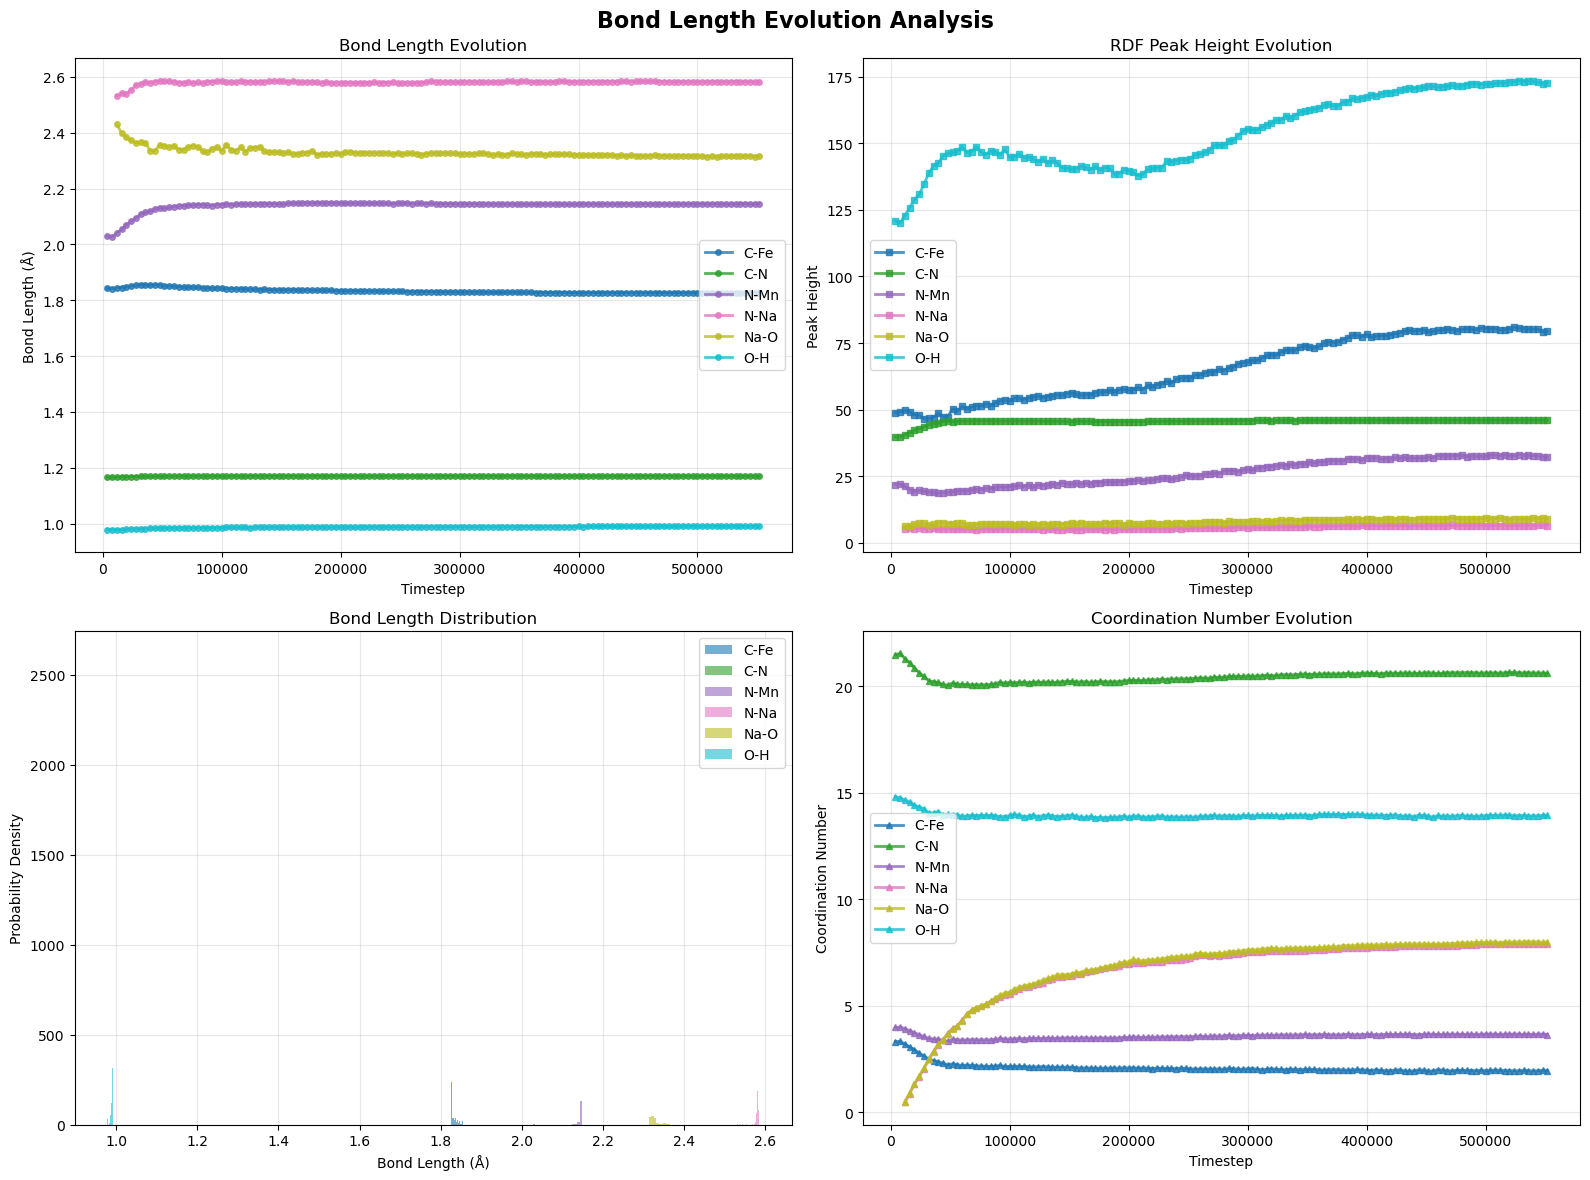


📋 RESULTS SUMMARY


,Pair,Timestep,Bond_Length,Peak_Height,Peak_Width,Coordination_Number
0,C-Fe,4000,1.842296,48.8082,0,3.32340
1,C-Fe,8000,1.842045,49.1197,0,3.32573
2,C-Fe,12000,1.843928,49.7482,0,3.20174
3,C-Fe,16000,1.845482,49.1988,0,3.06868
4,C-Fe,20000,1.847772,48.0112,0,2.94642
5,C-Fe,24000,1.850750,48.0146,0,2.77632
6,C-Fe,28000,1.852903,46.5145,0,2.64882
7,C-Fe,32000,1.855106,46.7379,0,2.49753
8,C-Fe,36000,1.854489,46.9925,0,2.43118
9,C-Fe,40000,1.853250,48.6794,0,2.37809


... and 814 more rows


In [12]:
analyzer = analyze_rdf_bonds('./hydration/RDF_lv20_vac/300K_rdf_Na_32_O_32.rdf', 
                           pair_names=['C-Fe','C-N','N-Mn','N-Na','Fe-Mn','Na-O', 'O-H'])

🚀 Starting RDF Bond Length Analysis
📁 Reading RDF file: ./hydration/RDF_lv16_E0_sf0.1_f0.1/300K_rdf_Na_32_O_32.rdf
✅ Successfully read 277 timesteps
   Timesteps: [4000, 8000, 12000, 16000, 20000, 24000, 28000, 32000, 36000, 40000, 44000, 48000, 52000, 56000, 60000, 64000, 68000, 72000, 76000, 80000, 84000, 88000, 92000, 96000, 100000, 104000, 108000, 112000, 116000, 120000, 124000, 128000, 132000, 136000, 140000, 144000, 148000, 152000, 156000, 160000, 164000, 168000, 172000, 176000, 180000, 184000, 188000, 192000, 196000, 200000, 204000, 208000, 212000, 216000, 220000, 224000, 228000, 232000, 236000, 240000, 244000, 248000, 252000, 256000, 260000, 264000, 268000, 272000, 276000, 280000, 284000, 288000, 292000, 296000, 300000, 304000, 308000, 312000, 316000, 320000, 324000, 328000, 332000, 336000, 340000, 344000, 348000, 352000, 356000, 360000, 364000, 368000, 372000, 376000, 380000, 384000, 388000, 392000, 396000, 400000, 404000, 408000, 412000, 416000, 420000, 424000, 428000, 432000

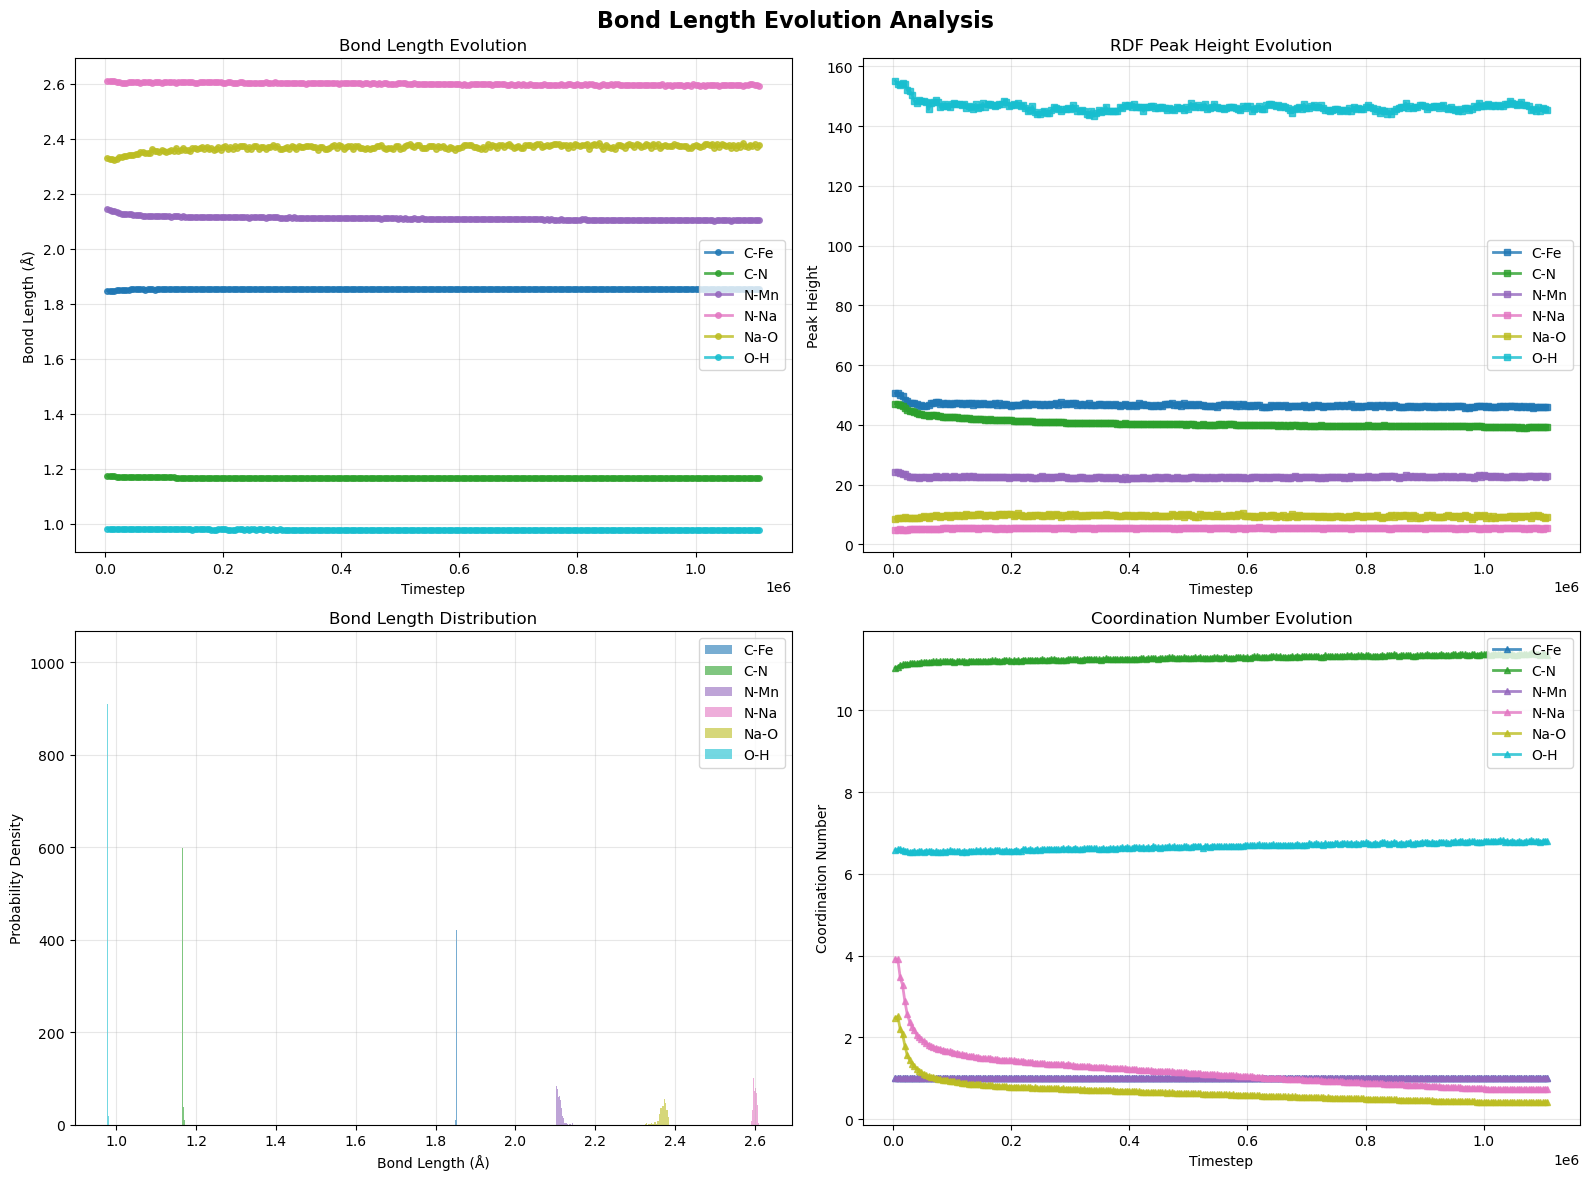


📋 RESULTS SUMMARY


,Pair,Timestep,Bond_Length,Peak_Height,Peak_Width,Coordination_Number
0,C-Fe,4000,1.847645,50.5978,0,1.0
1,C-Fe,8000,1.846831,50.7513,0,1.0
2,C-Fe,12000,1.848094,49.9671,0,1.0
3,C-Fe,16000,1.848294,49.5892,0,1.0
4,C-Fe,20000,1.849961,48.2639,0,1.0
5,C-Fe,24000,1.850699,47.8336,0,1.0
6,C-Fe,28000,1.850762,47.3040,0,1.0
7,C-Fe,32000,1.851582,47.4377,0,1.0
8,C-Fe,36000,1.851552,47.1648,0,1.0
9,C-Fe,40000,1.851918,47.0203,0,1.0


... and 1652 more rows


In [9]:
analyzer = analyze_rdf_bonds('./hydration/Nt_300/6/300K_rdf_Na_32_O_32.rdf', 
                           pair_names=['C-Fe','C-N','N-Mn','N-Na','Fe-Mn','Na-O', 'O-H'])

In [20]:
analyzer.save_results(filename='./hydration/bond_lv16_desodiation.csv')

💾 Results saved to ./hydration/bond_lv16_desodiation.csv


🚀 Starting RDF Bond Length Analysis
📁 Reading RDF file: ./hydration/lv16_hydration_2/300K_rdf_hydration_3_.rdf
✅ Successfully read 393 timesteps
   Timesteps: [2000, 4000, 6000, 8000, 10000, 12000, 14000, 16000, 18000, 20000, 22000, 24000, 26000, 28000, 30000, 32000, 34000, 36000, 38000, 40000, 42000, 44000, 46000, 48000, 50000, 52000, 54000, 56000, 58000, 60000, 62000, 64000, 66000, 68000, 70000, 72000, 74000, 76000, 78000, 80000, 82000, 84000, 86000, 88000, 90000, 92000, 94000, 96000, 98000, 100000, 102000, 104000, 106000, 108000, 110000, 112000, 114000, 116000, 118000, 120000, 122000, 124000, 126000, 128000, 130000, 132000, 134000, 136000, 138000, 140000, 142000, 144000, 146000, 148000, 150000, 152000, 154000, 156000, 158000, 160000, 162000, 164000, 166000, 168000, 170000, 172000, 174000, 176000, 178000, 180000, 182000, 184000, 186000, 188000, 190000, 192000, 194000, 196000, 198000, 200000, 202000, 204000, 206000, 208000, 210000, 212000, 214000, 216000, 218000, 220000, 222000, 22400

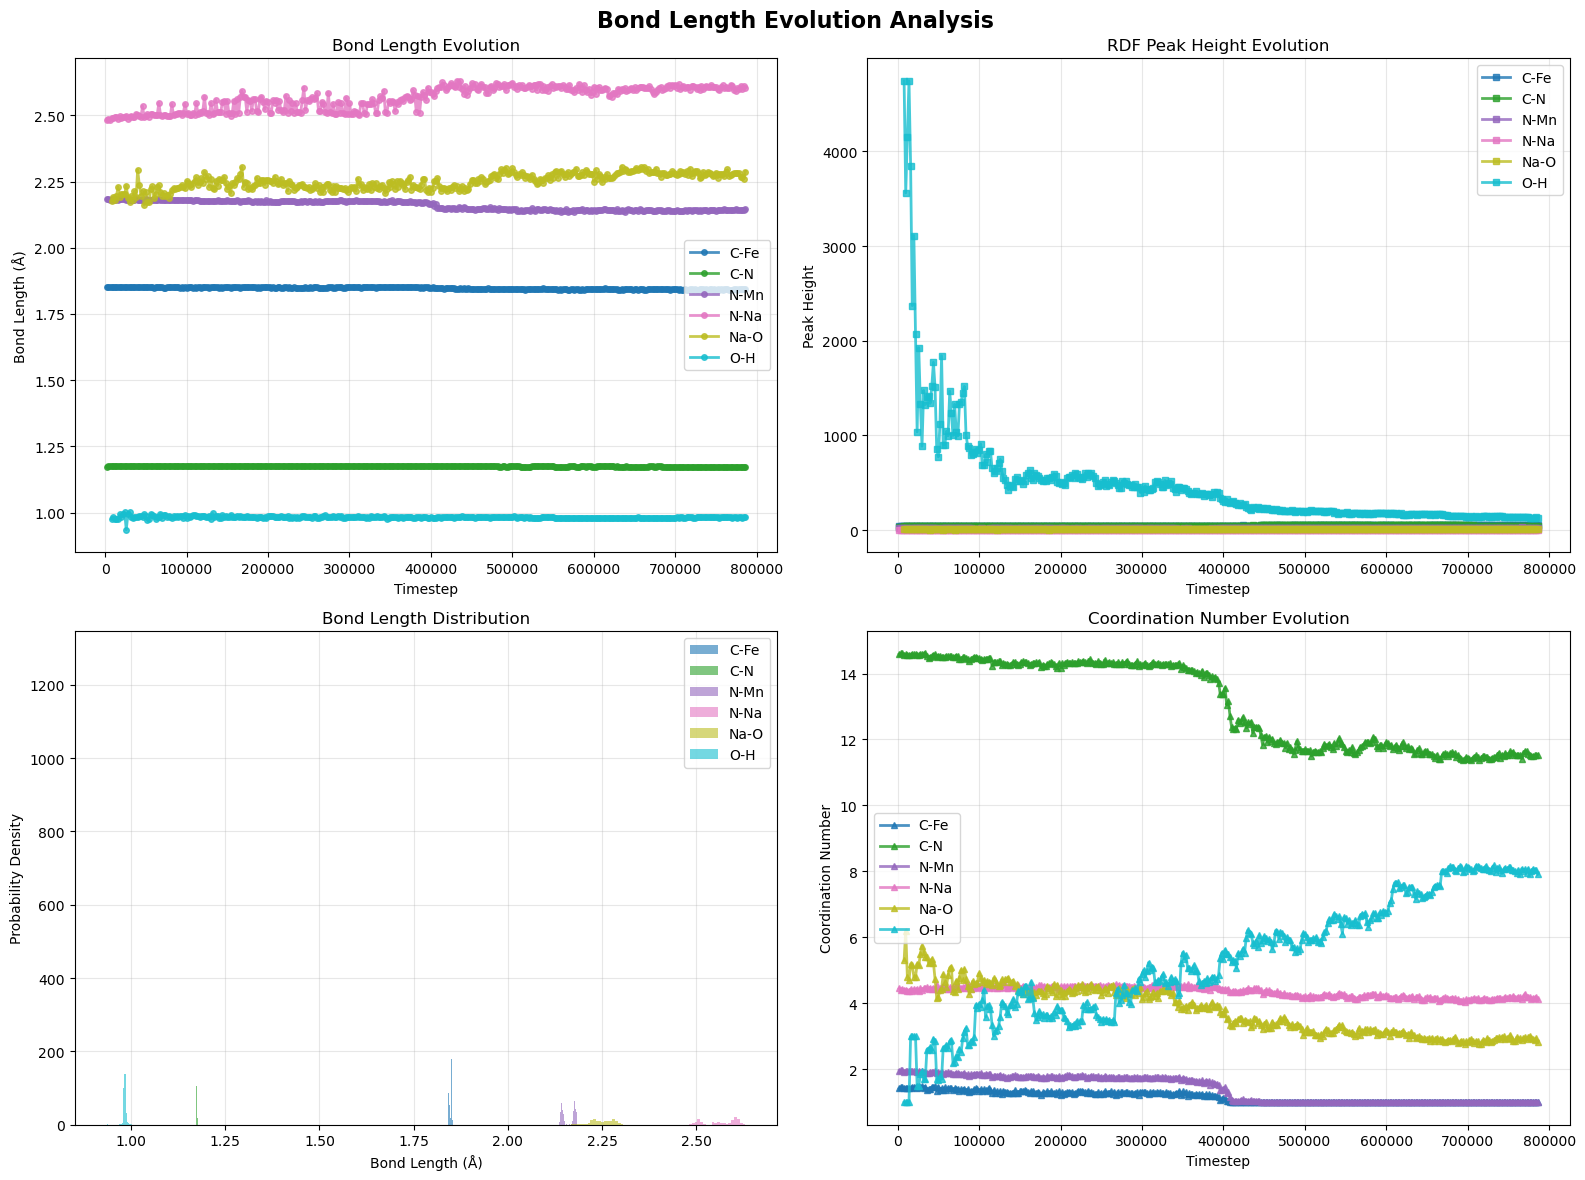


📋 RESULTS SUMMARY


,Pair,Timestep,Bond_Length,Peak_Height,Peak_Width,Coordination_Number
0,C-Fe,2000,1.853203,42.6099,0,1.42240
1,C-Fe,4000,1.852855,39.3110,0,1.46771
2,C-Fe,6000,1.851066,41.7534,0,1.45417
3,C-Fe,8000,1.852774,41.3707,0,1.43646
4,C-Fe,10000,1.852454,42.3887,0,1.44635
5,C-Fe,12000,1.852051,40.3896,0,1.42292
6,C-Fe,14000,1.852561,41.2365,0,1.44375
7,C-Fe,16000,1.852391,40.6841,0,1.43073
8,C-Fe,18000,1.852663,38.9375,0,1.46510
9,C-Fe,20000,1.851890,38.7943,0,1.45521


... and 2342 more rows


In [23]:
analyzer = analyze_rdf_bonds('./hydration/lv16_hydration_2/300K_rdf_hydration_3_.rdf', 
                           pair_names=['C-Fe','C-N','N-Mn','N-Na','Fe-Mn','Na-O', 'O-H'])

In [24]:
analyzer.save_results(filename='./hydration/bond_lv16_hydration.csv')

💾 Results saved to ./hydration/bond_lv16_hydration.csv


In [41]:
analyzer = analyze_rdf_bonds('../../../300K_rdf_final_5.rdf', 
                           pair_names=['C-Fe','C-N','N-Mn','N-Na','Fe-Mn'])

🚀 Starting RDF Bond Length Analysis
📁 Reading RDF file: ../../../300K_rdf_final_5.rdf
❌ Error: Could not find file ../../../300K_rdf_final_5.rdf


In [6]:
analyzer.save_results(filename='./hydration/bond_lv16_hydration_2.csv')

💾 Results saved to ./hydration/bond_lv16_hydration_2.csv


# Interface Analysis

In [11]:
def load_lammps_trajectory(filename):
    """Load multiple timesteps from LAMMPS dump file"""
    with open(filename, 'r') as f:
        lines = f.readlines()
    
    trajectory = []
    i = 0
    
    while i < len(lines):
        # Look for timestep marker
        if 'ITEM: TIMESTEP' in lines[i]:
            timestep = int(lines[i + 1].strip())
            i += 2
            
            # Find number of atoms
            while i < len(lines) and 'ITEM: NUMBER OF ATOMS' not in lines[i]:
                i += 1
            natoms = int(lines[i + 1].strip())
            i += 2
            
            # Find box bounds
            while i < len(lines) and 'ITEM: BOX BOUNDS' not in lines[i]:
                i += 1
            box_bounds = []
            for j in range(3):
                box_bounds.append(list(map(float, lines[i + 1 + j].split())))
            i += 4  # Skip box bounds lines
            
            # Find atoms section
            while i < len(lines) and 'ITEM: ATOMS' not in lines[i]:
                i += 1
            columns = lines[i].split()[2:]  # Extract column names
            i += 1
            
            # Read atom data
            atom_data = []
            atoms_read = 0
            while i < len(lines) and atoms_read < natoms:
                line = lines[i].strip()
                # Stop if we hit another ITEM (next timestep)
                if line.startswith('ITEM:'):
                    break
                if line:  # Skip empty lines
                    try:
                        atom_data.append(list(map(float, line.split())))
                        atoms_read += 1
                    except ValueError:
                        # Skip lines that can't be converted to float
                        pass
                i += 1
            
            trajectory.append({
                'timestep': timestep,
                'natoms': natoms,
                'box_bounds': box_bounds,
                'atoms': np.array(atom_data),
                'columns': columns
            })
        else:
            i += 1
    
    return trajectory

In [12]:
import re

# Function to read and parse LAMMPS log
def parse_lammps_free(file_path):
    data = {'Step': [], 'Temp': [], 'TotEng': [], 'Press': [], 'Volume': [], 'v_nNa': [], 'atoms': [], 'Mn_PE': [], 'Fe_PE': [] }

    with open(file_path, 'r', encoding='utf-8', errors='ignore') as file:
        for line in file:
            # Find thermo output section
            if re.match(r"^\s*Step\s+Temp\s+TotEng", line):
                # Skip header lines
                next(file)
                # Parse the actual data lines
                for data_line in file:
                    if re.match(r"^\s*\d+", data_line) and len(data_line.split())==6:
                        # Extract values (Assuming specific columns order here)
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['Temp'].append(float(values[1]))
                        data['TotEng'].append(float(values[2]))
                        data['Press'].append(float(values[3]))
                        data['Volume'].append(float(values[4]))
                        data['v_nNa'].append(float(values[5]))
                    elif re.match(r"^\s*\d+", data_line) and len(data_line.split())==7:
                        # Extract values (Assuming specific columns order here)
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['Temp'].append(float(values[1]))
                        data['TotEng'].append(float(values[2]))
                        data['Press'].append(float(values[3]))
                        data['Volume'].append(float(values[4]))
                        data['v_nNa'].append(float(values[5]))
                        data['atoms'].append(float(values[6]))
                    elif re.match(r"^\s*\d+", data_line) and len(data_line.split())==8:
                        # Extract values (Assuming specific columns order here)
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['Temp'].append(float(values[1]))
                        data['TotEng'].append(float(values[2]))
                        data['Press'].append(float(values[3]))
                        data['Volume'].append(float(values[4]))
                        data['v_nNa'].append(float(values[5]))
                        data['atoms'].append(float(values[6]))
                        data['Mn_PE'].append(float(values[7]))
                    elif re.match(r"^\s*\d+", data_line) and len(data_line.split())==9:
                        # Extract values (Assuming specific columns order here)
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['Temp'].append(float(values[1]))
                        data['TotEng'].append(float(values[2]))
                        data['Press'].append(float(values[3]))
                        data['Volume'].append(float(values[4]))
                        data['v_nNa'].append(float(values[5]))
                        data['atoms'].append(float(values[6]))
                        data['Mn_PE'].append(float(values[7]))
                        data['Fe_PE'].append(float(values[8]))
                    else:
                        break
                        
    return data

In [98]:
V_ls=[]
E_ls=[]
for i in range(4):
    data = parse_lammps_free(f'../../../interface/interface_sub2_{i+1}.log')
    V_ls.append(np.array(data['Volume'][:10]).mean())
    E_ls.append(np.array(data['TotEng'][:10]).mean())

In [74]:
EDFT=[]
supercell_ls=[]
number_atom_ls=[]
for i in range(10):
    filename = f'./interface/cal_interface_equil_{i+1}.cfg.0'
    E_DFT, supercell, F_DFT, S_DFT = load_multi_section_cfg_no_grade(filename)
    EDFT.append(E_DFT[0])
    supercell_ls.append(supercell[0])
    number_atom_ls.append(len(F_DFT[0]))

In [75]:
number_atom_ls = sorted(number_atom_ls)
number_atom_ls

[30720, 61440, 92160, 122880, 153600, 184320, 215040, 245760, 737280, 983040]

In [76]:
V_ls=[]
a_ls=[]
for i in range(10):
    a = supercell_ls[i][0]
    b = supercell_ls[i][1]
    c = supercell_ls[i][2]
    V_ls.append(np.abs(np.dot(a, np.cross(b, c))))
    a_ls.append(a[0])

In [72]:
a_ls = sorted(a_ls)
a_ls

[78.233821,
 155.772467,
 233.726348,
 312.584116,
 390.519405,
 466.475224,
 544.816451,
 621.57148,
 1867.984239,
 2494.466376]

In [77]:
V_ls = sorted(V_ls)
V_ls

[471967.72711832065,
 946242.0869335135,
 1418287.4725360272,
 1888239.7103929152,
 2365386.9653200177,
 2839160.4771039765,
 3310984.126751659,
 3785381.204533683,
 11326305.470492356,
 15158896.172333764]

In [78]:
EDFT = sorted(EDFT, reverse=True)
EDFT

[-244438.87054281213,
 -488899.391907507,
 -733382.5305727868,
 -977884.3225710212,
 -1222321.5800197856,
 -1466771.0936389798,
 -1711259.3830169172,
 -1955692.8232851091,
 -5867371.055000795,
 -7823017.00862354]

In [50]:
E_half*size_ls

array([ -245578.81168557,  -491157.62337113,  -736736.4350567 ,
        -982315.24674226, -1227894.05842783, -1473472.87011339,
       -1719051.68179896, -1964630.49348452, -5893891.48045357,
       -7858521.97393809])

Text(0, 0.5, 'Excess energy (eV/Å^3)')

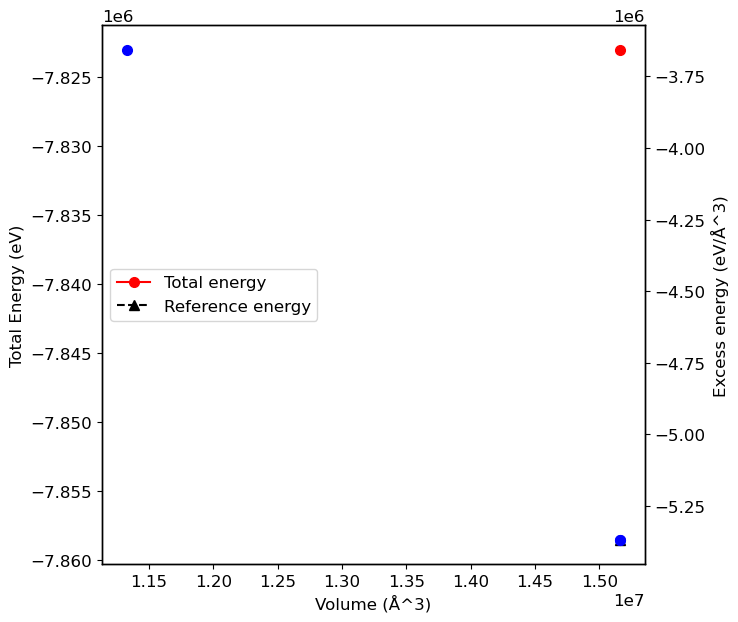

In [44]:
E_full = -996.993784015657*4*8*8
#-997.276659384399*4*8*8
#-252768.54499999998
E_0 = -921.590682277823*4*8*8
#-922.893254944726*4*8*8
#-233927.607

E_half = (E_full+E_0)/2
size_ls=np.array([1,2,3,4,5,6,7,8,24,32])
E_ex = []
plt.figure(figsize=(singlecol*2, singlecol*2))

plt.plot(V_ls[9:], EDFT[9:], '-o',color='r', label='Total energy')
plt.plot(V_ls[9:], E_half*size_ls[9:], '--', marker='^', color='black', label='Reference energy')
    
plt.xlabel('Volume (Å^3)')
plt.ylabel('Total Energy (eV)')
plt.legend(loc='center left')
plt2 = plt.twinx()

for i in range(8,10):
    plt2.scatter(V_ls[i], (EDFT[i]-E_half*(i+1)),  color='b')
    E_ex.append(EDFT[i]-E_half*(i+1))
plt2.scatter(V_ls[i], (EDFT[i]-E_half*(i+1)),  color='b', label='Excess energy')

plt2.set_ylabel('Excess energy (eV/Å^3)')

a_fit = 5.739810e+00 ± 1.13e+00 (mJ/m^2)
b_fit = 3.747604e+01 ± 2.18e-02 (MJ/m^3)
R² = 0.999997


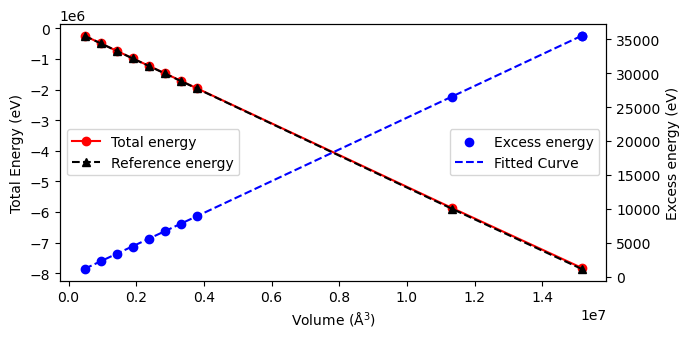

In [81]:
E_full = -996.993784015657*4*8*8
#-997.276659384399*4*8*8
#-252768.54499999998
E_0 = -921.590682277823*4*8*8
#-922.893254944726*4*8*8
#-233927.607

E_half = (E_full+E_0)/2
size_ls=np.array([1,2,3,4,5,6,7,8,24,32])
E_ex = []
plt.figure(figsize=(singlecol*2, singlecol))

plt.plot(V_ls, EDFT, '-o',color='r', label='Total energy')
plt.plot(V_ls, E_half*size_ls, '--', marker='^', color='black', label='Reference energy')
    
plt.xlabel(r'Volume (Å$^3$)')
plt.ylabel('Total Energy (eV)')
plt.legend(loc='center left')
plt2 = plt.twinx()

for i in range(10):
    plt2.scatter(V_ls[i], (EDFT[i]-E_half*size_ls[i]),  color='b')
    E_ex.append(EDFT[i]-E_half*size_ls[i])
plt2.scatter(V_ls[i], (EDFT[i]-E_half*size_ls[i]),  color='b', label='Excess energy')

plt2.set_ylabel('Excess energy (eV)')

x_data = np.array(V_ls)
y_data = np.array(E_ex)

popt, pcov = curve_fit(exp_func, x_data, y_data, p0=(1, 1))
a_fit, b_fit = popt
perr = np.sqrt(np.diag(pcov))
a_err, b_err = perr
residuals = y_data - exp_func(x_data, a_fit, b_fit)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((y_data - np.mean(y_data))**2)
r_squared = 1 - (ss_res / ss_tot)

x_fit = np.linspace(x_data.min(), x_data.max(), 100)
y_fit = exp_func(x_fit, a_fit, b_fit)
plt2.plot(x_fit, y_fit, 'b--', label='Fitted Curve')
plt2.legend(loc='center right')

plt.tight_layout()
print(f"a_fit = {a_fit/(6108.5*2)*1602.18:.6e} ± {a_err/(6108.5*2)*1602.18:.2e} (mJ/m^2)")
print(f"b_fit = {b_fit*1.602176634e4:.6e} ± {b_err*1.602176634e4:.2e} (MJ/m^3)")
print(f"R² = {r_squared:.6f}")
plt.tight_layout()
plt.savefig('./interface'+'.svg', bbox_inches='tight')

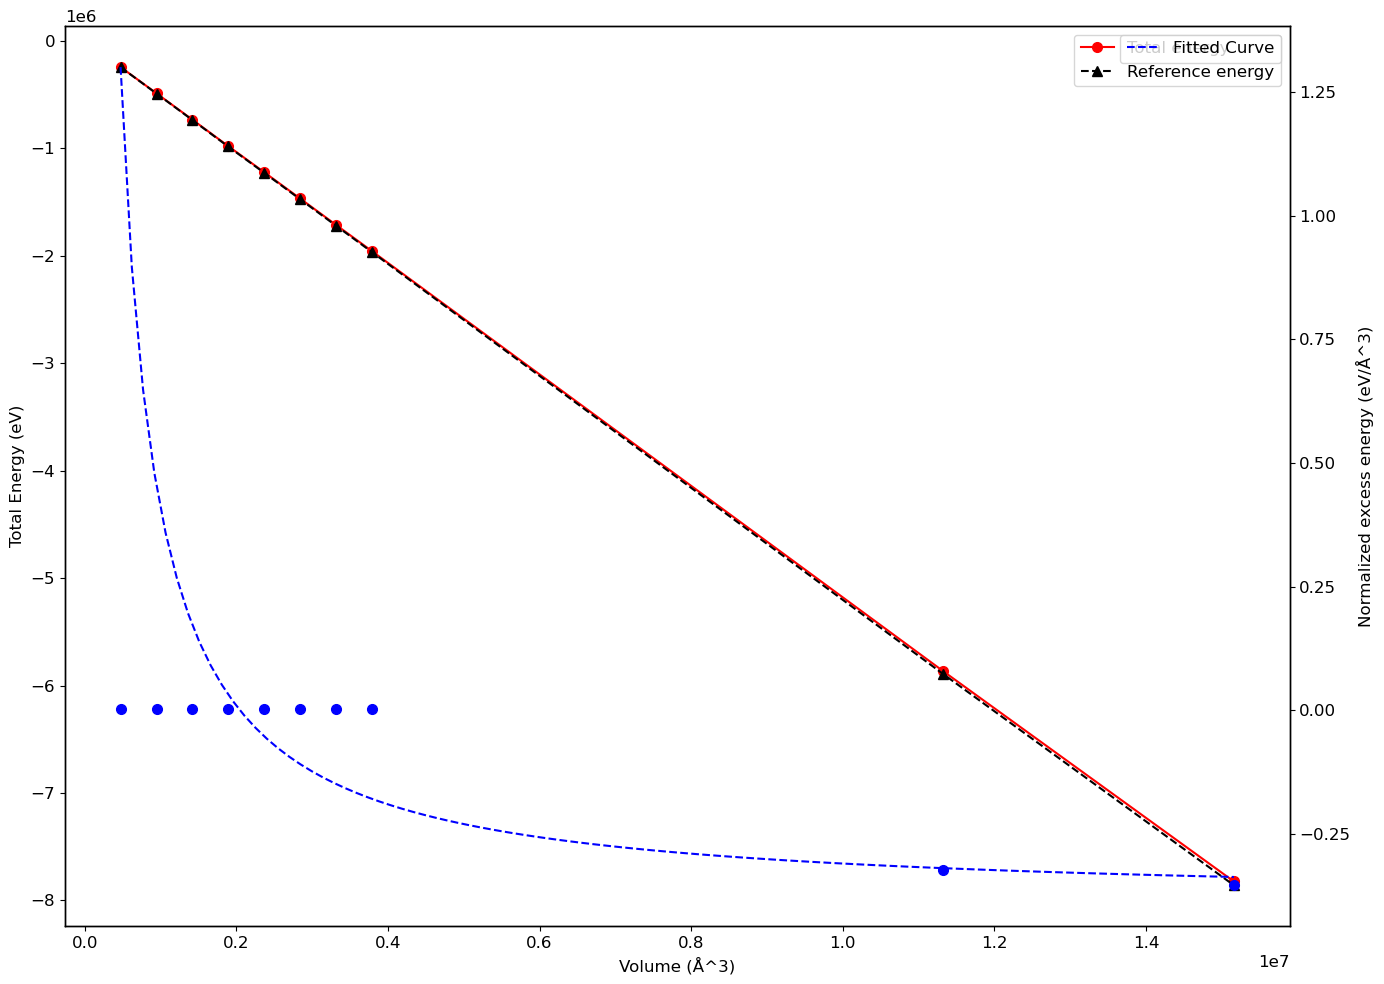

In [52]:
E_full = -996.993784015657*4*8*8
#-997.276659384399*4*8*8
#-252768.54499999998
E_0 = -921.590682277823*4*8*8
#-922.893254944726*4*8*8
#-233927.607

E_half = (E_full+E_0)/2

E_ex = []
plt.figure()

plt.plot(V_ls, EDFT, '-o',color='r', label='Total energy')
plt.plot(V_ls, E_half*size_ls, '--', marker='^', color='black', label='Reference energy')
    
plt.xlabel('Volume (Å^3)')
plt.ylabel('Total Energy (eV)')
plt.legend()
plt2 = plt.twinx()

for i in range(10):
    plt2.scatter(V_ls[i], (EDFT[i]-E_half*(i+1))/V_ls[i],  color='b')
    E_ex.append(EDFT[i]-E_half*(i+1))

plt2.set_ylabel('Normalized excess energy (eV/Å^3)')

x_data = np.array(V_ls)
y_data = np.array(E_ex)

popt, pcov = curve_fit(exp_func, x_data, y_data, p0=(1, 1))
a_fit, b_fit = popt
perr = np.sqrt(np.diag(pcov))
a_err, b_err = perr
residuals = y_data - exp_func(x_data, a_fit, b_fit)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((y_data - np.mean(y_data))**2)
r_squared = 1 - (ss_res / ss_tot)

x_fit = np.linspace(x_data.min(), x_data.max(), 100)
y_fit = exp_func(x_fit, a_fit, b_fit)
plt2.plot(x_fit, y_fit/x_fit, 'b--', label='Fitted Curve')
plt2.legend()

plt.tight_layout()

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.optimize import curve_fit

def exp_func(x, a, b):
    return a + b * x

# Prepare your data
x_data = np.array([471967.72711832065,  946242.0869335135, 1418287.4725360272, 2365386.9653200177, 2839160.4771039765])
#np.array(V_ls)[0,1,4,5,6] #[:4]
y_data = np.array([1139.9411427533196, 2258.2314636239316,3353.9044839096023, 5572.478408041643, 6701.776474412996])
#E_ex[0,1,4,5,6 ]#[:4]
popt, pcov = curve_fit(exp_func, x_data, y_data, p0=(1, 1))
a_fit, b_fit = popt
perr = np.sqrt(np.diag(pcov))
a_err, b_err = perr
residuals = y_data - exp_func(x_data, a_fit, b_fit)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((y_data - np.mean(y_data))**2)
r_squared = 1 - (ss_res / ss_tot)

In [139]:
a_fit, b_fit, a_err, b_err,r_squared

(32.145588695869684,
 0.002346163299115002,
 8.135437726027908,
 4.440157205034611e-06,
 0.9999892552595968)

In [140]:
a_fit, b_fit, a_err, b_err,r_squared

(32.145588695869684,
 0.002346163299115002,
 8.135437726027908,
 4.440157205034611e-06,
 0.9999892552595968)

In [141]:
b_fit #eV/A^3

0.002346163299115002

In [142]:
b_fit*1.602176634e4 #MJ/m^3

37.58968017390409

In [143]:
print('E_excess',E_ex)
print("E_strain",np.array(V_ls)*b_fit)
print('E_interfacial',E_ex-np.array(V_ls)*b_fit)

E_excess [1139.9411427533196, 2258.2314636239316, 3353.9044839096023, 4430.924171240651, 5572.478408041643, 6701.776474412996, 7792.2987820410635, 8937.670199414482]
E_strain [1107.31335973 2220.03845644 3327.53401566 4430.11870846 5549.58408624
 6661.13411168 7768.10944214 8881.12245524]
E_interfacial [32.62778302 38.19300718 26.37046825  0.80546279 22.8943218  40.64236273
 24.1893399  56.54774418]


In [144]:
(E_ex-np.array(V_ls)*b_fit)/(6108.5*2)*1602.18 # mj/m^2

array([4.27892129, 5.0087642 , 3.4583152 , 0.1056312 , 3.00244123,
       5.32998123, 3.17227442, 7.41586844])

In [145]:
a_fit/(6108.5*2)*1602.18

4.215684644081893

In [ ]:
gamma_ls=[]
for i in range(8):
    gamma_ls.append(E_ex-np.array(V_ls)*b_fitYour /(6108.5*2)*1602.18)

In [ ]:
gamma_ls

## 1

In [ ]:
%matplotlib widget

In [ ]:
singlecol=3.5

In [ ]:
plt.figure(figsize=(singlecol*2, singlecol*0.9), dpi=200)
for j in range(4):
    trac = load_lammps_trajectory(f'../../../interface/dump.Mn_pe_atom_sub_{j+1}.txt')
    for i in [26]:
        x = trac[i]['atoms'][:,2]
        y = trac[i]['atoms'][:,-1]
        plt.scatter(x,y, label=f'{j}', alpha=0.05)
for j in range(4,8):
    trac = load_lammps_trajectory(f'../../../interface/dump.400K_Mn_pe_atom_sub_{j+1}.txt')
    for i in [1]:
        x = trac[i]['atoms'][:,2]
        y = trac[i]['atoms'][:,-1]
        plt.scatter(x,y, label=f'{j}', alpha=0.05)
plt.legend()
plt.xlabel('Lx (A)')
plt.ylabel('E(Fe) (eV)')
#plt.xlim(320-20,320+20)
plt.ylim(-4600,2000)

In [ ]:
trac = load_lammps_trajectory('../../../interface/dump.Mn_pe_atom_sub_3.txt')
plt.figure(figsize=(singlecol*2, singlecol*0.9), dpi=200)

for i in [26]:
    x = trac[i]['atoms'][:,2]
    y = trac[i]['atoms'][:,-1]
    plt.scatter(x,y, label=f'Timestep {i*4000}', alpha=0.1)
plt.legend()
plt.xlabel('Lx (A)')
plt.ylabel('E(Fe) (eV)')
#plt.xlim(160-20,160+20)
plt.ylim(-4600,2000)

In [ ]:
trac = load_lammps_trajectory('../../../interface/dump.Mn_pe_atom_sub_2.txt')
plt.figure(figsize=(singlecol*2, singlecol*0.9), dpi=200)

for i in [26]:
    x = trac[i]['atoms'][:,2]
    y = trac[i]['atoms'][:,-1]
    plt.scatter(x,y, label=f'Timestep {i*4000}', alpha=0.1)
plt.legend()
plt.xlabel('Lx (A)')
plt.ylabel('E(Fe) (eV)')
#plt.xlim(80-20,80+20)
plt.ylim(-4600,2000)

In [ ]:
trac = load_lammps_trajectory('../../../interface/dump.Mn_pe_atom_sub_1.txt')
plt.figure(figsize=(singlecol*2, singlecol*0.9), dpi=200)

for i in [26]:
    x = trac[i]['atoms'][:,2]
    y = trac[i]['atoms'][:,-1]
    plt.scatter(x,y, label=f'Timestep {i*4000}', alpha=0.1)
plt.legend()
plt.xlabel('Lx (A)')
plt.ylabel('E(Fe) (eV)')
#plt.xlim(40-20,40+20)
plt.ylim(-4600,2000)

In [ ]:
trac = load_lammps_trajectory('../../../interface/dump.Fe_pe_atom_1.txt')
plt.figure()

for i in range(0,26,2):
    x = trac[i]['atoms'][:,2]
    y = trac[i]['atoms'][:,-1]
    plt.scatter(x,y, label=f'Timestep {i*4000}', alpha=0.5)
#plt.legend()
plt.xlabel('Lx (A)')
plt.ylabel('E(Fe) (eV)')
plt.xlim(40,80)

In [ ]:
filename = '../../../interface/cal_interface_equil_2.cfg.0'
E_DFT, supercell, F_DFT, S_DFT = load_multi_section_cfg_no_grade(filename)
F_DFT = np.array(F_DFT, dtype=object)
f = np.concatenate([arr[:,5:].flatten() for arr in F_DFT])
x = np.concatenate([arr[:,2].flatten() for arr in F_DFT])
y = np.concatenate([arr[:,3].flatten() for arr in F_DFT])
z = np.concatenate([arr[:,4].flatten() for arr in F_DFT])
fx = np.concatenate([arr[:,5].flatten() for arr in F_DFT])

In [ ]:
from scipy import stats
import math
FDFT = []
for j in range(len(x)):
    FDFT.append(math.sqrt(np.linalg.norm(f[3*j : 3*j+3])))

In [ ]:
len(FDFT), x.shape

In [ ]:
plt.figure()
x_flat = x.flatten()
plt.scatter(x_flat,FDFT, alpha=0.01)
plt.xlabel('Lx (A)')
plt.ylabel('E(Fe) (eV)')
#plt.xlim(40,80)

## 2

In [ ]:
trac = load_lammps_trajectory('../../../interface/dump.Mn_pe_atom_2.txt')
plt.figure()

for i in range(0,26,2):
    x = trac[i]['atoms'][:,2]
    y = trac[i]['atoms'][:,-1]
    plt.scatter(x,y, label=f'Timestep {i*4000}', alpha=0.5)
#plt.legend()
plt.xlabel('Lx (A)')
plt.ylabel('E(Fe) (eV)')
plt.xlim(90,130)

In [ ]:
trac = load_lammps_trajectory('../../../interface/dump.Fe_pe_atom_2.txt')
plt.figure()

for i in range(0,26,2):
    x = trac[i]['atoms'][:,2]
    y = trac[i]['atoms'][:,-1]
    plt.scatter(x,y, label=f'Timestep {i*4000}', alpha=0.2)
#plt.legend()
plt.xlabel('Lx (A)')
plt.ylabel('E(Fe) (eV)')
plt.xlim(100,130)

## 3

In [ ]:
trac = load_lammps_trajectory('../../../interface/dump.Mn_pe_atom_3.txt')
plt.figure()

for i in range(0,26,2):
    x = trac[i]['atoms'][:,2]
    y = trac[i]['atoms'][:,-1]
    plt.scatter(x,y, label=f'Timestep {i*4000}', alpha=0.2)
#plt.legend()
plt.xlabel('Lx (A)')
plt.ylabel('E(Fe) (eV)')
#plt.xlim(200,260)

In [ ]:
trac = load_lammps_trajectory('../../../interface/dump.Mn_pe_atom_3.txt')
plt.figure()

for i in range(0,55,5):
    x = trac[i]['atoms'][:,2]
    y = trac[i]['atoms'][:,-1]
    plt.scatter(x,y, label=f'Timestep {i*4000}', alpha=0.2)
#plt.legend()
plt.xlabel('Lx (A)')
plt.ylabel('E(Fe) (eV)')

## 4

In [ ]:
trac = load_lammps_trajectory('../../../interface/dump.Mn_pe_atom_4.txt')
plt.figure()

for i in range(0,25,5):
    x = trac[i]['atoms'][:,2]
    y = trac[i]['atoms'][:,-1]
    plt.scatter(x,y, label=f'Timestep {i*4000}', alpha=0.2)
#plt.legend()
plt.xlabel('Lx (A)')
plt.ylabel('E(Fe) (eV)')
plt.xlim(400,500)

In [ ]:
trac = load_lammps_trajectory('../../../interface/dump.Mn_pe_atom_3.txt')
plt.figure()

for i in range(0,25,2):
    x = trac[i]['atoms'][:,2]
    y = trac[i]['atoms'][:,-1]
    plt.scatter(x,y, label=f'Timestep {i*4000}', alpha=0.2)
#plt.legend()
plt.xlabel('Lx (A)')
plt.ylabel('E(Fe) (eV)')
plt.xlim(200,260)

# Hydration Na CN Analysis

### O_32

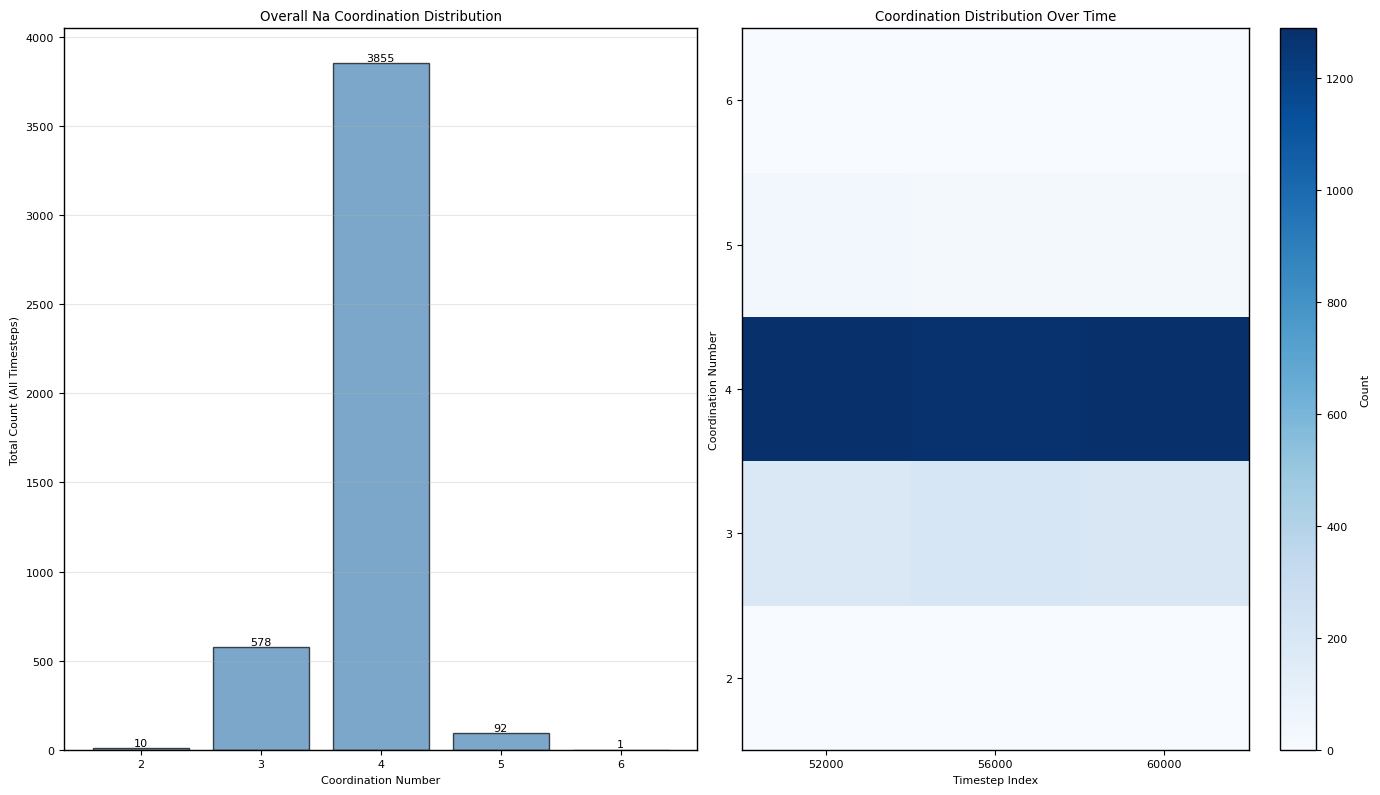

In [4]:
filename = './hydration/400_diffusion_20_MTP/400K_NaN_coord_28_32.txt'
sections = parse_coordination_file(filename)
na_stats = get_na_coordination_stats(section)
plot_detailed_distribution(sections)

In [5]:
filename = './hydration/400_diffusion_20_MTP/400K_ONa_coord_28_32.txt'
sections = parse_coordination_file(filename)
na_stats = get_na_coordination_stats(section)
plot_detailed_distribution(sections)

No Na coordination data found


In [19]:
for i in range(1):
    np.save(f'./hydration/400_diffusion_20_MTP/400K_NaN_coord_{Na_ls[i]}_{O_ls[i]}.txt', CN_ls[i])

NameError: name 'CN_ls' is not defined

In [60]:
CN_ls

[array([0, 1, 1, 1, 2, 1, 1, 0, 1, 1, 1, 2, 1, 1, 1, 2, 0, 1, 1, 0, 1, 0,
        0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
        1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0,
        1, 0, 1, 1, 1, 0, 1, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
        1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 2, 0, 0, 0, 0, 0, 1, 1, 1, 1,
        1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 2, 0, 1, 1, 0, 0, 1, 1, 1,
        1, 2, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1,
        1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 2, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1,
        0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1]),
 array([0, 1, 0, 0, 0, 0, 0, 2, 1, 1, 0, 0, 1, 1, 0, 2, 0, 2, 0, 1, 0, 0,
        1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 2, 2, 1, 0, 0, 1, 2,
        1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 2, 1,
        1, 1, 1, 0, 1, 0, 2, 1, 1, 0, 1, 1, 0, 0

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

### Load Na-O coordination data ###
Na_ls = [4, 16, 28, 4, 16, 28, 4, 16, 28]
O_ls = [4, 4, 4, 16, 16, 16, 32, 32, 32]

CN_O_ls = []
for i in range(9):
    data = np.load(f'./hydration/400_diffusion_4/400K_NaO_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_ls.append(data)

### Na-N file info ###
CN_N_ls = []
for i in range(9):
    data = np.load(f'./hydration/400_diffusion_4/400K_NaN_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_ls.append(data)

### Convert Na-O to coordination counts ###
def get_coord_counts_from_array(coord_array):
    """Count occurrences of each coordination number"""
    counter = Counter(coord_array)
    return counter

coord_data_O = []
all_coord_numbers_O = set()

for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_O_ls[i])
    all_coord_numbers_O.update(coord_counts.keys())
    coord_data_O.append(coord_counts)

for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_N_ls[i])
    all_coord_numbers_N.update(coord_counts.keys())
    coord_data_N.append(coord_counts)

### Get Na-N coordination counts ###
def get_coord_counts(filename):
    sections = parse_coordination_file(filename)
    timesteps = sorted(sections.keys())
    coords = []
    for timestep in timesteps:
        section = sections[timestep]
        na_atoms = [atom for atom in section['atoms'] if atom['type'] == na_type]
        coords.extend([atom['coordination'] for atom in na_atoms])
    counter = Counter(coords)
    return counter

coord_data_N = []
all_coord_numbers_N = set()

for filename, color, label in file_infos:
    coord_counts = get_coord_counts(filename)
    all_coord_numbers_N.update(coord_counts.keys())
    coord_data_N.append((coord_counts, color, label))

### Combine all coordination numbers ###
all_coord_numbers = sorted(all_coord_numbers_N | all_coord_numbers_O)
x = np.arange(len(all_coord_numbers))
width = 0.12  # Narrower to fit 6 bars

### Plotting ###
fig, ax = plt.subplots(figsize=(singlecol, singlecol), dpi=300)

# Plot Na-O coordination (hatched bars) - use same indices as Na-N
indices_to_plot = [2, 1, 0]  # Corresponds to Na=28,16,4 with O=4
colors = ['steelblue', 'orange', 'red']  # Match the order: 28, 16, 4

for j, i in enumerate(indices_to_plot):
    counts = [coord_data_O[i].get(cn, 0) for cn in all_coord_numbers]
    offset = x + (j + 0.5) * width
    _, color, label = file_infos[j]  # Use j instead of 2-j
    ax.bar(offset, counts, width=width, color=color, edgecolor='black',
           label=f'Na-O {label}', alpha=0.6, hatch='//')

# Plot Na-N coordination (solid bars)
for i, (coord_counts, color, label) in enumerate(coord_data_N):
    counts = [coord_counts.get(cn, 0) for cn in all_coord_numbers]
    offset = x + (i - 1.5) * width
    ax.bar(offset, counts, width=width, color=color, edgecolor='black', 
           label=f'Na-N', alpha=0.8)
    
# Axis & labels
ax.set_xticks(x)
ax.set_xticklabels(all_coord_numbers)
ax.set_xlabel('Coordination Number')
ax.set_ylabel('Percentage')
ax.set_xlim(-0.5,6.5)
ax.set_ylim(0,1500)
ax.legend(fontsize=6, frameon=False, loc='best', ncol=2)
plt.tight_layout()
#plt.savefig('./hydration/400K_NaN_NaO_coord_combined_1.png', dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'CN_ls' is not defined

In [10]:
coord_data_N[i]

Counter({3: 70, 5: 40, 4: 84, 1: 8, 2: 10, 6: 3, 0: 1})

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

### Load Na-O coordination data ###
Na_ls = [28]
O_ls = [32]

CN_O_ls = []
for i in range(1):
    data = np.load(f'./hydration/400_diffusion_20_MTP/400K_NaO_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_O_ls.append(data)  # Fixed: was CN_ls

### Load Na-N coordination data ###
CN_N_ls = []
for i in range(1):
    data = np.load(f'./hydration/400_diffusion_20_MTP/400K_NaN_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_N_ls.append(data)  # Fixed: was CN_ls

### Convert to coordination counts ###
def get_coord_counts_from_array(coord_array):
    """Count occurrences of each coordination number"""
    counter = Counter(coord_array.flatten())  # Added flatten() for safety
    return counter

# Process Na-O data
coord_data_O = []
all_coord_numbers_O = set()
for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_O_ls[i])
    all_coord_numbers_O.update(coord_counts.keys())
    coord_data_O.append(coord_counts)

# Process Na-N data
coord_data_N = []
all_coord_numbers_N = set()
for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_N_ls[i])
    all_coord_numbers_N.update(coord_counts.keys())
    coord_data_N.append(coord_counts)

### Define file info for plotting ###
# Create labels for the 9 conditions
colors = ['red', 'orange', 'steelblue'] * 3  # Repeat for each O condition
file_infos = []
for i in range(9):
    label = f'x = {Na_ls[i]/16}, y = {O_ls[i]/16}'
    file_infos.append((None, colors[i % 3], label))

### Combine all coordination numbers ###
all_coord_numbers = sorted(all_coord_numbers_N | all_coord_numbers_O)
x = np.arange(len(all_coord_numbers))
width = 0.12  # Narrower to fit 6 bars

### Plotting ###
singlecol = 3.5  # Define figure width in inches
fig, ax = plt.subplots(figsize=(singlecol, singlecol), dpi=300)

indices_O_to_plot = [0,1,2]  # Corresponds to Na=28,16,4 with O=4
indices_N_to_plot = [0,1,2]  # Corresponds to Na=28,16,4 with O=4
# Plot Na-O coordination (hatched bars)
for j, i in enumerate(indices_O_to_plot):
    raw_counts = coord_data_O[i]
    total = CN_O_ls[i].shape[0]
    # Divide each individual count by the total here:
    counts = [raw_counts.get(cn, 0) / total for cn in all_coord_numbers]
    
    offset = x + (j + 0.5) * width
    _, color, label = file_infos[i]
    ax.bar(offset, counts, width=width, color=color, edgecolor='black',
           label=f'Na-O', alpha=0.6, hatch='///')

# Updated Na-N loop
for j, i in enumerate(indices_N_to_plot):
    raw_counts = coord_data_N[i]
    total = CN_N_ls[i].shape[0]
    # Divide each individual count by the total here:
    counts = [raw_counts.get(cn, 0) / total for cn in all_coord_numbers]
    
    offset = x + (j - 1.5) * width
    _, color, label = file_infos[i]
    ax.bar(offset, counts, width=width, color=color, edgecolor='black', 
           label=f'Na-N {label}', alpha=0.8)
    
# Axis & labels
ax.set_xticks(x)
ax.set_xticklabels(all_coord_numbers)
ax.set_xlabel('Coordination Number')
ax.set_ylabel('Fraction')
ax.set_xlim(-0.5, 6.5)
ax.set_ylim(0, 1)
ax.legend(fontsize=6.8, frameon=False, loc='best', ncol=2)
plt.tight_layout()
#plt.savefig('./hydration/400K_NaN_NaO_coord_combined_1.svg', dpi=300, bbox_inches='tight')
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: './hydration/400_diffusion_20_MTP/400K_NaO_coord_28_32.txt.npy'

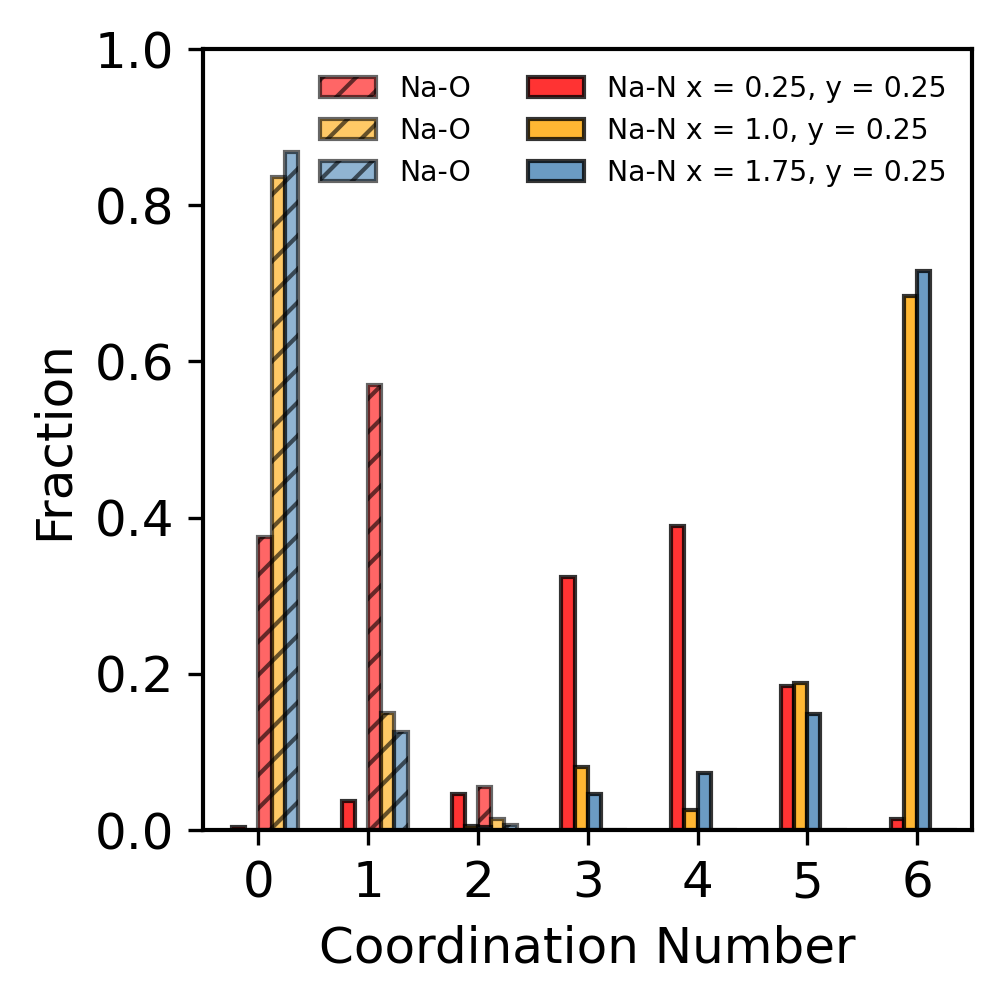

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

### Load Na-O coordination data ###
Na_ls = [4, 16, 28, 4, 16, 28, 4, 16, 28]
O_ls = [4, 4, 4, 16, 16, 16, 32, 32, 32]

CN_O_ls = []
for i in range(9):
    data = np.load(f'./hydration/400_diffusion_4/400K_NaO_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_O_ls.append(data)  # Fixed: was CN_ls

### Load Na-N coordination data ###
CN_N_ls = []
for i in range(9):
    data = np.load(f'./hydration/400_diffusion_4/400K_NaN_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_N_ls.append(data)  # Fixed: was CN_ls

### Convert to coordination counts ###
def get_coord_counts_from_array(coord_array):
    """Count occurrences of each coordination number"""
    counter = Counter(coord_array.flatten())  # Added flatten() for safety
    return counter

# Process Na-O data
coord_data_O = []
all_coord_numbers_O = set()
for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_O_ls[i])
    all_coord_numbers_O.update(coord_counts.keys())
    coord_data_O.append(coord_counts)

# Process Na-N data
coord_data_N = []
all_coord_numbers_N = set()
for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_N_ls[i])
    all_coord_numbers_N.update(coord_counts.keys())
    coord_data_N.append(coord_counts)

### Define file info for plotting ###
# Create labels for the 9 conditions
colors = ['red', 'orange', 'steelblue'] * 3  # Repeat for each O condition
file_infos = []
for i in range(9):
    label = f'x = {Na_ls[i]/16}, y = {O_ls[i]/16}'
    file_infos.append((None, colors[i % 3], label))

### Combine all coordination numbers ###
all_coord_numbers = sorted(all_coord_numbers_N | all_coord_numbers_O)
x = np.arange(len(all_coord_numbers))
width = 0.12  # Narrower to fit 6 bars

### Plotting ###
singlecol = 3.5  # Define figure width in inches
fig, ax = plt.subplots(figsize=(singlecol, singlecol), dpi=300)

indices_O_to_plot = [0,1,2]  # Corresponds to Na=28,16,4 with O=4
indices_N_to_plot = [0,1,2]  # Corresponds to Na=28,16,4 with O=4
# Plot Na-O coordination (hatched bars)
for j, i in enumerate(indices_O_to_plot):
    raw_counts = coord_data_O[i]
    total = CN_O_ls[i].shape[0]
    # Divide each individual count by the total here:
    counts = [raw_counts.get(cn, 0) / total for cn in all_coord_numbers]
    
    offset = x + (j + 0.5) * width
    _, color, label = file_infos[i]
    ax.bar(offset, counts, width=width, color=color, edgecolor='black',
           label=f'Na-O', alpha=0.6, hatch='///')

# Updated Na-N loop
for j, i in enumerate(indices_N_to_plot):
    raw_counts = coord_data_N[i]
    total = CN_N_ls[i].shape[0]
    # Divide each individual count by the total here:
    counts = [raw_counts.get(cn, 0) / total for cn in all_coord_numbers]
    
    offset = x + (j - 1.5) * width
    _, color, label = file_infos[i]
    ax.bar(offset, counts, width=width, color=color, edgecolor='black', 
           label=f'Na-N {label}', alpha=0.8)
    
# Axis & labels
ax.set_xticks(x)
ax.set_xticklabels(all_coord_numbers)
ax.set_xlabel('Coordination Number')
ax.set_ylabel('Fraction')
ax.set_xlim(-0.5, 6.5)
ax.set_ylim(0, 1)
ax.legend(fontsize=6.8, frameon=False, loc='best', ncol=2)
plt.tight_layout()
plt.savefig('./hydration/400K_NaN_NaO_coord_combined_1.svg', dpi=300, bbox_inches='tight')
plt.show()

ValueError: shape mismatch: objects cannot be broadcast to a single shape

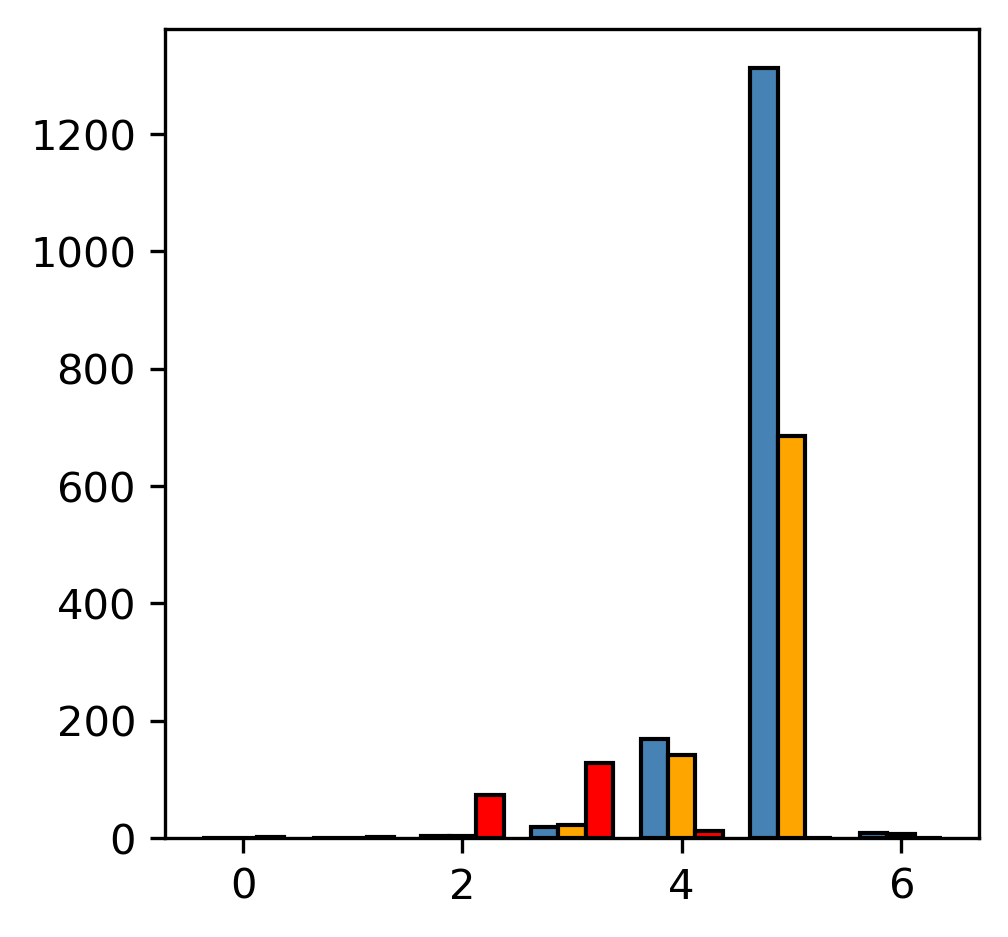

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

### Na-N coordination ###
# Parameters
na_type = 5
file_infos = [
    ('./hydration/400_diffusion_4/400K_NaN_coord_28_4.txt', 'steelblue', 'x=1.75 y=0.25'),
    ('./hydration/400_diffusion_4/400K_NaN_coord_16_4.txt', 'orange', 'x=1.00 y=0.25'),
    ('./hydration/400_diffusion_4/400K_NaN_coord_4_4.txt', 'red', 'x=0.25 y=0.25'),
]

# Parse data and collect coordination counts
coord_data = []
all_coord_numbers = set()

def get_coord_counts(filename):
    sections = parse_coordination_file(filename)
    timesteps = sorted(sections.keys())
    coords = []
    for timestep in timesteps:
        section = sections[timestep]
        na_atoms = [atom for atom in section['atoms'] if atom['type'] == na_type]
        coords.extend([atom['coordination'] for atom in na_atoms])
    counter = Counter(coords)
    all_coord_numbers.update(counter.keys())
    return counter

# Collect data
for filename, color, label in file_infos:
    coord_counts = get_coord_counts(filename)
    coord_data.append((coord_counts, color, label))

# Sorted coordination numbers
coord_numbers = sorted(all_coord_numbers)
x = np.arange(len(coord_numbers))  # bar positions
width = 0.25  # width of each bar

# Plotting
fig, ax = plt.subplots(figsize=(singlecol, singlecol),dpi=300)

for i, (coord_counts, color, label) in enumerate(coord_data):
    counts = [coord_counts.get(cn, 0) for cn in coord_numbers]
    offset = x + (i - 1) * width  # center the bars
    bars = ax.bar(offset, counts, width=width, color=color, edgecolor='black', label=label)
    #for bar, count in zip(bars, counts):
    #    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
    #            str(count), ha='center', va='bottom', fontsize=5)

### Na-O coordination ###
for i in [0,1,2]:
    bars = ax.bar(offset, CN_ls[i], width=width, color=color, edgecolor='black', label=label)

# Axis & labels
ax.set_xticks(x)
ax.set_xticklabels(coord_numbers)
ax.set_xlabel('Coordination Number of Sodium')
ax.set_ylabel('Total Count')
#ax.set_title('Grouped Na Coordination Distribution')
#ax.grid(axis='y', alpha=0.3)
ax.legend()#title='Time Range')

plt.tight_layout()
#plt.savefig('./hydration/400K_NaN_coord_O_4.png')

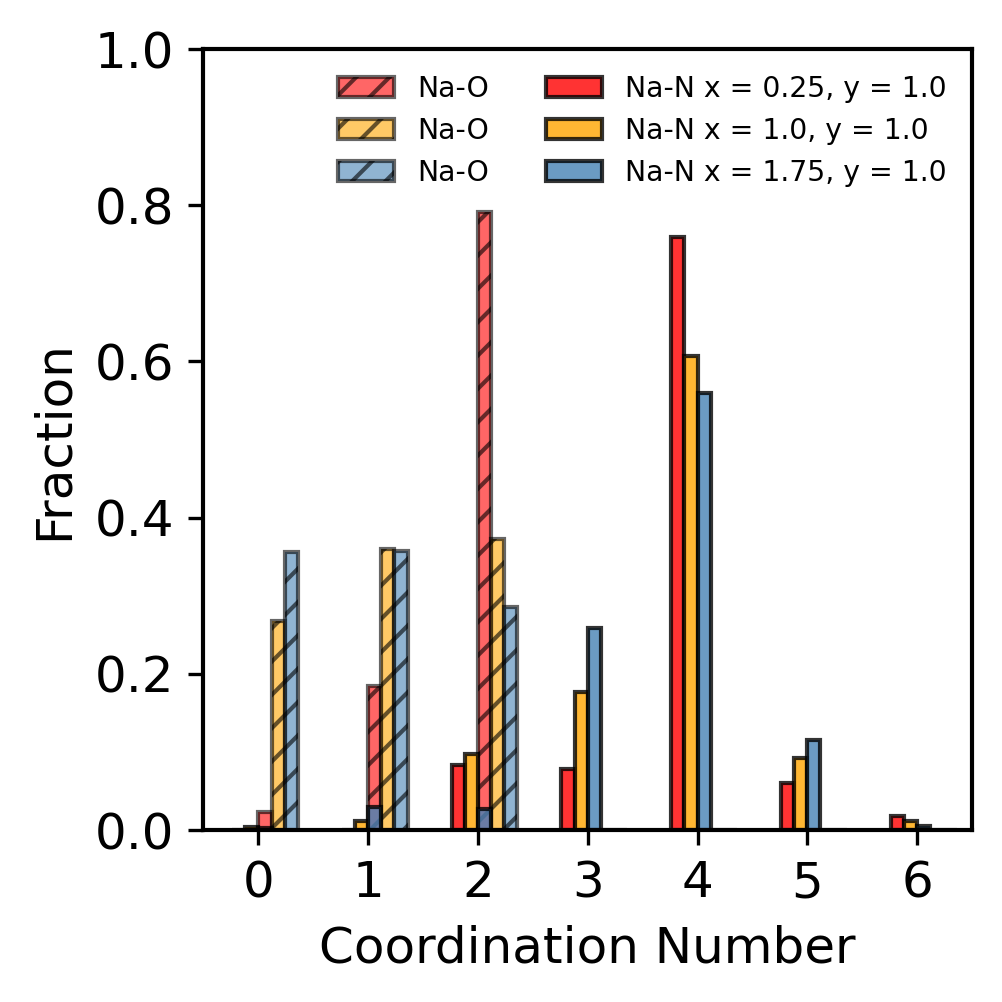

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

### Load Na-O coordination data ###
Na_ls = [4, 16, 28, 4, 16, 28, 4, 16, 28]
O_ls = [4, 4, 4, 16, 16, 16, 32, 32, 32]

CN_O_ls = []
for i in range(9):
    data = np.load(f'./hydration/400_diffusion_4/400K_NaO_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_O_ls.append(data)  # Fixed: was CN_ls

### Load Na-N coordination data ###
CN_N_ls = []
for i in range(9):
    data = np.load(f'./hydration/400_diffusion_4/400K_NaN_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_N_ls.append(data)  # Fixed: was CN_ls

### Convert to coordination counts ###
def get_coord_counts_from_array(coord_array):
    """Count occurrences of each coordination number"""
    counter = Counter(coord_array.flatten())  # Added flatten() for safety
    return counter

# Process Na-O data
coord_data_O = []
all_coord_numbers_O = set()
for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_O_ls[i])
    all_coord_numbers_O.update(coord_counts.keys())
    coord_data_O.append(coord_counts)

# Process Na-N data
coord_data_N = []
all_coord_numbers_N = set()
for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_N_ls[i])
    all_coord_numbers_N.update(coord_counts.keys())
    coord_data_N.append(coord_counts)

### Define file info for plotting ###
# Create labels for the 9 conditions
colors = ['red', 'orange', 'steelblue'] * 3  # Repeat for each O condition
file_infos = []
for i in range(9):
    label = f'x = {Na_ls[i]/16}, y = {O_ls[i]/16}'
    file_infos.append((None, colors[i % 3], label))

### Combine all coordination numbers ###
all_coord_numbers = sorted(all_coord_numbers_N | all_coord_numbers_O)
x = np.arange(len(all_coord_numbers))
width = 0.12  # Narrower to fit 6 bars

### Plotting ###
singlecol = 3.5  # Define figure width in inches
fig, ax = plt.subplots(figsize=(singlecol, singlecol), dpi=300)

indices_O_to_plot = [3,4,5]  # Corresponds to Na=28,16,4 with O=4
indices_N_to_plot = [3,4,5]  # Corresponds to Na=28,16,4 with O=4

# Plot Na-O coordination (hatched bars)
for j, i in enumerate(indices_O_to_plot):
    raw_counts = coord_data_O[i]
    total = CN_O_ls[i].shape[0]
    # Divide each individual count by the total here:
    counts = [raw_counts.get(cn, 0) / total for cn in all_coord_numbers]
    
    offset = x + (j + 0.5) * width
    _, color, label = file_infos[i]
    ax.bar(offset, counts, width=width, color=color, edgecolor='black',
           label=f'Na-O', alpha=0.6, hatch='///')

# Updated Na-N loop
for j, i in enumerate(indices_N_to_plot):
    raw_counts = coord_data_N[i]
    total = CN_N_ls[i].shape[0]
    # Divide each individual count by the total here:
    counts = [raw_counts.get(cn, 0) / total for cn in all_coord_numbers]
    
    offset = x + (j - 1.5) * width
    _, color, label = file_infos[i]
    ax.bar(offset, counts, width=width, color=color, edgecolor='black', 
           label=f'Na-N {label}', alpha=0.8)
    
# Axis & labels
ax.set_xticks(x)
ax.set_xticklabels(all_coord_numbers)
ax.set_xlabel('Coordination Number')
ax.set_ylabel('Fraction')
ax.set_xlim(-0.5, 6.5)
ax.set_ylim(0, 1)
ax.legend(fontsize=6.8, frameon=False, loc='best', ncol=2)
plt.tight_layout()
plt.savefig('./hydration/400K_NaN_NaO_coord_combined_2.svg', dpi=300, bbox_inches='tight')
plt.show()

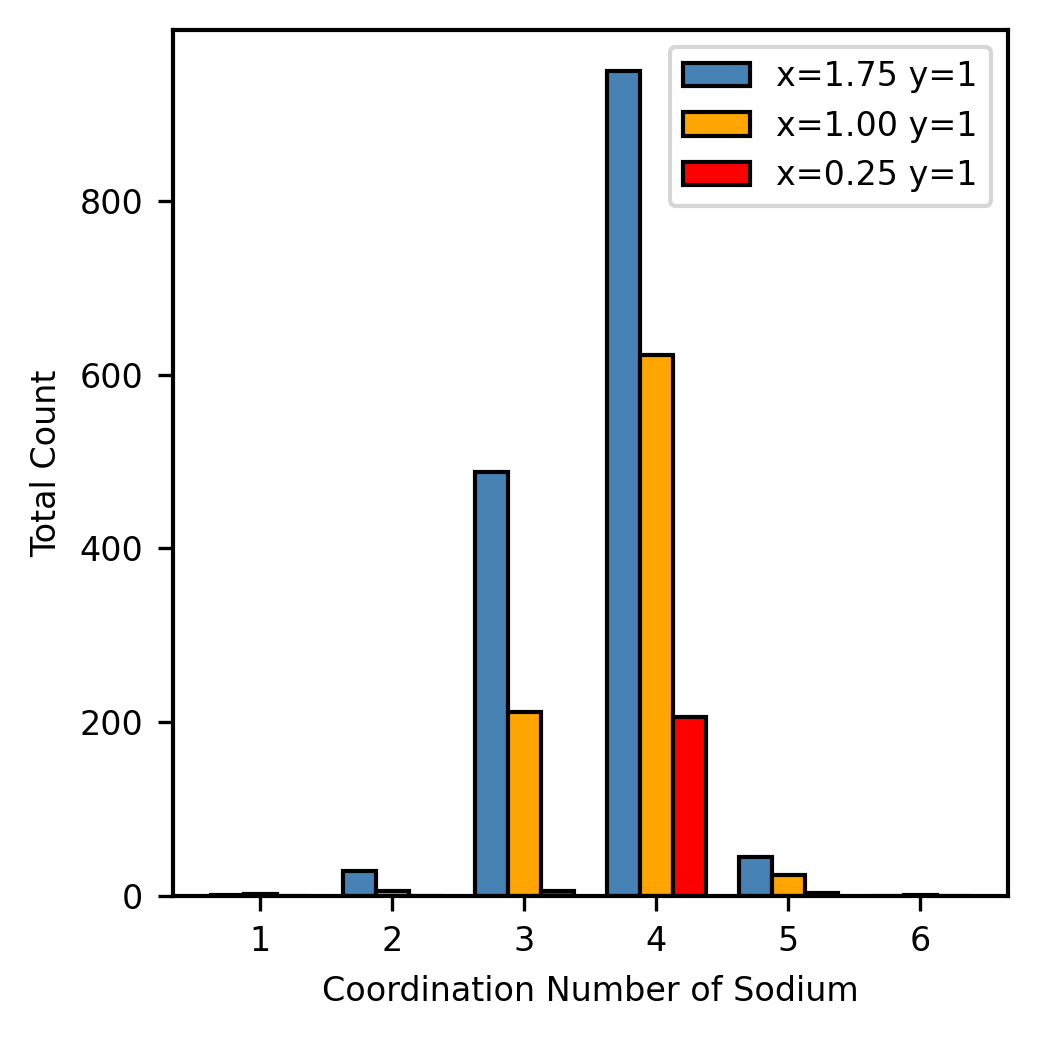

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

# Parameters
na_type = 5
file_infos = [
    ('./hydration/400_diffusion_4/400K_NaN_coord_28_16.txt', 'steelblue', 'x=1.75 y=1'),
    ('./hydration/400_diffusion_4/400K_NaN_coord_16_16.txt', 'orange', 'x=1.00 y=1'),
    ('./hydration/400_diffusion_4/400K_NaN_coord_4_16.txt', 'red', 'x=0.25 y=1'),
]

# Parse data and collect coordination counts
coord_data = []
all_coord_numbers = set()

def get_coord_counts(filename):
    sections = parse_coordination_file(filename)
    timesteps = sorted(sections.keys())
    coords = []
    for timestep in timesteps:
        section = sections[timestep]
        na_atoms = [atom for atom in section['atoms'] if atom['type'] == na_type]
        coords.extend([atom['coordination'] for atom in na_atoms])
    counter = Counter(coords)
    all_coord_numbers.update(counter.keys())
    return counter

# Collect data
for filename, color, label in file_infos:
    coord_counts = get_coord_counts(filename)
    coord_data.append((coord_counts, color, label))

# Sorted coordination numbers
coord_numbers = sorted(all_coord_numbers)
x = np.arange(len(coord_numbers))  # bar positions
width = 0.25  # width of each bar

# Plotting
fig, ax = plt.subplots(figsize=(singlecol, singlecol),dpi=300)

for i, (coord_counts, color, label) in enumerate(coord_data):
    counts = [coord_counts.get(cn, 0) for cn in coord_numbers]
    offset = x + (i - 1) * width  # center the bars
    bars = ax.bar(offset, counts, width=width, color=color, edgecolor='black', label=label)
    #for bar, count in zip(bars, counts):
     #   ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
      #          str(count), ha='center', va='bottom', fontsize=8)

# Axis & labels
ax.set_xticks(x)
ax.set_xticklabels(coord_numbers)
ax.set_xlabel('Coordination Number of Sodium')
ax.set_ylabel('Total Count')
#ax.set_title('Grouped Na Coordination Distribution')
#ax.grid(axis='y', alpha=0.3)
ax.legend()#title='Time Range')

plt.tight_layout()
plt.savefig('./hydration/400K_NaN_coord_O_16.svg')

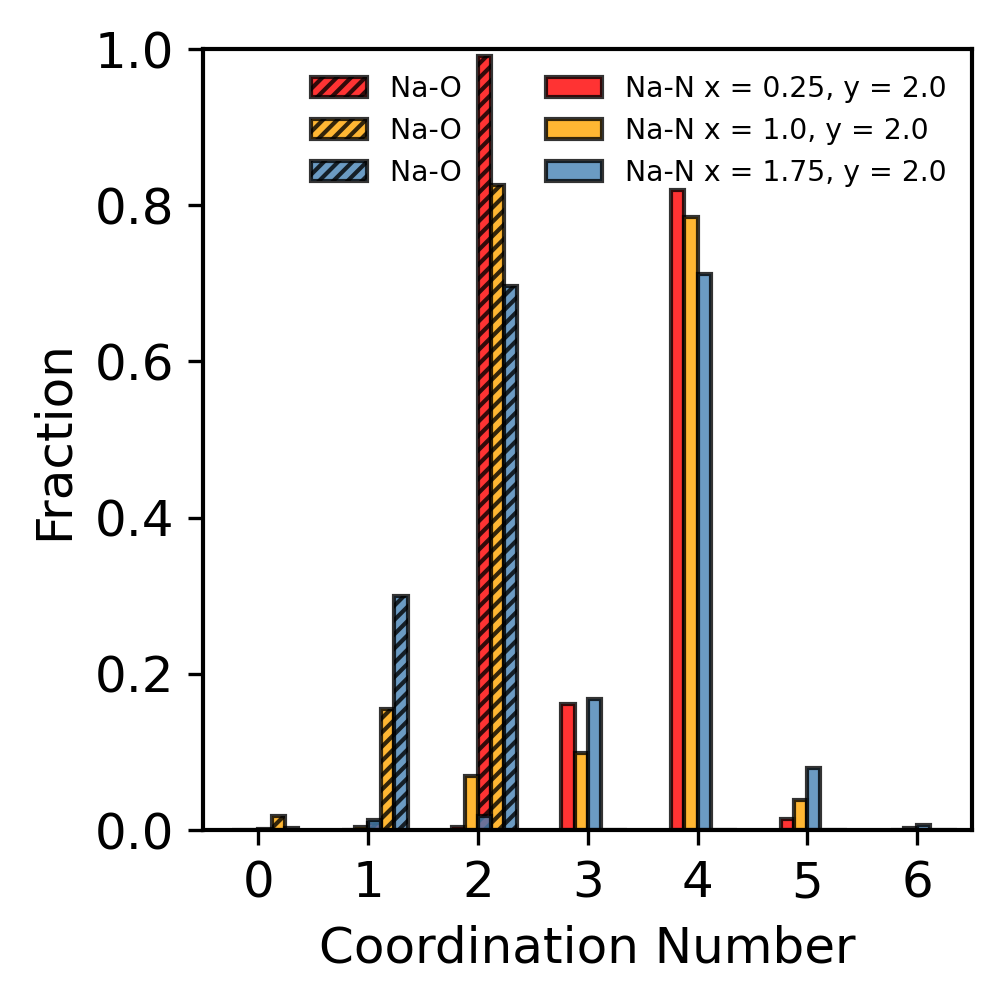

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

### Load Na-O coordination data ###
Na_ls = [4, 16, 28, 4, 16, 28, 4, 16, 28]
O_ls = [4, 4, 4, 16, 16, 16, 32, 32, 32]

CN_O_ls = []
for i in range(9):
    data = np.load(f'./hydration/400_diffusion_4/400K_NaO_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_O_ls.append(data)  # Fixed: was CN_ls

### Load Na-N coordination data ###
CN_N_ls = []
for i in range(9):
    data = np.load(f'./hydration/400_diffusion_4/400K_NaN_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_N_ls.append(data)  # Fixed: was CN_ls

### Convert to coordination counts ###
def get_coord_counts_from_array(coord_array):
    """Count occurrences of each coordination number"""
    counter = Counter(coord_array.flatten())  # Added flatten() for safety
    return counter

# Process Na-O data
coord_data_O = []
all_coord_numbers_O = set()
for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_O_ls[i])
    all_coord_numbers_O.update(coord_counts.keys())
    coord_data_O.append(coord_counts)

# Process Na-N data
coord_data_N = []
all_coord_numbers_N = set()
for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_N_ls[i])
    all_coord_numbers_N.update(coord_counts.keys())
    coord_data_N.append(coord_counts)

### Define file info for plotting ###
# Create labels for the 9 conditions
colors = ['red', 'orange', 'steelblue'] * 3  # Repeat for each O condition
file_infos = []
for i in range(9):
    label = f'x = {Na_ls[i]/16}, y = {O_ls[i]/16}'
    file_infos.append((None, colors[i % 3], label))

### Combine all coordination numbers ###
all_coord_numbers = sorted(all_coord_numbers_N | all_coord_numbers_O)
x = np.arange(len(all_coord_numbers))
width = 0.12  # Narrower to fit 6 bars

### Plotting ###
singlecol = 3.5  # Define figure width in inches
fig, ax = plt.subplots(figsize=(singlecol, singlecol), dpi=300)

indices_O_to_plot = [6,7,8]  # Corresponds to Na=28,16,4 with O=4
indices_N_to_plot = [6,7,8]  # Corresponds to Na=28,16,4 with O=4

# Plot Na-O coordination (hatched bars)
for j, i in enumerate(indices_O_to_plot):
    raw_counts = coord_data_O[i]
    total = CN_O_ls[i].shape[0]
    # Divide each individual count by the total here:
    counts = [raw_counts.get(cn, 0) / total for cn in all_coord_numbers]
    
    offset = x + (j + 0.5) * width
    _, color, label = file_infos[i]
    ax.bar(offset, counts, width=width, color=color, edgecolor='black',
           label=f'Na-O   ', alpha=0.8, hatch='///////')

# Updated Na-N loop
for j, i in enumerate(indices_N_to_plot):
    raw_counts = coord_data_N[i]
    total = CN_N_ls[i].shape[0]
    # Divide each individual count by the total here:
    counts = [raw_counts.get(cn, 0) / total for cn in all_coord_numbers]
    
    offset = x + (j - 1.5) * width
    _, color, label = file_infos[i]
    ax.bar(offset, counts, width=width, color=color, edgecolor='black', 
           label=f'Na-N {label}', alpha=0.8)
    
# Axis & labels
ax.set_xticks(x)
ax.set_xticklabels(all_coord_numbers)
ax.set_xlabel('Coordination Number')
ax.set_ylabel('Fraction')
ax.set_xlim(-0.5, 6.5)
ax.set_ylim(0, 1)
ax.legend(fontsize=6.8, frameon=False, loc='best', ncol=2)
plt.tight_layout()
#plt.savefig('./hydration/400K_NaN_NaO_coord_combined_3.svg', dpi=300, bbox_inches='tight')
plt.show()

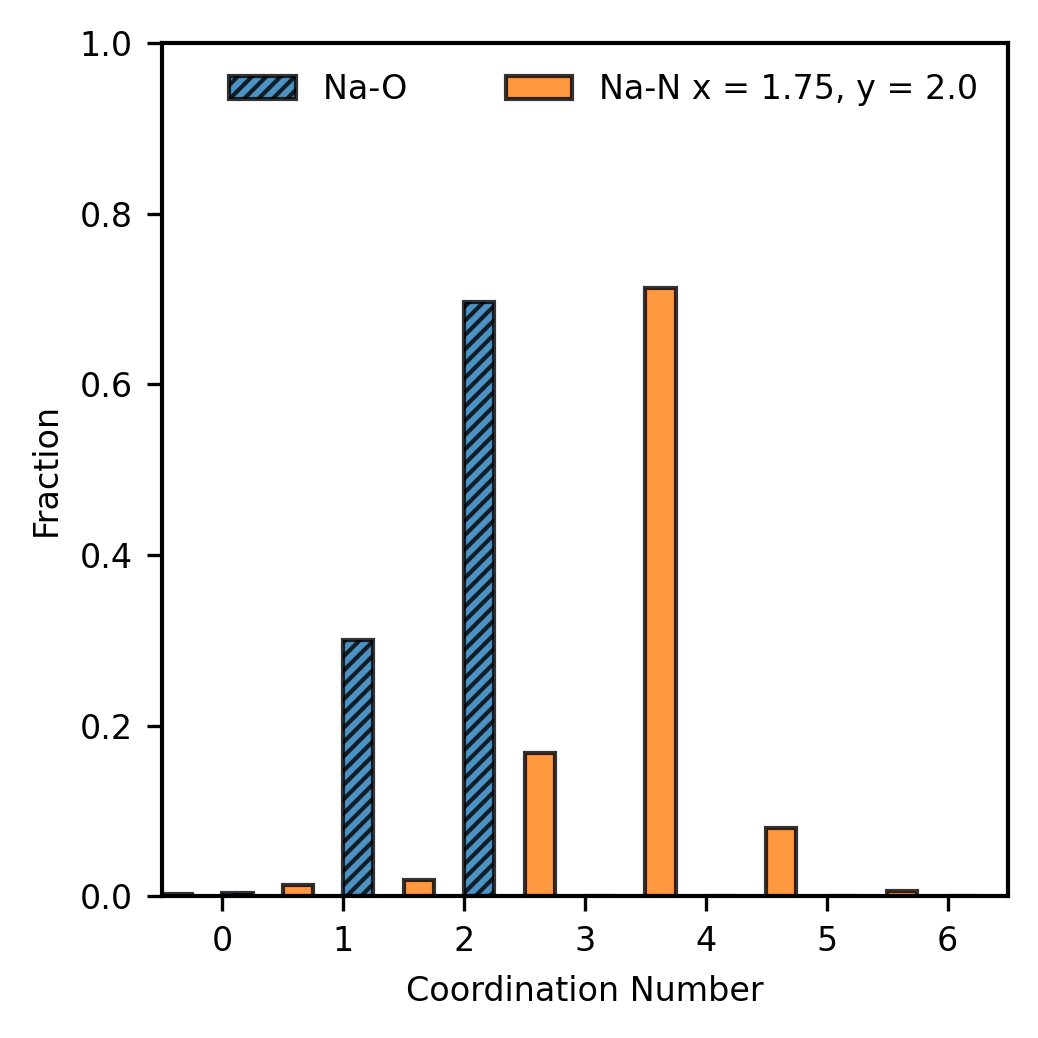

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

### Load Na-O coordination data ###
Na_ls = [4, 16, 28, 4, 16, 28, 4, 16, 28]
O_ls = [4, 4, 4, 16, 16, 16, 32, 32, 32]

CN_O_ls = []
for i in range(9):
    data = np.load(f'./hydration/400_diffusion_4/400K_NaO_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_O_ls.append(data)  # Fixed: was CN_ls

### Load Na-N coordination data ###
CN_N_ls = []
for i in range(9):
    data = np.load(f'./hydration/400_diffusion_4/400K_NaN_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_N_ls.append(data)  # Fixed: was CN_ls

### Convert to coordination counts ###
def get_coord_counts_from_array(coord_array):
    """Count occurrences of each coordination number"""
    counter = Counter(coord_array.flatten())  # Added flatten() for safety
    return counter

# Process Na-O data
coord_data_O = []
all_coord_numbers_O = set()
for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_O_ls[i])
    all_coord_numbers_O.update(coord_counts.keys())
    coord_data_O.append(coord_counts)

# Process Na-N data
coord_data_N = []
all_coord_numbers_N = set()
for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_N_ls[i])
    all_coord_numbers_N.update(coord_counts.keys())
    coord_data_N.append(coord_counts)

### Define file info for plotting ###
# Create labels for the 9 conditions
colors = ['red', 'orange', 'steelblue'] * 3  # Repeat for each O condition
file_infos = []
for i in range(9):
    label = f'x = {Na_ls[i]/16}, y = {O_ls[i]/16}'
    file_infos.append((None, colors[i % 3], label))

### Combine all coordination numbers ###
all_coord_numbers = sorted(all_coord_numbers_N | all_coord_numbers_O)
x = np.arange(len(all_coord_numbers))
width = 0.25  # Narrower to fit 6 bars

### Plotting ###
singlecol = 3.5  # Define figure width in inches
fig, ax = plt.subplots(figsize=(singlecol, singlecol), dpi=300)

indices_O_to_plot = [8]  # Corresponds to Na=28,16,4 with O=4
indices_N_to_plot = [8]  # Corresponds to Na=28,16,4 with O=4

# Plot Na-O coordination (hatched bars)
for j, i in enumerate(indices_O_to_plot):
    raw_counts = coord_data_O[i]
    total = CN_O_ls[i].shape[0]
    # Divide each individual count by the total here:
    counts = [raw_counts.get(cn, 0) / total for cn in all_coord_numbers]
    
    offset = x + (j + 0.5) * width
    _, color, label = file_infos[i]
    ax.bar(offset, counts, width=width,  edgecolor='black',
           label=f'Na-O   ', alpha=0.8, hatch='///////')

# Updated Na-N loop
for j, i in enumerate(indices_N_to_plot):
    raw_counts = coord_data_N[i]
    total = CN_N_ls[i].shape[0]
    # Divide each individual count by the total here:
    counts = [raw_counts.get(cn, 0) / total for cn in all_coord_numbers]
    
    offset = x + (j - 1.5) * width
    _, color, label = file_infos[i]
    ax.bar(offset, counts, width=width, edgecolor='black', 
           label=f'Na-N {label}', alpha=0.8)
    
# Axis & labels
ax.set_xticks(x)
ax.set_xticklabels(all_coord_numbers)
ax.set_xlabel('Coordination Number')
ax.set_ylabel('Fraction')
ax.set_xlim(-0.5, 6.5)
ax.set_ylim(0, 1)
ax.legend(fontsize=8, frameon=False, loc='best', ncol=2)
plt.tight_layout()
plt.savefig('./hydration/400K_NaN_NaO_coord.svg', dpi=300, bbox_inches='tight')
plt.show()

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

# Parameters
na_type = 5
file_infos = [
    ('./hydration/400_diffusion_20_MTP/400K_NaN_coord_28_32.txt', 'steelblue', 'x=1.75 y=2'),
    ('./hydration/400_diffusion_20_MTP/400K_NaN_coord_16_32.txt', 'orange', 'x=1.00 y=2'),
    ('./hydration/400_diffusion_20_MTP/400K_NaN_coord_4_32.txt', 'red', 'x=0.25 y=2'),
]

# Parse data and collect coordination counts
coord_data = []
all_coord_numbers = set()

def get_coord_counts(filename):
    sections = parse_coordination_file(filename)
    timesteps = sorted(sections.keys())
    coords = []
    for timestep in timesteps:
        section = sections[timestep]
        na_atoms = [atom for atom in section['atoms'] if atom['type'] == na_type]
        coords.extend([atom['coordination'] for atom in na_atoms])
    counter = Counter(coords)
    all_coord_numbers.update(counter.keys())
    return counter

# Collect data
for filename, color, label in file_infos:
    coord_counts = get_coord_counts(filename)
    coord_data.append((coord_counts, color, label))

# Sorted coordination numbers
coord_numbers = sorted(all_coord_numbers)
x = np.arange(len(coord_numbers))  # bar positions
width = 0.25  # width of each bar

# Plotting
fig, ax = plt.subplots(figsize=(singlecol, singlecol),dpi=300)

for i, (coord_counts, color, label) in enumerate(coord_data):
    counts = [coord_counts.get(cn, 0) for cn in coord_numbers]
    offset = x + (i - 1) * width  # center the bars
    bars = ax.bar(offset, counts, width=width, color=color, edgecolor='black', label=label)
    #for bar, count in zip(bars, counts):
    #    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
    #            str(count), ha='center', va='bottom', fontsize=8)

# Axis & labels
ax.set_xticks(x)
#ax.set_xlim(1,6)
ax.set_xticklabels(coord_numbers)
ax.set_xlabel('Coordination Number of Sodium')
ax.set_ylabel('Total Count')
#ax.set_title('Grouped Na Coordination Distribution')
#ax.grid(axis='y', alpha=0.3)
ax.legend()#title='Time Range')

plt.tight_layout()
#plt.savefig('./hydration/400K_NaN_coord_O_32.svg')

NameError: name 'parse_coordination_file' is not defined

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

### Load Na-O coordination data ###
Na_ls = [4, 16, 28, 4, 16, 28, 4, 16, 28]
O_ls = [4, 4, 4, 16, 16, 16, 32, 32, 32]

CN_ls = []
for i in range(9):
    data = np.load(f'./hydration/400_diffusion_4/400K_NaO_coord_{Na_ls[i]}_{O_ls[i]}.txt.npy')
    CN_ls.append(data)

### Na-N file info ###
na_type = 5
file_infos = [
    ('./hydration/400_diffusion_4/400K_NaN_coord_28_32.txt', 'steelblue', 'x=1.75 y=2'),
]

### Convert Na-O to coordination counts ###
def get_coord_counts_from_array(coord_array):
    """Count occurrences of each coordination number"""
    counter = Counter(coord_array)
    return counter

coord_data_O = []
all_coord_numbers_O = set()

for i in range(9):
    coord_counts = get_coord_counts_from_array(CN_ls[i])
    all_coord_numbers_O.update(coord_counts.keys())
    coord_data_O.append(coord_counts)

### Get Na-N coordination counts ###
def get_coord_counts(filename):
    sections = parse_coordination_file(filename)
    timesteps = sorted(sections.keys())
    coords = []
    for timestep in timesteps:
        section = sections[timestep]
        na_atoms = [atom for atom in section['atoms'] if atom['type'] == na_type]
        coords.extend([atom['coordination'] for atom in na_atoms])
    counter = Counter(coords)
    return counter

coord_data_N = []
all_coord_numbers_N = set()

for filename, color, label in file_infos:
    coord_counts = get_coord_counts(filename)
    all_coord_numbers_N.update(coord_counts.keys())
    coord_data_N.append((coord_counts, color, label))

### Combine all coordination numbers ###
all_coord_numbers = sorted(all_coord_numbers_N | all_coord_numbers_O)
x = np.arange(len(all_coord_numbers))
width = 0.12  # Narrower to fit 6 bars

### Plotting ###
fig, ax = plt.subplots(figsize=(singlecol, singlecol), dpi=300)

# Plot Na-N coordination (solid bars)
for i, (coord_counts, color, label) in enumerate(coord_data_N):
    counts = [coord_counts.get(cn, 0) for cn in all_coord_numbers]
    offset = x + (i - 1.5) * width
    ax.bar(offset, counts, width=width*3, color=color, edgecolor='black', 
           label=f'Na-N', alpha=0.8)

# Plot Na-O coordination (hatched bars) - use same indices as Na-N
indices_to_plot = [8]  # Corresponds to Na=28,16,4 with O=4
colors = ['orange',]  # Match the order: 28, 16, 4

for j, i in enumerate(indices_to_plot):
    counts = [coord_data_O[i].get(cn, 0) for cn in all_coord_numbers]
    offset = x + (j + 0.5) * width
    _, color, label = file_infos[j]  # Use j instead of 2-j
    ax.bar(offset, counts, width=width*3, color=color, edgecolor='black',
           label=f'Na-O {label}', alpha=0.6, hatch='//')
    
# Axis & labels
ax.set_xticks(x)
ax.set_xticklabels(all_coord_numbers)
ax.set_xlabel('Coordination Number')
ax.set_ylabel('Total Count')
ax.set_xlim(-0.5,6.5)
#ax.set_ylim(0,1000)
ax.legend(fontsize=5, frameon=False, loc='best', ncol=2)
plt.tight_layout()
plt.savefig('./hydration/400K_NaN_NaO_coord_combined.png', dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'parse_coordination_file' is not defined

In [106]:
na_stats

{'count': 4110,
 'mean': 4.142092457420924,
 'std': 1.0153347349790764,
 'min': 1,
 'max': 6,
 'coordination_numbers': [4,
  3,
  4,
  3,
  5,
  3,
  5,
  5,
  4,
  4,
  3,
  4,
  3,
  5,
  4,
  4,
  3,
  3,
  5,
  4,
  5,
  4,
  3,
  4,
  3,
  3,
  3,
  4,
  3,
  4,
  4,
  4,
  4,
  6,
  5,
  5,
  4,
  4,
  6,
  4,
  2,
  3,
  5,
  4,
  2,
  3,
  4,
  2,
  3,
  4,
  5,
  5,
  3,
  4,
  5,
  5,
  4,
  5,
  4,
  6,
  6,
  5,
  2,
  3,
  2,
  2,
  6,
  5,
  6,
  6,
  3,
  6,
  3,
  5,
  5,
  4,
  6,
  5,
  6,
  4,
  3,
  3,
  4,
  3,
  4,
  5,
  5,
  4,
  4,
  5,
  5,
  5,
  5,
  4,
  5,
  5,
  5,
  3,
  6,
  5,
  3,
  4,
  3,
  5,
  5,
  4,
  4,
  4,
  3,
  4,
  3,
  5,
  6,
  4,
  5,
  4,
  6,
  3,
  3,
  4,
  5,
  5,
  4,
  5,
  5,
  6,
  3,
  3,
  2,
  3,
  3,
  6,
  4,
  4,
  4,
  4,
  4,
  6,
  4,
  3,
  3,
  3,
  6,
  5,
  5,
  2,
  3,
  3,
  3,
  3,
  4,
  4,
  5,
  4,
  4,
  4,
  4,
  3,
  4,
  4,
  5,
  4,
  5,
  4,
  4,
  3,
  4,
  5,
  4,
  5,
  5,
  3,
  3,
  3,
  6,
  4,
  

In [94]:
filename = './../../../hydration/600_diffusion/600K_ONa_coord_28_32.txt'
sections = parse_coordination_file(filename)
na_stats = get_na_coordination_stats(section)
plot_detailed_distribution(sections)

No Na coordination data found


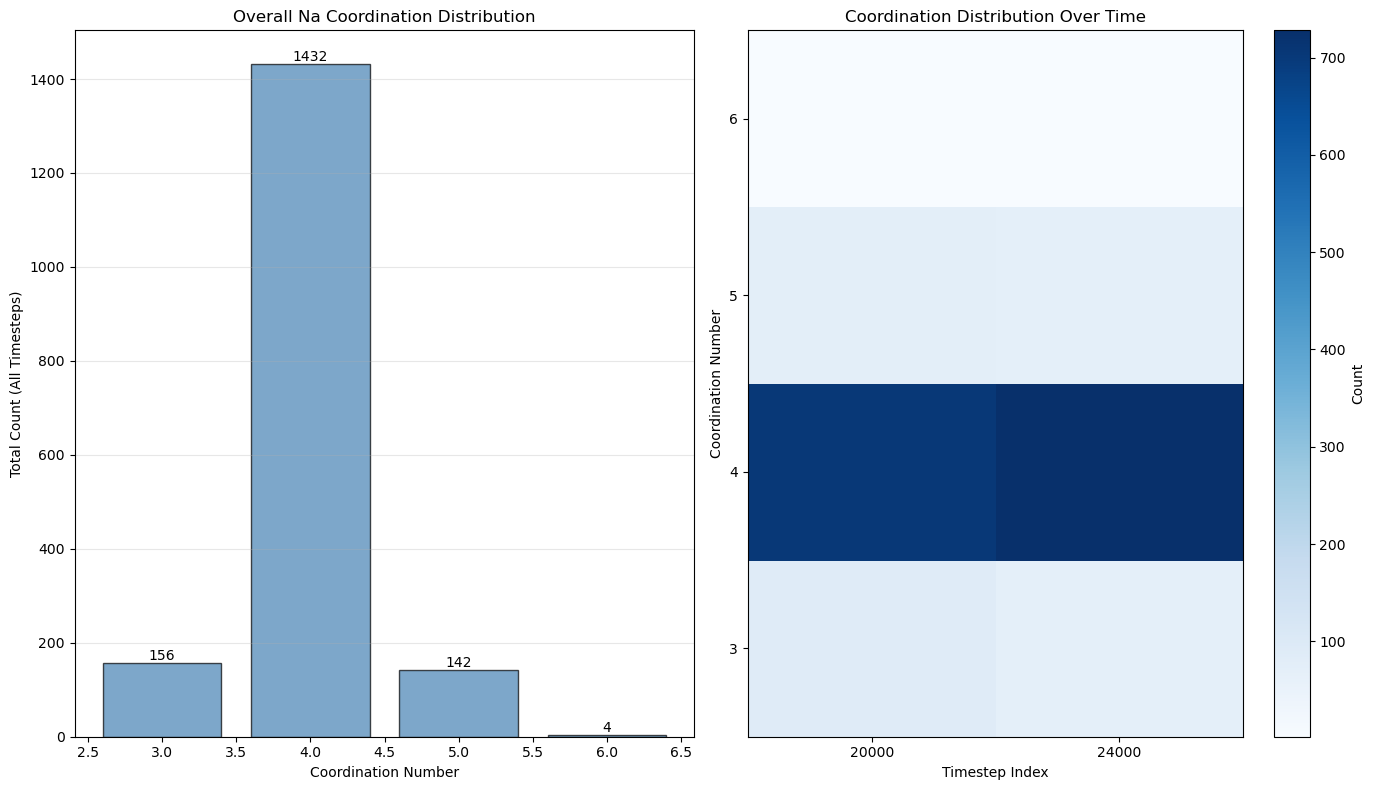

In [90]:
filename = './../../../hydration/600_diffusion/600K_NaN_coord_16_32.txt'
sections = parse_coordination_file(filename)
na_stats = get_na_coordination_stats(section)
plot_detailed_distribution(sections)

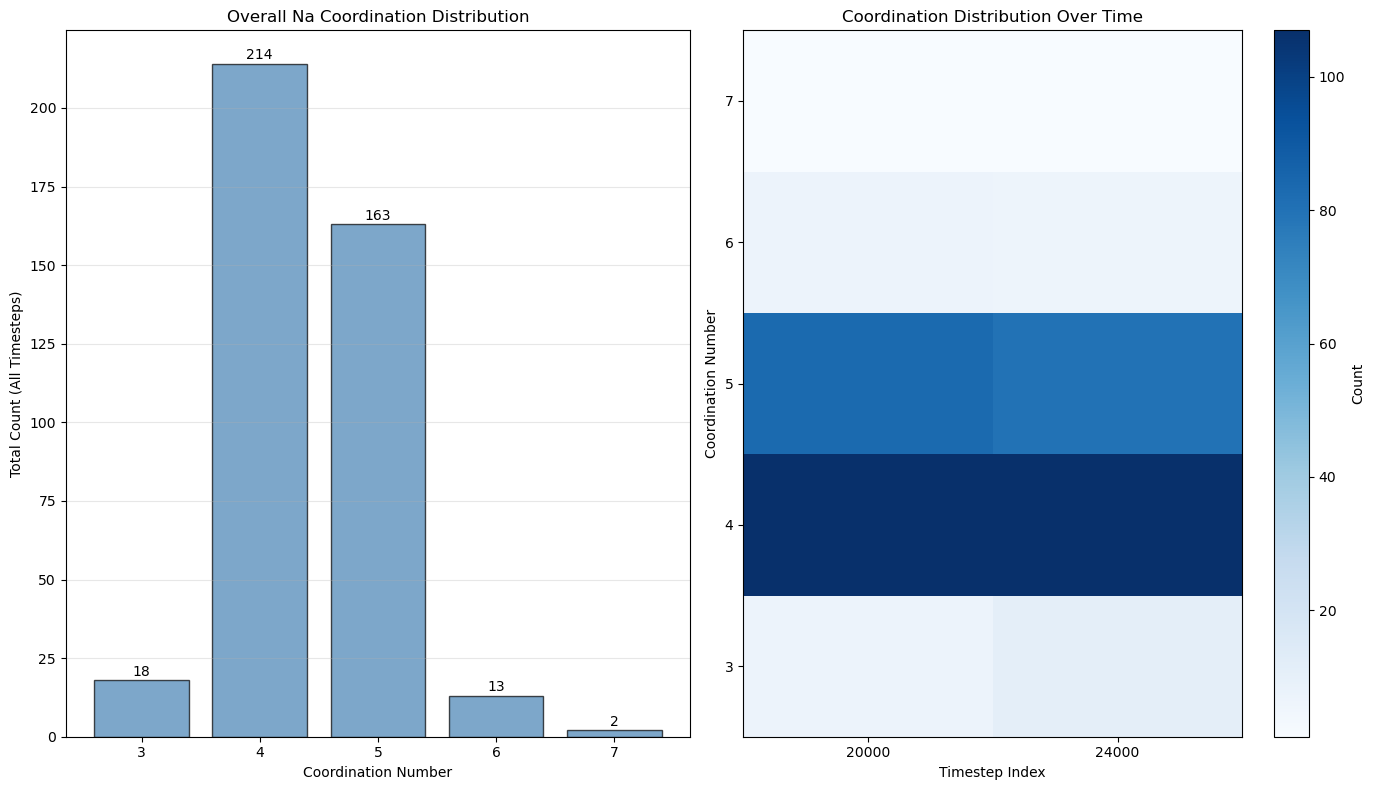

In [91]:
filename = './../../../hydration/600_diffusion/600K_NaN_coord_4_32.txt'
sections = parse_coordination_file(filename)
na_stats = get_na_coordination_stats(section)
plot_detailed_distribution(sections)

### O_16

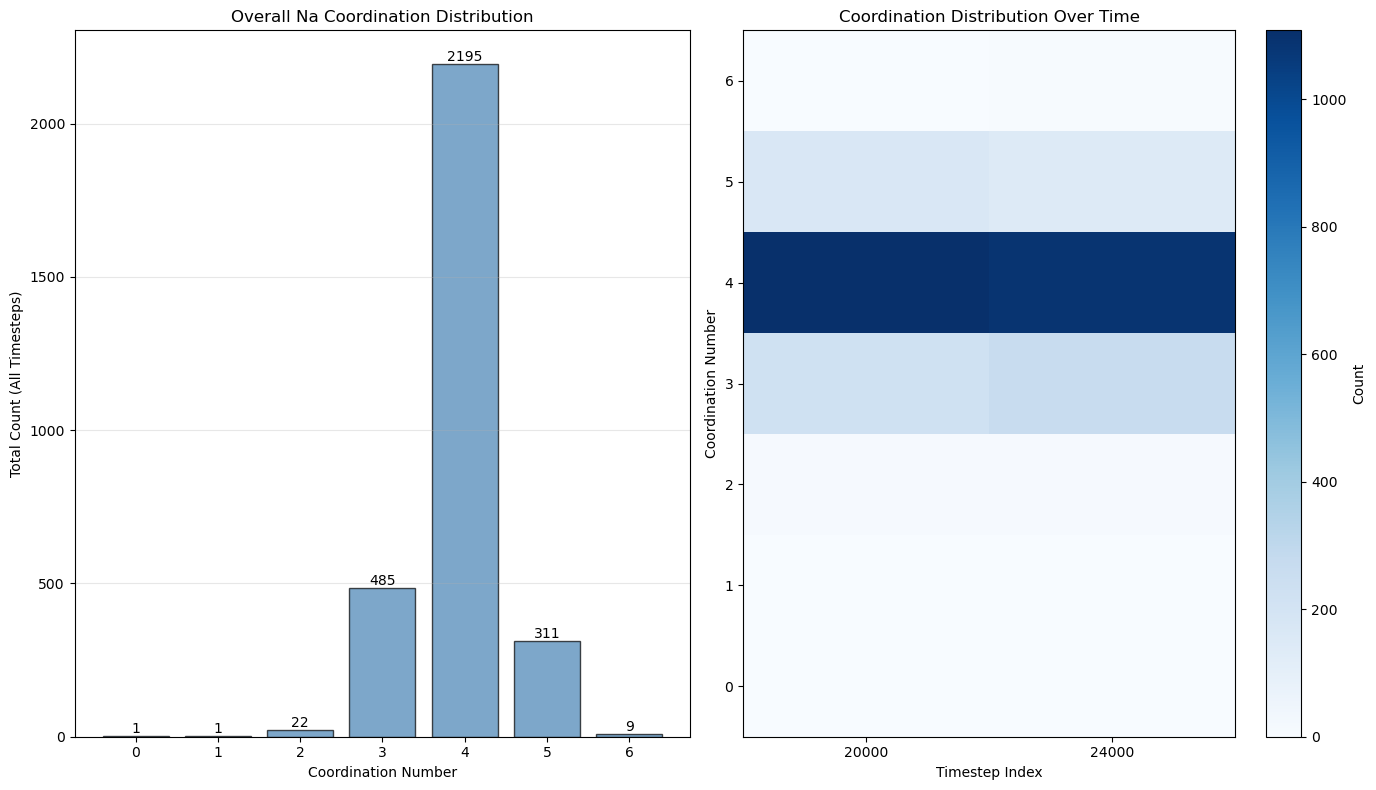

In [86]:
filename = './../../../hydration/600_diffusion/600K_NaN_coord_28_16.txt'
sections = parse_coordination_file(filename)
na_stats = get_na_coordination_stats(section)
plot_detailed_distribution(sections)

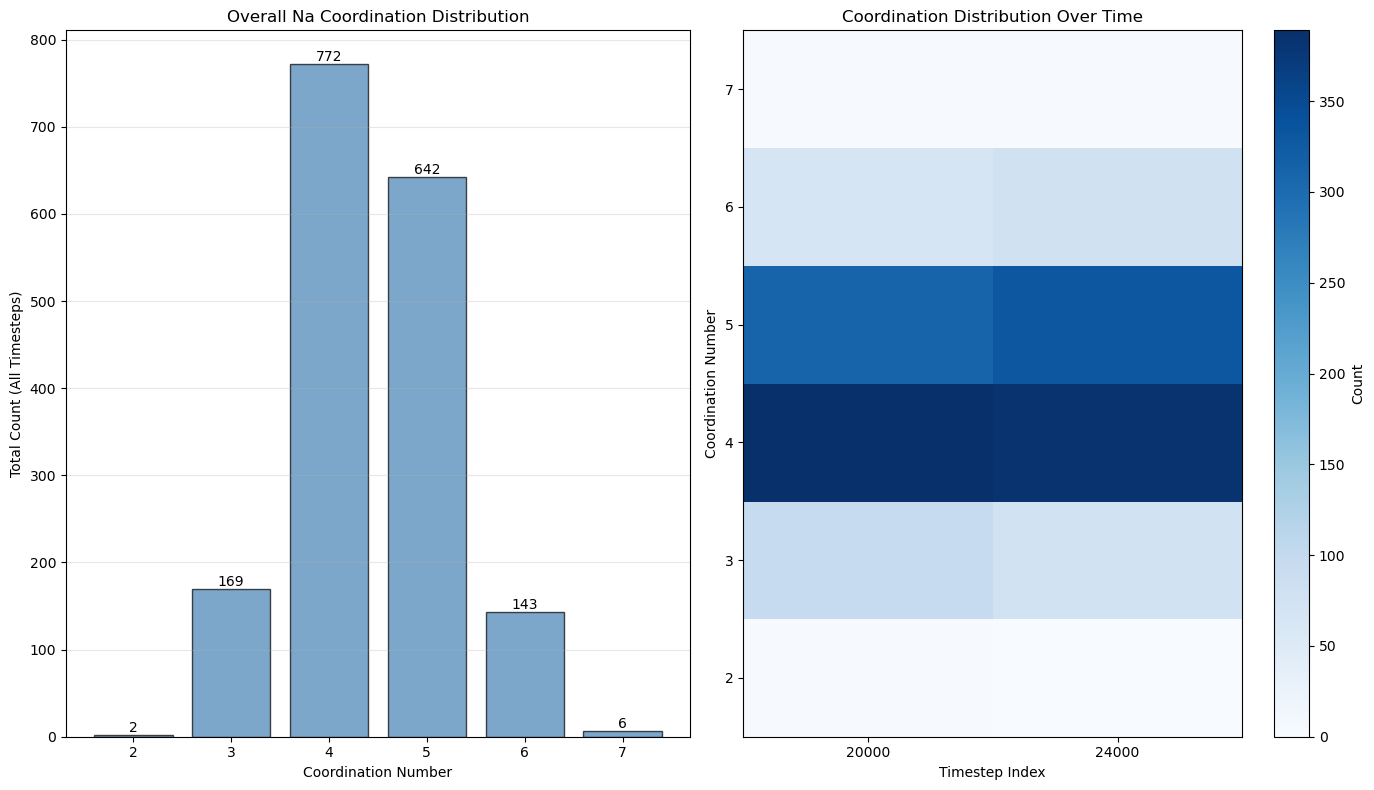

In [87]:
filename = './../../../hydration/600_diffusion/600K_NaN_coord_16_16.txt'
sections = parse_coordination_file(filename)
na_stats = get_na_coordination_stats(section)
plot_detailed_distribution(sections)

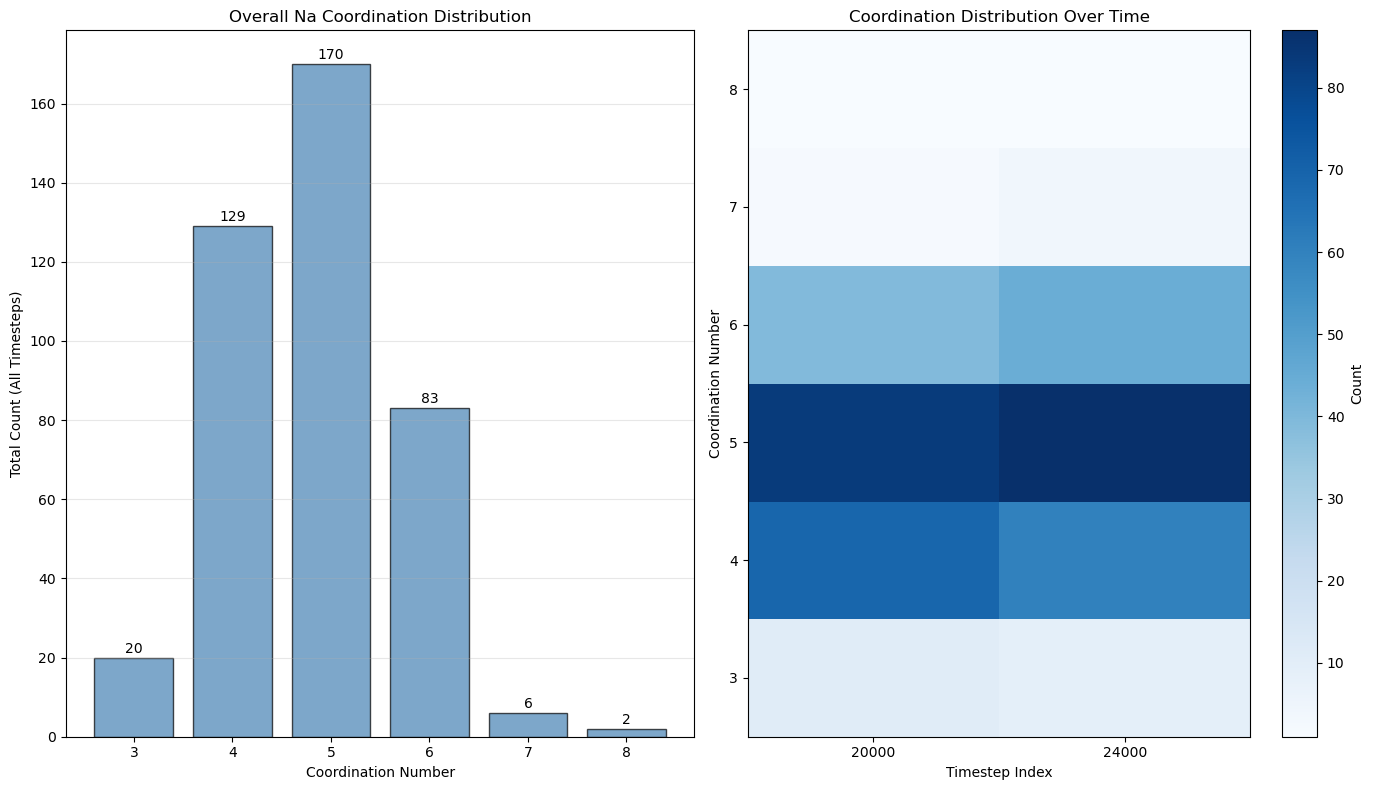

In [88]:
filename = './../../../hydration/600_diffusion/600K_NaN_coord_4_16.txt'
sections = parse_coordination_file(filename)
na_stats = get_na_coordination_stats(section)
plot_detailed_distribution(sections)

### RDF

In [3]:
def read_rdf_data(file):
    """
    Parse RDF data from file and return time blocks dictionary.
    
    Args:
        file (str): Path to the RDF data file
        
    Returns:
        dict: Dictionary mapping timesteps to numpy arrays of data,
              or None if parsing failed
    """
    try:
        with open(file, 'r') as f:
            lines = f.readlines()
    except FileNotFoundError:
        print(f"❌ Error: Could not find file {file}")
        return None
    except Exception as e:
        print(f"❌ Error reading file {file}: {e}")
        return None
    
    if not lines:
        print(f"❌ Error: File {file} is empty")
        return None
    
    time_blocks = {}
    current_timestep = None
    current_data = []
    reading_data = False
    expected_rows = 0
    
    for line_num, line in enumerate(lines, 1):
        line = line.strip()
        
        # Skip empty lines and comments that don't contain timestep info
        if not line or (line.startswith('#') and 'TimeStep' not in line):
            continue
        
        # Skip header line with TimeStep info
        if line.startswith('#') and 'TimeStep' in line:
            continue
        
        # Check for timestep and row count line
        parts = line.split()
        if len(parts) == 2 and parts[0].isdigit() and parts[1].isdigit():
            # Save previous timestep data
            if current_timestep is not None and current_data:
                if len(current_data) == expected_rows:
                    time_blocks[current_timestep] = np.array(current_data)
                else:
                    print(f"⚠️  Warning: Timestep {current_timestep} has {len(current_data)} rows, expected {expected_rows}")
                    time_blocks[current_timestep] = np.array(current_data)
            
            # Start new timestep
            current_timestep = int(parts[0])
            expected_rows = int(parts[1])
            current_data = []
            reading_data = True
            continue
        
        # Read data rows
        if reading_data and len(parts) > 2:
            try:
                # Convert to float, skip row number (first column)
                row_data = [float(x) for x in parts[1:]]  # Skip row index
                current_data.append(row_data)
                
                # Check if we've read all expected rows
                if len(current_data) == expected_rows:
                    reading_data = False
            except ValueError as e:
                print(f"⚠️  Warning: Could not parse line {line_num}: {line}")
                continue
    
    # Don't forget to save the last timestep!
    if current_timestep is not None and current_data:
        if len(current_data) == expected_rows:
            time_blocks[current_timestep] = np.array(current_data)
        else:
            print(f"⚠️  Warning: Last timestep {current_timestep} has {len(current_data)} rows, expected {expected_rows}")
            time_blocks[current_timestep] = np.array(current_data)
    
    if not time_blocks:
        print("❌ Error: No valid data found in file")
        return None
    
    # Analyze data structure
    first_timestep = list(time_blocks.keys())[0]
    first_data = time_blocks[first_timestep]
    
    # Column structure: [r, g(r)_pair1, N(r)_pair1, g(r)_pair2, N(r)_pair2, ...]
    num_columns = first_data.shape[1]
    num_pairs = (num_columns - 1) // 2  # Subtract 1 for r column, divide by 2 for g(r) and N(r)
    
    print(f"✅ Successfully parsed {len(time_blocks)} timesteps")
    print(f"📊 Data structure: {first_data.shape[0]} rows × {num_columns} columns")
    print(f"🔗 Number of atom pairs: {num_pairs}")
    
    return time_blocks

In [15]:
name = ['C-Fe','C-N','N-Mn','N-Na','Fe-Mn', 'O-Na', 'O-H']
colors = ['r', 'orange', 'blue', 'green', 'c', 'purple', 'm']

In [15]:
RDF = read_rdf_data(f'../../../hydration/400_diffusion_3/400_diffusion_1.rdf')

✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


In [16]:
RDF

{24000: array([[0.03   , 0.     , 0.     , ..., 0.     , 0.     , 0.     ],
        [0.09   , 0.     , 0.     , ..., 0.     , 0.     , 0.     ],
        [0.15   , 0.     , 0.     , ..., 0.     , 0.     , 0.     ],
        ...,
        [5.85   , 3.33963, 2.36352, ..., 1.60255, 1.21057, 3.35903],
        [5.91   , 3.69107, 2.74384, ..., 1.6537 , 1.10533, 3.41597],
        [5.97   , 3.89493, 3.15335, ..., 1.69699, 1.03037, 3.47014]])}

✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


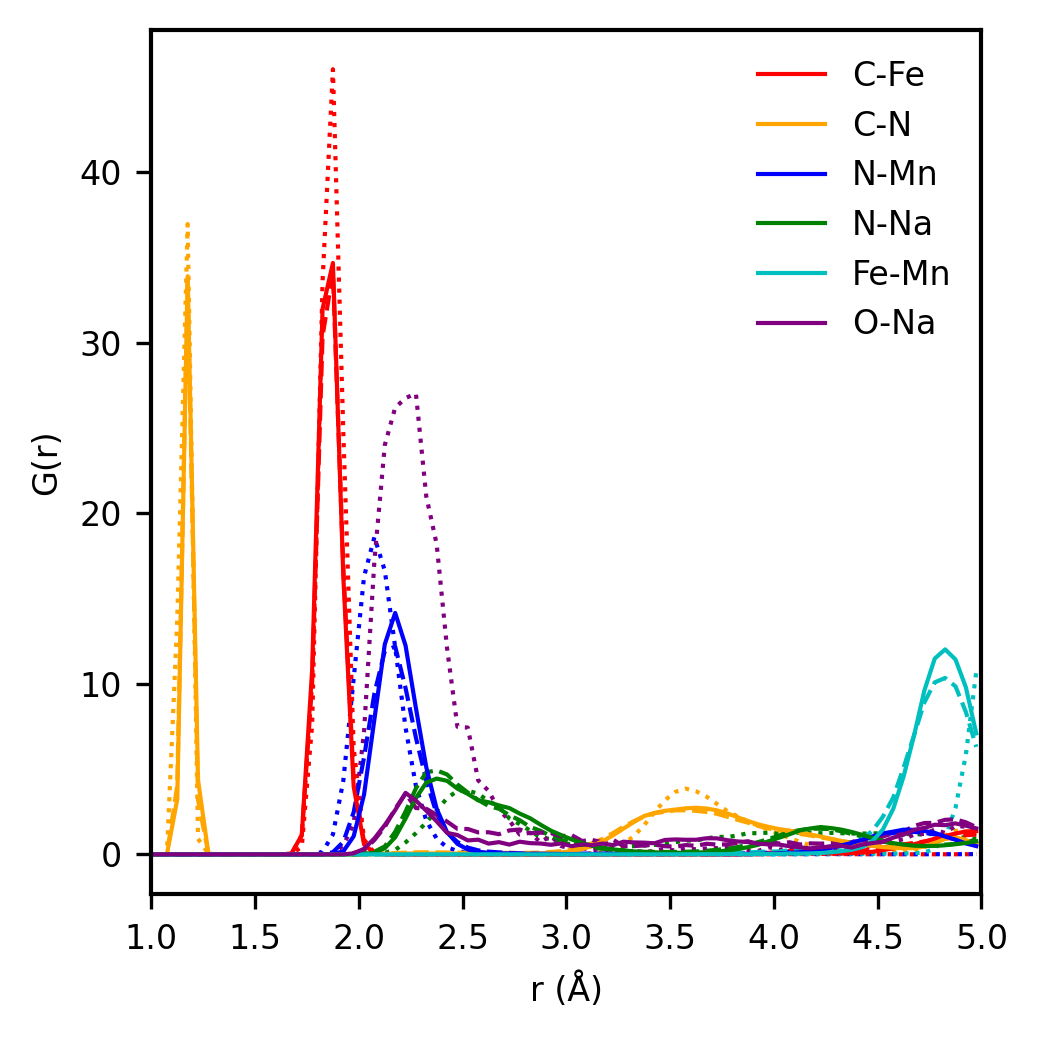

In [64]:
temp=400
plt.rcParams.update({'lines.linewidth':1})
fig = plt.figure(figsize=(singlecol, singlecol),dpi=300)
RDF = read_rdf_data(f'./hydration/400_diffusion_4/400_diffusion_1.rdf')
r = RDF[32000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[32000][:,i],':', color = colors[j])
    
RDF = read_rdf_data(f'./hydration/400_diffusion_4/400_diffusion_2.rdf')
r = RDF[32000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[32000][:,i],'--', color = colors[j])

RDF = read_rdf_data(f'./hydration/400_diffusion_4/400_diffusion_3.rdf')
r = RDF[32000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[32000][:,i],'-', color = colors[j], label = name[j])

temp=400
plt.legend(frameon=False)
plt.xlabel('r (Å)')
plt.xlim(1,5)
plt.ylabel('G(r)')
plt.tight_layout()
plt.savefig(f'./hydration/{temp}_diffusion_O_4_RDF.svg')

✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


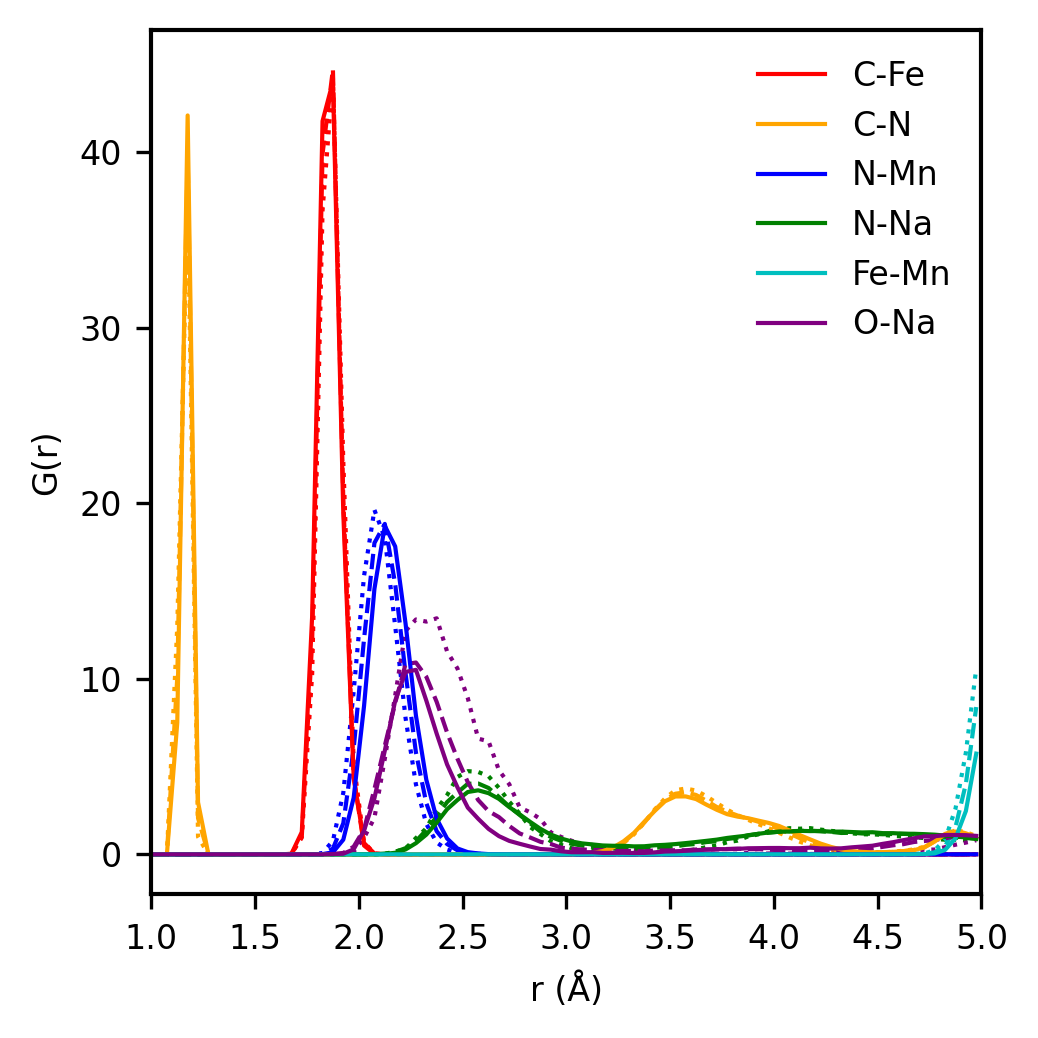

In [62]:
temp=400
plt.rcParams.update({'lines.linewidth':1})
fig = plt.figure(figsize=(singlecol, singlecol),dpi=300)
RDF = read_rdf_data(f'./hydration/400_diffusion_4/400_diffusion_4.rdf')
r = RDF[32000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[32000][:,i],':', color = colors[j])
    
RDF = read_rdf_data(f'./hydration/400_diffusion_4/400_diffusion_5.rdf')
r = RDF[32000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[32000][:,i],'--', color = colors[j])

RDF = read_rdf_data(f'./hydration/400_diffusion_4/400_diffusion_6.rdf')
r = RDF[32000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[32000][:,i],'-', color = colors[j], label = name[j])

temp=400
plt.legend(frameon=False)
plt.xlabel('r (Å)')
plt.xlim(1,5)
plt.ylabel('G(r)')
plt.tight_layout()
plt.savefig(f'./hydration/{temp}_diffusion_O_16_RDF.svg')

✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


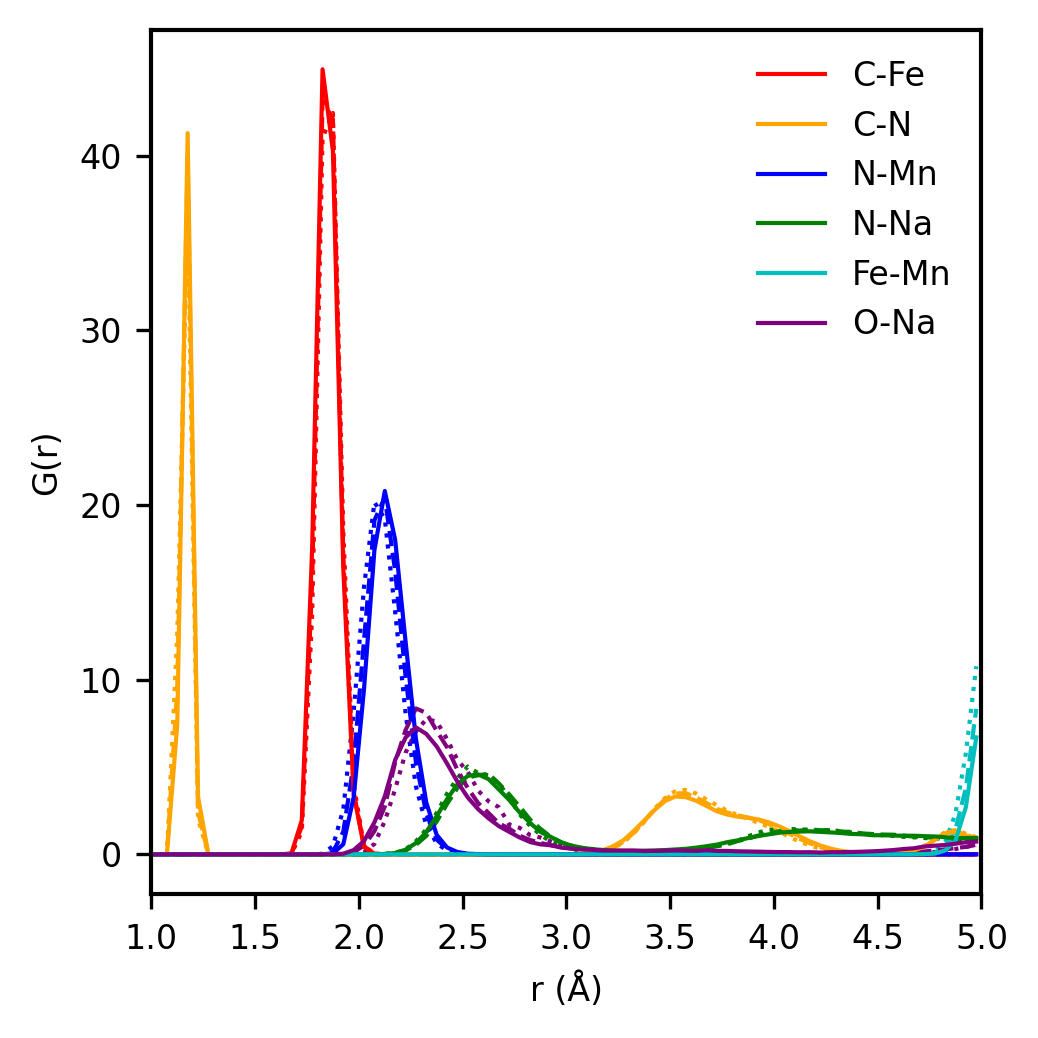

In [60]:
temp=400
plt.rcParams.update({'lines.linewidth':1})
fig = plt.figure(figsize=(singlecol, singlecol),dpi=300)
RDF = read_rdf_data(f'./hydration/400_diffusion_4/400_diffusion_7.rdf')
r = RDF[32000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[32000][:,i],':', color = colors[j])
    
RDF = read_rdf_data(f'./hydration/400_diffusion_4/400_diffusion_8.rdf')
r = RDF[32000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[32000][:,i],'--', color = colors[j])

RDF = read_rdf_data(f'./hydration/400_diffusion_4/400_diffusion_9.rdf')
r = RDF[32000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[32000][:,i],'-', color = colors[j], label = name[j])

temp=400
plt.legend(frameon=False)
plt.xlabel('r (Å)')
plt.xlim(1,5)
plt.ylabel('G(r)')
plt.tight_layout()
plt.savefig(f'./hydration/{temp}_diffusion_O_32_RDF.svg')

In [30]:
RDF[32000][:,i].max()

7.26777

✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 2 timesteps
📊 Data structure: 100 rows × 11 columns
🔗 Number of atom pairs: 5


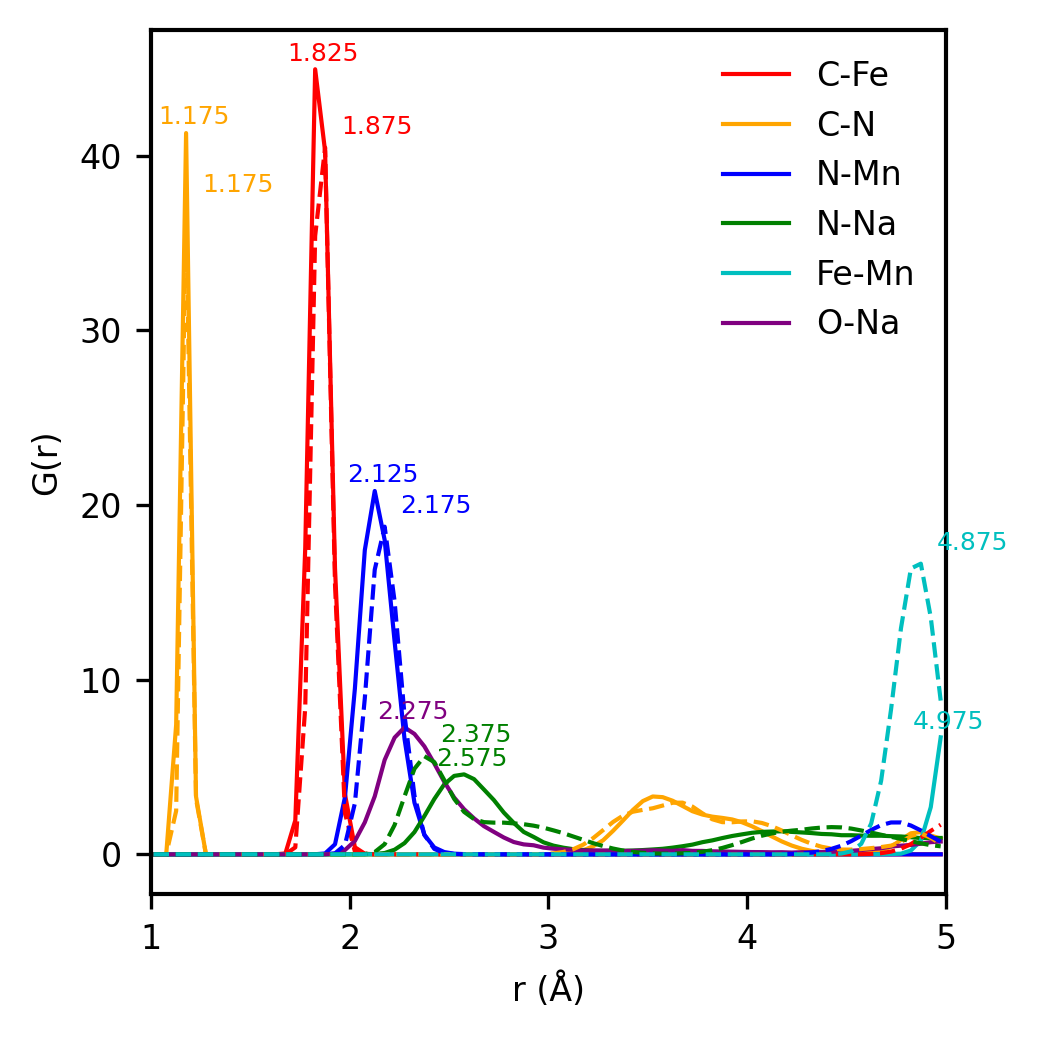

In [32]:
plt.rcParams.update({'font.size': 8})
plt.rcParams.update({'legend.fontsize': 8})

temp=400
plt.rcParams.update({'lines.linewidth':1})
fig = plt.figure(figsize=(singlecol, singlecol),dpi=300)

RDF = read_rdf_data(f'./hydration/400_diffusion_4/400_diffusion_9.rdf')
r = RDF[32000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[32000][:,i],'-', color = colors[j], label = name[j])
    plt.text(r[RDF[32000][:,i].argmax()]-0.14, 
         RDF[32000][:,i].max()+0.5, 
         f'{r[RDF[32000][:,i].argmax()]}',
         color = colors[j],fontsize=6)

RDF = read_rdf_data(f'./production_run/free_E/test/300K_rdf_final_3600.rdf')
r = RDF[10000][:,0]
for i in range(1, 11, 2):
    j = int(i/2)
    plt.plot(r, RDF[10000][:,i],'--', color = colors[j])
    plt.text(r[RDF[10000][:,i].argmax()]+0.08, 
         RDF[10000][:,i].max()+0.8, 
         f'{r[RDF[10000][:,i].argmax()]}',
         color = colors[j],fontsize=6)


temp=400
plt.legend(frameon=False)
plt.xlabel('r (Å)')
plt.xlim(1,5)
plt.ylabel('G(r)')
plt.tight_layout()
plt.savefig(f'./hydration/{temp}_RDF.svg')

✅ Successfully parsed 255 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


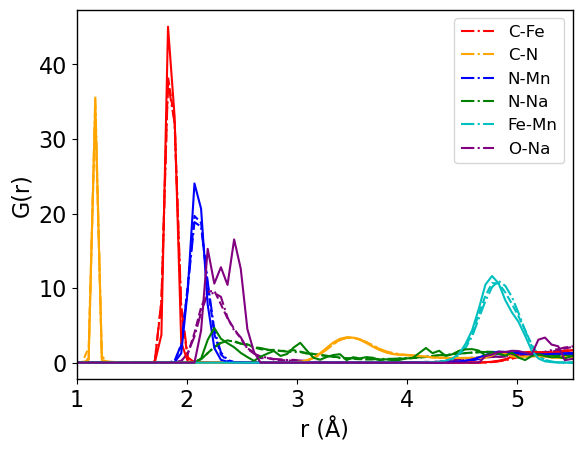

In [32]:
temp=600
fig = plt.figure()
RDF = read_rdf_data(f'../../../hydration/RDF_lv12_E0_2/300K_rdf_Na_4_O_16.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i],'-.', label = name[j], color = colors[j])

r = RDF[180000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[180000][:,i],'--', color = colors[j])

r = RDF[1000000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[1000000][:,i],'-', color = colors[j])

temp=400
plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.5)
plt.ylabel('G(r)')
plt.savefig(f'../../../hydration/{temp}_diffusion_3/{temp}_diffusion_O_32_RDF.png')

✅ Successfully parsed 255 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


Text(0, 0.5, 'G(r)')

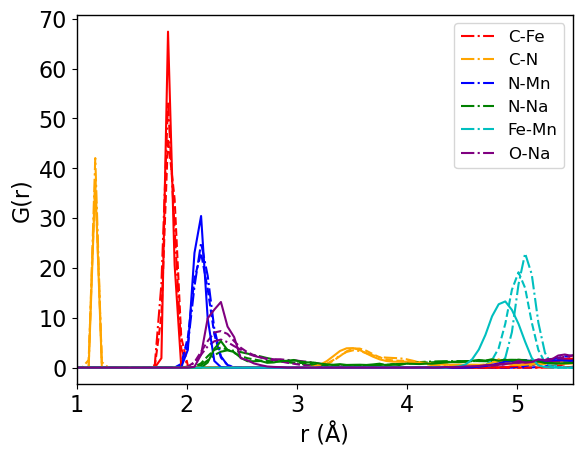

In [29]:
temp=600
fig = plt.figure()
RDF = read_rdf_data(f'../../../hydration/RDF_lv12_E0/300K_rdf_Na_32_O_32.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i],'-.', label = name[j], color = colors[j])

r = RDF[180000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[180000][:,i],'--', color = colors[j])

r = RDF[1000000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[1000000][:,i],'-', color = colors[j])


plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.5)
plt.ylabel('G(r)')
#plt.savefig(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_O_4_RDF.png')

✅ Successfully parsed 255 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


Text(0, 0.5, 'G(r)')

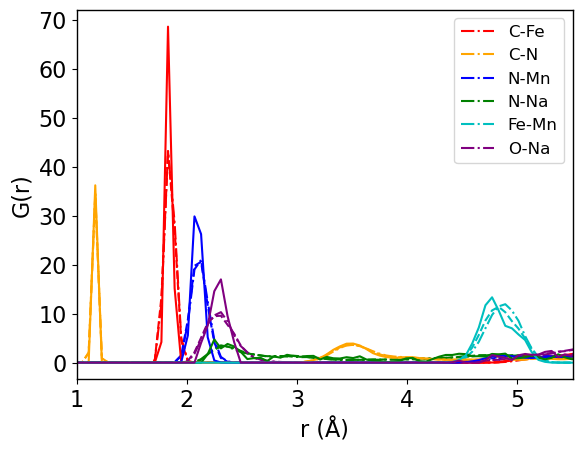

In [31]:
temp=600
fig = plt.figure()
RDF = read_rdf_data(f'../../../hydration/RDF_lv12_E0_2/300K_rdf_Na_4_O_32.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i],'-.', label = name[j], color = colors[j])

r = RDF[180000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[180000][:,i],'--', color = colors[j])

r = RDF[1000000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[1000000][:,i],'-', color = colors[j])


plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.5)
plt.ylabel('G(r)')
#plt.savefig(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_O_4_RDF.png')

In [27]:
RDF[24000][:,i]

KeyError: 24000

✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


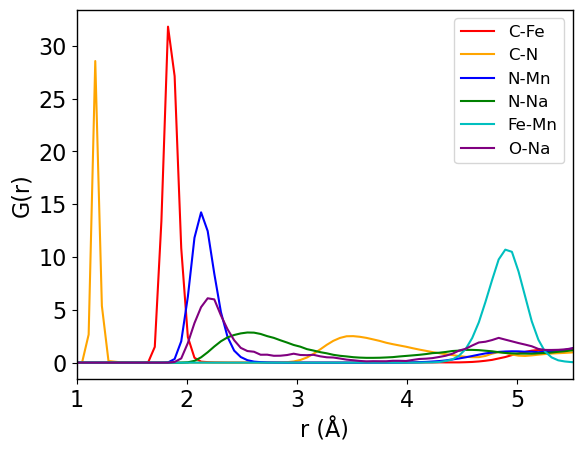

In [67]:
temp=600
fig = plt.figure()
RDF = read_rdf_data(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_3.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], label = name[j], color = colors[j])
    plt.text(pdf[:,1][pdf[:,i].argmax()]-0.14, 
             pdf[:,i].max()+0.5, 
             f'{pdf[:,1][pdf[:,i].argmax()]}',
             color = colors[j],fontsize=8)

plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.5)
plt.ylabel('G(r)')
plt.savefig(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_O_4_RDF.png')

✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


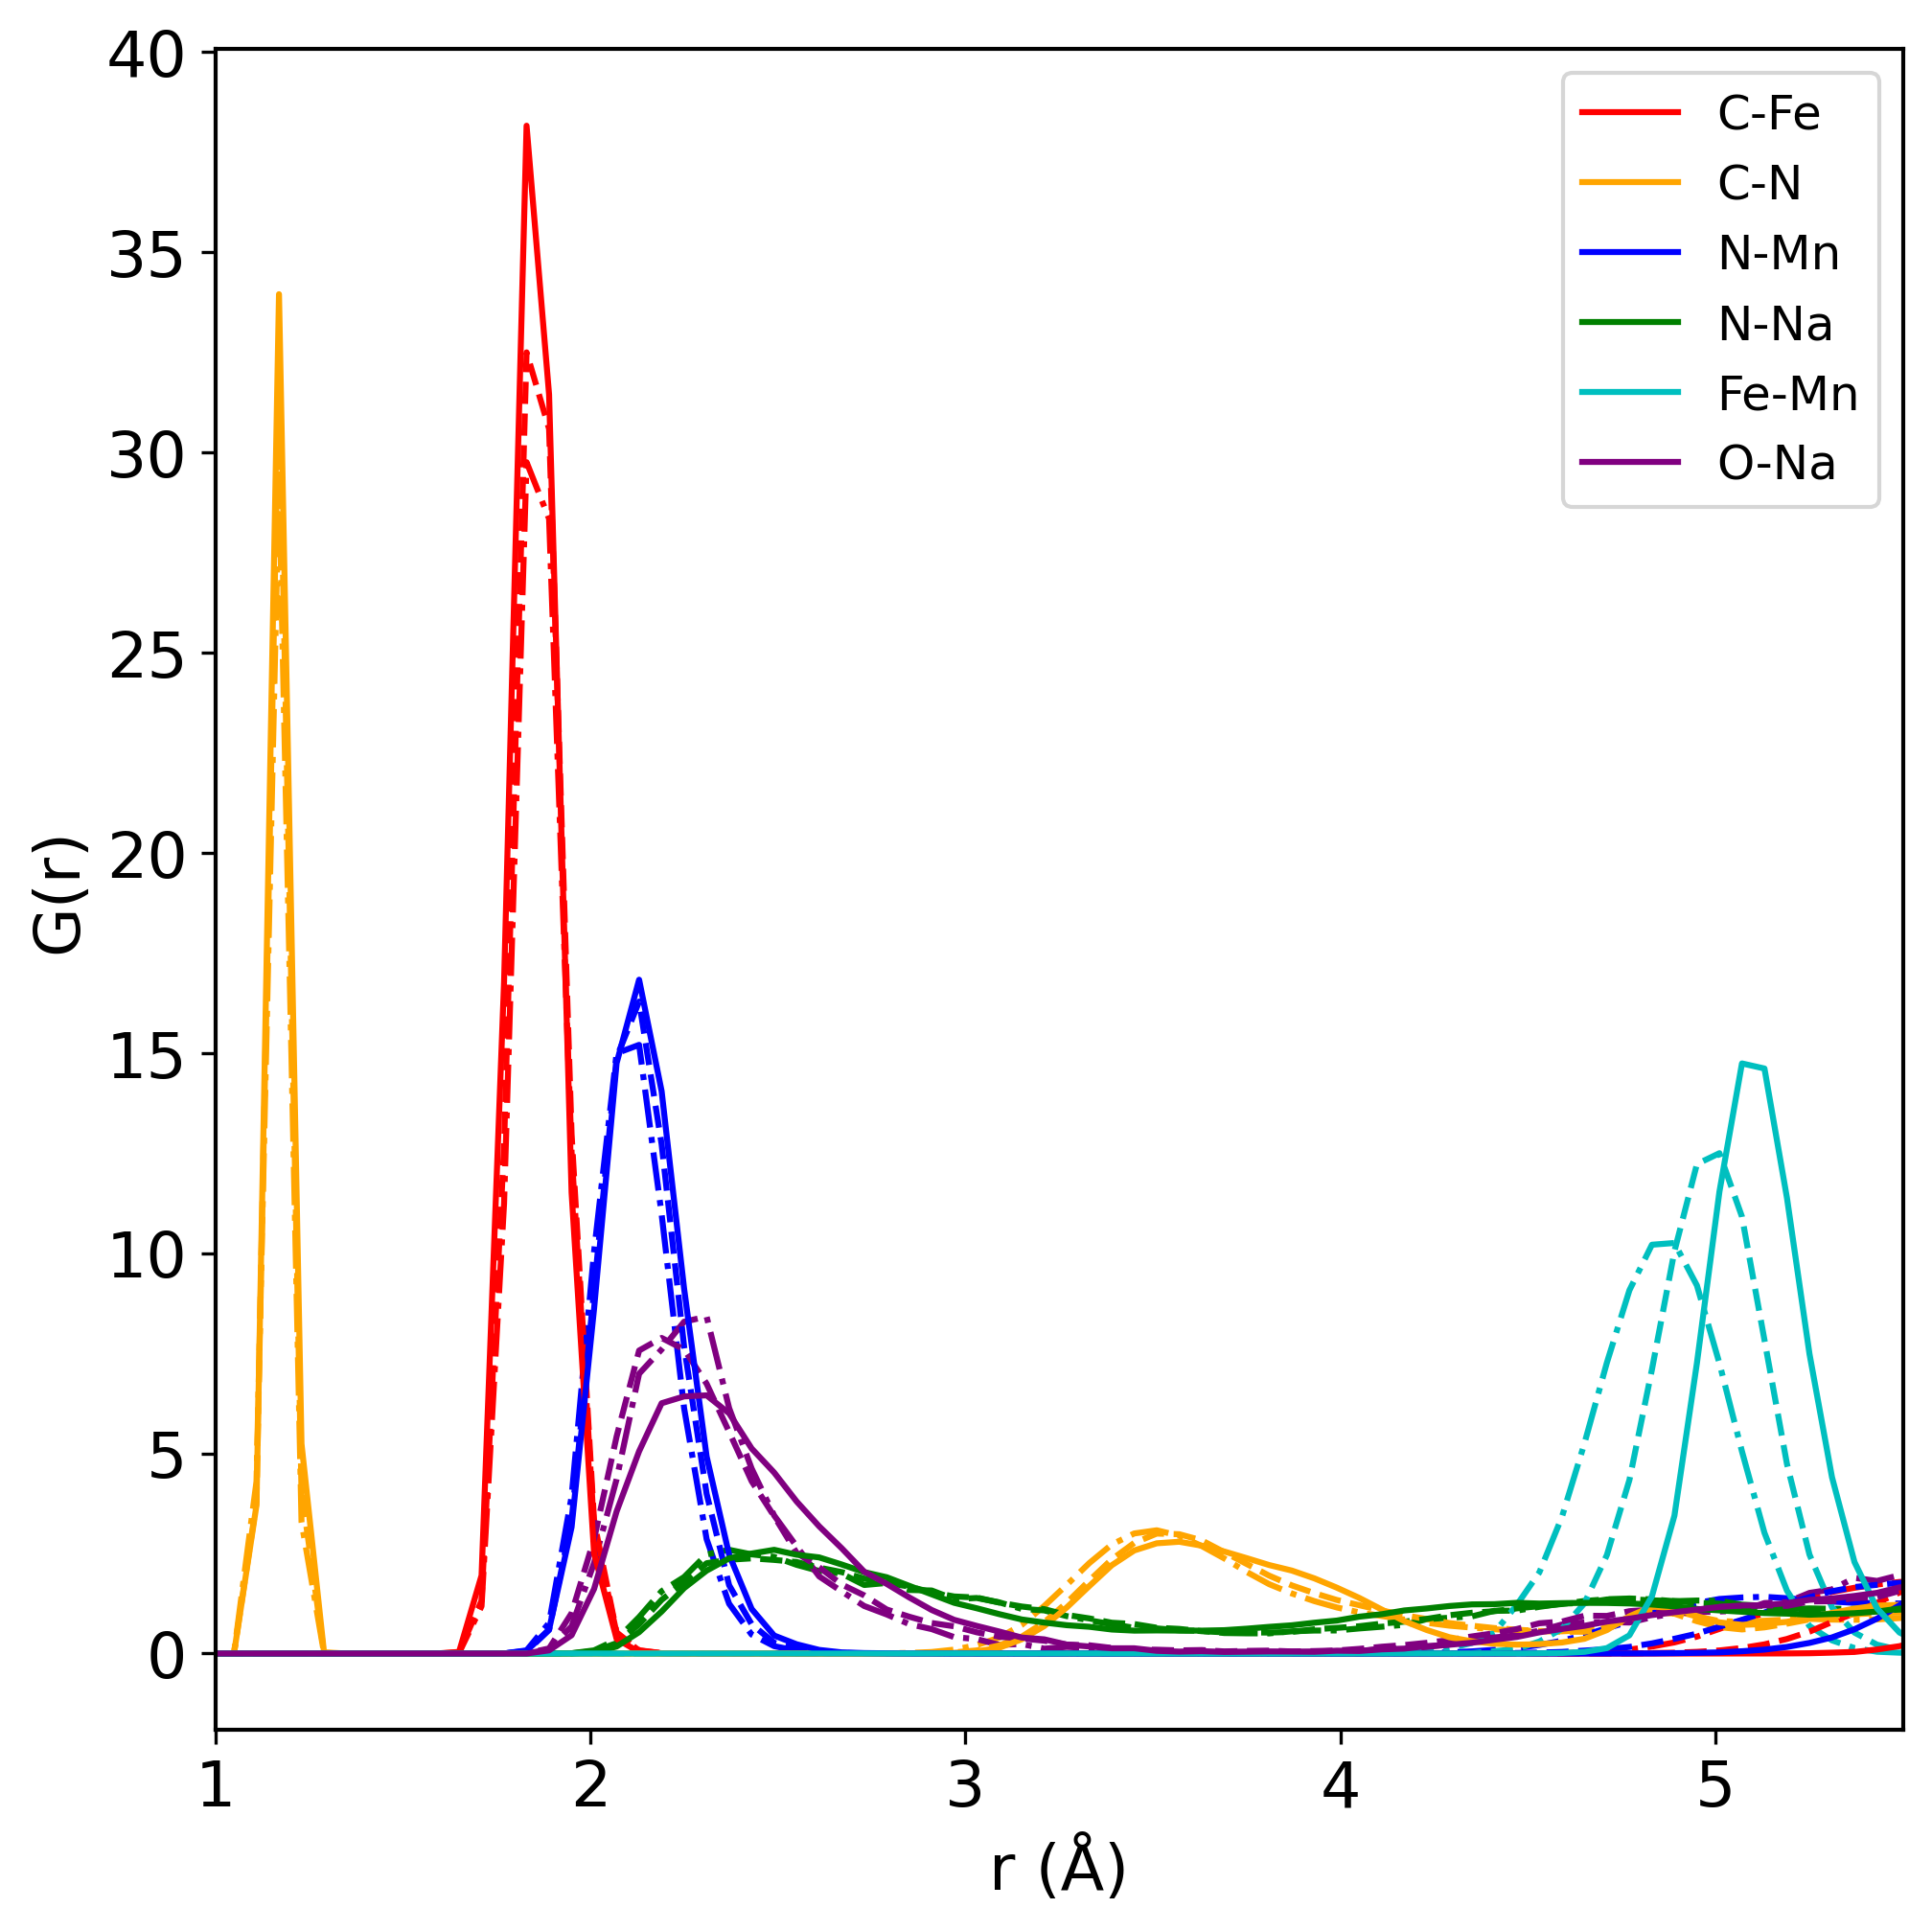

In [80]:
temp=600
plt.figure(figsize=(singlecol*2, singlecol*2), dpi=300)
RDF = read_rdf_data(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_4.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], '-.', color = colors[j])

RDF = read_rdf_data(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_5.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], '--', color = colors[j])

RDF = read_rdf_data(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_6.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], '-', color = colors[j],  label = name[j])


plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.5)
plt.ylabel('G(r)')
plt.tight_layout()
plt.savefig(f'../../../hydration/{temp}_diffusion_O_16_RDF.png')

✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


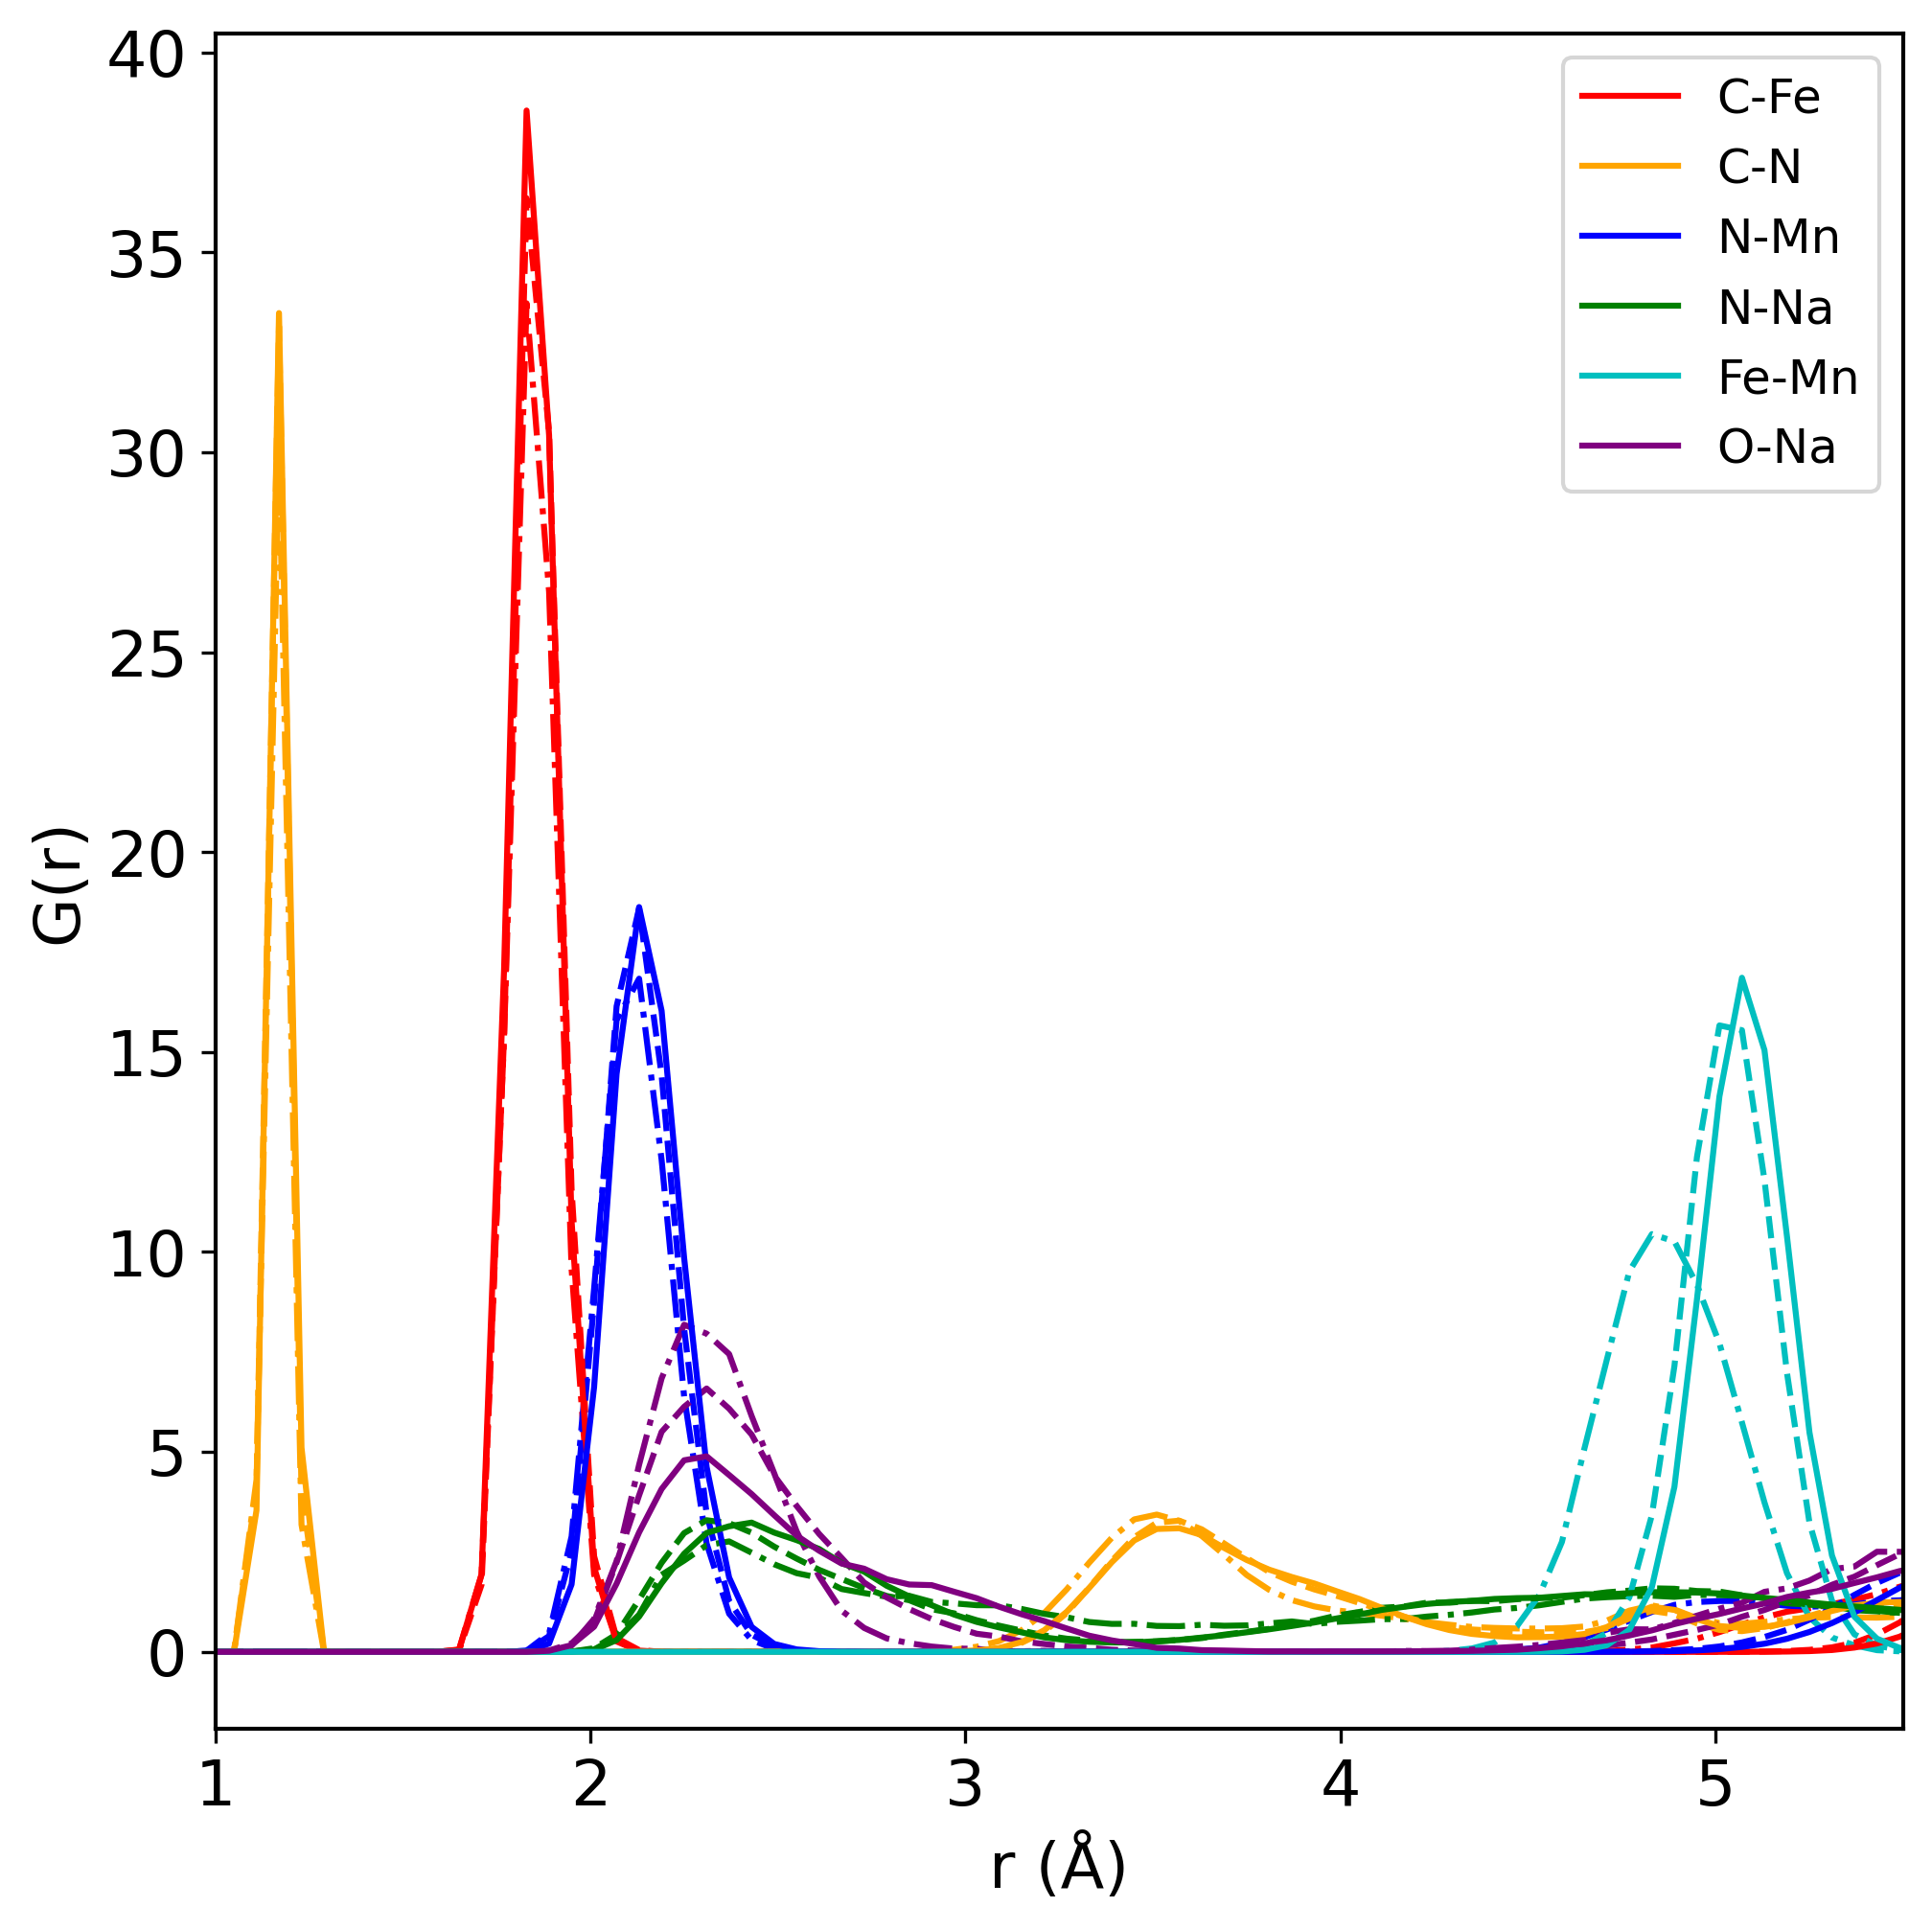

In [81]:
temp=600
plt.figure(figsize=(singlecol*2, singlecol*2), dpi=300)
RDF = read_rdf_data(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_7.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], '-.', color = colors[j])

RDF = read_rdf_data(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_8.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], '--', color = colors[j])

RDF = read_rdf_data(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_9.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], '-', color = colors[j],  label = name[j])


plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.5)
plt.ylabel('G(r)')
plt.tight_layout()
plt.savefig(f'../../../hydration/{temp}_diffusion_O_32_RDF.png')

✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


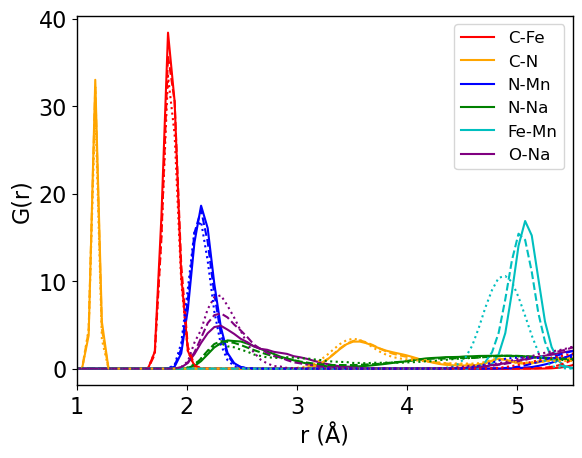

In [26]:
temp=600
fig = plt.figure()
RDF = read_rdf_data(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_9.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], label = name[j], color = colors[j])

RDF = read_rdf_data(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_8.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], '--', color = colors[j])

RDF = read_rdf_data(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_7.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], ':', color = colors[j])


plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.5)
plt.ylabel('G(r)')
plt.savefig(f'../../../hydration/{temp}_diffusion/{temp}_diffusion_O_32_RDF.png')

✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


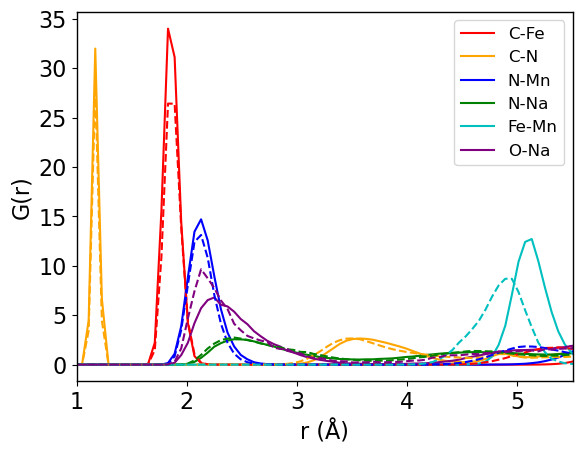

In [38]:
fig = plt.figure()
RDF = read_rdf_data('../../../hydration/700_diffusion/700_diffusion_5.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], label = name[j], color = colors[j])

RDF = read_rdf_data('../../../hydration/700_diffusion/700_diffusion_2.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], '--', color = colors[j])


plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.5)
plt.ylabel('G(r)')
plt.savefig('../../../hydration/700_diffusion/700_diffusion_Na_4_RDF.png')

✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


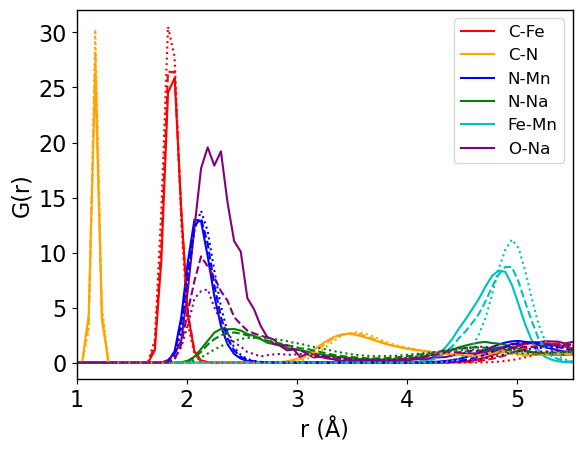

In [41]:
fig = plt.figure()
RDF = read_rdf_data('../../../hydration/700_diffusion/700_diffusion_1.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], label = name[j], color = colors[j])

RDF = read_rdf_data('../../../hydration/700_diffusion/700_diffusion_2.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], '--', color = colors[j])

RDF = read_rdf_data('../../../hydration/700_diffusion/700_diffusion_3.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], ':', color = colors[j])



plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.5)
plt.ylabel('G(r)')
plt.savefig('../../../hydration/700_diffusion/700_diffusion_Na_4_RDF.png')

✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7
✅ Successfully parsed 1 timesteps
📊 Data structure: 100 rows × 15 columns
🔗 Number of atom pairs: 7


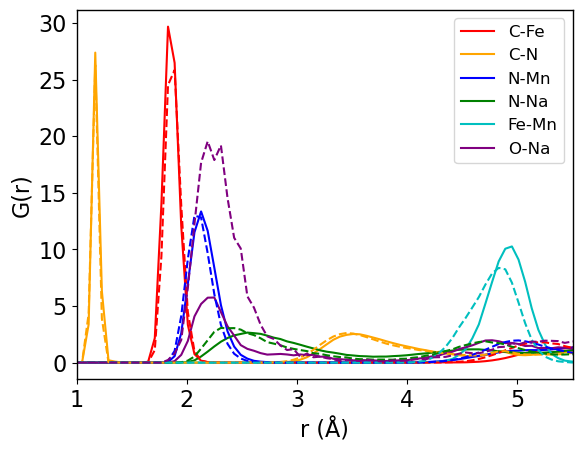

In [39]:
fig = plt.figure()
RDF = read_rdf_data('../../../hydration/700_diffusion/700_diffusion_4.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], label = name[j], color = colors[j])

RDF = read_rdf_data('../../../hydration/700_diffusion/700_diffusion_1.rdf')
r = RDF[24000][:,0]
for i in range(1, 13, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], '--', color = colors[j])


plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.5)
plt.ylabel('G(r)')
plt.savefig('../../../hydration/700_diffusion/700_diffusion_Na_1_RDF.png')

Text(0, 0.5, 'G(r)')

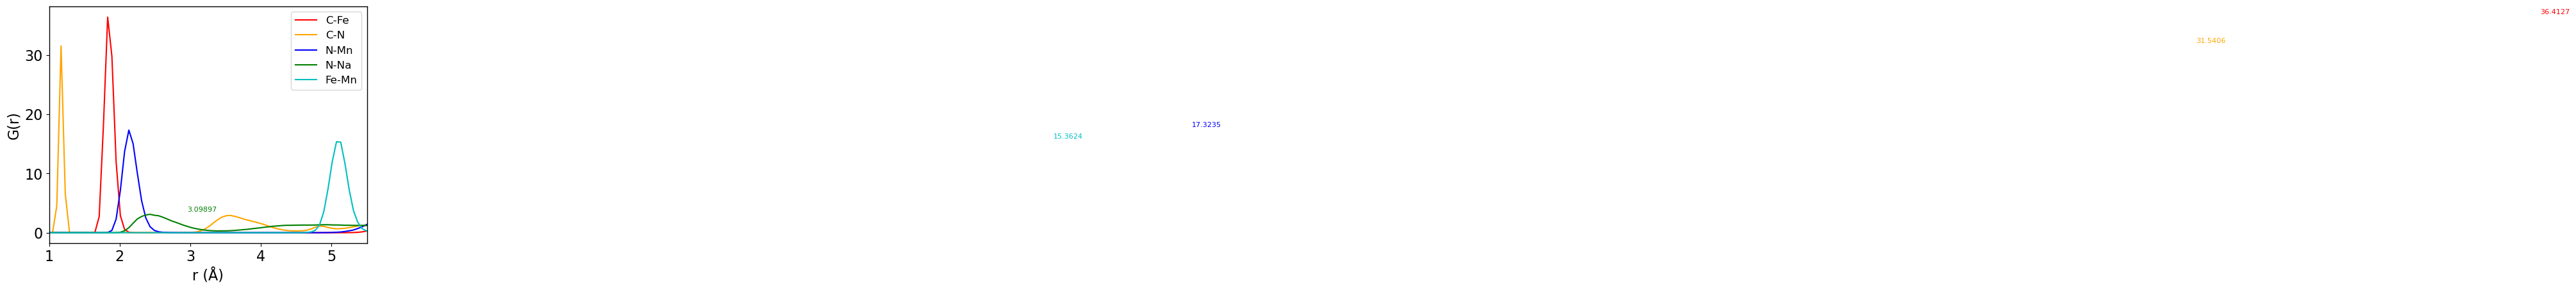

In [28]:
fig = plt.figure()
r = RDF[24000][:,0]
for i in range(1, 10, 2):
    j = int(i/2)
    plt.plot(r, RDF[24000][:,i], label = name[j], color = colors[j])
    plt.text(RDF[24000][:,i][RDF[24000][:,i].argmax()]-0.14, 
             RDF[24000][:,i].max()+0.5, 
             f'{RDF[24000][:,i][RDF[24000][:,i].argmax()]}',
             color = colors[j],
             fontsize=8)
plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.5)
plt.ylabel('G(r)')

In [77]:
#NaN_coor = np.loadtxt('300K_NaN_coord_3600.txt', skiprows=9)
#MnN_coor = np.loadtxt('300K_MnN_coord_3600.txt', skiprows=9)
#FeC_coor = np.loadtxt('300K_FeC_coord_3600.txt', skiprows=9)
pdf = np.loadtxt('../../../300K_rdf_final_interface.rdf', skiprows=4,max_rows=100)
r = pdf[:,1]
name = ['C-Fe','C-N','N-Mn','N-Na','Fe-Mn']
colors = ['r', 'orange', 'blue', 'green', 'c']

In [ ]:
name = ['C-Fe','C-N','N-Mn','N-Na','Fe-Mn']
colors = ['r', 'orange', 'blue', 'green', 'c']
fig = plt.figure()

RDF = read_rdf_data('../../../300K_rdf_final_interface_1.rdf')
r = RDF[4000][:,0]
for i in range(1, 10, 2):
    j = int(i/2)
    plt.plot(r, RDF[4000][:,i], label = name[j], color = colors[j])
    plt.text(RDF[4000][:,i][RDF[4000][:,i].argmax()]-0.14, 
             RDF[4000][:,i].max()+0.5, 
             f'{RDF[4000][:,i][RDF[4000][:,i].argmax()]}',
             color = colors[j],
             fontsize=8)
'''
t=20000
for i in range(1, 10, 2):
    j = int(i/2)
    plt.plot(r, RDF[t][:,i], '--', color = colors[j-1])
    plt.text(pdf[:,1][RDF[t][:,i].argmax()]-0.14, 
             RDF[t][:,i].max()+0.5, 
             f'{pdf[:,1][RDF[t][:,i].argmax()]}',
             color = colors[j-1],fontsize=8)
'''
t=40000
for i in range(1, 10, 2):
    j = int(i/2)
    plt.plot(r, RDF[t][:,i], '-.', color = colors[j])
    plt.text(pdf[:,1][RDF[t][:,i].argmax()]-0.14, 
             RDF[t][:,i].max()+0.5, 
             f'{pdf[:,1][RDF[t][:,i].argmax()]}',
             color = colors[j],fontsize=8)

t=80000
for i in range(1, 10, 2):
    j = int(i/2)
    plt.plot(r, RDF[t][:,i], ':', color = colors[j])
    plt.text(pdf[:,1][RDF[t][:,i].argmax()]-0.14, 
             RDF[t][:,i].max()+0.5, 
             f'{pdf[:,1][RDF[t][:,i].argmax()]}',
             color = colors[j],fontsize=8)
plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.05)
plt.ylabel('G(r)')

plt.savefig('../../../RDF.png')

In [ ]:
RDF[4000].shape

In [ ]:
name = ['C-Fe','C-N','N-Mn','N-Na','Fe-Mn']
colors = ['r', 'orange', 'blue', 'green', 'c']
fig = plt.figure()

RDF = read_rdf_data('../../../interface/300K_rdf_final_interface_4.rdf')
r = RDF[4000][:,0]
t=4000
for i in range(1, 10, 2):
    j = int(i/2)
    plt.plot(r, RDF[t][:,i], '-', label = name[j], color = colors[j])
    #plt.text(pdf[:,1][RDF[t][:,i].argmax()]-0.14, 
    #         RDF[t][:,i].max()+0.5, 
    #         f'{pdf[:,1][RDF[t][:,i].argmax()]}',
    #         color = colors[j],fontsize=8)
plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.05)
plt.ylabel('G(r)')

✅ Successfully parsed 27 timesteps
📊 Data structure: 100 rows × 11 columns
🔗 Number of atom pairs: 5


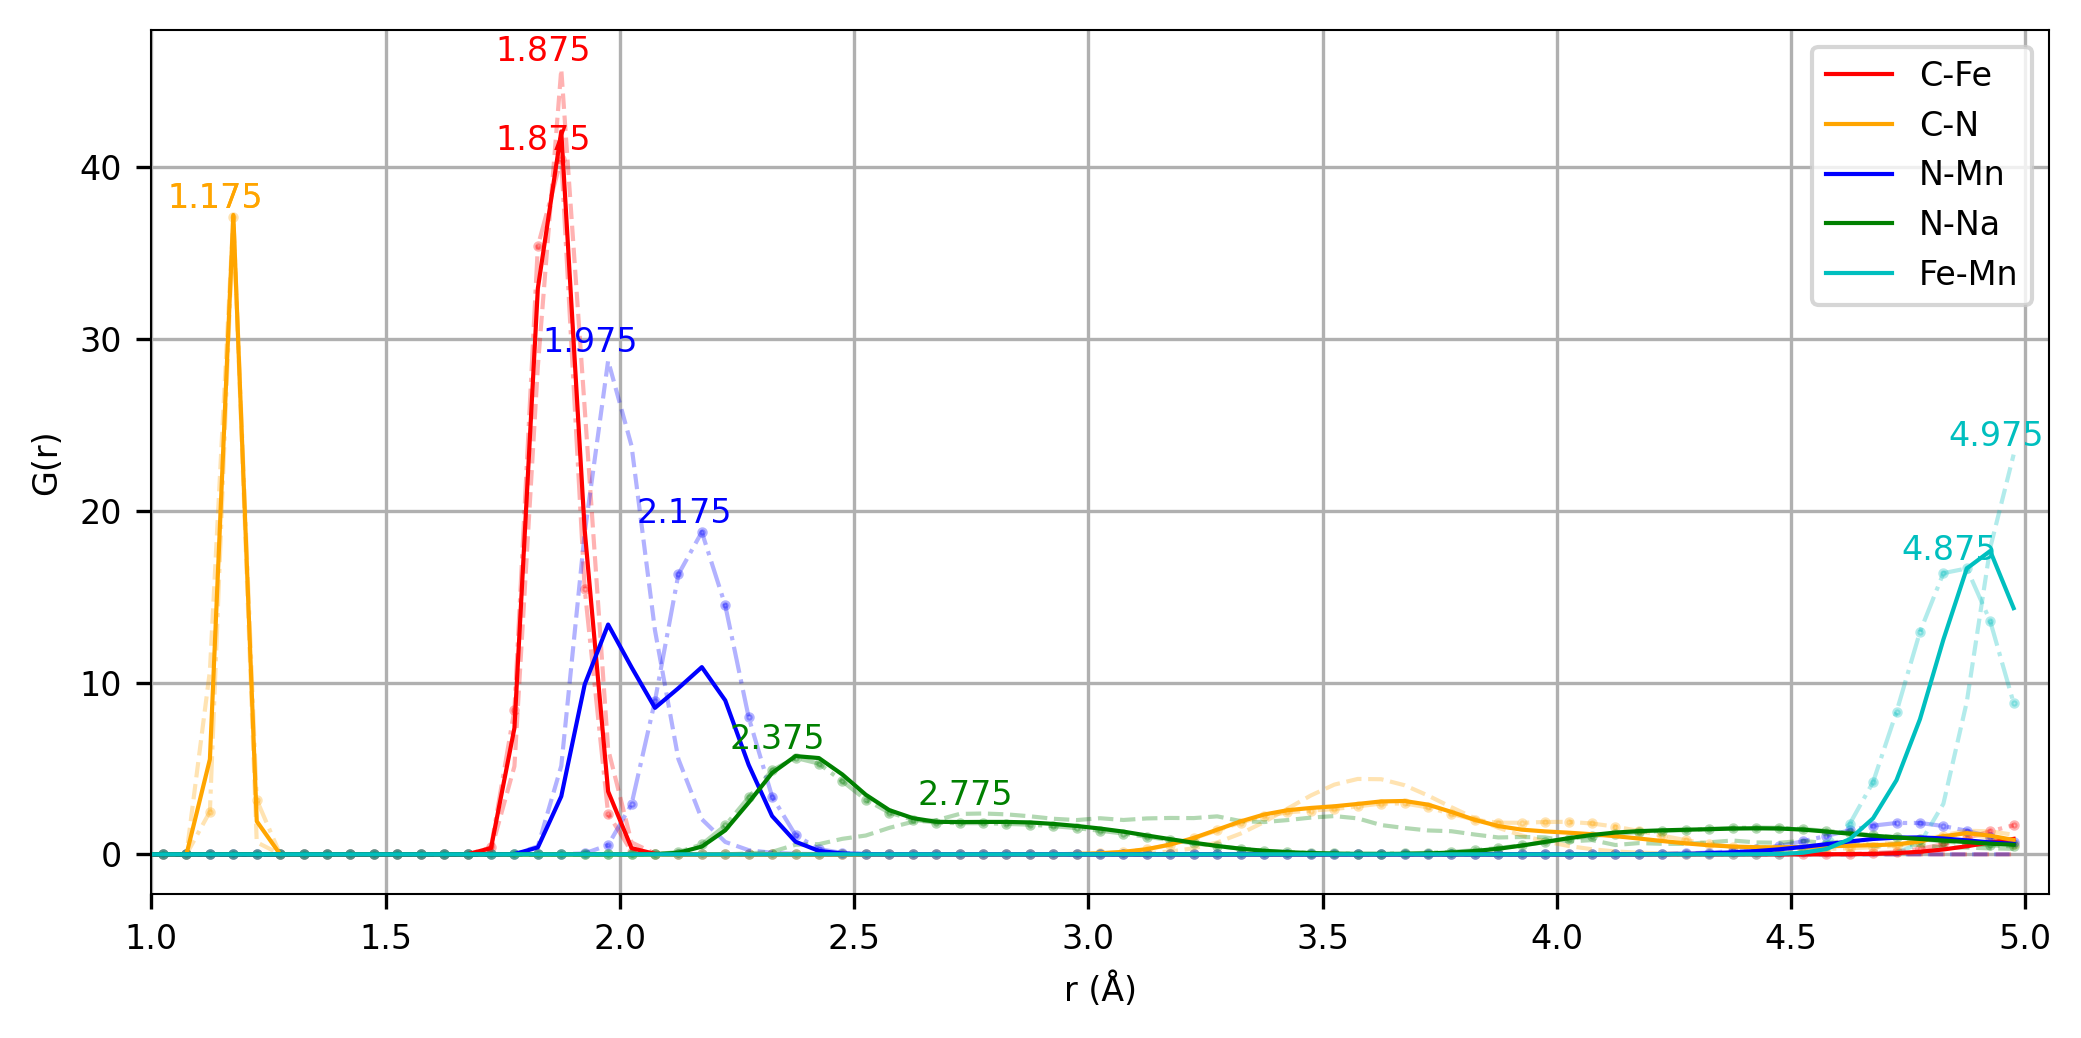

In [114]:
name = ['C-Fe','C-N','N-Mn','N-Na','Fe-Mn']
colors = ['r', 'orange', 'blue', 'green', 'c']
fig = plt.figure(figsize=(singlecol*2, singlecol*1), dpi=300)
pdf = np.loadtxt('300K_rdf_final_3600.rdf', skiprows=4,max_rows=100)
r = pdf[:,1]
for i in range(2, pdf.shape[1],2):
    j = int(i/2)
    plt.plot(r, pdf[:,i], '.-.', color = colors[j-1], alpha=0.3)
    plt.text(pdf[:,1][pdf[:,i].argmax()]-0.14, 
             pdf[:,i].max()+0.5, 
             f'{pdf[:,1][pdf[:,i].argmax()]}',
             color = colors[j-1],
             fontsize=8)
    
pdf = np.loadtxt('300K_rdf_final_10.rdf', skiprows=4,max_rows=100)
r = pdf[:,1]
for i in range(2, pdf.shape[1],2):
    j = int(i/2)
    plt.plot(r, pdf[:,i], '--', color = colors[j-1], alpha=0.3)
    plt.text(pdf[:,1][pdf[:,i].argmax()]-0.14, 
             pdf[:,i].max()+0.5, 
             f'{pdf[:,1][pdf[:,i].argmax()]}',
             color = colors[j-1],fontsize=8)

RDF = read_rdf_data('../../../interface/300K_rdf_final_interface_4.rdf')
r = RDF[4000][:,0]
t=4000
for i in range(1, 10, 2):
    j = int(i/2)
    plt.plot(r, RDF[t][:,i], '-', label = name[j], color = colors[j])
plt.legend()
plt.xlabel('r (Å)')
plt.xlim(1,5.05)
plt.ylabel('G(r)')
plt.grid()
plt.tight_layout()
plt.savefig('../../../interface_RDF.png')

In [ ]:
#NaN_coor = np.loadtxt('300K_NaN_coord_3600.txt', skiprows=9)
#MnN_coor = np.loadtxt('300K_MnN_coord_3600.txt', skiprows=9)
#FeC_coor = np.loadtxt('300K_FeC_coord_3600.txt', skiprows=9)
pdf = np.loadtxt('300K_rdf_final_10.rdf', skiprows=4,max_rows=100)
r = pdf[:,1]
name = ['C-Fe','C-N','N-Mn','N-Na','Fe-Mn']
colors = ['r', 'orange', 'blue', 'green', 'c']

In [ ]:
fig = plt.figure(figsize=(8,5))
for i in range(2, pdf.shape[1],2):
    j = int(i/2)
    plt.plot(r, pdf[:,i], label = name[j-1], color = colors[j-1])
    plt.text(pdf[:,1][pdf[:,i].argmax()], 
             pdf[:,i].max(), 
             f'{pdf[:,1][pdf[:,i].argmax()]}',
             color = colors[j-1])
plt.legend()
plt.xlabel('r (A)')
plt.xlim(0,5)
plt.ylabel('G(r)')
plt.grid()

In [ ]:
fig = plt.figure(figsize=(6,5))

bin_edges = range(90,180,1)  # bins from -10 to 20
i=0
# Plotting the first histogram
counts, edges, bars = plt.hist([Mn_N_C_angles, Fe_C_N_angles], bins = bin_edges,
                               alpha=0.7, color=['red','blue'], 
                                label = ['Mn-N-C bond angles', 'Fe_C_N bond angles'])
plt.text(92,8,f'Mn-N-C angles = {round(sum(Mn_N_C_angles) / len(Mn_N_C_angles),3)}\nFe_C_N angles = {round(sum(Fe_C_N_angles) / len(Fe_C_N_angles),3)}')
plt.xlabel('Bond Angles')
plt.ylabel('Count')
plt.legend()
plt.title(iteration+ f' bond angle_{poscar_numbers[pos_num]}'+f' n_Na = {na_count}')

In [ ]:
pdf = np.loadtxt('300K_rdf_final_100.rdf', skiprows=4,max_rows=100)
r = pdf[:,1]
name = ['C-Fe','C-N','N-Mn','N-Na','Fe-Mn']
colors = ['r', 'orange', 'blue', 'green', 'c']

In [ ]:
fig = plt.figure(figsize=(8,5))
for i in range(2, pdf.shape[1],2):
    j = int(i/2)
    plt.plot(r, pdf[:,i], label = name[j-1], color = colors[j-1])
    plt.text(pdf[:,1][pdf[:,i].argmax()], 
             pdf[:,i].max(), 
             f'{pdf[:,1][pdf[:,i].argmax()]}',
             color = colors[j-1])
plt.legend()
plt.xlabel('r (A)')
plt.xlim(0,5)
plt.ylabel('G(r)')
plt.grid()

In [ ]:
fig = plt.figure(figsize=(6,5))

bin_edges = range(3,9,1)  # bins from -10 to 20
i=0
# Plotting the first histogram
counts, edges, bars = plt.hist([FeC_coor[:,2],MnN_coor[:,2],NaN_coor[:,2]], bins = bin_edges,
                               alpha=0.7, color=['red','blue','green'], 
                               edgecolor='black', label = ['FeC_coor','MnN_coor','NaN_coor'])
plt.text(3,20,f'Fe-C coor. = {FeC_coor[:,2].mean()}\nMn-N coor. = {MnN_coor[:,2].mean()}\nNa-N coor. = {NaN_coor[:,2].mean()}')
plt.title(f'Atom count')
plt.xlabel('Coordination number')
plt.ylabel('Count')
plt.legend()

plt.tight_layout()
plt.show()

# Bond angles

In [ ]:
def calculate_bond_angle(A, B, C):
   
    # Convert input to NumPy arrays
    A = np.array(A)
    B = np.array(B)
    C = np.array(C)
    # Calculate vectors
    AB = B - A
    BC = C - B
    # Calculate the magnitudes of the vectors
    AB_magnitude = np.linalg.norm(AB)
    BC_magnitude = np.linalg.norm(BC[0])
    # Calculate the dot product
    dot_product = np.dot(AB, BC[0])
    # Calculate the cosine of the angle
    cos_theta = dot_product / (AB_magnitude * BC_magnitude)
    # Ensure the cosine value is within the valid range for arccos
    cos_theta = np.clip(cos_theta, -1.0, 1.0)
    # Calculate the angle in radians
    angle_radians = np.arccos(cos_theta)
    # Convert to degrees
    angle_degrees = np.degrees(angle_radians)
    return 180 - angle_degrees

In [ ]:
from pymatgen.core import Structure, Lattice
struct = Structure.from_file("POSCAR0")

In [ ]:
from collections import Counter
# Extract species (element types) from the sites
species = [site.species_string for site in struct.sites]

# Count the occurrences of each species
species_counts = Counter(species)
counts_list = []

# Print the number of atoms of each type
for element, count in species_counts.items():
    print(f"Element: {element}, Count: {count}")
    counts_list.append(count)

## Compute the Mn-N-C bond angles

1. find the coordiate of all Mn atoms
2. find the 6 closest atoms to each Mn which should be N
3. find the closet atom to those N which should be C
4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram

In [ ]:
#1. find the coordiate of all Mn atoms
coordinates = []
for site in struct.sites:
    x, y, z = site.coords  # Extracting the coordinates
    coordinates.append((x, y, z))  # Append to the list

C_coor = np.array(coordinates[:counts_list[0]])
Mn_coor = np.array(coordinates[counts_list[0]:counts_list[0]+counts_list[1]])
Fe_coor = np.array(coordinates[counts_list[0]+counts_list[1]:counts_list[0]+counts_list[1]+counts_list[2]])
N_coor = np.array(coordinates[counts_list[0]+counts_list[1]+counts_list[2]:])

In [ ]:
#2. find the 6 closest atoms to each Mn which should be N
distance_threshold = 3.0

# Initialize a list to store the results
n_within_distance = []

# Calculate distances
for mn in Mn_coor:
    distances = np.linalg.norm(N_coor - mn, axis=1)  # Compute distances from the current Mn
    # Find N coordinates within the distance threshold
    close_n = N_coor[distances < distance_threshold]
    n_within_distance.append(close_n)
    
n_within_distance = np.array(n_within_distance)

# Print the results
for i, close_n in enumerate(n_within_distance):
    print(f"Mn atom {i + 1} is close to the following N atoms:")
    for n in close_n:
        print(f"  N coordinates: {n}")

In [ ]:
num = []
for i in range(n_within_distance.shape[0]):
    num.append(n_within_distance[i].shape[0])
    
def cumulative_sum(lst):
    cum_sum = []
    current_sum = 0
    for value in lst:
        current_sum += value
        cum_sum.append(current_sum)
    return cum_sum

cum_sum = cumulative_sum(num)

In [ ]:
#3. find the closet atom to those N which should be C

distance_threshold = 2

# Initialize a list to store the results
c_within_distance = []

# Calculate distances
for i in range(n_within_distance.shape[0]):
    for j in range(n_within_distance[i].shape[0]):
        n = n_within_distance[i][j]
        distances = np.linalg.norm(C_coor - n, axis=1)  # Compute distances from the current Mn
        # Find N coordinates within the distance threshold
        close_c = C_coor[distances < distance_threshold]
        c_within_distance.append(close_c)

# Print the results
for i, close_c in enumerate(c_within_distance):
    print(f"N atom {i + 1} is close to the following C atoms:")
    for c in close_c:
        print(f"  C coordinates: {c}")

In [ ]:
#4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
Mn_N_C_angles = []
c_index = 0
for i in range(n_within_distance.shape[0]):
    for j in range(n_within_distance[i].shape[0]):
        Mn = Mn_coor[i]
        N = n_within_distance[i][j]
        
        # Ensure c_index is within bounds
        if c_index < len(c_within_distance):
            C_n = c_within_distance[c_index]
        else:
            print(f"Warning: c_index {c_index} out of bounds, skipping...")
            continue  # Skip to the next iteration if out of bounds

        print(i, j, c_index)  # Debug information
        
        try:
            # Calculate the bond angle and append to the list
            angle = calculate_bond_angle(Mn, N, C_n)
            Mn_N_C_angles.append(angle)
        except Exception as e:
            # Handle any exceptions and continue the loop
            print(f"Error calculating angle for Mn: {Mn}, N: {N}, C_n: {C_n}. Error: {e}")
        
        c_index += 1  # Increment c_index regardless of success or failure
    

## Compute the Fe-C-N bond angles

In [ ]:
#2. find the 6 closest atoms to each Mn which should be N
distance_threshold = 3.0

# Initialize a list to store the results
c_within_distance = []

# Calculate distances
for fe in Fe_coor:
    distances = np.linalg.norm(C_coor - fe, axis=1)  # Compute distances from the current Mn
    # Find C coordinates within the distance threshold
    close_c = C_coor[distances < distance_threshold]
    c_within_distance.append(close_c)

c_within_distance = np.array(c_within_distance)

# Print the results
for i, close_c in enumerate(c_within_distance):
    print(f"Fe atom {i + 1} is close to the following C atoms:")
    for c in close_c:
        print(f"  C coordinates: {c}")

In [ ]:
#3. find the closet atom to those N which should be C

distance_threshold = 2

# Initialize a list to store the results
n_within_distance = []

# Calculate distances
for i in range(c_within_distance.shape[0]):
    for j in range(c_within_distance[i].shape[0]):
        c = c_within_distance[i][j]
        distances = np.linalg.norm(N_coor - c, axis=1)  # Compute distances from the current Mn
        # Find N coordinates within the distance threshold
        close_n = N_coor[distances < distance_threshold]
        n_within_distance.append(close_n)

n_within_distance = np.array(n_within_distance)

# Print the results
for i, close_n in enumerate(n_within_distance):
    print(f"C atom {i + 1} is close to the following N atoms:")
    for n in close_n:
        print(f"  N coordinates: {n}")

In [ ]:
#4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
Fe_C_N_angles = []
n_index = 0
for i in range(c_within_distance.shape[0]):
    for j in range(c_within_distance[i].shape[0]):
        Fe = Fe_coor[i]
        C = c_within_distance[i][j]
        
        # Ensure c_index is within bounds
        if n_index < len(n_within_distance):
            N_c = n_within_distance[n_index]
        else:
            print(f"Warning: c_index {n_index} out of bounds, skipping...")
            continue  # Skip to the next iteration if out of bounds

        print(i, j, n_index)  # Debug information
        
        try:
            # Calculate the bond angle and append to the list
            angle = calculate_bond_angle(Fe,C,N_c)
            Fe_C_N_angles.append(angle)
        except Exception as e:
            # Handle any exceptions and continue the loop
            print(f"Error calculating angle for Fe: {Fe}, C: {C}, N: {N_c}. Error: {e}")
        
        n_index += 1  # Increment c_index regardless of success or failure
    

In [ ]:
fig = plt.figure(figsize=(6,5))

bin_edges = range(90,180,1)  # bins from -10 to 20
i=0
# Plotting the first histogram
counts, edges, bars = plt.hist([Mn_N_C_angles, Fe_C_N_angles], bins = bin_edges,
                               alpha=0.7, color=['red','blue'], 
                                label = ['Mn-N-C bond angles', 'Fe_C_N bond angles'])
plt.text(92,8,f'Mn-N-C angles = {round(sum(Mn_N_C_angles) / len(Mn_N_C_angles),3)}\nFe_C_N angles = {round(sum(Fe_C_N_angles) / len(Fe_C_N_angles),3)}')
plt.xlabel('Bond Angles')
plt.ylabel('Count')
plt.legend()

plt.tight_layout()
plt.show()